# Telecom Intelligence
## AI-Powered Customer Retention & Revenue Optimization

### GCI World 2026 — Final Assignment

**Domain:** Telecommunications

**Project Type:** End-to-End Data Science & Machine Learning

**Objective:**

Analyze historical customer data, identify business challenges,
develop reliable predictive models, explain customer behavior,
and propose a measurable customer retention strategy.

### Project Workflow

1. Data Loading and Integration
2. Data Quality Assessment
3. Exploratory Data Analysis
4. Statistical Analysis
5. Business Problem Definition
6. Data Preprocessing
7. Feature Engineering
8. Machine Learning
9. Hyperparameter Optimization
10. Model Evaluation
11. Explainable AI
12. Business Impact Analysis
13. Model Testing and Monitoring
14. Conclusions and References

## Executive summary — results from the completed run

This proof of concept combines customer churn prediction with revenue-aware retention for Company A. The unit of analysis is a customer; the target is churn during days 31–60 following observation. The data are historical snapshots, not a live customer stream.

| Outcome | Recorded result |
|---|---:|
| Customers / independent test customers | 100,000 / 15,000 |
| Champion | Tuned XGBoost |
| Independent test ROC-AUC | 0.6937 |
| 95% bootstrap ROC-AUC interval | 0.6851–0.7017 |
| Recall / precision at threshold 0.33 | 91.18% / 55.33% |
| Precision / lift at top 20% | 74.10% / 1.4952× |
| Campaign size | 3,000 |
| Simulated net contribution | 45,750.93 CU |
| Simulated campaign ROI | 76.25% |
| Software tests | 12/12 passed in recorded run |

**Recommendation:** validate the scoring system through a controlled retention pilot before operational use. Predictive discrimination is moderate; high recall comes at the expense of precision and accuracy. Financial figures are scenario estimates in unspecified dataset currency units (CU), not realized profit. The recorded critical monitoring alert comes from synthetic drift, not a live incident.

### Reading guide
Data integration and quality → exploratory analysis and business problem → feature engineering → baseline and advanced models → ablation, tuning and ensembles → calibration and independent evaluation → explainability → retention economics → persistence, tests and monitoring → market context and implementation.

### Reproduction
Use the original Python 3.11.0 `.venv` kernel and existing project folder structure. Open this notebook from the same `notebooks` directory; the supplied CSVs remain under `data/raw`. Existing Optuna study storage may be reused. Saved outputs reflect the original completed run; rerunning may change timing and optimization results. This editorial edition does not retrain models or change model configurations.

In [1]:
import sys
import platform

print("=" * 65)
print("TELECOM INTELLIGENCE | ENVIRONMENT CHECK")
print("=" * 65)

print("Python Version :", platform.python_version())
print("Python Path    :", sys.executable)
print("OS             :", platform.system())
print("Architecture   :", platform.machine())
print("Processor      :", platform.processor())

print("=" * 65)

TELECOM INTELLIGENCE | ENVIRONMENT CHECK
Python Version : 3.11.0
Python Path    : d:\GCI\05. Final Assignment\05. Final Assignment (due Nov 28)\Grad-project\Telecom_Intelligence\Telecom_Intelligence\.venv\Scripts\python.exe
OS             : Windows
Architecture   : AMD64
Processor      : Intel64 Family 6 Model 186 Stepping 2, GenuineIntel


In [2]:
# ==========================================================
# 01. Core Libraries
# ==========================================================

import os
import time
import json
import random
import platform

from pathlib import Path
from importlib.metadata import version

# ==========================================================
# 02. Data Analysis
# ==========================================================

import pandas as pd
import numpy as np

from scipy import stats

# ==========================================================
# 03. Data Visualization
# ==========================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# ==========================================================
# 04. Notebook Utilities
# ==========================================================

from IPython.display import display, Markdown
from tqdm.auto import tqdm

# ==========================================================
# 05. Reproducibility
# ==========================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# ==========================================================
# 06. Pandas Configuration
# ==========================================================

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

print("All initial libraries imported successfully.")

All initial libraries imported successfully.


In [3]:
packages = [
    "pandas",
    "numpy",
    "scipy",
    "matplotlib",
    "seaborn",
    "plotly",
    "scikit-learn",
    "xgboost",
    "lightgbm",
    "catboost",
    "optuna",
    "shap",
    "statsmodels",
    "joblib"
]

versions = pd.DataFrame({
    "Library": packages,
    "Version": [version(pkg) for pkg in packages]
})

display(versions)

,Library,Version
0,pandas,3.1.1
1,numpy,2.4.6
2,scipy,1.17.1
3,matplotlib,3.11.2
4,seaborn,0.13.2
5,plotly,7.2.0
6,scikit-learn,1.9.1
7,xgboost,3.2.0
8,lightgbm,4.7.0
9,catboost,1.2.10


In [4]:
# ==========================================================
# TELECOM INTELLIGENCE — GLOBAL DARK THEME
# ==========================================================

BG_COLOR = "#0B1120"
PANEL_COLOR = "#111827"
TEXT_COLOR = "#F8FAFC"
GRID_COLOR = "#334155"

CYAN = "#00D4FF"
PURPLE = "#A78BFA"
GREEN = "#34D399"
RED = "#FB7185"
GOLD = "#FBBF24"
BLUE = "#60A5FA"
PINK = "#F472B6"

PALETTE = [
    CYAN, PURPLE, GREEN, RED,
    GOLD, BLUE, PINK
]

CHURN_COLORS = {
    0: GREEN,
    1: RED
}

sns.set_theme(
    style="darkgrid",
    palette=PALETTE
)

plt.rcParams.update({
    "figure.facecolor": BG_COLOR,
    "axes.facecolor": PANEL_COLOR,
    "savefig.facecolor": BG_COLOR,
    "savefig.edgecolor": BG_COLOR,

    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,

    "text.color": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,

    "grid.color": GRID_COLOR,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",

    "font.family": "DejaVu Sans",
    "font.size": 11,

    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,

    "legend.facecolor": PANEL_COLOR,
    "legend.edgecolor": GRID_COLOR,
    "legend.labelcolor": TEXT_COLOR,

    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "savefig.dpi": 300,

    "axes.spines.top": False,
    "axes.spines.right": False
})

sns.set_palette(PALETTE)

# Interactive Plotly charts

pio.templates["telecom_dark"] = go.layout.Template(
    layout=go.Layout(
        paper_bgcolor=BG_COLOR,
        plot_bgcolor=PANEL_COLOR,

        font=dict(
            color=TEXT_COLOR,
            family="Arial"
        ),

        colorway=PALETTE,

        xaxis=dict(gridcolor=GRID_COLOR),
        yaxis=dict(gridcolor=GRID_COLOR)
    )
)

pio.templates.default = "plotly_dark+telecom_dark"

print("Professional Dark Theme Activated.")

Professional Dark Theme Activated.


# 1. Data Loading and Integration

The project uses two historical datasets provided by Company A:

- Client.csv: Customer profile and account-level information.
- Record.csv: Usage history, billing, service quality and churn.

Both datasets are connected through the Customer_ID field.

Before integration, we validate the structure, primary keys,
data completeness and consistency of both source tables.

In [5]:
CURRENT_DIR = Path.cwd().resolve()

if (CURRENT_DIR / "data" / "raw").is_dir():
    PROJECT_ROOT = CURRENT_DIR

elif (CURRENT_DIR.parent / "data" / "raw").is_dir():
    PROJECT_ROOT = CURRENT_DIR.parent

else:
    raise FileNotFoundError(
        "Project folder not found. "
        "Check the notebook and data folder locations."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
REPORTS_DIR = PROJECT_ROOT / "outputs" / "reports"
PREDICTIONS_DIR = PROJECT_ROOT / "outputs" / "predictions"
MONITORING_DIR = PROJECT_ROOT / "outputs" / "monitoring"
MODELS_DIR = PROJECT_ROOT / "models"

for folder in [
    PROCESSED_DIR,
    FIGURES_DIR,
    REPORTS_DIR,
    PREDICTIONS_DIR,
    MONITORING_DIR,
    MODELS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

CLIENT_PATH = DATA_DIR / "Client.csv"
RECORD_PATH = DATA_DIR / "Record.csv"

assert CLIENT_PATH.exists(), "Client.csv not found."
assert RECORD_PATH.exists(), "Record.csv not found."

print("Project Root:", PROJECT_ROOT)
print("Client File :", CLIENT_PATH)
print("Record File :", RECORD_PATH)

Project Root: D:\GCI\05. Final Assignment\05. Final Assignment (due Nov 28)\Grad-project\Telecom_Intelligence\Telecom_Intelligence
Client File : D:\GCI\05. Final Assignment\05. Final Assignment (due Nov 28)\Grad-project\Telecom_Intelligence\Telecom_Intelligence\data\raw\Client.csv
Record File : D:\GCI\05. Final Assignment\05. Final Assignment (due Nov 28)\Grad-project\Telecom_Intelligence\Telecom_Intelligence\data\raw\Record.csv


In [6]:
start_time = time.perf_counter()

client = pd.read_csv(
    CLIENT_PATH,
    low_memory=False
)

record = pd.read_csv(
    RECORD_PATH,
    low_memory=False
)

elapsed = time.perf_counter() - start_time

print("=" * 65)
print("DATA LOADING SUMMARY")
print("=" * 65)

print(f"Client Dataset : {client.shape}")
print(f"Record Dataset : {record.shape}")
print(f"Loading Time   : {elapsed:.2f} seconds")

print("=" * 65)

DATA LOADING SUMMARY
Client Dataset : (100000, 50)
Record Dataset : (100000, 51)
Loading Time   : 0.80 seconds


In [8]:
def dataset_summary(df, dataset_name):

    return {
        "Dataset": dataset_name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],

        "Numeric Columns":
            df.select_dtypes(include="number").shape[1],

        "Categorical Columns":
            df.select_dtypes(
                include=["object", "category"]
            ).shape[1],

        "Missing Cells":
            int(df.isna().sum().sum()),

        "Duplicate Rows":
            int(df.duplicated().sum()),

        "Memory (MB)":
            df.memory_usage(deep=True).sum() / 1024**2
    }


overview = pd.DataFrame([
    dataset_summary(client, "Client"),
    dataset_summary(record, "Record")
])

display(overview)

C:\Users\VICTUS\AppData\Local\Temp\ipykernel_3676\1509534094.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(


,Dataset,Rows,Columns,Numeric Columns,Categorical Columns,Missing Cells,Duplicate Rows,Memory (MB)
0,Client,100000,50,29,21,337974,0,135.2628
1,Record,100000,51,51,0,4995,0,38.9100


In [9]:
KEY = "Customer_ID"

for name, dataset in [
    ("Client", client),
    ("Record", record)
]:

    print(f"\n{name} Dataset")
    print("-" * 45)

    print("Total IDs     :", len(dataset))
    print("Unique IDs    :", dataset[KEY].nunique())
    print("Missing IDs   :", dataset[KEY].isna().sum())
    print("Duplicate IDs :", dataset[KEY].duplicated().sum())

    assert dataset[KEY].notna().all(), (
        f"{name} contains missing IDs."
    )

    assert dataset[KEY].is_unique, (
        f"{name} contains duplicate IDs."
    )


client_ids = set(client[KEY])
record_ids = set(record[KEY])

print("\nID Matching")
print("-" * 45)

print("Matching IDs :", len(client_ids & record_ids))
print("Client Only  :", len(client_ids - record_ids))
print("Record Only  :", len(record_ids - client_ids))

assert client_ids == record_ids, (
    "Customer IDs do not match between the datasets."
)

print("\nAll primary key validations passed.")


Client Dataset
---------------------------------------------
Total IDs     : 100000
Unique IDs    : 100000
Missing IDs   : 0
Duplicate IDs : 0

Record Dataset
---------------------------------------------
Total IDs     : 100000
Unique IDs    : 100000
Missing IDs   : 0
Duplicate IDs : 0

ID Matching
---------------------------------------------
Matching IDs : 100000
Client Only  : 0
Record Only  : 0

All primary key validations passed.


In [10]:
df = record.merge(
    client,
    on=KEY,
    how="inner",
    validate="one_to_one"
)

assert len(df) == len(record)
assert df[KEY].is_unique
assert df.columns.is_unique

print("=" * 65)
print("DATA INTEGRATION COMPLETED")
print("=" * 65)

print(f"Original Client Shape : {client.shape}")
print(f"Original Record Shape : {record.shape}")
print(f"Merged Dataset Shape  : {df.shape}")

print("=" * 65)

display(df.head())

DATA INTEGRATION COMPLETED
Original Client Shape : (100000, 50)
Original Record Shape : (100000, 51)
Merged Dataset Shape  : (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.2500,22.5000,0.2475,0.0000,0.0000,0.0000,0.0000,0.0000,-157.2500,-18.9975,0.6667,0.0000,0.6667,0.0000,6.3333,0.0000,52.3333,0.0000,42.3333,0.0000,45.0000,0.0000,0.0000,0.0000,0.0000,18.0000,0.0000,90.6433,0.0000,97.1767,0.0000,0.0000,0.0000,0.0000,58.0000,0.0000,132.6000,0.0000,24.0000,0.0000,55.2200,0.0000,1.3333,52.3333,45.0000,0.0000,0.3333,1,61,1000001,2,1,U,A,N,1652,"4,228.0000","1,504.6200","1,453.4400","4,085.0000",1602,29.6600,83.3700,32.6900,272,116,30,322.0000,136.0000,38.0000,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.9900,2.0000,2.0000,WCMB,0.0000,0.0000,O,15.0000,S,S,1.0000,M,4.0000,3.0000,C,A,0.0000,N,U,U,U,U,U,Y,361.0000
1,57.4925,482.7500,37.4250,0.2475,22.7500,9.1000,9.1000,0.0000,0.0000,532.2500,50.9875,8.3333,0.0000,1.0000,0.0000,61.3333,0.0000,263.3333,0.0000,69.0000,0.0000,193.3333,0.0000,1.6667,6.3333,5.4633,53.0000,0.3333,189.3967,0.0000,55.2800,46.3333,24.2167,6.3333,3.6967,83.6667,0.0000,75.3333,0.0000,157.0000,0.0000,169.3433,0.0000,9.3333,263.3333,193.3333,0.0000,5.6667,0,56,1000002,1,1,N,EA,N,14654,"26,400.0000","2,851.6800","2,833.8800","26,367.0000",14624,51.5300,479.4000,265.8900,305,158,40,477.0000,275.0000,48.0000,U,CHICAGO AREA,N,N,NaN,7.0000,6.0000,WC,1.0000,1.0000,NaN,1.0000,S,S,1.0000,M,5.0000,1.0000,C,A,0.0000,Z,U,U,U,U,U,Y,240.0000
2,16.9900,10.2500,16.9900,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-4.2500,0.0000,0.3333,0.0000,0.0000,0.0000,2.6667,0.0000,9.0000,0.0000,0.3333,0.0000,6.0000,0.0000,0.0000,0.0000,0.0000,0.3333,0.0000,5.4267,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5.0000,0.0000,5.1933,0.0000,1.0000,0.0000,0.2333,0.0000,0.3333,9.0000,6.0000,0.0000,0.0000,1,58,1000003,1,1,Y,C,N,7903,"24,385.0533","2,155.9100","1,934.4700","24,303.0500",7888,34.5400,433.9800,140.8600,12,7,17,11.0000,6.0000,17.0000,S,GREAT LAKES AREA,N,N,29.9900,2.0000,1.0000,NaN,0.0000,0.0000,O,7.0000,S,M,2.0000,M,5.0000,2.0000,C,A,0.0000,N,U,Y,U,U,U,Y,"1,504.0000"
3,38.0000,7.5000,38.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-1.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,3.6667,0.0000,1.3333,0.0000,3.6667,0.0000,0.0000,0.0000,0.0000,1.3333,0.0000,8.4100,0.0000,0.4133,0.3333,0.2567,0.0000,0.0000,1.3333,0.0000,3.3800,0.0000,3.6667,0.0000,5.4500,0.0000,0.0000,3.6667,3.6667,0.0000,0.0000,0,60,1000004,1,1,Y,B,N,1502,"3,065.0000","2,000.9000","1,941.8100","3,035.0000",1479,40.4500,63.2300,30.8100,8,3,38,50.0000,25.0000,40.0000,T,CHICAGO AREA,N,N,29.9900,1.0000,1.0000,NaN,0.0000,0.0000,NaN,6.0000,M,M,4.0000,M,6.0000,1.0000,C,D,0.0000,U,Y,U,U,U,U,Y,"1,812.0000"
4,55.2300,570.5000,71.9800,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,38.5000,0.0000,9.6667,0.0000,0.6667,0.0000,77.0000,0.0000,222.3333,0.0000,94.6667,0.0000,137.0000,0.0000,8.6667,15.0000,11.0767,66.0000,0.0000,285.2333,0.0000,106.3300,14.6667,10.8167,0.6667,0.3667,97.3333,0.0000,173.4767,0.0000,90.3333,0.0000,218.0867,0.0000,10.3333,222.3333,137.0000,0.0000,0.0000,0,57,1000005,1,1,Y,A,N,4485,"

# 2. Data Quality Assessment

This section evaluates the reliability and completeness
of the integrated dataset.

The assessment includes:

- Missing values
- Duplicate records
- Feature data types
- Cardinality
- Constant and near-constant features
- Invalid values
- Potential data leakage
- Extreme observations and distribution irregularities

In [14]:
audit = pd.DataFrame({
    "Feature": df.columns,

    "Data_Type":
        df.dtypes.astype(str).values,

    "Non_Null_Count":
        df.notna().sum().values,

    "Missing_Count":
        df.isna().sum().values,

    "Missing_Percentage":
        (df.isna().mean() * 100).values,

    "Unique_Values":
        df.nunique(dropna=True).values
})

audit["Cardinality_Ratio"] = (
    audit["Unique_Values"] / len(df)
)

audit["Missing_Severity"] = pd.cut(
    audit["Missing_Percentage"],

    bins=[-0.01, 0, 5, 20, 40, 100],

    labels=[
        "Complete",
        "Low",
        "Moderate",
        "High",
        "Critical"
    ]
)

audit = audit.sort_values(
    "Missing_Percentage",
    ascending=False
).reset_index(drop=True)

display(audit)

audit.to_csv(
    REPORTS_DIR / "data_quality_audit.csv",
    index=False
)

,Feature,Data_Type,Non_Null_Count,Missing_Count,Missing_Percentage,Unique_Values,Cardinality_Ratio,Missing_Severity
0,numbcars,float64,50634,49366,49.3660,3,0.0000,Critical
1,dwllsize,str,61692,38308,38.3080,15,0.0001,High
2,HHstatin,str,62077,37923,37.9230,6,0.0001,High
3,ownrent,str,66294,33706,33.7060,2,0.0000,High
4,dwlltype,str,68091,31909,31.9090,2,0.0000,High
5,lor,float64,69810,30190,30.1900,16,0.0002,High
6,income,float64,74564,25436,25.4360,9,0.0001,High
7,adults,float64,76981,23019,23.0190,6,0.0001,High
8,infobase,str,77921,22079,22.0790,2,0.0000,High
9,hnd_webcap,str,89811,10189,10.1890,3,0.0000,Moderate


In [15]:
missing = audit.loc[
    audit["Missing_Count"] > 0
].copy()

print("Features with missing values:",
      len(missing))

print("Complete features:",
      (audit["Missing_Count"] == 0).sum())

print("Total missing cells:",
      df.isna().sum().sum())

print("Overall missing percentage:",
      f"{df.isna().to_numpy().mean() * 100:.2f}%")

display(missing.head(20))

Features with missing values: 43
Complete features: 57
Total missing cells: 342969
Overall missing percentage: 3.43%


,Feature,Data_Type,Non_Null_Count,Missing_Count,Missing_Percentage,Unique_Values,Cardinality_Ratio,Missing_Severity
0,numbcars,float64,50634,49366,49.3660,3,0.0000,Critical
1,dwllsize,str,61692,38308,38.3080,15,0.0001,High
2,HHstatin,str,62077,37923,37.9230,6,0.0001,High
3,ownrent,str,66294,33706,33.7060,2,0.0000,High
4,dwlltype,str,68091,31909,31.9090,2,0.0000,High
5,lor,float64,69810,30190,30.1900,16,0.0002,High
6,income,float64,74564,25436,25.4360,9,0.0001,High
7,adults,float64,76981,23019,23.0190,6,0.0001,High
8,infobase,str,77921,22079,22.0790,2,0.0000,High
9,hnd_webcap,str,89811,10189,10.1890,3,0.0000,Moderate


In [16]:
def finish_plot(fig, filename):

    fig.tight_layout()

    fig.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor=BG_COLOR
    )

    plt.show()
    plt.close(fig)

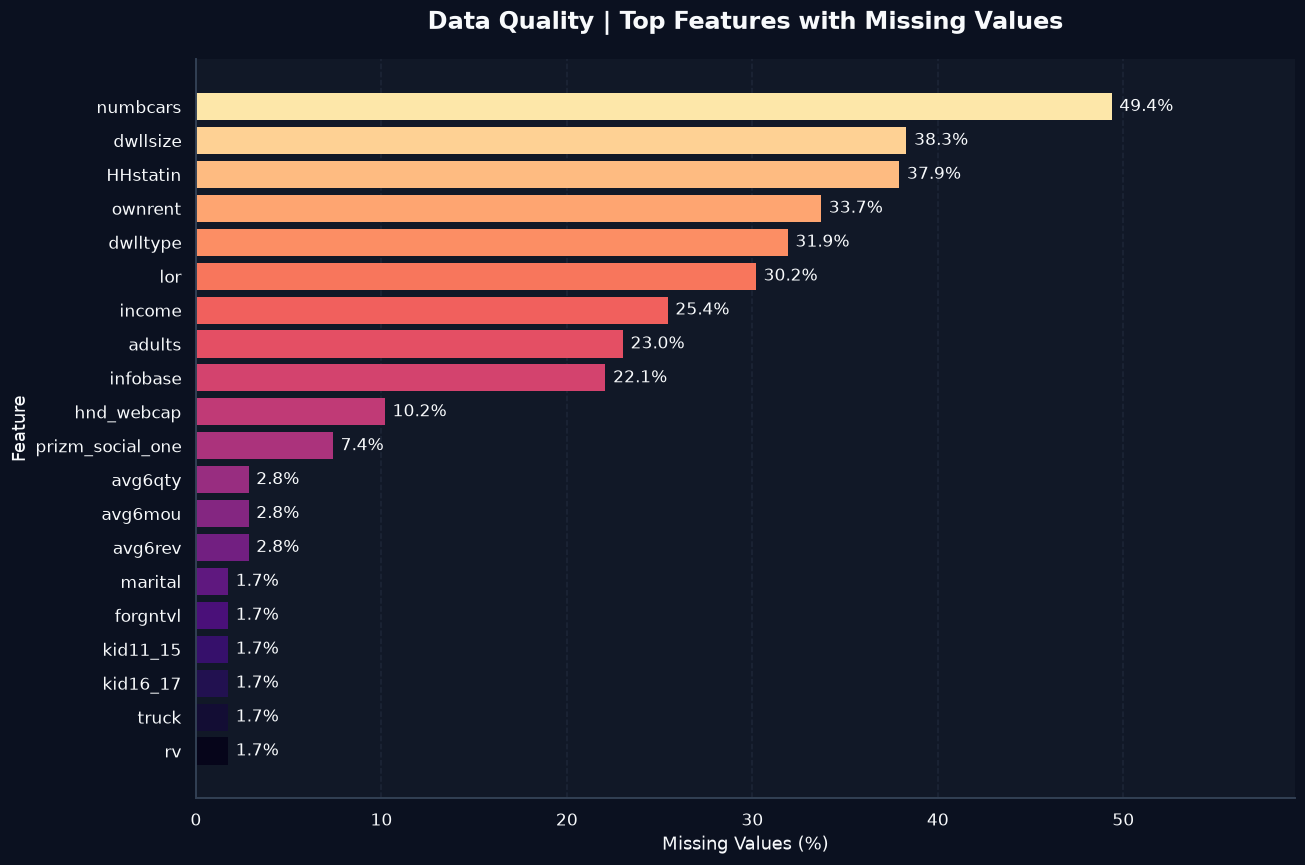

In [17]:
plot_data = (
    missing.head(20)
    .sort_values("Missing_Percentage")
)

fig, ax = plt.subplots(figsize=(12, 8))

colors = sns.color_palette(
    "magma",
    n_colors=len(plot_data)
)

bars = ax.barh(
    plot_data["Feature"],
    plot_data["Missing_Percentage"],
    color=colors,
    edgecolor="none"
)

ax.bar_label(
    bars,
    fmt="%.1f%%",
    padding=5,
    color=TEXT_COLOR
)

ax.set_title(
    "Data Quality | Top Features with Missing Values",
    pad=20
)

ax.set_xlabel("Missing Values (%)")
ax.set_ylabel("Feature")

ax.set_xlim(
    0,
    max(5, plot_data["Missing_Percentage"].max() * 1.2)
)

ax.grid(axis="y", visible=False)

finish_plot(
    fig,
    "01_missing_values.png"
)

### Insights

- Missing values are concentrated in several customer
  demographic and household-related features.

- Missingness should be investigated before selecting
  an imputation or feature removal strategy.

- Missing-value handling will be fitted using training
  data only to prevent data leakage.

In [18]:
duplicate_rows = df.duplicated().sum()

duplicate_ids = df[KEY].duplicated().sum()

constant_features = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

near_constant_features = []

for col in df.columns:

    dominant_frequency = (
        df[col]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .iloc[0]
    )

    if dominant_frequency >= 0.99:

        near_constant_features.append({
            "Feature": col,
            "Dominant_Frequency":
                dominant_frequency
        })

print("Duplicate rows:", duplicate_rows)
print("Duplicate IDs :", duplicate_ids)
print("Constant features:", constant_features)

display(
    pd.DataFrame(
        near_constant_features,
        columns=[
            "Feature",
            "Dominant_Frequency"
        ]
    )
)

Duplicate rows: 0
Duplicate IDs : 0
Constant features: []


,Feature,Dominant_Frequency
0,recv_sms_Mean,0.9913
1,callfwdv_Mean,0.9957


In [19]:
numeric_cols = df.select_dtypes(
    include="number"
).columns.tolist()

negative_report = []

for col in numeric_cols:

    negative_count = (df[col] < 0).sum()

    if negative_count > 0:

        negative_report.append({
            "Feature": col,
            "Negative_Count": negative_count,
            "Minimum_Value": df[col].min(),
            "Maximum_Value": df[col].max()
        })

negative_report = pd.DataFrame(
    negative_report
).sort_values(
    "Negative_Count",
    ascending=False
)

display(negative_report)

numeric_array = df[numeric_cols].to_numpy(
    dtype=float
)

print(
    "Infinite values:",
    np.isinf(numeric_array).sum()
)

assert set(df["churn"].unique()) == {0, 1}

,Feature,Negative_Count,Minimum_Value,Maximum_Value
3,change_rev,56150,"-1,107.7400","9,963.6575"
2,change_mou,53651,"-3,875.0000","31,219.2500"
5,eqpdays,133,-5.0000,"1,823.0000"
1,totmrc_Mean,23,-26.9150,409.9900
0,rev_Mean,5,-6.1675,"3,843.2625"
4,avg6rev,3,-2.0000,866.0000


Infinite values: 0


In [20]:
TARGET = "churn"

target_summary = (
    df[TARGET]
    .value_counts()
    .sort_index()
    .rename_axis("Churn")
    .reset_index(name="Customers")
)

target_summary["Percentage"] = (
    target_summary["Customers"] / len(df) * 100
)

target_summary["Status"] = (
    target_summary["Churn"].map({
        0: "Retained",
        1: "Churned"
    })
)

display(target_summary)

,Churn,Customers,Percentage,Status
0,0,50438,50.4380,Retained
1,1,49562,49.5620,Churned


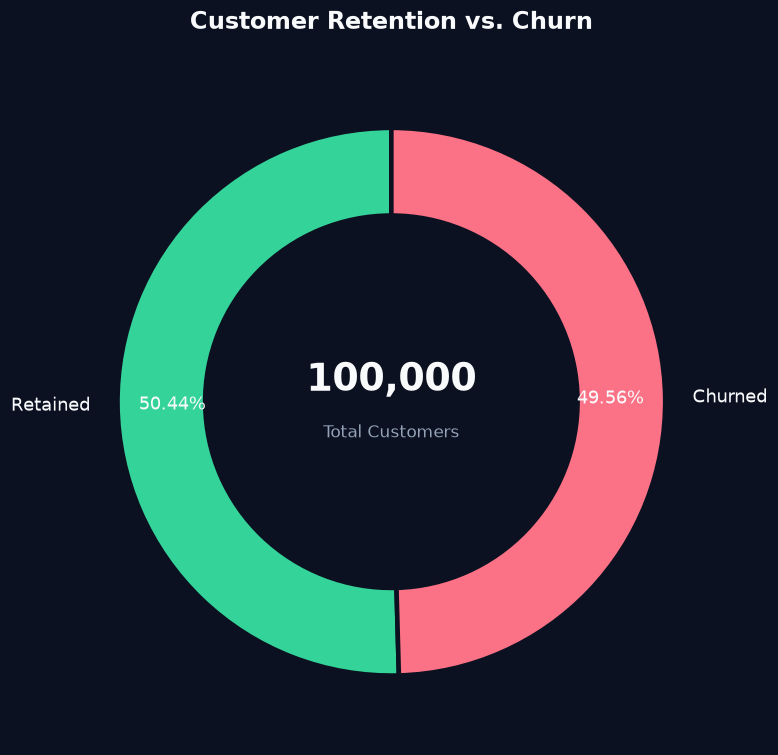

In [21]:
fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    target_summary["Customers"],

    labels=target_summary["Status"],

    colors=[GREEN, RED],

    autopct="%1.2f%%",

    startangle=90,

    pctdistance=0.80,

    wedgeprops={
        "width": 0.32,
        "edgecolor": BG_COLOR,
        "linewidth": 3
    },

    textprops={
        "color": TEXT_COLOR,
        "fontsize": 12
    }
)

ax.text(
    0, 0.04,
    f"{len(df):,}",
    ha="center",
    fontsize=25,
    fontweight="bold"
)

ax.text(
    0, -0.13,
    "Total Customers",
    ha="center",
    fontsize=11,
    color="#94A3B8"
)

ax.set_title(
    "Customer Retention vs. Churn",
    pad=20
)

finish_plot(
    fig,
    "02_churn_distribution.png"
)

In [22]:
from sklearn.model_selection import train_test_split

train_df, temporary_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df[TARGET]
)

val_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_df[TARGET]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

split_summary = pd.DataFrame([
    {
        "Split": name,
        "Rows": len(dataset),
        "Churn_Rate": dataset[TARGET].mean()
    }
    for name, dataset in [
        ("Training", train_df),
        ("Validation", val_df),
        ("Testing", test_df)
    ]
])

display(split_summary)

assert not set(train_df[KEY]) & set(val_df[KEY])
assert not set(train_df[KEY]) & set(test_df[KEY])
assert not set(val_df[KEY]) & set(test_df[KEY])

print("All dataset isolation checks passed.")

,Split,Rows,Churn_Rate
0,Training,70000,0.4956
1,Validation,15000,0.4957
2,Testing,15000,0.4956


All dataset isolation checks passed.


## Exploratory analysis — training data only

The stratified 70/15/15 split separates model fitting, development decisions and final evaluation. Subsequent target-related exploratory analyses use the training partition. Initial whole-dataset quality checks and target counts describe the supplied sample.

In [23]:
eda = train_df.copy()

print("EDA Dataset Shape:", eda.shape)

EDA Dataset Shape: (70000, 100)


In [24]:
numeric_features = (
    eda
    .select_dtypes(include="number")
    .columns
    .drop([KEY, TARGET])
)

statistics = pd.DataFrame({

    "Mean": eda[numeric_features].mean(),

    "Median": eda[numeric_features].median(),

    "Std": eda[numeric_features].std(),

    "Min": eda[numeric_features].min(),

    "Max": eda[numeric_features].max(),

    "Q1": eda[numeric_features].quantile(0.25),

    "Q3": eda[numeric_features].quantile(0.75),

    "Skewness": eda[numeric_features].skew(),

    "Kurtosis": eda[numeric_features].kurt(),

    "Missing_%":
        eda[numeric_features].isna().mean() * 100
})

statistics["IQR"] = (
    statistics["Q3"] - statistics["Q1"]
)

statistics = statistics.sort_values(
    "Skewness",
    key=abs,
    ascending=False
)

display(statistics)

statistics.to_csv(
    REPORTS_DIR / "descriptive_statistics.csv"
)

,Mean,Median,Std,Min,Max,Q1,Q3,Skewness,Kurtosis,Missing_%,IQR
blck_dat_Mean,0.0275,0.0000,1.7286,0.0000,413.3333,0.0000,0.0000,203.7854,"47,179.6125",0.0000,0.0000
roam_Mean,1.2904,0.0000,16.4626,0.0000,"3,685.2000",0.0000,0.2350,168.4484,"36,347.6079",0.3743,0.2350
recv_sms_Mean,0.0522,0.0000,2.4501,0.0000,517.3333,0.0000,0.0000,155.6174,"30,152.9967",0.0000,0.0000
drop_dat_Mean,0.0437,0.0000,1.0112,0.0000,207.3333,0.0000,0.0000,138.4831,"26,150.6707",0.0000,0.0000
callfwdv_Mean,0.0104,0.0000,0.4801,0.0000,81.3333,0.0000,0.0000,100.1056,"13,545.6719",0.0000,0.0000
change_rev,-1.1229,-0.3150,54.7137,"-1,107.7400","9,963.6575",-7.4375,1.5850,89.4298,"15,953.7230",0.9000,9.0225
mou_opkd_Mean,1.1226,0.0000,17.7078,0.0000,"2,922.0433",0.0000,0.0000,80.5401,"11,216.5786",0.0000,0.0000
unan_dat_Mean,0.0282,0.0000,0.4040,0.0000,42.6667,0.0000,0.0000,58.1588,"4,782.3303",0.0000,0.0000
mou_cdat_Mean,1.8171,0.0000,22.3869,0.0000,"3,032.0500",0.0000,0.0000,53.7795,"5,489.5867",0.0000,0.0000
datovr_Mean,0.2597,0.0000,2.8264,0.0000,276.2175,0.0000,0.0000,42.1098,"2,842.6337",0.3743,0.0000


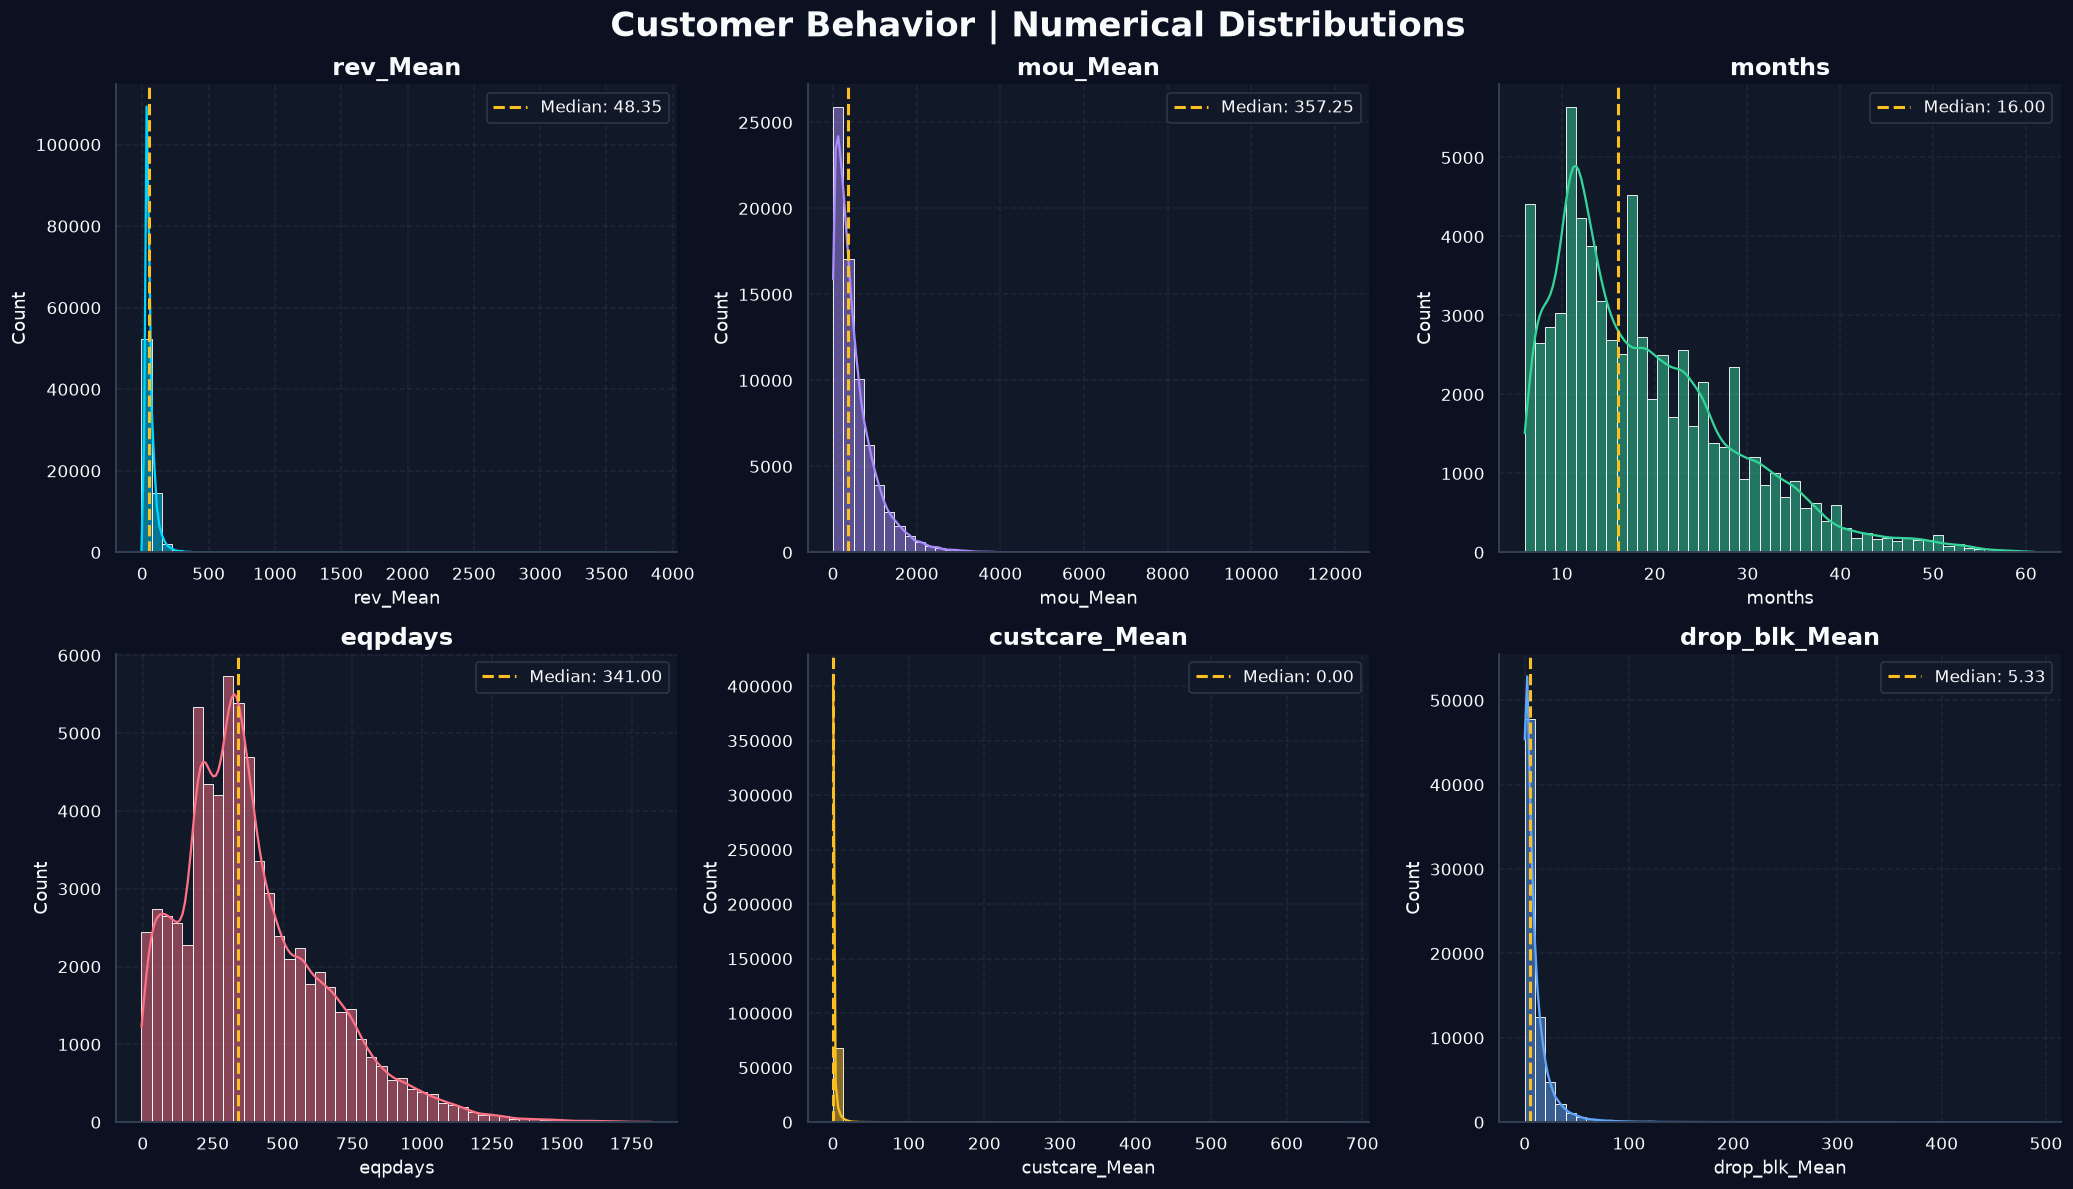

In [25]:
selected_features = [
    "rev_Mean",
    "mou_Mean",
    "months",
    "eqpdays",
    "custcare_Mean",
    "drop_blk_Mean"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 11)
)

for i, (ax, col) in enumerate(
    zip(axes.flat, selected_features)
):

    sns.histplot(
        data=eda,
        x=col,
        bins=50,
        kde=True,
        color=PALETTE[i],
        edgecolor=None,
        ax=ax
    )

    median_value = eda[col].median()

    ax.axvline(
        median_value,
        color=GOLD,
        linestyle="--",
        linewidth=2,
        label=f"Median: {median_value:.2f}"
    )

    ax.set_title(col)
    ax.legend()

fig.suptitle(
    "Customer Behavior | Numerical Distributions",
    fontsize=22,
    fontweight="bold"
)

finish_plot(
    fig,
    "03_numerical_distributions.png"
)

In [26]:
outlier_results = []

for col in numeric_features:

    values = eda[col].dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    if iqr == 0:
        continue

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (
        (values < lower) |
        (values > upper)
    )

    outlier_results.append({

        "Feature": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,

        "Outlier_Count": outliers.sum(),

        "Outlier_Percentage":
            outliers.mean() * 100

    })

outlier_report = (
    pd.DataFrame(outlier_results)
    .sort_values(
        "Outlier_Percentage",
        ascending=False
    )
)

display(outlier_report.head(20))

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
9,change_rev,-20.9713,15.1188,18110,26.1064
7,roam_Mean,-0.3525,0.5875,13273,19.0327
34,callwait_Mean,-2.0000,3.3333,10126,14.4657
18,cc_mou_Mean,-4.3650,7.2750,9900,14.1429
8,change_mou,-312.6250,288.3750,9492,13.6831
17,ccrndmou_Mean,-6.0000,10.0000,9437,13.4814
16,custcare_Mean,-2.5000,4.1667,8915,12.7357
4,ovrmou_Mean,-63.0000,105.0000,8042,11.5317
6,vceovr_Mean,-21.0938,35.1562,8017,11.4959
26,mouiwylisv_Mean,-27.4362,45.7271,7966,11.3800


In [28]:
equipment_analysis = eda[
    ["eqpdays", TARGET]
].copy()

equipment_analysis["Equipment_Age_Group"] = pd.cut(

    equipment_analysis["eqpdays"],

    bins=[0, 180, 365, 730, np.inf],

    labels=[
        "0-6 Months",
        "6-12 Months",
        "1-2 Years",
        "2+ Years"
    ],

    include_lowest=True
)

equipment_summary = (

    equipment_analysis

    .groupby(
        "Equipment_Age_Group",
        observed=True
    )

    .agg(
        Customers=(TARGET, "size"),
        Churned=(TARGET, "sum"),
        Churn_Rate=(TARGET, "mean")
    )

    .reset_index()
)

equipment_summary["Churn_Rate"] *= 100

display(equipment_summary)

,Equipment_Age_Group,Customers,Churned,Churn_Rate
0,0-6 Months,12794,5350,41.8165
1,6-12 Months,25477,11918,46.7794
2,1-2 Years,24023,12994,54.0898
3,2+ Years,7601,4394,57.8082


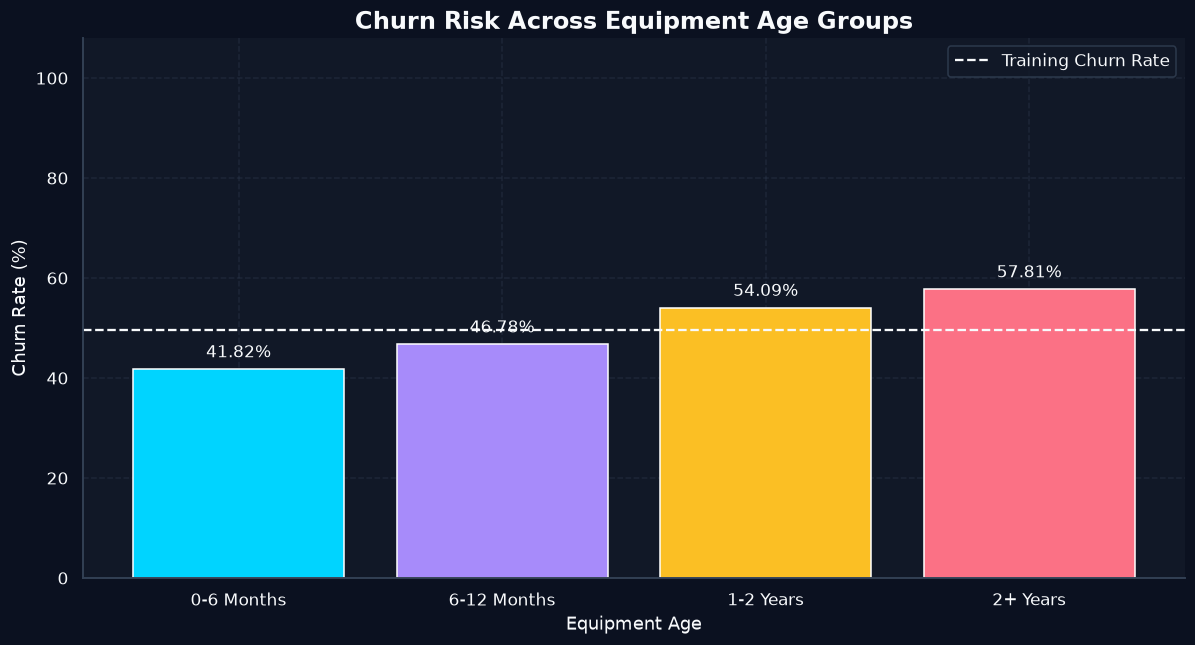

In [29]:
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(

    equipment_summary[
        "Equipment_Age_Group"
    ].astype(str),

    equipment_summary["Churn_Rate"],

    color=[
        CYAN,
        PURPLE,
        GOLD,
        RED
    ][:len(equipment_summary)]
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5
)

baseline_churn = eda[TARGET].mean() * 100

ax.axhline(
    baseline_churn,
    color="#F8FAFC",
    linestyle="--",
    label="Training Churn Rate"
)

ax.set_ylim(0, 108)
ax.set_title("Churn Risk Across Equipment Age Groups")
ax.set_xlabel("Equipment Age")
ax.set_ylabel("Churn Rate (%)")
ax.legend()

finish_plot(
    fig,
    "05_equipment_age_churn.png"
)

**Interpretation.** The recorded training analysis shows higher churn among customers with older equipment (57.81% for devices older than two years versus 41.82% for devices up to six months old). This motivates evaluating device-upgrade interventions, but does not establish a causal treatment effect.

# 5. Advanced Exploratory Data Analysis

This section investigates potential drivers of customer churn
through behavioral, financial, service-quality and statistical
analysis.

The objectives are to:

- Identify meaningful customer behavior patterns.
- Quantify associations between features and churn.
- Investigate high-risk customer segments.
- Evaluate statistical and practical significance.
- Generate actionable business hypotheses.
- Support evidence-based feature engineering.

All exploratory model-development analyses are performed
using the training dataset to preserve test-set independence.

In [30]:
tenure_analysis = eda[
    ["months", TARGET]
].copy()

tenure_analysis["Tenure_Group"] = pd.cut(
    tenure_analysis["months"],
    bins=[0, 6, 12, 24, 36, np.inf],
    labels=[
        "0-6 Months",
        "6-12 Months",
        "1-2 Years",
        "2-3 Years",
        "3+ Years"
    ],
    include_lowest=True
)

tenure_summary = (
    tenure_analysis
    .groupby("Tenure_Group", observed=True)
    .agg(
        Customers=(TARGET, "size"),
        Churned=(TARGET, "sum"),
        Churn_Rate=(TARGET, "mean")
    )
    .reset_index()
)

tenure_summary["Churn_Rate"] *= 100

tenure_summary["Risk_Lift"] = (
    tenure_summary["Churn_Rate"] /
    (eda[TARGET].mean() * 100)
)

display(tenure_summary.round(3))

,Tenure_Group,Customers,Churned,Churn_Rate,Risk_Lift
0,0-6 Months,915,356,38.9070,0.7850
1,6-12 Months,21908,10280,46.9230,0.9470
2,1-2 Years,29850,15485,51.8760,1.0470
3,2-3 Years,13378,6710,50.1570,1.0120
4,3+ Years,3949,1862,47.1510,0.9510


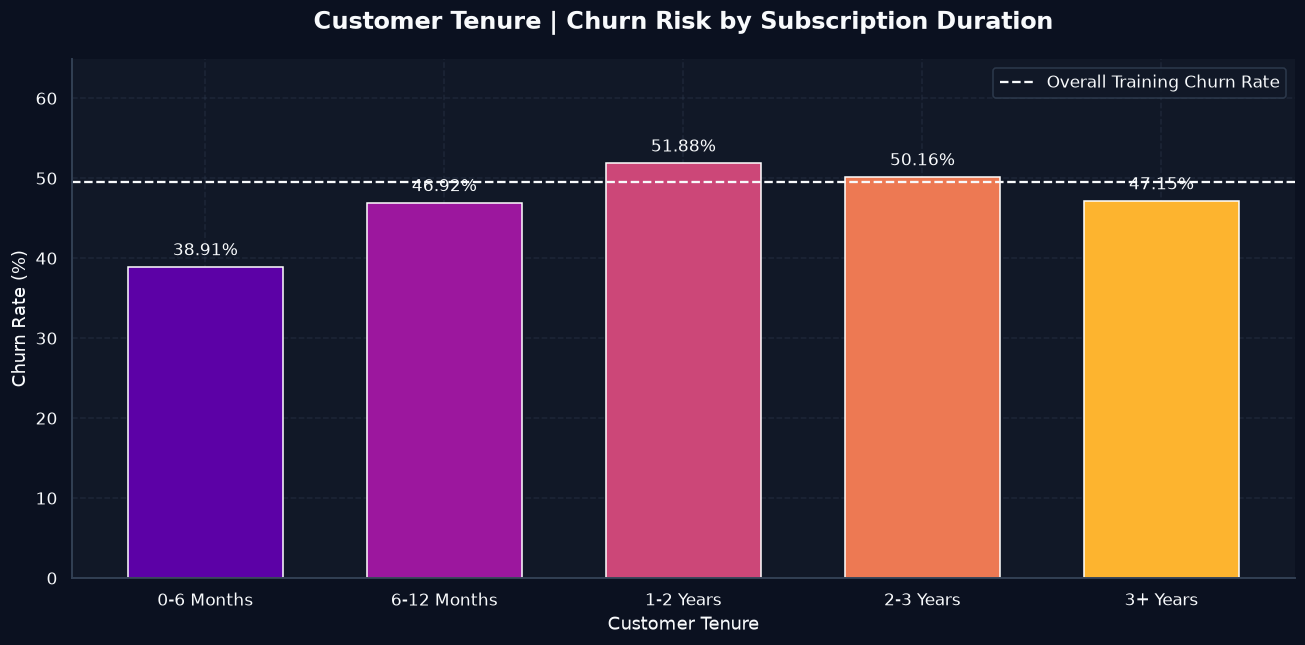

In [31]:
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    tenure_summary["Tenure_Group"].astype(str),
    tenure_summary["Churn_Rate"],
    color=sns.color_palette(
        "plasma",
        n_colors=len(tenure_summary)
    ),
    width=0.65
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5,
    color=TEXT_COLOR
)

ax.axhline(
    eda[TARGET].mean() * 100,
    color=TEXT_COLOR,
    linestyle="--",
    linewidth=1.5,
    label="Overall Training Churn Rate"
)

ax.set_ylim(
    0,
    max(tenure_summary["Churn_Rate"].max() * 1.25, 60)
)

ax.set_title(
    "Customer Tenure | Churn Risk by Subscription Duration",
    pad=20
)

ax.set_xlabel("Customer Tenure")
ax.set_ylabel("Churn Rate (%)")
ax.legend()

finish_plot(
    fig,
    "06_tenure_churn_analysis.png"
)

In [32]:
def safe_divide(numerator, denominator):

    numerator = pd.to_numeric(
        numerator,
        errors="coerce"
    ).astype(float)

    denominator = pd.to_numeric(
        denominator,
        errors="coerce"
    ).astype(float)

    result = numerator.div(
        denominator.where(denominator > 0)
    )

    return result.replace(
        [np.inf, -np.inf],
        np.nan
    )


print("Safe division utility initialized.")

Safe division utility initialized.


In [33]:
service_eda = eda.copy()

service_eda["call_failure_ratio"] = safe_divide(
    service_eda["drop_blk_Mean"],
    service_eda["attempt_Mean"]
)

service_eda["call_completion_ratio"] = safe_divide(
    service_eda["complete_Mean"],
    service_eda["attempt_Mean"]
)

service_eda["customer_care_intensity"] = safe_divide(
    service_eda["custcare_Mean"],
    service_eda["attempt_Mean"]
)

quality_features = [
    "call_failure_ratio",
    "call_completion_ratio",
    "customer_care_intensity"
]

display(
    service_eda[quality_features].describe().T
)

,count,mean,std,min,25%,50%,75%,max
call_failure_ratio,"64,245.0000",0.0729,0.0734,0.0000,0.0333,0.0550,0.0895,2.0000
call_completion_ratio,"64,245.0000",0.7551,0.1122,0.0000,0.7018,0.7677,0.8247,1.0000
customer_care_intensity,"64,245.0000",0.0123,0.0381,0.0000,0.0000,0.0000,0.0123,1.0000


In [34]:
ratio_validation = []

for col in quality_features:

    ratio_validation.append({

        "Feature": col,

        "Missing_Count":
            service_eda[col].isna().sum(),

        "Negative_Values":
            (service_eda[col] < 0).sum(),

        "Values_Above_One":
            (service_eda[col] > 1).sum(),

        "Median":
            service_eda[col].median(),

        "Maximum":
            service_eda[col].max()
    })

ratio_validation = pd.DataFrame(
    ratio_validation
)

display(ratio_validation)

,Feature,Missing_Count,Negative_Values,Values_Above_One,Median,Maximum
0,call_failure_ratio,5755,0,3,0.0550,2.0000
1,call_completion_ratio,5755,0,0,0.7677,1.0000
2,customer_care_intensity,5755,0,0,0.0000,1.0000


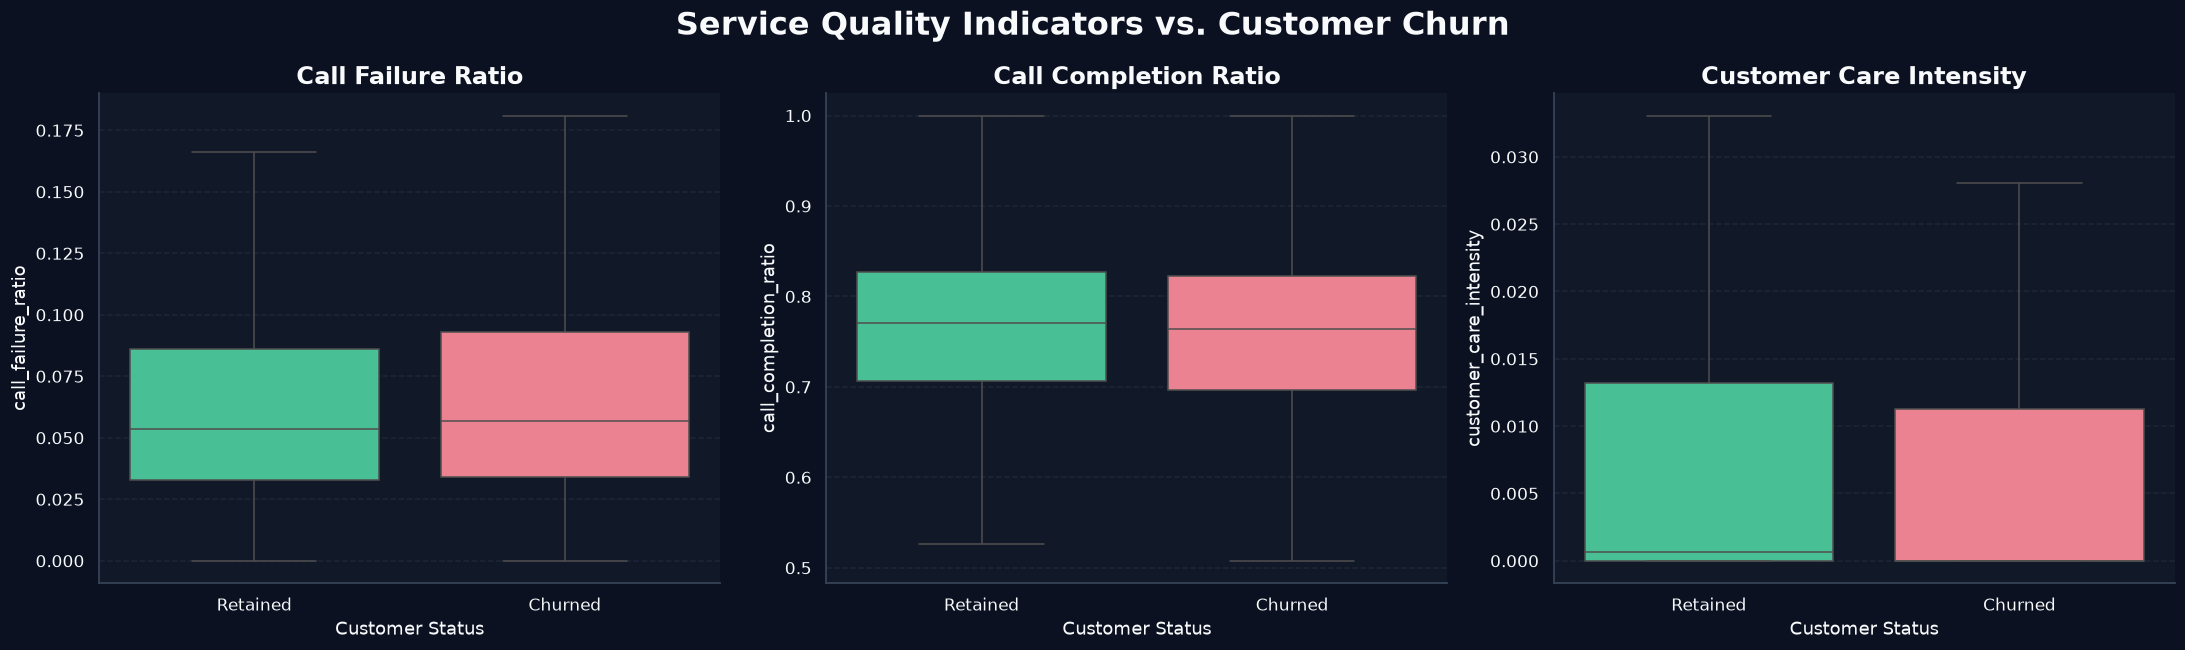

In [35]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6)
)

for ax, col in zip(
    axes.flat,
    quality_features
):

    sns.boxplot(
        data=service_eda,
        x=TARGET,
        y=col,
        hue=TARGET,
        palette=CHURN_COLORS,
        showfliers=False,
        legend=False,
        ax=ax
    )

    ax.set_xticks([0, 1])

    ax.set_xticklabels([
        "Retained",
        "Churned"
    ])

    ax.set_title(
        col.replace("_", " ").title()
    )

    ax.set_xlabel("Customer Status")

fig.suptitle(
    "Service Quality Indicators vs. Customer Churn",
    fontsize=21,
    fontweight="bold"
)

finish_plot(
    fig,
    "07_service_quality_analysis.png"
)

In [36]:
trend_eda = eda.copy()

trend_eda["usage_trend_ratio"] = safe_divide(
    trend_eda["avg3mou"],
    trend_eda["avg6mou"]
)

trend_eda["revenue_trend_ratio"] = safe_divide(
    trend_eda["avg3rev"],
    trend_eda["avg6rev"]
)

trend_eda["usage_trend_group"] = pd.cut(
    trend_eda["usage_trend_ratio"],

    bins=[
        -np.inf,
        0.8,
        1.2,
        np.inf
    ],

    labels=[
        "Declining Usage",
        "Stable Usage",
        "Increasing Usage"
    ]
)

trend_summary = (
    trend_eda
    .groupby(
        "usage_trend_group",
        observed=True
    )
    .agg(
        Customers=(TARGET, "size"),
        Churned=(TARGET, "sum"),
        Churn_Rate=(TARGET, "mean"),
        Mean_Revenue=("rev_Mean", "mean")
    )
    .reset_index()
)

trend_summary["Churn_Rate"] *= 100

display(trend_summary.round(3))

print(
    "Unclassified customers:",
    trend_eda["usage_trend_group"].isna().sum()
)

,usage_trend_group,Customers,Churned,Churn_Rate,Mean_Revenue
0,Declining Usage,12554,7111,56.6430,43.1930
1,Stable Usage,41885,19930,47.5830,60.9810
2,Increasing Usage,13083,6493,49.6290,67.8300


Unclassified customers: 2478


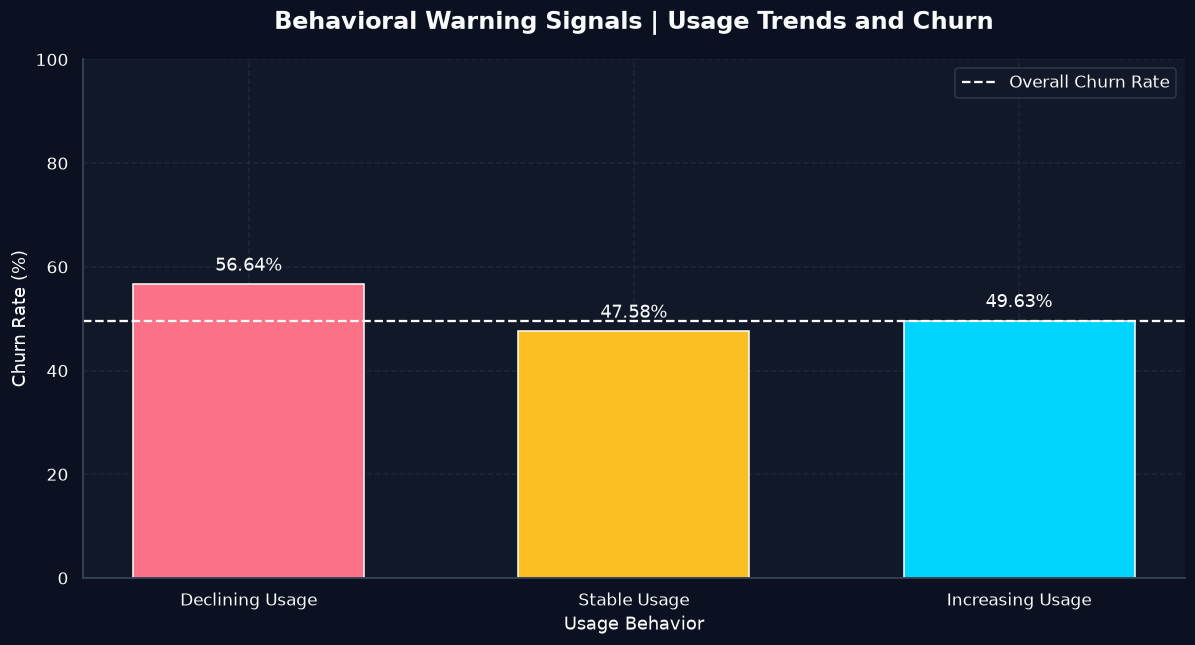

In [37]:
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    trend_summary["usage_trend_group"].astype(str),
    trend_summary["Churn_Rate"],
    color=[RED, GOLD, CYAN][:len(trend_summary)],
    width=0.60
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=6,
    fontsize=12
)

ax.axhline(
    eda[TARGET].mean() * 100,
    color=TEXT_COLOR,
    linestyle="--",
    label="Overall Churn Rate"
)

ax.set_ylim(0, 100)

ax.set_title(
    "Behavioral Warning Signals | Usage Trends and Churn",
    pad=20
)

ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Usage Behavior")
ax.legend()

finish_plot(
    fig,
    "08_usage_trend_churn.png"
)

**Interpretation.** The declining-usage segment had a recorded churn rate of 56.64%, compared with 47.58% for stable usage. The three- and six-month windows overlap, so this ratio is an approximate behavioral signal rather than a direct measurement of consecutive-period change.

# 6. Multivariate and Correlation Analysis

Pearson and Spearman correlation coefficients are used
to investigate linear and monotonic relationships.

Correlation analysis also helps identify potentially
redundant features and relationships that may influence
model selection and feature engineering.

Correlation does not establish causation.

In [38]:
correlation_data = (
    eda
    .select_dtypes(include="number")
    .drop(columns=[KEY], errors="ignore")
)

pearson_corr = correlation_data.corr(
    method="pearson"
)

spearman_corr = correlation_data.corr(
    method="spearman"
)

target_correlations = pd.DataFrame({

    "Pearson":
        pearson_corr[TARGET],

    "Spearman":
        spearman_corr[TARGET]

}).drop(index=TARGET)

target_correlations["Abs_Spearman"] = (
    target_correlations["Spearman"].abs()
)

target_correlations = (
    target_correlations
    .sort_values(
        "Abs_Spearman",
        ascending=False
    )
)

display(
    target_correlations.head(20).round(4)
)

target_correlations.to_csv(
    REPORTS_DIR / "target_correlations.csv"
)

,Pearson,Spearman,Abs_Spearman
eqpdays,0.1143,0.1301,0.1301
hnd_price,-0.1050,-0.1052,0.1052
totmrc_Mean,-0.0695,-0.0742,0.0742
mou_opkv_Mean,-0.0483,-0.0707,0.0707
mou_cvce_Mean,-0.0506,-0.0696,0.0696
mou_Mean,-0.0566,-0.0680,0.0680
iwylis_vce_Mean,-0.0409,-0.0634,0.0634
mouiwylisv_Mean,-0.0340,-0.0622,0.0622
complete_Mean,-0.0516,-0.0611,0.0611
comp_vce_Mean,-0.0512,-0.0608,0.0608


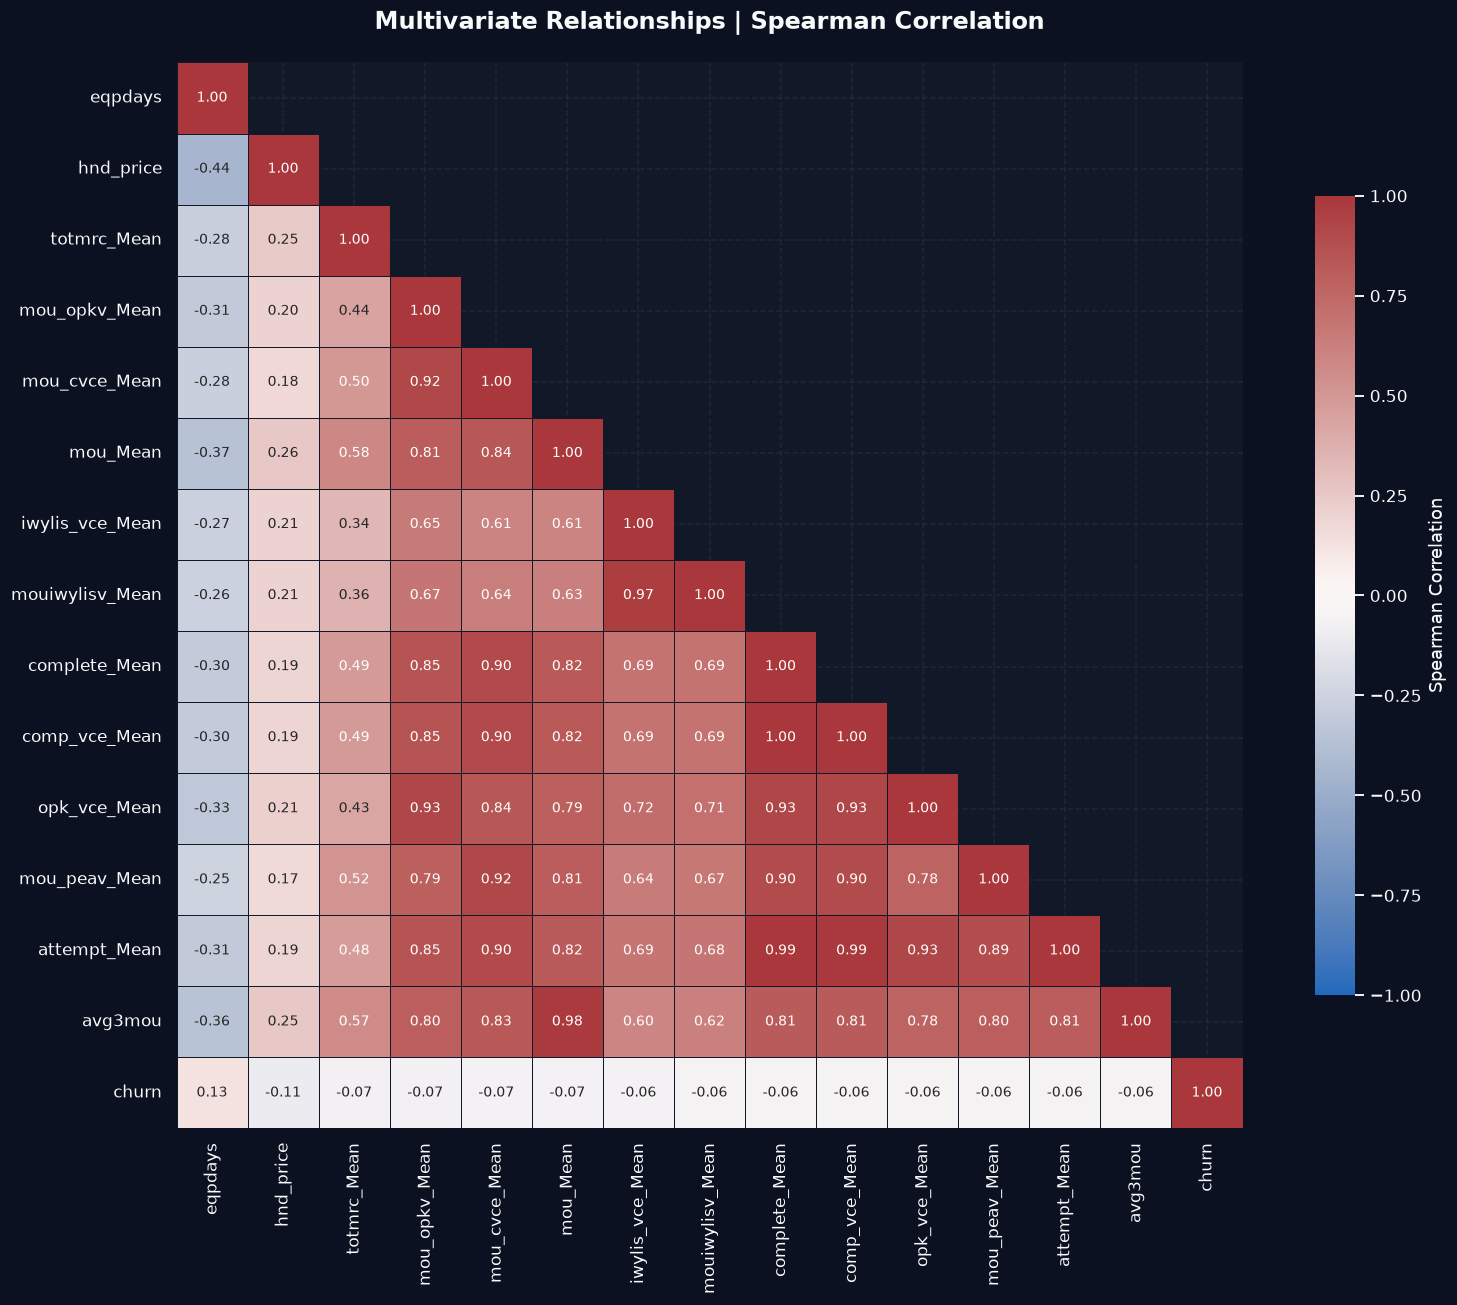

In [40]:
top_corr_features = (
    target_correlations
    .head(14)
    .index
    .tolist()
)

heatmap_features = (
    top_corr_features + [TARGET]
)

heatmap_corr = (
    eda[heatmap_features]
    .corr(method="spearman")
)

mask = np.triu(
    np.ones_like(
        heatmap_corr,
        dtype=bool
    ),
    k=1
)

fig, ax = plt.subplots(
    figsize=(15, 12)
)

sns.heatmap(
    heatmap_corr,

    mask=mask,

    cmap="vlag",

    center=0,

    vmin=-1,
    vmax=1,

    annot=True,
    fmt=".2f",

    linewidths=0.5,

    linecolor=PANEL_COLOR,

    square=True,

    annot_kws={
        "size": 9
    },

    cbar_kws={
        "shrink": 0.75,
        "label": "Spearman Correlation"
    },

    ax=ax
)

ax.set_title(
    "Multivariate Relationships | Spearman Correlation",
    pad=22
)

finish_plot(
    fig,
    "10_spearman_correlation_heatmap.png"
)

In [41]:
feature_corr = (
    spearman_corr
    .drop(index=TARGET, columns=TARGET)
    .abs()
)

upper_triangle = feature_corr.where(
    np.triu(
        np.ones(
            feature_corr.shape,
            dtype=bool
        ),
        k=1
    )
)

redundant_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

redundant_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Abs_Correlation"
]

redundant_pairs = (
    redundant_pairs[
        redundant_pairs["Abs_Correlation"] >= 0.90
    ]
    .sort_values(
        "Abs_Correlation",
        ascending=False
    )
)

display(
    redundant_pairs.head(30)
)

redundant_pairs.to_csv(
    REPORTS_DIR / "high_correlation_pairs.csv",
    index=False
)

,Feature_1,Feature_2,Abs_Correlation
3983,totcalls,adjqty,0.9995
4059,totmou,adjmou,0.9995
1353,plcd_vce_Mean,attempt_Mean,0.9993
2810,peak_dat_Mean,mou_pead_Mean,0.9992
1662,comp_vce_Mean,complete_Mean,0.9991
1723,comp_dat_Mean,mou_cdat_Mean,0.9989
3122,opk_dat_Mean,mou_opkd_Mean,0.9987
1873,ccrndmou_Mean,cc_mou_Mean,0.9981
313,ovrmou_Mean,ovrrev_Mean,0.9978
4135,totrev,adjrev,0.9957


# 7. Statistical Significance and Effect Size Analysis

Statistical tests are applied to investigate whether
observed differences between retained and churned
customers are statistically meaningful.

Effect sizes are reported alongside p-values to
distinguish statistical significance from practical
business significance.

False Discovery Rate correction is applied to account
for multiple hypothesis testing.

In [42]:
from scipy.stats import (
    mannwhitneyu,
    chi2_contingency
)

from statsmodels.stats.multitest import multipletests

from sklearn.feature_selection import mutual_info_classif

print("Statistical analysis libraries imported.")

Statistical analysis libraries imported.


In [43]:
numerical_test_results = []

for col in numeric_features:

    retained = (
        eda.loc[
            eda[TARGET] == 0, col
        ]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    churned = (
        eda.loc[
            eda[TARGET] == 1, col
        ]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if min(len(retained), len(churned)) < 30:
        continue

    u_stat, p_value = mannwhitneyu(
        churned,
        retained,
        alternative="two-sided",
        method="asymptotic"
    )

    effect_size = (
        2 * u_stat /
        (len(churned) * len(retained))
    ) - 1

    numerical_test_results.append({

        "Feature": col,

        "Retained_Median":
            retained.median(),

        "Churned_Median":
            churned.median(),

        "U_Statistic":
            u_stat,

        "P_Value":
            p_value,

        "Rank_Biserial":
            effect_size,

        "Abs_Effect_Size":
            abs(effect_size)
    })


numerical_tests = pd.DataFrame(
    numerical_test_results
)

reject, adjusted_p, _, _ = multipletests(
    numerical_tests["P_Value"],
    alpha=0.05,
    method="fdr_bh"
)

numerical_tests["Adjusted_P_Value"] = adjusted_p

numerical_tests["Significant"] = reject

numerical_tests = (
    numerical_tests
    .sort_values(
        "Abs_Effect_Size",
        ascending=False
    )
)

display(
    numerical_tests.head(20)
)

numerical_tests.to_csv(
    REPORTS_DIR / "numerical_statistical_tests.csv",
    index=False
)

,Feature,Retained_Median,Churned_Median,U_Statistic,P_Value,Rank_Biserial,Abs_Effect_Size,Adjusted_P_Value,Significant
76,eqpdays,309.0000,366.0000,"704,427,785.5000",0.0000,0.1502,0.1502,0.0000,True
66,hnd_price,129.9900,79.9900,"529,669,806.0000",0.0000,-0.1198,0.1198,0.0000,True
2,totmrc_Mean,44.9900,44.0625,"555,844,891.0000",0.0000,-0.0856,0.0856,0.0000,True
41,mou_opkv_Mean,85.7533,66.5600,"562,506,378.0000",0.0000,-0.0816,0.0816,0.0000,True
28,mou_cvce_Mean,160.0733,133.7300,"563,264,349.0000",0.0000,-0.0803,0.0803,0.0000,True
1,mou_Mean,382.2500,330.7500,"560,113,168.5000",0.0000,-0.0785,0.0785,0.0000,True
33,iwylis_vce_Mean,2.3333,1.6667,"568,241,069.0000",0.0000,-0.0722,0.0722,0.0000,True
34,mouiwylisv_Mean,4.0867,2.4767,"569,055,277.0000",0.0000,-0.0709,0.0709,0.0000,True
45,complete_Mean,81.6667,71.0000,"569,279,127.0000",0.0000,-0.0705,0.0705,0.0000,True
21,comp_vce_Mean,81.3333,70.6667,"569,477,689.5000",0.0000,-0.0702,0.0702,0.0000,True


In [45]:
def cramers_v(contingency_table):

    chi2, _, _, _ = chi2_contingency(
        contingency_table,
        correction=False
    )

    n = contingency_table.to_numpy().sum()

    rows, columns = contingency_table.shape

    denominator = min(
        rows - 1,
        columns - 1
    )

    if n <= 0 or denominator <= 0:
        return np.nan

    return np.sqrt(
        (chi2 / n) / denominator
    )

In [46]:
categorical_features = (
    eda
    .select_dtypes(
        include=[
            "object",
            "category",
            "string",
            "bool"
        ]
    )
    .columns
    .drop([KEY, TARGET], errors="ignore")
    .tolist()
)

categorical_test_results = []

for col in categorical_features:

    values = (
        eda[col]
        .astype("string")
        .fillna("__MISSING__")
    )

    category_counts = values.value_counts()

    rare_categories = category_counts[
        category_counts < 50
    ].index

    values = values.where(
        ~values.isin(rare_categories),
        "__RARE__"
    )

    contingency = pd.crosstab(
        values,
        eda[TARGET]
    )

    if min(contingency.shape) < 2:
        continue

    chi2, p_value, dof, expected = (
        chi2_contingency(
            contingency,
            correction=False
        )
    )

    categorical_test_results.append({

        "Feature": col,

        "Categories":
            contingency.shape[0],

        "Chi_Square":
            chi2,

        "P_Value":
            p_value,

        "Degrees_of_Freedom":
            dof,

        "Cramers_V":
            cramers_v(contingency),

        "Expected_Cells_Below_5_Pct":
            (expected < 5).mean() * 100
    })


categorical_tests = pd.DataFrame(
    categorical_test_results
)

reject, adjusted_p, _, _ = multipletests(
    categorical_tests["P_Value"],
    alpha=0.05,
    method="fdr_bh"
)

categorical_tests["Adjusted_P_Value"] = adjusted_p

categorical_tests["Significant"] = reject

categorical_tests = (
    categorical_tests
    .sort_values(
        "Cramers_V",
        ascending=False
    )
)

display(categorical_tests.round(5))

categorical_tests.to_csv(
    REPORTS_DIR / "categorical_statistical_tests.csv",
    index=False
)

,Feature,Categories,Chi_Square,P_Value,Degrees_of_Freedom,Cramers_V,Expected_Cells_Below_5_Pct,Adjusted_P_Value,Significant
7,hnd_webcap,4,582.1323,0.0000,3,0.0912,0.0000,0.0000,True
1,crclscod,32,441.0803,0.0000,31,0.0794,0.0000,0.0000,True
2,asl_flag,2,306.4791,0.0000,1,0.0662,0.0000,0.0000,True
14,ethnic,18,278.1554,0.0000,17,0.0630,0.0000,0.0000,True
5,dualband,5,232.0972,0.0000,4,0.0576,20.0000,0.0000,True
4,area,20,173.0044,0.0000,19,0.0497,0.0000,0.0000,True
6,refurb_new,3,72.8939,0.0000,2,0.0323,33.3333,0.0000,True
11,infobase,3,68.8164,0.0000,2,0.0314,0.0000,0.0000,True
10,marital,6,66.8037,0.0000,5,0.0309,0.0000,0.0000,True
12,HHstatin,7,58.7524,0.0000,6,0.0290,0.0000,0.0000,True


In [48]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

MI_SAMPLE_SIZE = min(30000, len(eda))

mi_data = eda.sample(
    n=MI_SAMPLE_SIZE,
    random_state=SEED
).copy()

X_mi = mi_data.drop(
    columns=[TARGET, KEY]
)

y_mi = mi_data[TARGET]

mi_numeric = (
    X_mi
    .select_dtypes(include="number")
    .columns
    .tolist()
)

mi_categorical = [
    col for col in X_mi.columns
    if col not in mi_numeric
]

mi_numeric_values = (
    X_mi[mi_numeric]
    .replace([np.inf, -np.inf], np.nan)
)

mi_numeric_values = SimpleImputer(
    strategy="median",
    keep_empty_features=True
).fit_transform(
    mi_numeric_values
)

mi_categorical_values = (
    X_mi[mi_categorical]
    .astype("string")
    .fillna("__MISSING__")
)

mi_categorical_values = OrdinalEncoder().fit_transform(
    mi_categorical_values
)

X_mi_processed = np.column_stack([
    mi_numeric_values,
    mi_categorical_values
])

mi_feature_names = (
    mi_numeric + mi_categorical
)

discrete_mask = (
    [False] * len(mi_numeric) +
    [True] * len(mi_categorical)
)

print(
    "Mutual Information dataset:",
    X_mi_processed.shape
)

Mutual Information dataset: (30000, 98)


In [49]:
mi_scores = mutual_info_classif(
    X_mi_processed,
    y_mi,

    discrete_features=discrete_mask,

    n_neighbors=5,

    random_state=SEED
)

mi_report = pd.DataFrame({

    "Feature":
        mi_feature_names,

    "Mutual_Information":
        mi_scores

}).sort_values(
    "Mutual_Information",
    ascending=False
)

display(
    mi_report.head(25).round(5)
)

mi_report.to_csv(
    REPORTS_DIR / "mutual_information_scores.csv",
    index=False
)

,Feature,Mutual_Information
76,eqpdays,0.0162
48,months,0.0148
2,totmrc_Mean,0.0112
51,totcalls,0.0075
66,hnd_price,0.0075
61,avg3qty,0.0068
49,uniqsubs,0.0056
63,avg6mou,0.0056
34,mouiwylisv_Mean,0.0056
1,mou_Mean,0.0054


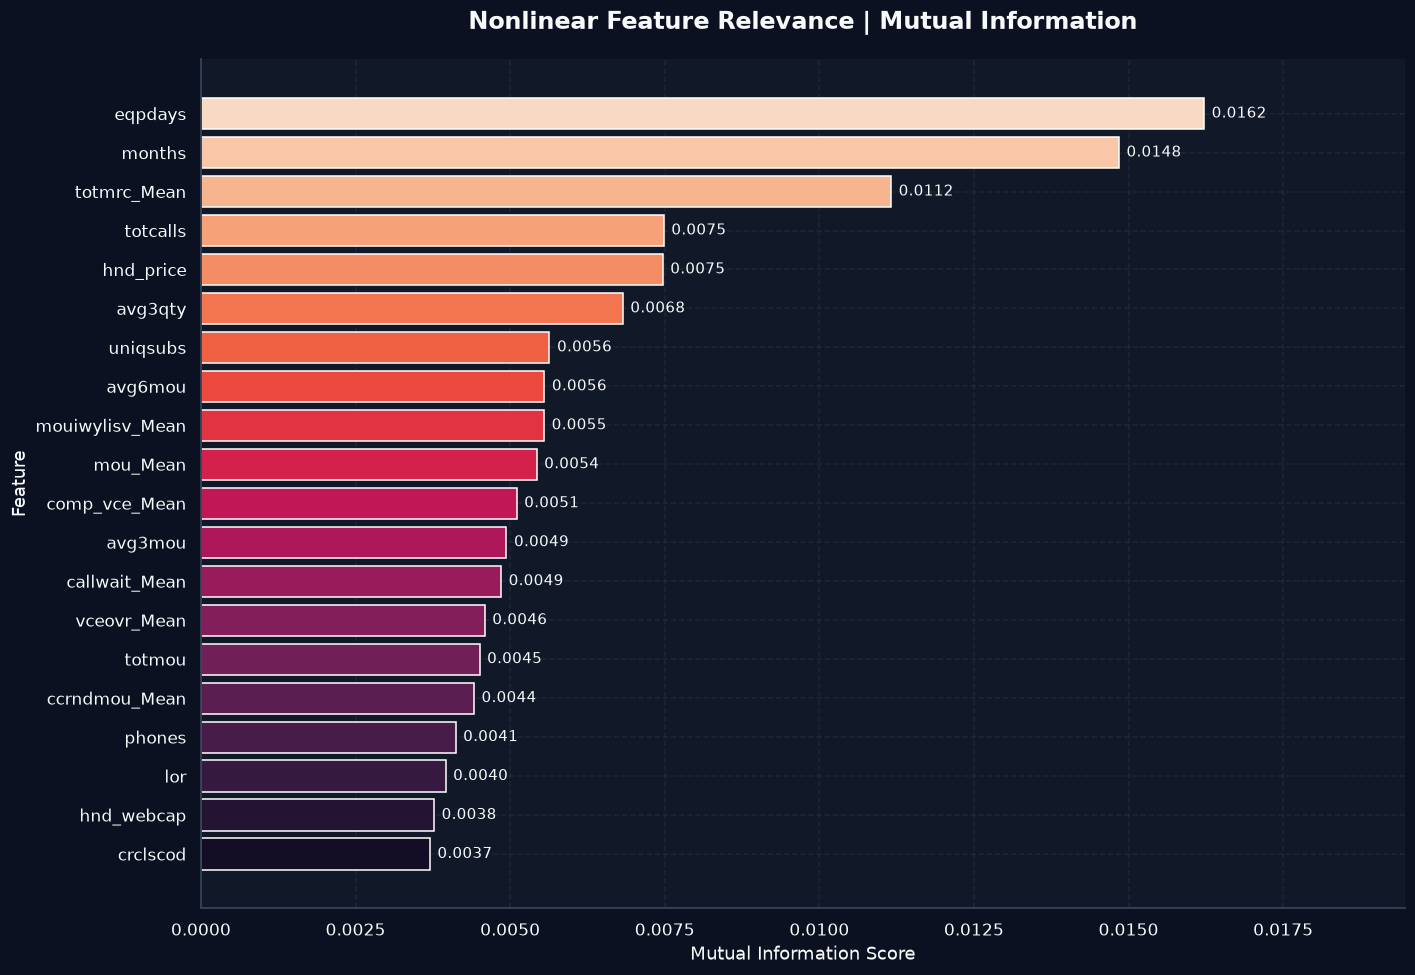

In [50]:
mi_plot = (
    mi_report
    .head(20)
    .sort_values("Mutual_Information")
)

fig, ax = plt.subplots(
    figsize=(13, 9)
)

bars = ax.barh(

    mi_plot["Feature"],

    mi_plot["Mutual_Information"],

    color=sns.color_palette(
        "rocket",
        n_colors=len(mi_plot)
    )
)

ax.bar_label(
    bars,
    fmt="%.4f",
    padding=5,
    fontsize=10
)

ax.set_xlim(
    0,
    max(
        0.01,
        mi_plot["Mutual_Information"].max() * 1.2
    )
)

ax.set_title(
    "Nonlinear Feature Relevance | Mutual Information",
    pad=20
)

ax.set_xlabel("Mutual Information Score")
ax.set_ylabel("Feature")

finish_plot(
    fig,
    "13_mutual_information.png"
)

# 8. Customer Segmentation and Business Analysis

Customer segments are analyzed according to subscription
duration, equipment age and monthly revenue.

The objective is to identify customer groups with
elevated observed churn rates and meaningful financial
importance.

The analysis supports targeted retention strategies
rather than uniform customer interventions.

In [51]:
segment_data = eda[
    [
        KEY,
        TARGET,
        "months",
        "eqpdays",
        "rev_Mean"
    ]
].copy()

segment_data["Tenure_Group"] = pd.cut(
    segment_data["months"],

    bins=[
        0,
        12,
        24,
        np.inf
    ],

    labels=[
        "New Customer",
        "Established",
        "Long-Term"
    ],

    include_lowest=True
)

segment_data["Device_Group"] = pd.cut(
    segment_data["eqpdays"],

    bins=[
        0,
        365,
        730,
        np.inf
    ],

    labels=[
        "Recent Device",
        "Aging Device",
        "Old Device"
    ],

    include_lowest=True
)

segment_data["Revenue_Group"] = pd.qcut(
    segment_data["rev_Mean"],
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Premium Value"
    ]
)

display(segment_data.head())

,Customer_ID,churn,months,eqpdays,rev_Mean,Tenure_Group,Device_Group,Revenue_Group
49013,1049014,1,15,190.0000,163.0000,Established,Recent Device,Premium Value
5428,1005429,1,38,710.0000,48.0425,Long-Term,Aging Device,Medium Value
70532,1070533,1,10,316.0000,32.4900,New Customer,Recent Device,Low Value
99153,1099154,1,29,885.0000,17.1433,Long-Term,Old Device,Low Value
36029,1036030,0,17,529.0000,71.8025,Established,Aging Device,Premium Value


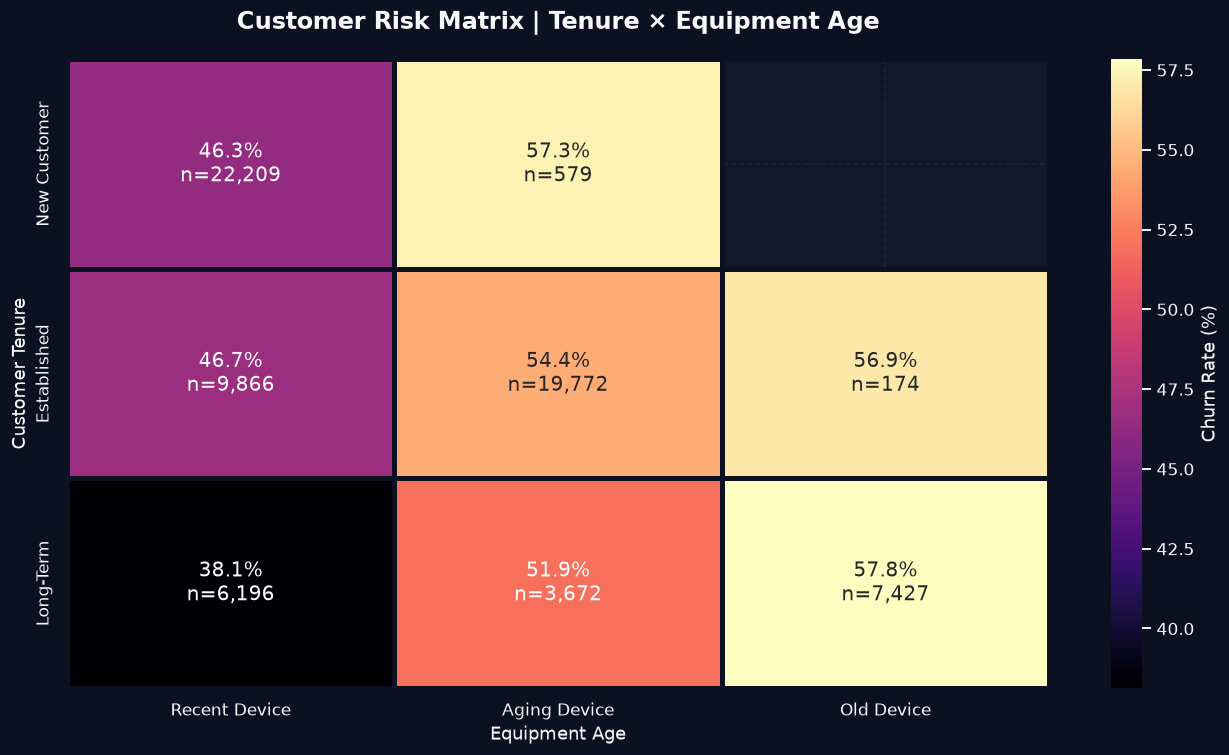

In [52]:
risk_matrix = segment_data.pivot_table(

    index="Tenure_Group",

    columns="Device_Group",

    values=TARGET,

    aggfunc="mean",

    observed=True

) * 100

segment_counts = segment_data.pivot_table(

    index="Tenure_Group",

    columns="Device_Group",

    values=TARGET,

    aggfunc="size",

    observed=True
)

segment_counts = segment_counts.reindex(
    index=risk_matrix.index,
    columns=risk_matrix.columns
)

risk_labels = np.empty(
    risk_matrix.shape,
    dtype=object
)

for i in range(risk_matrix.shape[0]):

    for j in range(risk_matrix.shape[1]):

        rate = risk_matrix.iloc[i, j]
        count = segment_counts.iloc[i, j]

        if pd.isna(rate):
            risk_labels[i, j] = "N/A"

        else:
            risk_labels[i, j] = (
                f"{rate:.1f}%\n"
                f"n={count:,.0f}"
            )


fig, ax = plt.subplots(
    figsize=(12, 7)
)

sns.heatmap(

    risk_matrix,

    annot=risk_labels,
    fmt="",

    cmap="magma",

    linewidths=2,

    linecolor=BG_COLOR,

    cbar_kws={
        "label": "Churn Rate (%)"
    },

    annot_kws={
        "size": 13
    },

    mask=segment_counts.fillna(0) < 50,

    ax=ax
)

ax.set_title(
    "Customer Risk Matrix | Tenure × Equipment Age",
    pad=20
)

ax.set_xlabel("Equipment Age")
ax.set_ylabel("Customer Tenure")

finish_plot(
    fig,
    "14_customer_risk_heatmap.png"
)

In [53]:
revenue_data = eda[
    [TARGET, "rev_Mean"]
].copy()

revenue_data["Valid_Revenue"] = (
    revenue_data["rev_Mean"]
    .where(
        revenue_data["rev_Mean"] >= 0
    )
)

revenue_summary = (
    revenue_data
    .groupby(TARGET)
    .agg(

        Customers=(TARGET, "size"),

        Valid_Revenue_Count=(
            "Valid_Revenue", "count"
        ),

        Mean_Monthly_Revenue=(
            "Valid_Revenue", "mean"
        ),

        Median_Monthly_Revenue=(
            "Valid_Revenue", "median"
        ),

        Historical_Monthly_Revenue=(
            "Valid_Revenue", "sum"
        )
    )
    .reset_index()
)

revenue_summary["Customer_Status"] = (
    revenue_summary[TARGET].map({
        0: "Retained",
        1: "Churned"
    })
)

display(
    revenue_summary.round(2)
)

,churn,Customers,Valid_Revenue_Count,Mean_Monthly_Revenue,Median_Monthly_Revenue,Historical_Monthly_Revenue,Customer_Status
0,0,35307,35224,59.3900,49.0200,"2,091,923.8800",Retained
1,1,34693,34510,58.2600,47.6300,"2,010,716.1700",Churned


In [54]:
revenue_segment_summary = (
    segment_data
    .groupby(
        "Revenue_Group",
        observed=True
    )
    .agg(

        Customers=(TARGET, "size"),

        Churned_Customers=(TARGET, "sum"),

        Churn_Rate=(TARGET, "mean"),

        Average_Monthly_Revenue=(
            "rev_Mean", "mean"
        )

    )
    .reset_index()
)

segment_data["Churn_Associated_Revenue"] = (
    segment_data["rev_Mean"]
    .where(segment_data["rev_Mean"] >= 0)
    .where(segment_data[TARGET] == 1, 0)
)

segment_exposure = (
    segment_data
    .groupby(
        "Revenue_Group",
        observed=True
    )["Churn_Associated_Revenue"]
    .sum(min_count=1)
)

revenue_segment_summary[
    "Historical_Revenue_Exposure"
] = (
    revenue_segment_summary["Revenue_Group"]
    .map(segment_exposure)
    .astype(float)
)

revenue_segment_summary["Churn_Rate"] *= 100

display(
    revenue_segment_summary.round(2)
)

revenue_segment_summary.to_csv(
    REPORTS_DIR / "revenue_segment_analysis.csv",
    index=False
)

,Revenue_Group,Customers,Churned_Customers,Churn_Rate,Average_Monthly_Revenue,Historical_Revenue_Exposure
0,Low Value,17435,9180,52.6500,24.3500,"221,655.8700"
1,Medium Value,17434,8316,47.7000,39.3700,"327,079.6500"
2,High Value,17434,8551,49.0500,57.2900,"489,389.0400"
3,Premium Value,17435,8464,48.5500,114.3000,"972,591.6000"


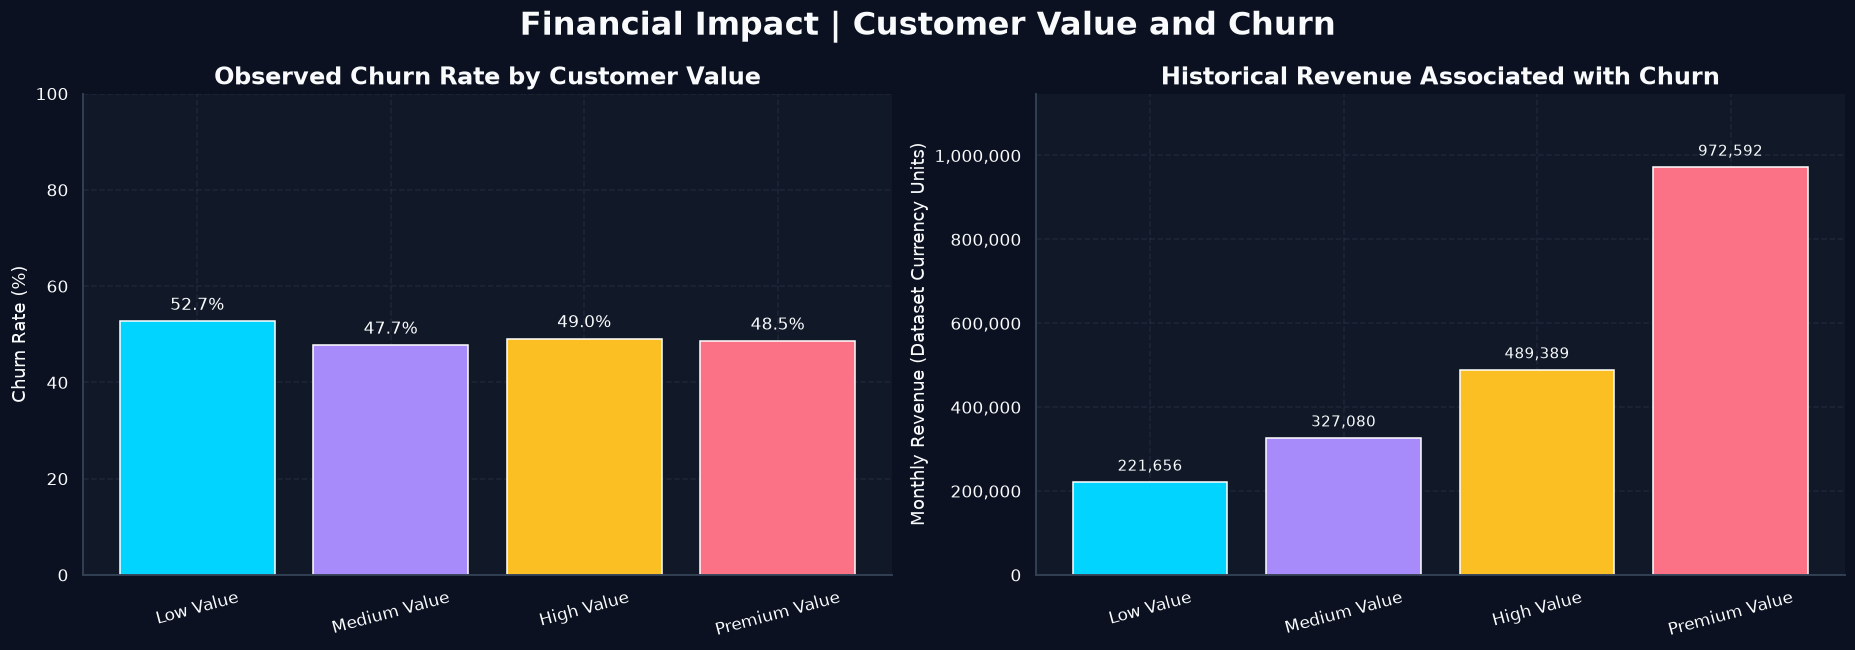

In [55]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 6)
)

revenue_colors = [
    CYAN,
    PURPLE,
    GOLD,
    RED
]

bars1 = axes[0].bar(

    revenue_segment_summary[
        "Revenue_Group"
    ].astype(str),

    revenue_segment_summary[
        "Churn_Rate"
    ],

    color=revenue_colors
)

axes[0].bar_label(
    bars1,
    fmt="%.1f%%",
    padding=5
)

axes[0].set_ylim(0, 100)

axes[0].set_title(
    "Observed Churn Rate by Customer Value"
)

axes[0].set_ylabel("Churn Rate (%)")

bars2 = axes[1].bar(

    revenue_segment_summary[
        "Revenue_Group"
    ].astype(str),

    revenue_segment_summary[
        "Historical_Revenue_Exposure"
    ],

    color=revenue_colors
)

axes[1].bar_label(
    bars2,
    labels=[
        f"{v:,.0f}"
        for v in revenue_segment_summary[
            "Historical_Revenue_Exposure"
        ]
    ],
    padding=5,
    fontsize=10
)

axes[1].set_title(
    "Historical Revenue Associated with Churn"
)

axes[1].set_ylabel(
    "Monthly Revenue (Dataset Currency Units)"
)

axes[1].yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

axes[1].margins(y=0.18)

for ax in axes:

    ax.tick_params(
        axis="x",
        rotation=15
    )

fig.suptitle(
    "Financial Impact | Customer Value and Churn",
    fontsize=21,
    fontweight="bold"
)

finish_plot(
    fig,
    "15_financial_exposure_analysis.png"
)

**Business implication.** Churn-associated historical revenue is concentrated in higher-value segments. The historical revenue of customers who churned is not a measured future loss; it motivates incorporating customer value into campaign prioritization.

In [57]:
fig = px.scatter(

    revenue_segment_summary,

    x="Average_Monthly_Revenue",

    y="Churn_Rate",

    size="Customers",

    color="Revenue_Group",

    hover_data=[
        "Churned_Customers",
        "Historical_Revenue_Exposure"
    ],

    color_discrete_sequence=[
        CYAN,
        PURPLE,
        GOLD,
        RED
    ],

    size_max=55,

    title=(
        "Customer Value vs. Churn Risk"
    ),

    template="plotly_dark+telecom_dark"
)

fig.update_layout(

    width=950,
    height=600,

    xaxis_title=(
        "Average Monthly Revenue "
        "(Dataset Currency Units)"
    ),

    yaxis_title="Observed Churn Rate (%)",

    legend_title="Customer Value"
)

fig.add_hline(
    y=eda[TARGET].mean() * 100,
    line_dash="dash",
    line_color=TEXT_COLOR
)

fig.show()

fig.write_html(
    str(
        FIGURES_DIR /
        "16_interactive_customer_value_risk.html"
    )
)

# 9. Business Problem Definition

## Business Objective

Reduce customer churn and protect recurring revenue
through an intelligent, data-driven retention strategy.

## Machine Learning Objective

Predict the likelihood of customer churn using
historical customer information and service-usage
behavior.

## Target Variable

- Target: churn
- 0: Retained customer
- 1: Churned customer

## Prediction Horizon

Churn occurring between 31 and 60 days after the
observation date, as defined in the dataset documentation.

## Machine Learning Task

Supervised Binary Classification.

## Proposed Business Application

A revenue-aware customer retention decision-support
system that prioritizes customers according to predicted
churn risk and financial importance.

## Limitations

- The sample churn rate may not represent the actual
  company's population churn rate.
- The dataset does not provide explicit observation dates.
- Statistical associations do not establish causality.
- Financial assumptions require validation before
  real-world implementation.

# 10. Feature Engineering

Domain-driven features are constructed from existing
telecommunication variables.

The engineered features represent:

- Customer engagement.
- Service quality.
- Usage and revenue trends.
- Billing behavior.
- Equipment lifecycle.
- Household subscription activity.

Feature engineering is implemented as a reusable,
deterministic transformation without using target labels.

In [59]:
def engineer_features(data):

    result = data.copy()

    # ==========================================
    # 1. Service Quality
    # ==========================================

    result["call_failure_ratio"] = safe_divide(
        result["drop_blk_Mean"],
        result["attempt_Mean"]
    )

    result["call_completion_ratio"] = safe_divide(
        result["complete_Mean"],
        result["attempt_Mean"]
    )

    result["customer_care_intensity"] = safe_divide(
        result["custcare_Mean"],
        result["attempt_Mean"]
    )

    # ==========================================
    # 2. Usage Behavior
    # ==========================================

    result["usage_trend_ratio"] = safe_divide(
        result["avg3mou"],
        result["avg6mou"]
    )

    result["call_volume_trend"] = safe_divide(
        result["avg3qty"],
        result["avg6qty"]
    )

    result["usage_change_gap"] = (
        result["avg3mou"] -
        result["avg6mou"]
    )

    result["incoming_outgoing_ratio"] = safe_divide(
        result["recv_vce_Mean"],
        result["plcd_vce_Mean"]
    )

    # ==========================================
    # 3. Revenue and Billing
    # ==========================================

    result["revenue_trend_ratio"] = safe_divide(
        result["avg3rev"],
        result["avg6rev"]
    )

    result["revenue_change_gap"] = (
        result["avg3rev"] -
        result["avg6rev"]
    )

    result["overage_revenue_ratio"] = safe_divide(
        result["ovrrev_Mean"],
        result["rev_Mean"]
    )

    result["revenue_per_minute"] = safe_divide(
        result["rev_Mean"],
        result["mou_Mean"]
    )

    result["recurring_charge_ratio"] = safe_divide(
        result["totmrc_Mean"],
        result["rev_Mean"]
    )

    # ==========================================
    # 4. Equipment and Customer Lifecycle
    # ==========================================

    result["equipment_age_months"] = (
        result["eqpdays"] / 30.4375
    )

    result["equipment_tenure_ratio"] = safe_divide(
        result["equipment_age_months"],
        result["months"]
    )

    result["equipment_upgrade_frequency"] = safe_divide(
        result["phones"],
        result["months"]
    )

    # ==========================================
    # 5. Household Engagement
    # ==========================================

    result["household_active_ratio"] = safe_divide(
        result["actvsubs"],
        result["uniqsubs"]
    )

    result["inactive_household_subscribers"] = (
        result["uniqsubs"] -
        result["actvsubs"]
    )

    # ==========================================
    # 6. Data Quality Signals
    # ==========================================

    result["missing_feature_count"] = (
        data.isna().sum(axis=1)
    )

    # ==========================================
    # 7. Replace Infinite Values
    # ==========================================

    result = result.replace(
        [np.inf, -np.inf],
        np.nan
    )

    return result

In [60]:
EXCLUDED_FEATURES = [

    "Customer_ID",

    "ethnic",

    "income",

    "marital",

    "ownrent",

    "dwlltype",

    "dwllsize",

    "HHstatin",

    "prizm_social_one",

    "creditcd",

    "crclscod",

    "kid0_2",

    "kid3_5",

    "kid6_10",

    "kid11_15",

    "kid16_17"
]

X_train_raw = train_df.drop(
    columns=[TARGET] + EXCLUDED_FEATURES,
    errors="ignore"
)

X_val_raw = val_df.drop(
    columns=[TARGET] + EXCLUDED_FEATURES,
    errors="ignore"
)

X_test_raw = test_df.drop(
    columns=[TARGET] + EXCLUDED_FEATURES,
    errors="ignore"
)

y_train = train_df[TARGET].copy()

y_val = val_df[TARGET].copy()

y_test = test_df[TARGET].copy()

print("Training Inputs  :", X_train_raw.shape)
print("Validation Inputs:", X_val_raw.shape)
print("Testing Inputs   :", X_test_raw.shape)

Training Inputs  : (70000, 83)
Validation Inputs: (15000, 83)
Testing Inputs   : (15000, 83)


In [61]:
X_train = engineer_features(
    X_train_raw
)

X_val = engineer_features(
    X_val_raw
)

X_test = engineer_features(
    X_test_raw
)

new_features = [
    col for col in X_train.columns
    if col not in X_train_raw.columns
]

print("=" * 60)

print("FEATURE ENGINEERING SUMMARY")

print("=" * 60)

print(
    "Original Features:",
    X_train_raw.shape[1]
)

print(
    "Engineered Features:",
    len(new_features)
)

print(
    "Final Features:",
    X_train.shape[1]
)

print("=" * 60)

display(
    pd.DataFrame({
        "Engineered_Feature": new_features
    })
)

FEATURE ENGINEERING SUMMARY
Original Features: 83
Engineered Features: 18
Final Features: 101


,Engineered_Feature
0,call_failure_ratio
1,call_completion_ratio
2,customer_care_intensity
3,usage_trend_ratio
4,call_volume_trend
5,usage_change_gap
6,incoming_outgoing_ratio
7,revenue_trend_ratio
8,revenue_change_gap
9,overage_revenue_ratio


In [62]:
assert X_train.columns.equals(
    X_val.columns
)

assert X_train.columns.equals(
    X_test.columns
)

assert X_train.columns.is_unique

assert TARGET not in X_train.columns

assert KEY not in X_train.columns

assert len(X_train) == len(y_train)

assert len(X_val) == len(y_val)

assert len(X_test) == len(y_test)


engineered_audit = pd.DataFrame({

    "Feature":
        new_features,

    "Missing_Percentage":
        X_train[new_features].isna().mean().values * 100,

    "Unique_Values":
        X_train[new_features].nunique().values,

    "Minimum":
        X_train[new_features].min().values,

    "Median":
        X_train[new_features].median().values,

    "Maximum":
        X_train[new_features].max().values

})

display(
    engineered_audit.round(4)
)

engineered_audit.to_csv(
    REPORTS_DIR / "engineered_feature_audit.csv",
    index=False
)

print("Feature validation completed successfully.")

,Feature,Missing_Percentage,Unique_Values,Minimum,Median,Maximum
0,call_failure_ratio,8.2214,32943,0.0000,0.0550,2.0000
1,call_completion_ratio,8.2214,41433,0.0000,0.7677,1.0000
2,customer_care_intensity,8.2214,17916,0.0000,0.0000,1.0000
3,usage_trend_ratio,3.5400,41856,0.0000,1.0125,3.0000
4,call_volume_trend,3.5929,21626,0.0000,1.0068,3.0000
5,usage_change_gap,2.8386,1585,"-1,888.0000",2.0000,"2,284.0000"
6,incoming_outgoing_ratio,8.2329,47994,0.0000,0.2807,30.6000
7,revenue_trend_ratio,2.8414,6908,0.0357,1.0000,2.5000
8,revenue_change_gap,2.8386,355,-407.0000,0.0000,738.0000
9,overage_revenue_ratio,0.3929,38150,0.0000,0.0263,2.9013


Feature validation completed successfully.


In [63]:
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    RobustScaler
)

from sklearn.feature_selection import VarianceThreshold

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


In [64]:
model_numeric_features = (
    X_train
    .select_dtypes(include="number")
    .columns
    .tolist()
)

model_categorical_features = [
    col for col in X_train.columns
    if col not in model_numeric_features
]

print(
    "Numerical Features:",
    len(model_numeric_features)
)

print(
    "Categorical Features:",
    len(model_categorical_features)
)

display(
    pd.DataFrame({

        "Categorical_Feature":
            model_categorical_features,

        "Unique_Values": [
            X_train[col].nunique()
            for col in model_categorical_features
        ]

    })
)

Numerical Features: 94
Categorical Features: 7


,Categorical_Feature,Unique_Values
0,new_cell,3
1,asl_flag,2
2,area,19
3,dualband,4
4,refurb_new,2
5,hnd_webcap,3
6,infobase,2


In [65]:
def build_preprocessor(
    numeric_columns,
    categorical_columns,
    scale_numeric=False
):

    numeric_steps = [

        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )
        )

    ]

    if scale_numeric:

        numeric_steps.append(

            (
                "scaler",
                RobustScaler()
            )

        )

    numeric_pipeline = Pipeline(
        steps=numeric_steps
    )

    categorical_pipeline = Pipeline(

        steps=[

            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="__MISSING__"
                )
            ),

            (
                "encoder",
                OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=20,
                    sparse_output=True
                )
            )

        ]
    )

    preprocessor = ColumnTransformer(

        transformers=[

            (
                "numeric",
                numeric_pipeline,
                numeric_columns
            ),

            (
                "categorical",
                categorical_pipeline,
                categorical_columns
            )

        ],

        remainder="drop"

    )

    return preprocessor

In [66]:
linear_preprocessor = build_preprocessor(

    numeric_columns=model_numeric_features,

    categorical_columns=model_categorical_features,

    scale_numeric=True

)

tree_preprocessor = build_preprocessor(

    numeric_columns=model_numeric_features,

    categorical_columns=model_categorical_features,

    scale_numeric=False

)

print(
    "Linear and Tree-Based preprocessors created."
)

Linear and Tree-Based preprocessors created.


# 11. Machine Learning Experiments

Model development begins with baseline classifiers
to establish a reliable performance reference.

Subsequent experiments will compare advanced
tree-based models and ensemble methods.

Stratified cross-validation is used during model
development, while the validation dataset supports
model selection and decision optimization.

The test dataset remains reserved for final evaluation.

In [67]:
from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.metrics import (

    accuracy_score,

    balanced_accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    roc_auc_score,

    average_precision_score,

    matthews_corrcoef,

    brier_score_loss,

    log_loss,

    confusion_matrix,

    classification_report

)

from sklearn.base import clone

import joblib

CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print("Machine learning environment initialized.")

Machine learning environment initialized.


In [68]:
def evaluate_model(
    y_true,
    probabilities,
    threshold=0.5
):

    probabilities = np.asarray(
        probabilities
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    return {

        "Accuracy":
            accuracy_score(y_true, predictions),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_true, predictions
            ),

        "Precision":
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Specificity":
            specificity,

        "F1":
            f1_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_true,
                probabilities
            ),

        "Average_Precision":
            average_precision_score(
                y_true,
                probabilities
            ),

        "MCC":
            matthews_corrcoef(
                y_true,
                predictions
            ),

        "Brier_Score":
            brier_score_loss(
                y_true,
                probabilities
            ),

        "Log_Loss":
            log_loss(
                y_true,
                probabilities,
                labels=[0, 1]
            )

    }

In [69]:
baseline_models = {

    "Dummy Classifier": Pipeline([

        (
            "preprocessor",
            clone(tree_preprocessor)
        ),

        (
            "model",
            DummyClassifier(
                strategy="prior"
            )
        )

    ]),

    "Logistic Regression": Pipeline([

        (
            "preprocessor",
            clone(linear_preprocessor)
        ),

        (
            "model",
            LogisticRegression(

                max_iter=2000,

                C=1.0,

                solver="lbfgs",

                random_state=SEED

            )
        )

    ])
}

In [70]:
model_results = []

trained_models = {}

validation_predictions = {}


for name, model in baseline_models.items():

    print(f"\nTraining: {name}")

    start = time.perf_counter()

    model.fit(
        X_train,
        y_train
    )

    probabilities = model.predict_proba(
        X_val
    )[:, 1]

    metrics = evaluate_model(
        y_val,
        probabilities
    )

    elapsed = (
        time.perf_counter() - start
    )

    metrics["Model"] = name

    metrics["Training_Time_Seconds"] = elapsed

    model_results.append(metrics)

    trained_models[name] = model

    validation_predictions[name] = probabilities

    print(
        f"ROC-AUC: {metrics['ROC_AUC']:.4f}"
    )

    print(
        f"F1 Score: {metrics['F1']:.4f}"
    )


baseline_results = (
    pd.DataFrame(model_results)
    .set_index("Model")
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
)

display(
    baseline_results.round(4)
)


Training: Dummy Classifier
ROC-AUC: 0.5000
F1 Score: 0.0000

Training: Logistic Regression
ROC-AUC: 0.6356
F1 Score: 0.5899


d:\GCI\05. Final Assignment\05. Final Assignment (due Nov 28)\Grad-project\Telecom_Intelligence\Telecom_Intelligence\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss,Training_Time_Seconds
Model,,,,,,,,,,,,
Logistic Regression,0.5991,0.5989,0.5983,0.5817,0.6161,0.5899,0.6356,0.6155,0.1980,0.2363,0.6656,35.1711
Dummy Classifier,0.5043,0.5000,0.0000,0.0000,1.0000,0.0000,0.5000,0.4957,0.0000,0.2500,0.6931,1.8130


# 12. Data Refinement and Model Readiness

Before developing advanced machine learning models,
the engineered feature space is reviewed to ensure
numerical stability, domain consistency and reliable
model training.

This stage includes:

- Domain-specific data validation.
- Treatment of physically invalid values.
- Validation of engineered ratios.
- Removal of deterministic feature redundancy.
- Model-specific preprocessing improvements.
- Logistic regression convergence verification.

All model-development decisions are based on training
and validation data. The test dataset remains isolated
from model selection.

In [71]:
# ==========================================================
# DOMAIN-SPECIFIC DATA VALIDATION
# ==========================================================

domain_rules = {
    "eqpdays": 0,
    "months": 0,
    "phones": 0,
    "models": 0,
    "uniqsubs": 0,
    "actvsubs": 0,
    "mou_Mean": 0,
    "attempt_Mean": 0,
    "complete_Mean": 0,
    "drop_blk_Mean": 0,
    "custcare_Mean": 0
}

domain_violations = []

for feature, minimum in domain_rules.items():

    if feature not in X_train_raw.columns:
        continue

    values = X_train_raw[feature]

    invalid = values < minimum

    domain_violations.append({

        "Feature": feature,

        "Minimum_Allowed": minimum,

        "Actual_Minimum": values.min(),

        "Invalid_Count": invalid.sum(),

        "Invalid_Percentage":
            invalid.mean() * 100
    })

domain_report = (
    pd.DataFrame(domain_violations)
    .sort_values(
        "Invalid_Count",
        ascending=False
    )
)

display(domain_report.round(4))

domain_report.to_csv(
    REPORTS_DIR / "domain_validation_report.csv",
    index=False
)

,Feature,Minimum_Allowed,Actual_Minimum,Invalid_Count,Invalid_Percentage
0,eqpdays,0,-5.0000,104,0.1486
1,months,0,6.0000,0,0.0000
2,phones,0,1.0000,0,0.0000
3,models,0,1.0000,0,0.0000
4,uniqsubs,0,1.0000,0,0.0000
5,actvsubs,0,0.0000,0,0.0000
6,mou_Mean,0,0.0000,0,0.0000
7,attempt_Mean,0,0.0000,0,0.0000
8,complete_Mean,0,0.0000,0,0.0000
9,drop_blk_Mean,0,0.0000,0,0.0000


In [72]:
# Preserve the original feature engineering function
original_engineer_features = engineer_features


def clean_domain_values(data):

    result = data.copy()

    result = result.replace(
        [np.inf, -np.inf],
        np.nan
    )

    for feature, minimum in domain_rules.items():

        if feature in result.columns:

            result[feature] = result[
                feature
            ].where(
                result[feature] >= minimum
            )

    return result


print("Domain cleaning function initialized.")

Domain cleaning function initialized.


In [73]:
# ==========================================================
# REFINED FEATURE ENGINEERING
# ==========================================================

def engineer_features_v2(data):

    cleaned_data = clean_domain_values(data)

    result = original_engineer_features(
        cleaned_data
    )

    # Validate approximate bounded ratios

    bounded_ratios = [
        "call_failure_ratio",
        "call_completion_ratio",
        "household_active_ratio"
    ]

    for col in bounded_ratios:

        if col in result.columns:

            valid_ratio = (
                result[col].between(0, 1)
            )

            result[col] = result[col].where(
                valid_ratio
            )

    # Validate household activity consistency

    result["inactive_household_subscribers"] = (
        result["inactive_household_subscribers"]
        .where(
            result["inactive_household_subscribers"] >= 0
        )
    )

    # Remove deterministic unit conversion

    result = result.drop(
        columns=["equipment_age_months"],
        errors="ignore"
    )

    # Keep numeric values finite

    result = result.replace(
        [np.inf, -np.inf],
        np.nan
    )

    return result


print("Feature Engineering V2 initialized.")

Feature Engineering V2 initialized.


In [75]:
X_train_v1 = X_train.copy()
X_val_v1 = X_val.copy()

X_train = engineer_features_v2(
    X_train_raw
)

X_val = engineer_features_v2(
    X_val_raw
)

new_features = [
    col for col in X_train.columns
    if col not in X_train_raw.columns
]

assert X_train.columns.equals(
    X_val.columns
)

assert X_train.index.equals(
    y_train.index
)

assert X_val.index.equals(
    y_val.index
)

assert TARGET not in X_train.columns

assert KEY not in X_train.columns

print("=" * 60)
print("REFINED FEATURE SPACE")
print("=" * 60)

print("Original Features :", X_train_raw.shape[1])
print("Previous Features :", X_train_v1.shape[1])
print("Refined Features  :", X_train.shape[1])
print("Engineered Features:", len(new_features))

print("=" * 60)

REFINED FEATURE SPACE
Original Features : 83
Previous Features : 101
Refined Features  : 100
Engineered Features: 17


In [76]:
refinement_report = pd.DataFrame({

    "Feature": X_train.columns,

    "Missing_Before": [
        X_train_v1[col].isna().sum()
        for col in X_train.columns
    ],

    "Missing_After": [
        X_train[col].isna().sum()
        for col in X_train.columns
    ]

})

refinement_report["New_Missing_Values"] = (

    refinement_report["Missing_After"] -
    refinement_report["Missing_Before"]

)

refinement_report = refinement_report.sort_values(

    "New_Missing_Values",

    ascending=False

)

display(
    refinement_report[
        refinement_report["New_Missing_Values"] != 0
    ]
)

refinement_report.to_csv(

    REPORTS_DIR / "feature_refinement_report.csv",

    index=False

)

,Feature,Missing_Before,Missing_After,New_Missing_Values
82,eqpdays,1,105,104
95,equipment_tenure_ratio,1,105,104
83,call_failure_ratio,5755,5758,3


In [77]:
model_numeric_features = (
    X_train
    .select_dtypes(include="number")
    .columns
    .tolist()
)

model_categorical_features = [

    col for col in X_train.columns

    if col not in model_numeric_features

]

print(
    "Numerical Features:",
    len(model_numeric_features)
)

print(
    "Categorical Features:",
    len(model_categorical_features)
)

print("\nCategorical Columns:")

display(
    pd.DataFrame({
        "Feature": model_categorical_features
    })
)

Numerical Features: 93
Categorical Features: 7

Categorical Columns:


,Feature
0,new_cell
1,asl_flag
2,area
3,dualband
4,refurb_new
5,hnd_webcap
6,infobase


In [78]:
from sklearn.preprocessing import StandardScaler


def build_preprocessor_v2(
    numeric_columns,
    categorical_columns,
    scale_numeric=False
):

    numeric_steps = [

        (
            "imputer",

            SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )
        )

    ]

    if scale_numeric:

        numeric_steps.append(

            (
                "scaler",

                StandardScaler()
            )

        )

    numeric_pipeline = Pipeline(
        numeric_steps
    )

    categorical_pipeline = Pipeline([

        (
            "imputer",

            SimpleImputer(
                strategy="constant",
                fill_value="__MISSING__"
            )
        ),

        (
            "encoder",

            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
                sparse_output=True
            )
        )

    ])

    return ColumnTransformer(

        transformers=[

            (
                "numeric",
                numeric_pipeline,
                numeric_columns
            ),

            (
                "categorical",
                categorical_pipeline,
                categorical_columns
            )

        ],

        remainder="drop",

        sparse_threshold=0.3

    )


linear_preprocessor = build_preprocessor_v2(

    model_numeric_features,

    model_categorical_features,

    scale_numeric=True

)

tree_preprocessor = build_preprocessor_v2(

    model_numeric_features,

    model_categorical_features,

    scale_numeric=False

)

print("Updated preprocessing pipelines created.")

Updated preprocessing pipelines created.


In [79]:
# Preserve previous baseline results

previous_baseline_results = baseline_results.copy()

model_results = []

trained_models = {}

validation_predictions = {}

model_templates = {}


def train_and_evaluate(name, estimator):

    print("\n" + "=" * 65)
    print(f"TRAINING: {name}")
    print("=" * 65)

    model = clone(estimator)

    start_time = time.perf_counter()

    model.fit(
        X_train,
        y_train
    )

    training_time = (
        time.perf_counter() - start_time
    )

    start_time = time.perf_counter()

    train_probabilities = model.predict_proba(
        X_train
    )[:, 1]

    val_probabilities = model.predict_proba(
        X_val
    )[:, 1]

    prediction_time = (
        time.perf_counter() - start_time
    )

    metrics = evaluate_model(
        y_val,
        val_probabilities
    )

    metrics["Model"] = name

    metrics["Train_ROC_AUC"] = roc_auc_score(
        y_train,
        train_probabilities
    )

    metrics["AUC_Gap"] = (

        metrics["Train_ROC_AUC"] -
        metrics["ROC_AUC"]

    )

    metrics["Training_Time_Seconds"] = (
        training_time
    )

    metrics["Prediction_Time_Seconds"] = (
        prediction_time
    )

    # Store results without duplicate model entries

    model_results[:] = [
        row for row in model_results
        if row["Model"] != name
    ]

    model_results.append(metrics)

    trained_models[name] = model

    model_templates[name] = clone(
        estimator
    )

    validation_predictions[name] = (
        val_probabilities
    )

    print(
        f"Train ROC-AUC : "
        f"{metrics['Train_ROC_AUC']:.4f}"
    )

    print(
        f"Val ROC-AUC   : "
        f"{metrics['ROC_AUC']:.4f}"
    )

    print(
        f"F1 Score      : "
        f"{metrics['F1']:.4f}"
    )

    print(
        f"Recall        : "
        f"{metrics['Recall']:.4f}"
    )

    print(
        f"AUC Gap       : "
        f"{metrics['AUC_Gap']:.4f}"
    )

    print(
        f"Training Time : "
        f"{training_time:.2f} seconds"
    )

    return model

In [80]:
dummy_pipeline = Pipeline([

    (
        "preprocessor",

        clone(tree_preprocessor)
    ),

    (
        "model",

        DummyClassifier(
            strategy="prior"
        )
    )

])


dummy_model = train_and_evaluate(

    "Dummy Classifier",

    dummy_pipeline

)


TRAINING: Dummy Classifier
Train ROC-AUC : 0.5000
Val ROC-AUC   : 0.5000
F1 Score      : 0.0000
Recall        : 0.0000
AUC Gap       : 0.0000
Training Time : 1.43 seconds


In [81]:
import warnings

from sklearn.exceptions import ConvergenceWarning


logistic_pipeline = Pipeline([

    (
        "preprocessor",

        clone(linear_preprocessor)
    ),

    (
        "model",

        LogisticRegression(

            solver="lbfgs",

            C=0.1,

            max_iter=3000,

            tol=1e-4,

            random_state=SEED

        )
    )

])


with warnings.catch_warnings(record=True) as caught:

    warnings.simplefilter(
        "always",
        ConvergenceWarning
    )

    logistic_model = train_and_evaluate(

        "Logistic Regression",

        logistic_pipeline

    )

convergence_warnings = [

    warning for warning in caught

    if issubclass(
        warning.category,
        ConvergenceWarning
    )

]

iterations = (
    logistic_model
    .named_steps["model"]
    .n_iter_
)

print("\nConvergence Diagnostics:")

print("Iterations:", iterations)

print(
    "Convergence Warnings:",
    len(convergence_warnings)
)

if convergence_warnings:

    print(
        "WARNING: Further convergence refinement required."
    )

    for warning in convergence_warnings:
        print(warning.message)

else:

    print(
        "Logistic Regression converged without warnings."
    )


TRAINING: Logistic Regression
Train ROC-AUC : 0.6408
Val ROC-AUC   : 0.6356
F1 Score      : 0.5895
Recall        : 0.5809
AUC Gap       : 0.0052
Training Time : 3.52 seconds

Convergence Diagnostics:
Iterations: [133]
Convergence Warnings: 0
Logistic Regression converged without warnings.


In [82]:
current_baseline_results = (

    pd.DataFrame(model_results)

    .set_index("Model")

)

comparison = pd.DataFrame({

    "Previous_V1":

        previous_baseline_results.loc[
            "Logistic Regression"
        ],

    "Refined_V2":

        current_baseline_results.loc[
            "Logistic Regression"
        ]

})

selected_metrics = [

    "Accuracy",

    "ROC_AUC",

    "F1",

    "Recall",

    "Average_Precision",

    "Brier_Score",

    "Log_Loss"

]

comparison = comparison.loc[
    selected_metrics
]

comparison["Difference"] = (

    comparison["Refined_V2"] -

    comparison["Previous_V1"]

)

display(comparison.round(5))

,Previous_V1,Refined_V2,Difference
Accuracy,0.5991,0.5991,0.0000
ROC_AUC,0.6355,0.6356,0.0000
F1,0.5899,0.5895,-0.0003
Recall,0.5817,0.5809,-0.0008
Average_Precision,0.6155,0.6155,0.0000
Brier_Score,0.2363,0.2364,0.0000
Log_Loss,0.6656,0.6656,0.0000


# 13. Advanced Machine Learning Models

Advanced tree-based classifiers are investigated to
capture nonlinear relationships and interactions between
telecommunication customer features.

The following models are compared:

- Random Forest
- XGBoost
- LightGBM
- CatBoost

All models are evaluated using identical training and
validation partitions.

ROC-AUC is the primary ranking metric, supported by
classification, probability calibration, computational
efficiency and generalization metrics.

Hyperparameters in this stage are preliminary and will
be optimized in subsequent experiments.

In [83]:
# ==========================================================
# ADVANCED MACHINE LEARNING LIBRARIES
# ==========================================================

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier

from catboost import CatBoostClassifier

from sklearn.preprocessing import FunctionTransformer

import gc


CPU_CORES = os.cpu_count() or 2

N_JOBS = max(
    1,
    min(8, CPU_CORES - 1)
)

print("=" * 60)

print("COMPUTATIONAL CONFIGURATION")

print("=" * 60)

print("Available CPU Threads:", CPU_CORES)

print("Model Training Threads:", N_JOBS)

print("Training Device: CPU")

print("=" * 60)

COMPUTATIONAL CONFIGURATION
Available CPU Threads: 20
Model Training Threads: 8
Training Device: CPU


In [84]:
random_forest_pipeline = Pipeline([

    (
        "preprocessor",

        clone(tree_preprocessor)
    ),

    (
        "model",

        RandomForestClassifier(

            n_estimators=300,

            max_depth=18,

            min_samples_split=10,

            min_samples_leaf=5,

            max_features="sqrt",

            bootstrap=True,

            class_weight=None,

            n_jobs=N_JOBS,

            random_state=SEED

        )
    )

])


rf_model = train_and_evaluate(

    "Random Forest",

    random_forest_pipeline

)

gc.collect()


TRAINING: Random Forest
Train ROC-AUC : 0.9775
Val ROC-AUC   : 0.6831
F1 Score      : 0.6356
Recall        : 0.6531
AUC Gap       : 0.2943
Training Time : 19.19 seconds


1931

In [85]:
xgboost_pipeline = Pipeline([

    (
        "preprocessor",

        clone(tree_preprocessor)
    ),

    (
        "model",

        XGBClassifier(

            objective="binary:logistic",

            eval_metric="auc",

            n_estimators=500,

            learning_rate=0.03,

            max_depth=5,

            min_child_weight=5,

            subsample=0.85,

            colsample_bytree=0.85,

            reg_alpha=0.1,

            reg_lambda=2.0,

            gamma=0.1,

            tree_method="hist",

            n_jobs=N_JOBS,

            random_state=SEED,

            verbosity=0

        )
    )

])


xgb_model = train_and_evaluate(

    "XGBoost",

    xgboost_pipeline

)

gc.collect()


TRAINING: XGBoost
Train ROC-AUC : 0.7600
Val ROC-AUC   : 0.6973
F1 Score      : 0.6414
Recall        : 0.6507
AUC Gap       : 0.0627
Training Time : 7.56 seconds


14

In [86]:
lightgbm_pipeline = Pipeline([

    (
        "preprocessor",

        clone(tree_preprocessor)
    ),

    (
        "model",

        LGBMClassifier(

            objective="binary",

            n_estimators=500,

            learning_rate=0.03,

            num_leaves=31,

            max_depth=7,

            min_child_samples=50,

            subsample=0.85,

            subsample_freq=1,

            colsample_bytree=0.85,

            reg_alpha=0.1,

            reg_lambda=2.0,

            n_jobs=N_JOBS,

            random_state=SEED,

            verbosity=-1

        )
    )

])


lgbm_model = train_and_evaluate(

    "LightGBM",

    lightgbm_pipeline

)

gc.collect()


TRAINING: LightGBM
Train ROC-AUC : 0.7764
Val ROC-AUC   : 0.6982
F1 Score      : 0.6404
Recall        : 0.6492
AUC Gap       : 0.0782
Training Time : 5.72 seconds


204

In [87]:
def prepare_catboost_input(data):

    result = data.copy()

    numeric_columns = (
        result
        .select_dtypes(include="number")
        .columns
        .tolist()
    )

    categorical_columns = [

        col for col in result.columns

        if col not in numeric_columns

    ]

    for col in categorical_columns:

        result[col] = (

            result[col]

            .astype("string")

            .fillna("__MISSING__")

            .astype(str)

        )

    for col in numeric_columns:

        result[col] = (

            pd.to_numeric(
                result[col],
                errors="coerce"
            )

            .replace(
                [np.inf, -np.inf],
                np.nan
            )

            .astype(float)

        )

    return result


catboost_transformer = FunctionTransformer(

    prepare_catboost_input,

    validate=False

)


catboost_preview = prepare_catboost_input(

    X_train.head(5)

)

display(catboost_preview)

print("CatBoost input preparation completed.")

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,months,uniqsubs,actvsubs,new_cell,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,lor,adults,infobase,numbcars,forgntvl,eqpdays,call_failure_ratio,call_completion_ratio,customer_care_intensity,usage_trend_ratio,call_volume_trend,usage_change_gap,incoming_outgoing_ratio,revenue_trend_ratio,revenue_change_gap,overage_revenue_ratio,revenue_per_minute,recurring_charge_ratio,equipment_tenure_ratio,equipment_upgrade_frequency,household_active_ratio,inactive_household_subscribers,missing_feature_count
49013,163.0000,"1,110.2500",140.4650,0.2475,72.2500,25.2875,25.2875,0.0000,7.0000,-367.2500,31.9900,7.3333,0.0000,21.3333,0.0000,14.3333,0.0000,174.3333,0.0000,41.0000,0.0000,137.3333,0.0000,5.0000,9.0000,5.4500,8.3333,1.3333,455.7767,0.0000,406.8300,88.6667,211.8333,16.0000,117.3800,88.3333,0.0000,287.6967,0.0000,84.0000,0.0000,574.9167,0.0000,28.6667,174.3333,137.3333,0.0000,0.6667,15.0000,1.0000,1.0000,U,N,"2,622.0000","13,835.0000","2,571.3900","2,494.6600","13,795.0000","2,612.0000",178.1900,985.3600,186.5700,"1,233.0000",180.0000,152.0000,"1,002.0000",162.0000,125.0000,CHICAGO AREA,Y,N,199.9900,2.0000,2.0000,WCMB,0.0000,0.0000,1.0000,1.0000,M,NaN,0.0000,190.0000,0.1644,0.7878,0.0287,1.2305,1.1111,231.0000,0.2352,1.2160,27.0000,0.1551,0.1468,0.8617,0.4162,0.1333,1.0000,0.0000,1.0000
5428,48.0425,548.2500,42.4900,1.4850,14.2500,3.5625,3.5625,0.0000,0.5050,-191.2500,-3.8725,8.6667,0.0000,3.3333,0.0000,14.0000,0.0000,149.3333,0.0000,40.6667,0.0000,125.6667,0.0000,0.0000,0.0000,0.0000,17.6667,0.0000,324.7233,0.0000,137.9133,15.0000,45.9233,5.6667,30.0833,143.3333,0.0000,372.3200,0.0000,19.6667,0.0000,90.3167,0.0000,12.0000,149.3333,125.6667,0.0000,2.0000,38.0000,2.0000,2.0000,N,N,"7,571.0000","20,744.0000","2,562.9400","2,531.0000","20,742.0000","7,569.0000",68.4100,560.5900,204.5700,612.0000,187.0000,49.0000,514.0000,160.0000,46.0000,CENTRAL/SOUTH TEXAS AREA,Y,N,129.9900,2.0000,2.0000,WCMB,1.0000,1.0000,2.0000,2.0000,M,1.0000,0.0000,710.0000,0.0804,0.8415,0.0000,1.1907,1.1687,98.0000,0.2723,1.0652,3.0000,0.0742,0.0876,0.8844,0.6139,0.0526,1.0000,0.0000,0.0000
70532,32.4900,451.2500,42.4900,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,197.7500,-2.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,10.0000,1.0000,1.0000,U,Y,389.0000,"3,381.0000",353.3200,293.3400,"3,379.0000",387.0000,32.5900,375.4400,43.0000,385.0000,42.0000,33.0000,347.0000,37.0000,34.0000,NEW YORK CITY AREA,Y,N,149.9900,1.0000,1.0000,WCMB,NaN,NaN,NaN,NaN,__MISSING__,NaN,NaN,316.0000,NaN,NaN,NaN,1.1095,1.1351,38.0000,NaN,0.9706,-1.0000,0.0000,0.0720,1.3078,1.0382,0.1000,1.0000,0.0000,7.0000
99153,17.1433,9.6667,16.9900,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-2.6667,-0.1533,0.3333,0.0000,0.0000,0.0000,1.0000,0.0000,7.6667,0.0000,3.6667,0.0000,6.3333,0.0000,0.0000,0.0000,0.0000,3.3333,0.0000,6.7200,0.0000,0.4600,1.3333,0.9933,0.0000,0.0000,5.6667,0.0000,5.7300,0.0000,1.0000,0.0000,1.4500,0.0000,0.3333,7.6667,6.3333,0.0000,0.0000,29.0000,2.0000,2.0000,U,N,441.0000,825.0000,536.1400,514.6000,792.

CatBoost input preparation completed.


In [89]:
from copy import deepcopy
from sklearn.base import clone
from catboost import CatBoostClassifier


class CloneableCatBoostClassifier(CatBoostClassifier):

    def __sklearn_clone__(self):

        params = deepcopy(
            self.get_params(deep=False)
        )

        return self.__class__(**params)


print("CatBoost compatibility class initialized.")

CatBoost compatibility class initialized.


In [90]:
# ==========================================================
# CATBOOST CLASSIFIER — SKLEARN COMPATIBLE
# ==========================================================

catboost_pipeline = Pipeline([

    (
        "preprocessor",

        clone(catboost_transformer)
    ),

    (
        "model",

        CloneableCatBoostClassifier(

            iterations=600,

            learning_rate=0.04,

            depth=6,

            l2_leaf_reg=5,

            random_strength=1,

            bootstrap_type="Bayesian",

            bagging_temperature=0.5,

            loss_function="Logloss",

            eval_metric="AUC",

            cat_features=model_categorical_features,

            random_seed=SEED,

            thread_count=N_JOBS,

            task_type="CPU",

            allow_writing_files=False,

            verbose=False

        )
    )

])


# ==========================================================
# VALIDATE SKLEARN CLONING COMPATIBILITY
# ==========================================================

cloned_catboost = clone(catboost_pipeline)

assert cloned_catboost is not catboost_pipeline

assert (
    cloned_catboost.named_steps["model"]
    .get_params()["cat_features"]
    == model_categorical_features
)

print("CatBoost clone compatibility test passed.")


# ==========================================================
# TRAIN AND EVALUATE
# ==========================================================

cat_model = train_and_evaluate(

    "CatBoost",

    catboost_pipeline

)

gc.collect()

CatBoost clone compatibility test passed.

TRAINING: CatBoost
Train ROC-AUC : 0.7402
Val ROC-AUC   : 0.6951
F1 Score      : 0.6409
Recall        : 0.6537
AUC Gap       : 0.0451
Training Time : 53.22 seconds


1606

In [91]:
# ==========================================================
# CATBOOST POST-TRAINING VALIDATION
# ==========================================================

cat_probabilities = cat_model.predict_proba(
    X_val.head(100)
)[:, 1]

assert len(cat_probabilities) == 100

assert np.isfinite(cat_probabilities).all()

assert np.all(
    (cat_probabilities >= 0) &
    (cat_probabilities <= 1)
)

assert "CatBoost" in trained_models

assert "CatBoost" in model_templates

assert "CatBoost" in validation_predictions

clone(model_templates["CatBoost"])

print("All CatBoost validation tests passed.")

All CatBoost validation tests passed.


# 14. Comprehensive Model Evaluation

This section compares all trained machine learning models
using a comprehensive evaluation framework.

The evaluation covers:

- Classification performance.
- Discrimination and ranking ability.
- Generalization and overfitting.
- Probability calibration.
- Computational efficiency.
- Cross-validation stability.

The test dataset remains isolated until the final model,
hyperparameters and decision threshold are selected.

In [92]:
expected_models = [
    "Dummy Classifier",
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

for name in expected_models:

    assert name in trained_models, (
        f"{name} has not been trained."
    )

    assert name in validation_predictions, (
        f"{name} predictions are missing."
    )

    assert name in model_templates

    probabilities = validation_predictions[name]

    assert len(probabilities) == len(y_val)

    assert np.isfinite(probabilities).all()

    assert np.all(
        (probabilities >= 0) &
        (probabilities <= 1)
    )

    print(f"[PASS] {name}")

print("\nAll model validation checks passed.")

[PASS] Dummy Classifier
[PASS] Logistic Regression
[PASS] Random Forest
[PASS] XGBoost
[PASS] LightGBM
[PASS] CatBoost

All model validation checks passed.


In [93]:
leaderboard = (
    pd.DataFrame(model_results)
    .set_index("Model")
    .sort_values("ROC_AUC", ascending=False)
)

leaderboard["AUC_Improvement_vs_Dummy"] = (
    leaderboard["ROC_AUC"] -
    leaderboard.loc["Dummy Classifier", "ROC_AUC"]
)

leaderboard["AUC_Improvement_vs_Logistic"] = (
    leaderboard["ROC_AUC"] -
    leaderboard.loc["Logistic Regression", "ROC_AUC"]
)

leaderboard["Rank"] = (
    leaderboard["ROC_AUC"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

display(leaderboard.round(4))

leaderboard.to_csv(
    REPORTS_DIR / "initial_model_leaderboard.csv"
)

print("\nBest initial model:", leaderboard.index[0])

,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss,Train_ROC_AUC,AUC_Gap,Training_Time_Seconds,Prediction_Time_Seconds,AUC_Improvement_vs_Dummy,AUC_Improvement_vs_Logistic,Rank
Model,,,,,,,,,,,,,,,,,,
LightGBM,0.6387,0.6388,0.6319,0.6492,0.6283,0.6404,0.6982,0.6873,0.2776,0.2196,0.6282,0.7764,0.0782,5.7239,1.0206,0.1982,0.0626,1
XGBoost,0.6393,0.6394,0.6323,0.6507,0.6282,0.6414,0.6973,0.6855,0.2789,0.2200,0.6294,0.7600,0.0627,7.5582,0.4910,0.1973,0.0617,2
CatBoost,0.6369,0.6370,0.6286,0.6537,0.6204,0.6409,0.6951,0.6802,0.2741,0.2209,0.6315,0.7402,0.0451,53.2182,0.4511,0.1951,0.0595,3
Random Forest,0.6288,0.6290,0.6190,0.6531,0.6049,0.6356,0.6831,0.6663,0.2583,0.2253,0.6412,0.9775,0.2943,19.1864,1.1297,0.1831,0.0475,4
Logistic Regression,0.5991,0.5989,0.5984,0.5809,0.6169,0.5895,0.6356,0.6155,0.1980,0.2364,0.6656,0.6408,0.0052,3.5155,0.5107,0.1356,0.0000,5
Dummy Classifier,0.5043,0.5000,0.0000,0.0000,1.0000,0.0000,0.5000,0.4957,0.0000,0.2500,0.6931,0.5000,0.0000,1.4258,0.3317,0.0000,-0.1356,6



Best initial model: LightGBM


In [95]:
model_colors = {
    "Dummy Classifier": "#94A3B8",
    "Logistic Regression": CYAN,
    "Random Forest": GREEN,
    "XGBoost": GOLD,
    "LightGBM": BLUE,
    "CatBoost": PINK,
    "Soft Voting": PURPLE,
    "Stacking": "#2DD4BF"
}

print("Model visualization palette initialized.")

Model visualization palette initialized.


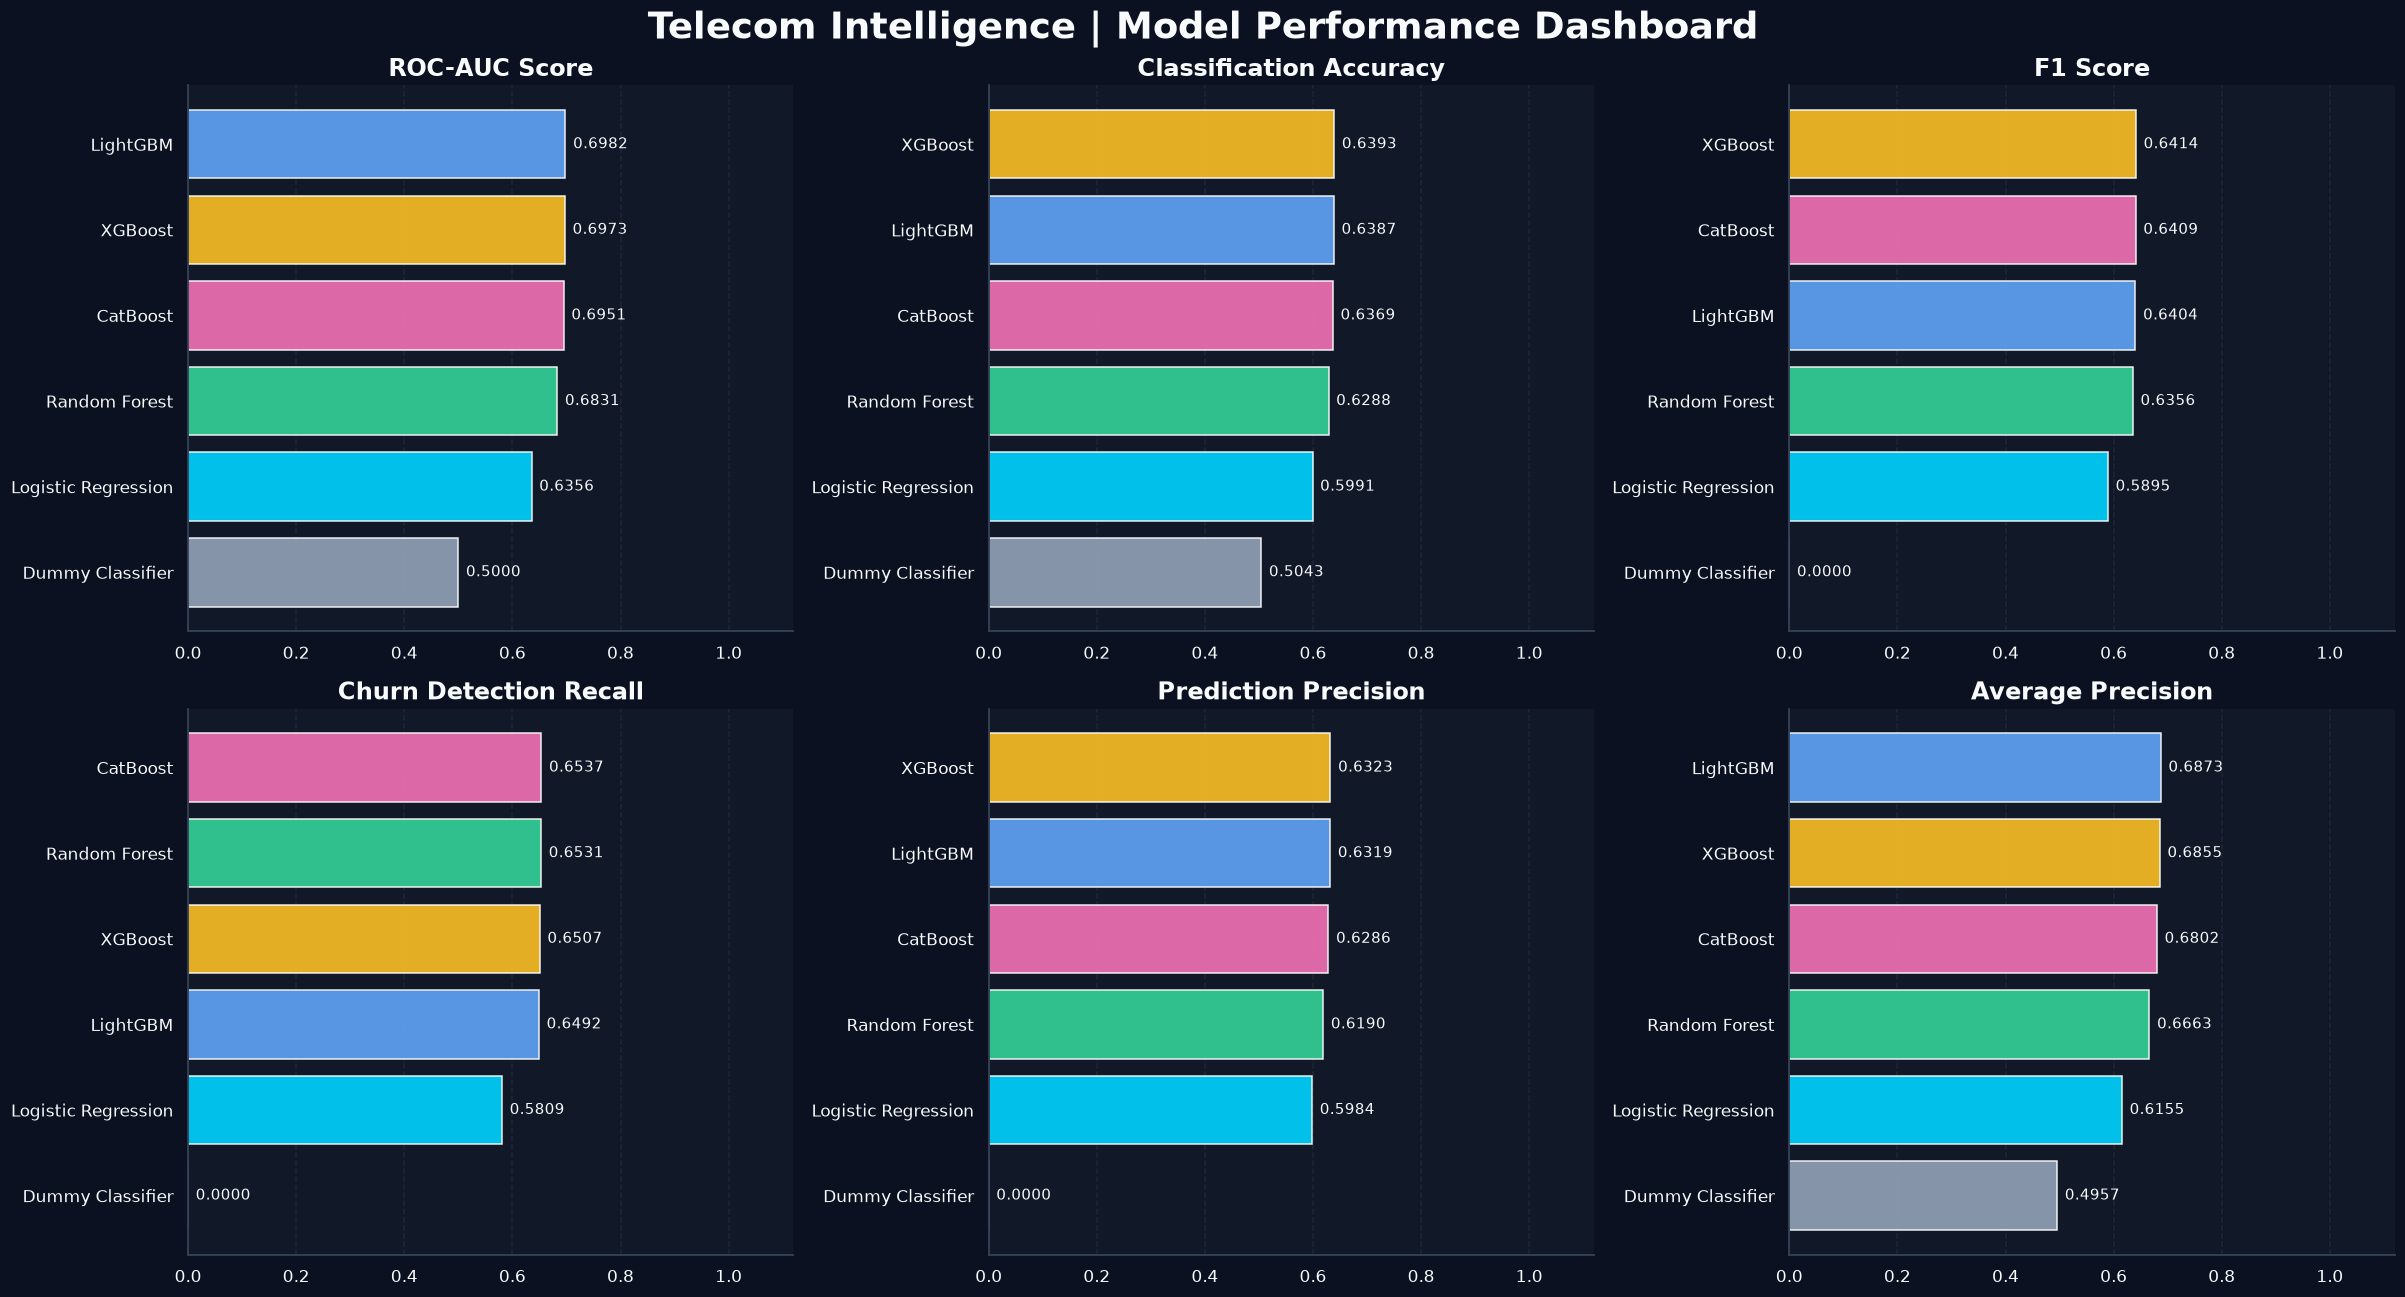

In [96]:
metric_settings = [
    ("ROC_AUC", "ROC-AUC Score"),
    ("Accuracy", "Classification Accuracy"),
    ("F1", "F1 Score"),
    ("Recall", "Churn Detection Recall"),
    ("Precision", "Prediction Precision"),
    ("Average_Precision", "Average Precision")
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(22, 12)
)

for ax, (metric, title) in zip(
    axes.flat,
    metric_settings
):

    plot_data = leaderboard.sort_values(
        metric,
        ascending=True
    )

    colors = [
        model_colors.get(name, PURPLE)
        for name in plot_data.index
    ]

    bars = ax.barh(
        plot_data.index,
        plot_data[metric],
        color=colors,
        alpha=0.9
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=5,
        color=TEXT_COLOR,
        fontsize=10
    )

    ax.set_xlim(0, 1.12)

    ax.set_title(title)

    ax.grid(
        axis="y",
        visible=False
    )

fig.suptitle(
    "Telecom Intelligence | Model Performance Dashboard",
    fontsize=24,
    fontweight="bold"
)

finish_plot(
    fig,
    "17_model_performance_dashboard.png"
)

# 15. Generalization and Overfitting Analysis

Training and validation ROC-AUC scores are compared
to identify potential overfitting.

Models are assessed according to their ability to
generalize to unseen customers rather than simply
memorizing training observations.

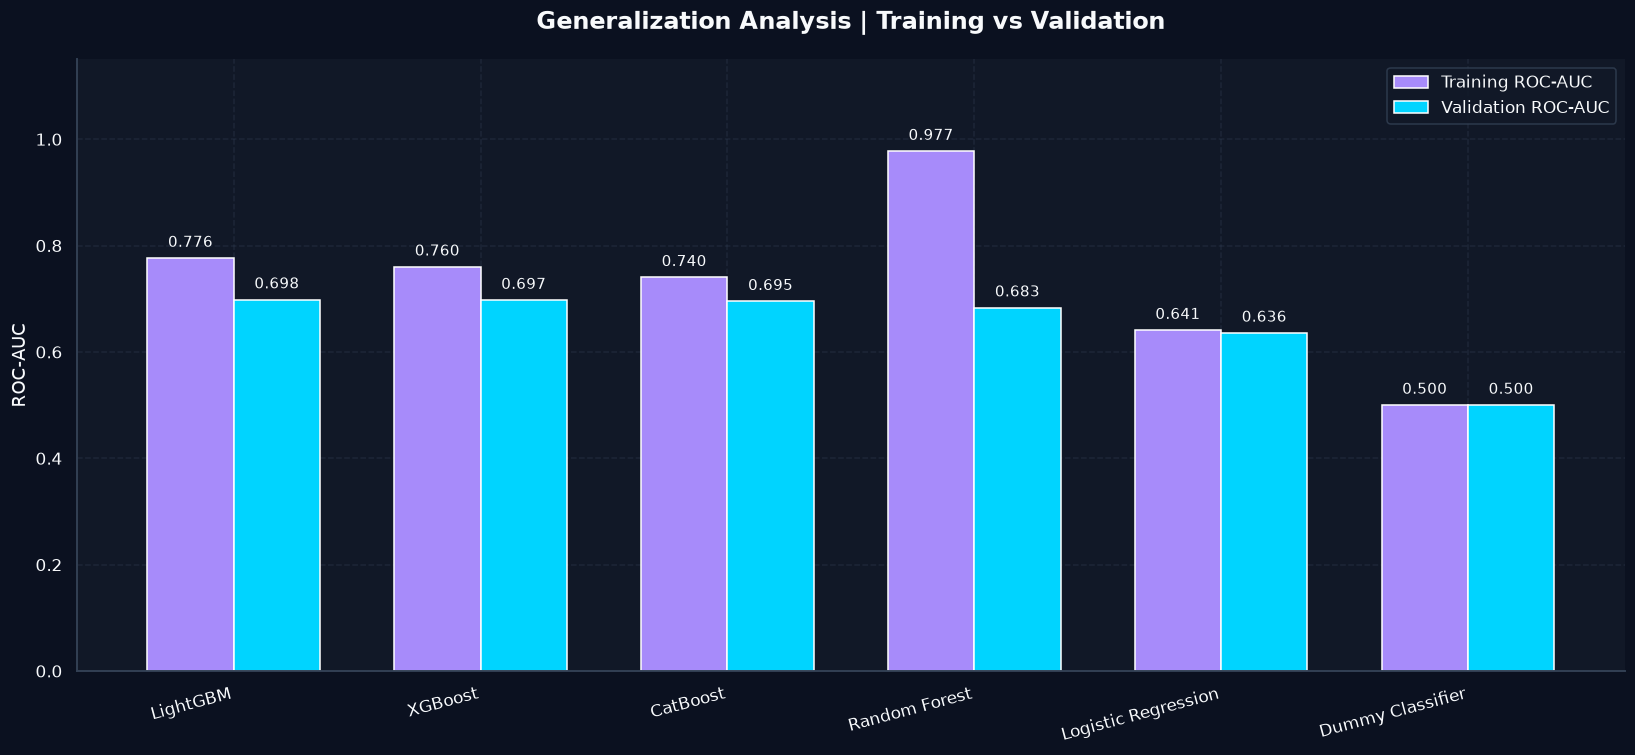

In [98]:
gap_data = leaderboard.sort_values(
    "ROC_AUC",
    ascending=False
)

positions = np.arange(len(gap_data))

bar_width = 0.35

fig, ax = plt.subplots(
    figsize=(15, 7)
)

train_bars = ax.bar(
    positions - bar_width / 2,

    gap_data["Train_ROC_AUC"],

    width=bar_width,

    color=PURPLE,

    label="Training ROC-AUC"
)

val_bars = ax.bar(
    positions + bar_width / 2,

    gap_data["ROC_AUC"],

    width=bar_width,

    color=CYAN,

    label="Validation ROC-AUC"
)

for bars in [train_bars, val_bars]:

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=5,
        fontsize=10
    )

ax.set_xticks(positions)

ax.set_xticklabels(
    gap_data.index,
    rotation=15,
    ha="right"
)

ax.set_ylim(0, 1.15)

ax.set_ylabel("ROC-AUC")

ax.set_title(
    "Generalization Analysis | Training vs Validation",
    pad=20
)

ax.legend()

finish_plot(
    fig,
    "19_model_generalization.png"
)

In [99]:
generalization_report = leaderboard[
    [
        "Train_ROC_AUC",
        "ROC_AUC",
        "AUC_Gap",
        "Training_Time_Seconds"
    ]
].copy()

generalization_report["Diagnostic"] = np.select(
    [
        generalization_report["AUC_Gap"] > 0.15,

        generalization_report["AUC_Gap"] > 0.08,

        generalization_report["AUC_Gap"] > 0.03
    ],

    [
        "Large Gap - Investigate",
        "Moderate Gap",
        "Small Gap"
    ],

    default="Minimal or Negative Gap"
)

display(generalization_report.round(4))

generalization_report.to_csv(
    REPORTS_DIR / "generalization_report.csv"
)

,Train_ROC_AUC,ROC_AUC,AUC_Gap,Training_Time_Seconds,Diagnostic
Model,,,,,
LightGBM,0.7764,0.6982,0.0782,5.7239,Small Gap
XGBoost,0.7600,0.6973,0.0627,7.5582,Small Gap
CatBoost,0.7402,0.6951,0.0451,53.2182,Small Gap
Random Forest,0.9775,0.6831,0.2943,19.1864,Large Gap - Investigate
Logistic Regression,0.6408,0.6356,0.0052,3.5155,Minimal or Negative Gap
Dummy Classifier,0.5000,0.5000,0.0000,1.4258,Minimal or Negative Gap


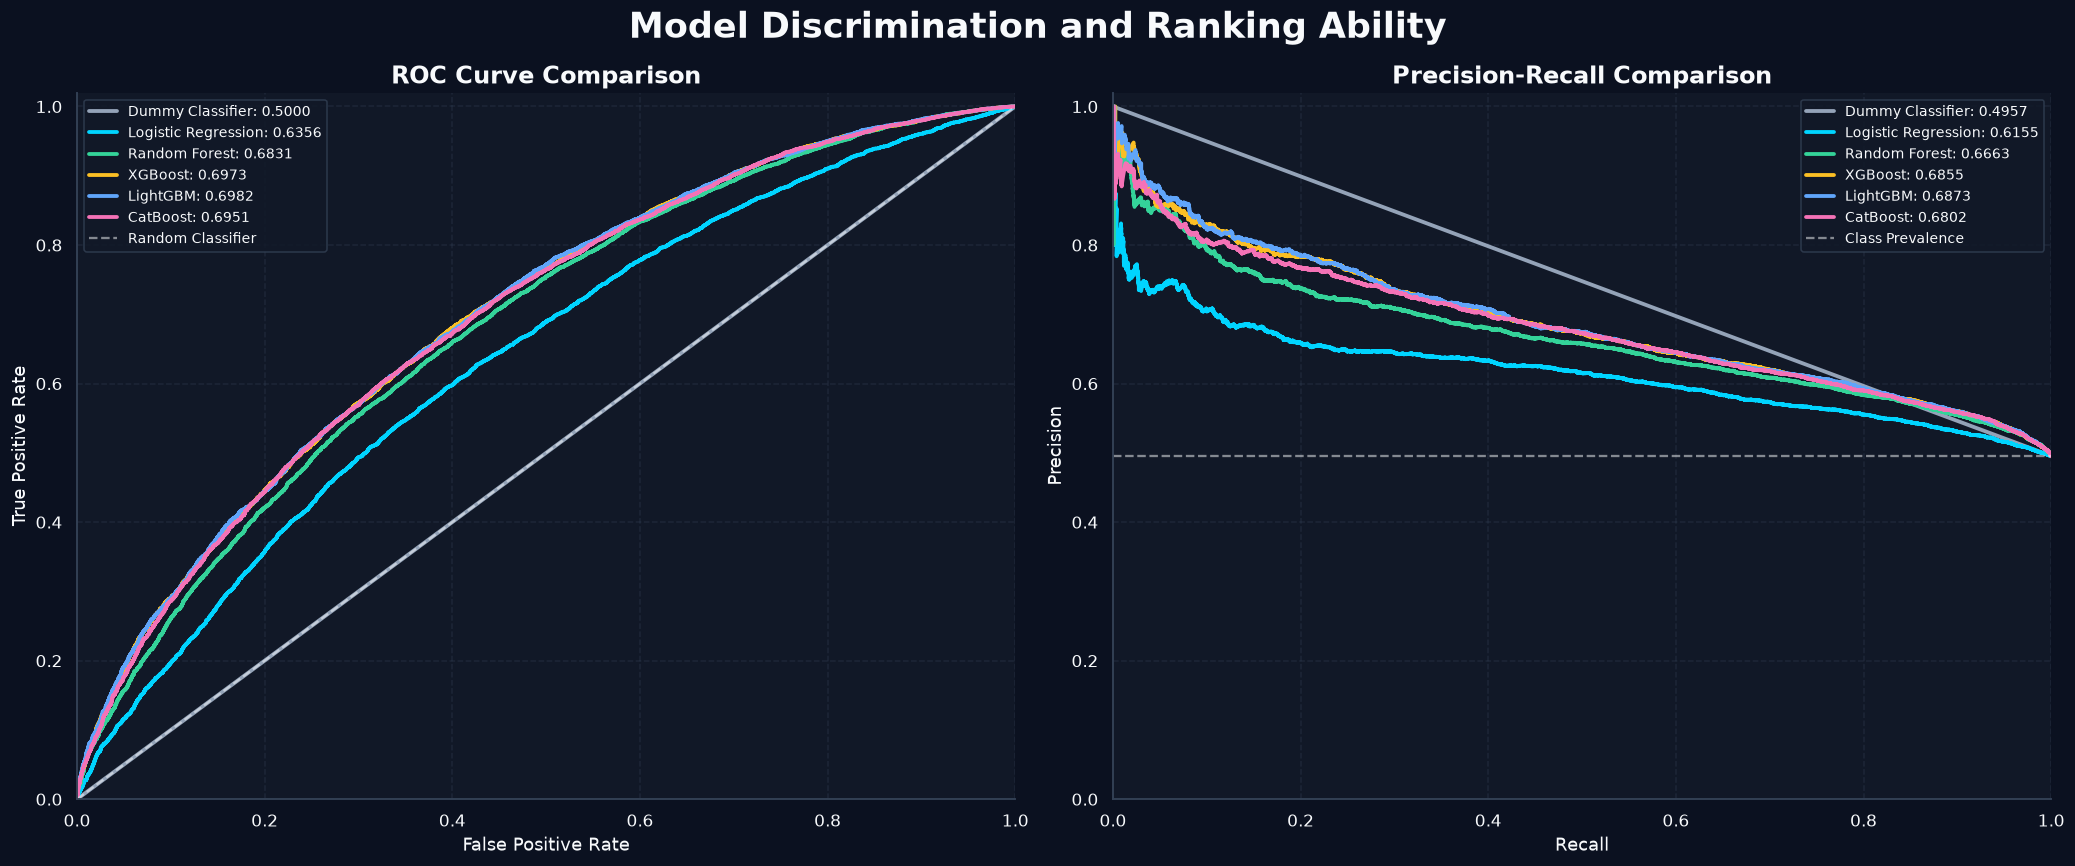

In [100]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 8)
)

for name, probabilities in validation_predictions.items():

    color = model_colors.get(name, PURPLE)

    # ROC Curve

    fpr, tpr, _ = roc_curve(
        y_val,
        probabilities
    )

    auc_value = roc_auc_score(
        y_val,
        probabilities
    )

    axes[0].plot(
        fpr,
        tpr,

        color=color,
        linewidth=2.5,

        label=f"{name}: {auc_value:.4f}"
    )

    # Precision-Recall Curve

    precision, recall, _ = precision_recall_curve(
        y_val,
        probabilities
    )

    ap_value = average_precision_score(
        y_val,
        probabilities
    )

    axes[1].plot(
        recall,
        precision,

        color=color,
        linewidth=2.5,

        label=f"{name}: {ap_value:.4f}"
    )

# Reference baselines

axes[0].plot(
    [0, 1],
    [0, 1],

    linestyle="--",
    color=TEXT_COLOR,
    alpha=0.5,

    label="Random Classifier"
)

axes[1].axhline(
    y_val.mean(),

    linestyle="--",
    color=TEXT_COLOR,
    alpha=0.5,

    label="Class Prevalence"
)

axes[0].set_title("ROC Curve Comparison")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

axes[1].set_title("Precision-Recall Comparison")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

for ax in axes:

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.legend(fontsize=9)

fig.suptitle(
    "Model Discrimination and Ranking Ability",
    fontsize=23,
    fontweight="bold"
)

finish_plot(
    fig,
    "20_roc_pr_curves.png"
)

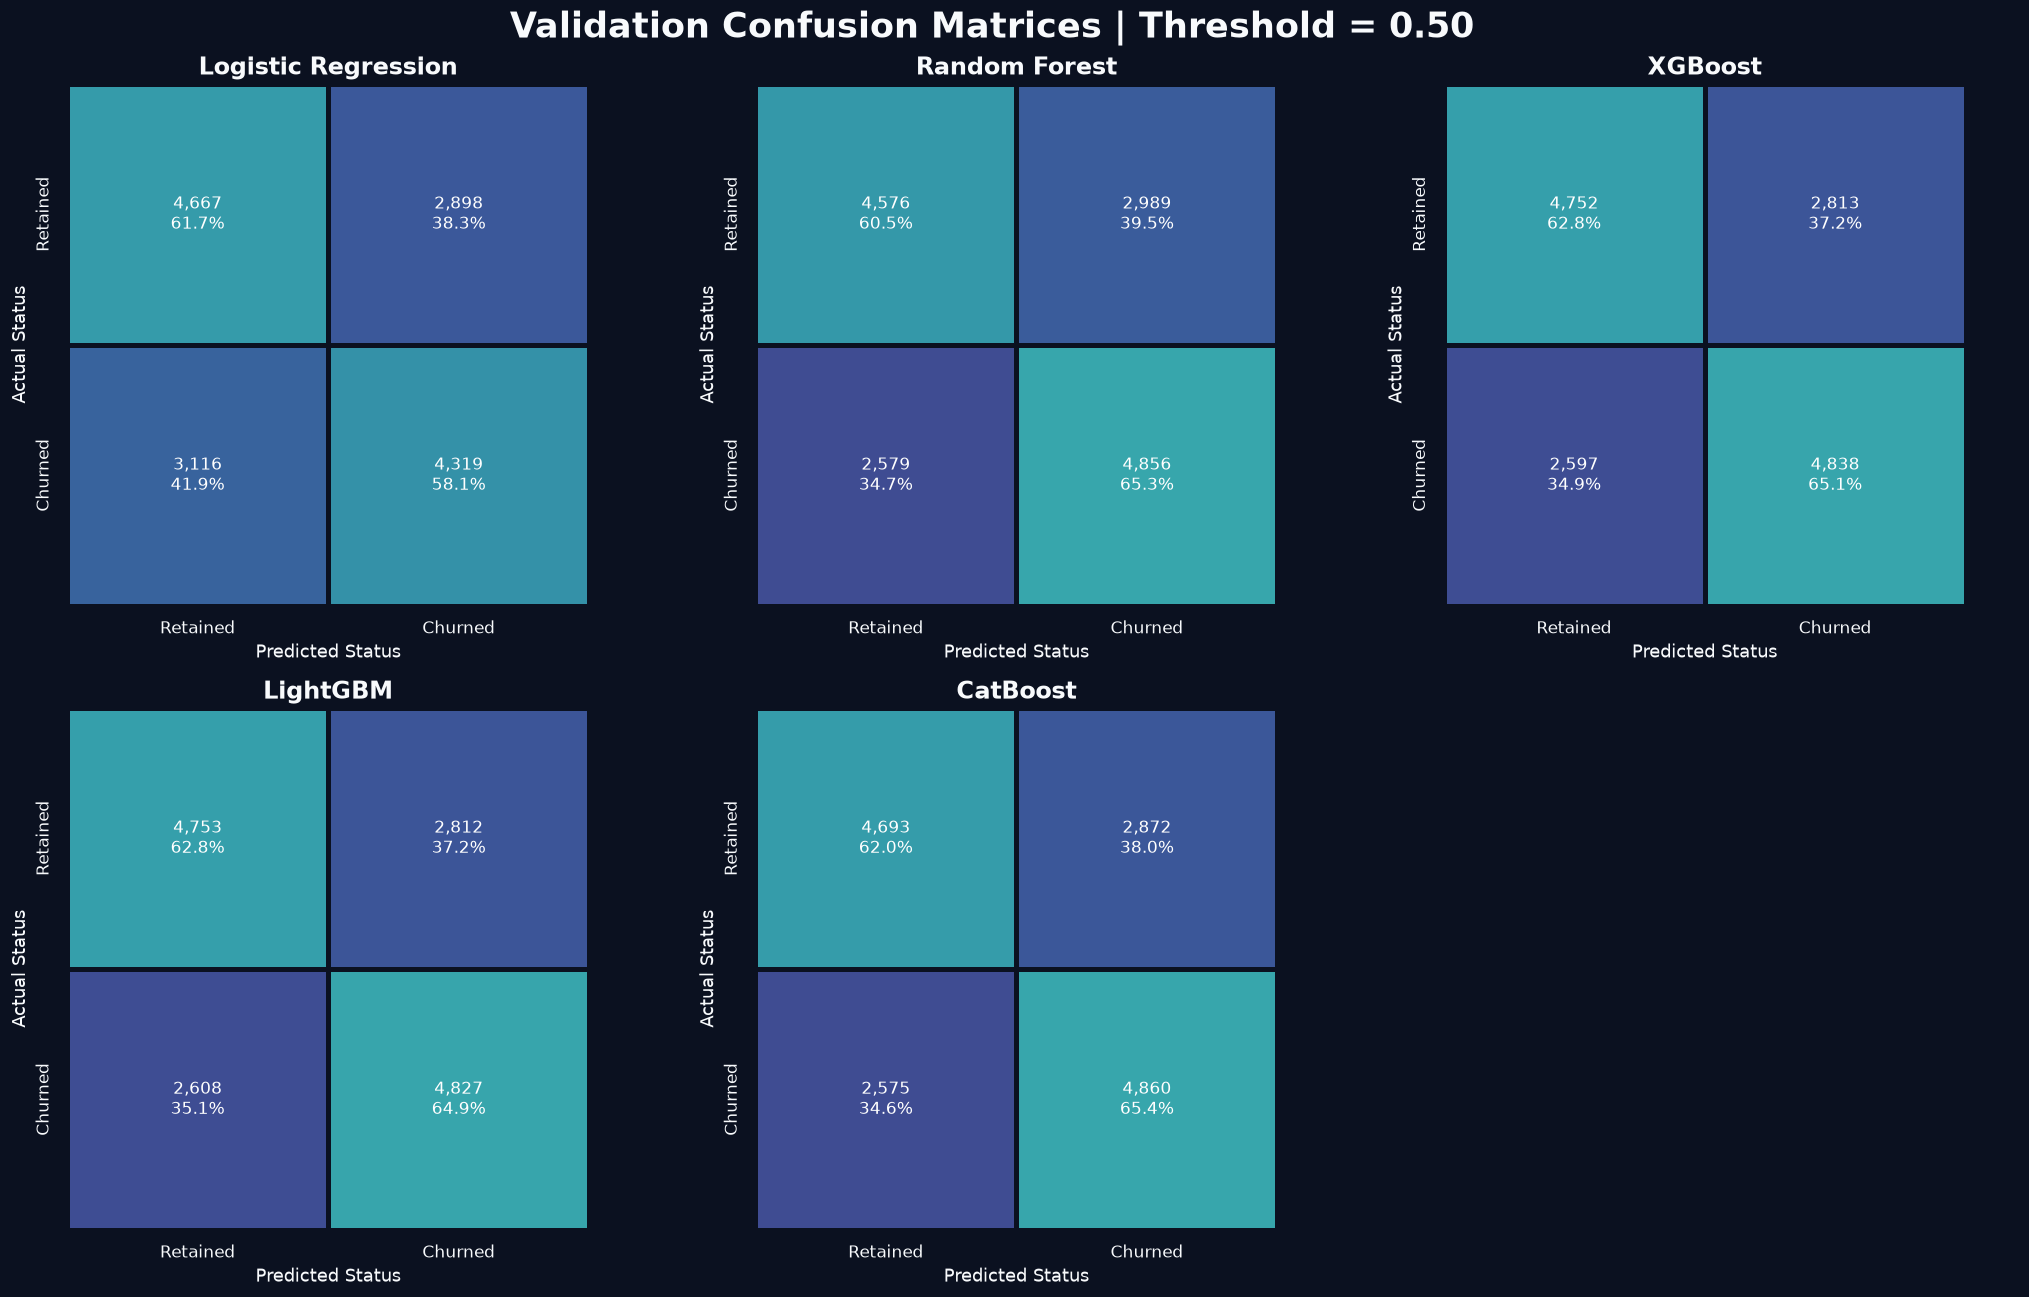

In [101]:
comparison_models = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 12)
)

for ax, name in zip(
    axes.flat,
    comparison_models
):

    probabilities = validation_predictions[name]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    )

    cm_normalized = (
        cm /
        cm.sum(
            axis=1,
            keepdims=True
        )
    )

    annotations = np.empty(
        cm.shape,
        dtype=object
    )

    for i in range(2):

        for j in range(2):

            annotations[i, j] = (
                f"{cm[i, j]:,}\n"
                f"{cm_normalized[i, j]:.1%}"
            )

    sns.heatmap(
        cm_normalized,

        annot=annotations,

        fmt="",

        cmap="mako",

        vmin=0,
        vmax=1,

        cbar=False,
        square=True,

        linewidths=2,
        linecolor=BG_COLOR,

        xticklabels=[
            "Retained",
            "Churned"
        ],

        yticklabels=[
            "Retained",
            "Churned"
        ],

        ax=ax
    )

    ax.set_title(name)

    ax.set_xlabel("Predicted Status")

    ax.set_ylabel("Actual Status")

axes.flat[-1].axis("off")

fig.suptitle(
    "Validation Confusion Matrices | Threshold = 0.50",
    fontsize=23,
    fontweight="bold"
)

finish_plot(
    fig,
    "21_confusion_matrices.png"
)

In [102]:
error_analysis = []

for name, probabilities in validation_predictions.items():

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    error_analysis.append({
        "Model": name,

        "True_Negatives": tn,

        "False_Positives": fp,

        "False_Negatives": fn,

        "True_Positives": tp,

        "Total_Errors": fp + fn,

        "False_Positive_Rate": (
            fp / (fp + tn)
        ),

        "False_Negative_Rate": (
            fn / (fn + tp)
        )
    })

error_report = (
    pd.DataFrame(error_analysis)
    .set_index("Model")
    .sort_values("Total_Errors")
)

display(error_report.round(4))

error_report.to_csv(
    REPORTS_DIR / "model_error_analysis.csv"
)

,True_Negatives,False_Positives,False_Negatives,True_Positives,Total_Errors,False_Positive_Rate,False_Negative_Rate
Model,,,,,,,
XGBoost,4752,2813,2597,4838,5410,0.3718,0.3493
LightGBM,4753,2812,2608,4827,5420,0.3717,0.3508
CatBoost,4693,2872,2575,4860,5447,0.3796,0.3463
Random Forest,4576,2989,2579,4856,5568,0.3951,0.3469
Logistic Regression,4667,2898,3116,4319,6014,0.3831,0.4191
Dummy Classifier,7565,0,7435,0,7435,0.0000,1.0000


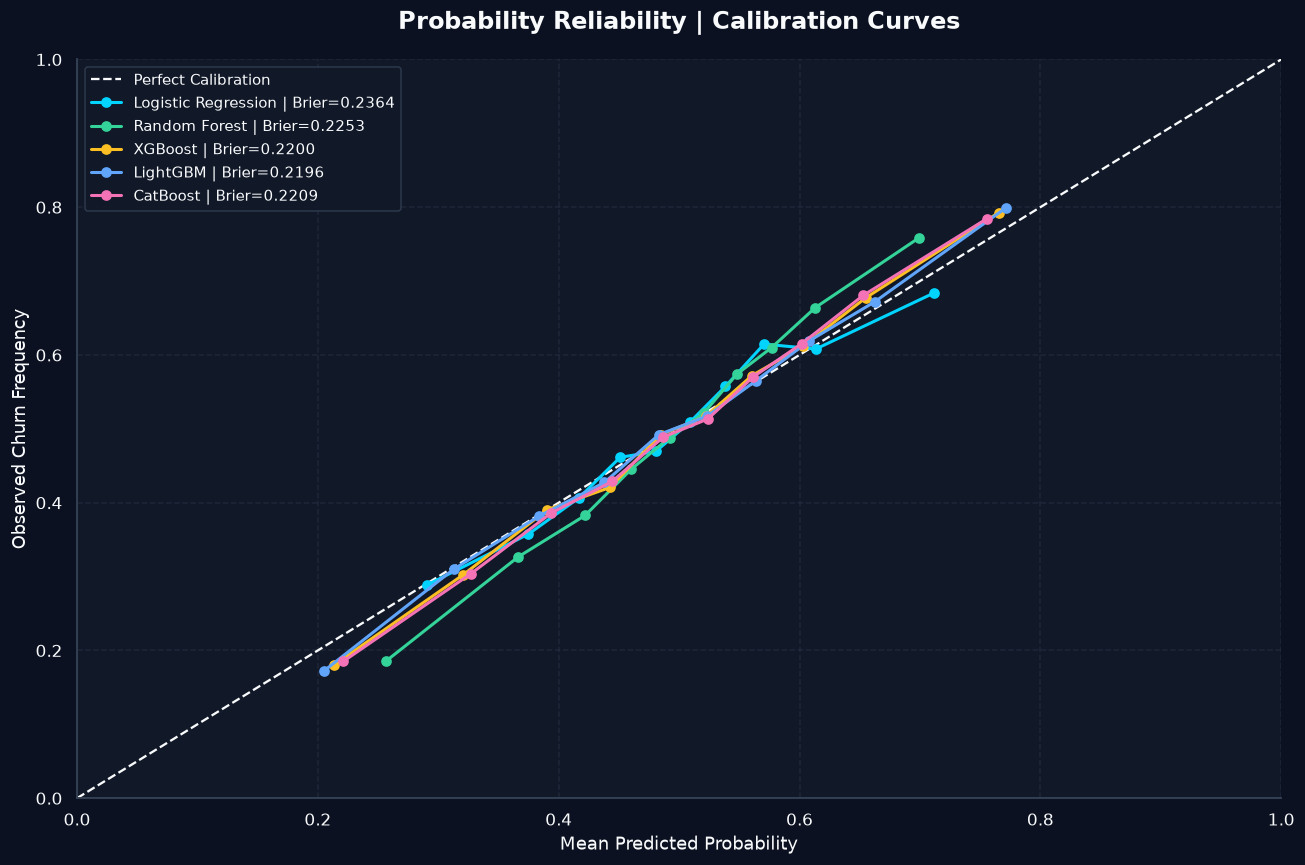

In [104]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(
    figsize=(12, 8)
)

ax.plot(
    [0, 1],
    [0, 1],

    linestyle="--",
    color=TEXT_COLOR,

    label="Perfect Calibration"
)

for name in comparison_models:

    probabilities = validation_predictions[name]

    observed_rate, predicted_rate = calibration_curve(
        y_val,
        probabilities,

        n_bins=10,
        strategy="quantile"
    )

    brier = brier_score_loss(
        y_val,
        probabilities
    )

    ax.plot(
        predicted_rate,
        observed_rate,

        marker="o",
        linewidth=2,

        color=model_colors.get(name, PURPLE),

        label=f"{name} | Brier={brier:.4f}"
    )

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_title(
    "Probability Reliability | Calibration Curves",
    pad=20
)

ax.set_xlabel("Mean Predicted Probability")

ax.set_ylabel("Observed Churn Frequency")

ax.legend(fontsize=10)

finish_plot(
    fig,
    "23_probability_calibration.png"
)

In [105]:
probability_report = leaderboard[
    [
        "ROC_AUC",
        "Average_Precision",
        "Brier_Score",
        "Log_Loss"
    ]
].copy()

dummy_brier = probability_report.loc[
    "Dummy Classifier",
    "Brier_Score"
]

probability_report["Brier_Skill_Score"] = (
    1 -
    probability_report["Brier_Score"] /
    dummy_brier
)

probability_report = (
    probability_report
    .sort_values(
        "Brier_Score",
        ascending=True
    )
)

display(probability_report.round(5))

probability_report.to_csv(
    REPORTS_DIR / "probability_quality_report.csv"
)

,ROC_AUC,Average_Precision,Brier_Score,Log_Loss,Brier_Skill_Score
Model,,,,,
LightGBM,0.6982,0.6873,0.2196,0.6282,0.1217
XGBoost,0.6973,0.6855,0.2200,0.6294,0.1198
CatBoost,0.6951,0.6802,0.2209,0.6315,0.1162
Random Forest,0.6831,0.6663,0.2253,0.6412,0.0988
Logistic Regression,0.6356,0.6155,0.2364,0.6656,0.0545
Dummy Classifier,0.5000,0.4957,0.2500,0.6931,0.0000


# 16. Cross-Validation and Model Stability

Stratified K-Fold Cross-Validation is performed
on the training dataset to evaluate model stability.

Preprocessing is fitted independently within each
training fold to prevent information leakage.

The strongest advanced models and the logistic
regression baseline are compared using identical
cross-validation partitions.

The independent test set remains unused.

In [106]:
advanced_model_names = [
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

top_advanced_models = (
    leaderboard
    .loc[advanced_model_names]
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .head(3)
    .index
    .tolist()
)

cv_candidates = (
    ["Logistic Regression"] +
    top_advanced_models
)

print("Selected models for Cross-Validation:\n")

for i, name in enumerate(
    cv_candidates,
    start=1
):

    print(f"{i}. {name}")

Selected models for Cross-Validation:

1. Logistic Regression
2. LightGBM
3. XGBoost
4. CatBoost


In [107]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

CV_FOLDS = 5

CV = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED
)

cv_scoring = {
    "roc_auc": "roc_auc",

    "average_precision": "average_precision",

    "accuracy": "accuracy",

    "balanced_accuracy": "balanced_accuracy",

    "f1": "f1",

    "precision": "precision",

    "recall": "recall",

    "mcc": "matthews_corrcoef",

    "neg_log_loss": "neg_log_loss",

    "neg_brier_score": "neg_brier_score"
}

print("Cross-Validation configuration ready.")

print("Folds:", CV_FOLDS)

print("Models:", len(cv_candidates))

print(
    "Total training experiments:",
    CV_FOLDS * len(cv_candidates)
)

Cross-Validation configuration ready.
Folds: 5
Models: 4
Total training experiments: 20


In [108]:
from sklearn.base import is_classifier

for name in cv_candidates:

    estimator = clone(
        model_templates[name]
    )

    print(
        f"{name}:",
        "Clone successful"
    )

    assert is_classifier(estimator), (
        f"{name} is not recognized as a classifier."
    )

print(
    "\nAll cross-validation compatibility checks passed."
)

Logistic Regression: Clone successful
LightGBM: Clone successful
XGBoost: Clone successful
CatBoost: Clone successful

All cross-validation compatibility checks passed.


In [109]:
cv_results = []

cv_fold_results = []

for name in cv_candidates:

    print("\n" + "=" * 65)
    print(f"CROSS-VALIDATING: {name}")
    print("=" * 65)

    estimator = clone(
        model_templates[name]
    )

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator,

        X_train,
        y_train,

        cv=CV,

        scoring=cv_scoring,

        n_jobs=1,

        return_train_score=True,

        error_score="raise"
    )

    elapsed = (
        time.perf_counter() -
        start_time
    )

    result = {
        "Model": name,

        "CV_ROC_AUC_Mean":
            scores["test_roc_auc"].mean(),

        "CV_ROC_AUC_Std":
            scores["test_roc_auc"].std(ddof=1),

        "CV_Train_AUC":
            scores["train_roc_auc"].mean(),

        "CV_F1_Mean":
            scores["test_f1"].mean(),

        "CV_Accuracy_Mean":
            scores["test_accuracy"].mean(),

        "CV_Balanced_Accuracy":
            scores["test_balanced_accuracy"].mean(),

        "CV_Precision_Mean":
            scores["test_precision"].mean(),

        "CV_Recall_Mean":
            scores["test_recall"].mean(),

        "CV_MCC_Mean":
            scores["test_mcc"].mean(),

        "CV_AP_Mean":
            scores["test_average_precision"].mean(),

        "CV_Log_Loss":
            -scores["test_neg_log_loss"].mean(),

        "CV_Brier_Score":
            -scores["test_neg_brier_score"].mean(),

        "Mean_Fit_Time":
            scores["fit_time"].mean(),

        "Total_CV_Time":
            elapsed
    }

    cv_results.append(result)

    for fold in range(CV_FOLDS):

        cv_fold_results.append({
            "Model": name,

            "Fold": fold + 1,

            "ROC_AUC":
                scores["test_roc_auc"][fold],

            "Train_ROC_AUC":
                scores["train_roc_auc"][fold],

            "F1":
                scores["test_f1"][fold],

            "Average_Precision":
                scores["test_average_precision"][fold]
        })

    print(
        "Mean ROC-AUC:",
        f"{result['CV_ROC_AUC_Mean']:.4f}"
    )

    print(
        "AUC Standard Deviation:",
        f"{result['CV_ROC_AUC_Std']:.4f}"
    )

    print(
        "Mean F1:",
        f"{result['CV_F1_Mean']:.4f}"
    )

    print(
        "CV Time:",
        f"{elapsed:.2f} seconds"
    )

    # Save intermediate results

    pd.DataFrame(cv_results).to_csv(
        REPORTS_DIR / "cv_intermediate_results.csv",
        index=False
    )

    gc.collect()


CROSS-VALIDATING: Logistic Regression
Mean ROC-AUC: 0.6369
AUC Standard Deviation: 0.0042
Mean F1: 0.5883
CV Time: 20.72 seconds

CROSS-VALIDATING: LightGBM
Mean ROC-AUC: 0.6948
AUC Standard Deviation: 0.0024
Mean F1: 0.6412
CV Time: 36.06 seconds

CROSS-VALIDATING: XGBoost
Mean ROC-AUC: 0.6925
AUC Standard Deviation: 0.0022
Mean F1: 0.6399
CV Time: 37.09 seconds

CROSS-VALIDATING: CatBoost
Mean ROC-AUC: 0.6909
AUC Standard Deviation: 0.0021
Mean F1: 0.6384
CV Time: 234.68 seconds


In [110]:
cv_leaderboard = (
    pd.DataFrame(cv_results)
    .set_index("Model")
    .sort_values(
        "CV_ROC_AUC_Mean",
        ascending=False
    )
)

cv_leaderboard["CV_AUC_Gap"] = (
    cv_leaderboard["CV_Train_AUC"] -
    cv_leaderboard["CV_ROC_AUC_Mean"]
)

fold_results = pd.DataFrame(
    cv_fold_results
)

display(cv_leaderboard.round(5))

cv_leaderboard.to_csv(
    REPORTS_DIR /
    "cross_validation_leaderboard.csv"
)

fold_results.to_csv(
    REPORTS_DIR /
    "cross_validation_fold_results.csv",

    index=False
)

,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_Train_AUC,CV_F1_Mean,CV_Accuracy_Mean,CV_Balanced_Accuracy,CV_Precision_Mean,CV_Recall_Mean,CV_MCC_Mean,CV_AP_Mean,CV_Log_Loss,CV_Brier_Score,Mean_Fit_Time,Total_CV_Time,CV_AUC_Gap
Model,,,,,,,,,,,,,,,
LightGBM,0.6948,0.0024,0.7914,0.6412,0.6397,0.6398,0.6331,0.6496,0.2797,0.6805,0.6311,0.2208,4.4637,36.0551,0.0966
XGBoost,0.6925,0.0022,0.7725,0.6399,0.6377,0.6378,0.6306,0.6494,0.2756,0.6778,0.6325,0.2214,6.4093,37.0857,0.0800
CatBoost,0.6909,0.0021,0.7505,0.6384,0.6357,0.6358,0.6282,0.6490,0.2717,0.6745,0.6344,0.2222,46.0066,234.6790,0.0596
Logistic Regression,0.6370,0.0042,0.6412,0.5883,0.5972,0.5971,0.5962,0.5807,0.1943,0.6182,0.6651,0.2360,2.9239,20.7247,0.0042


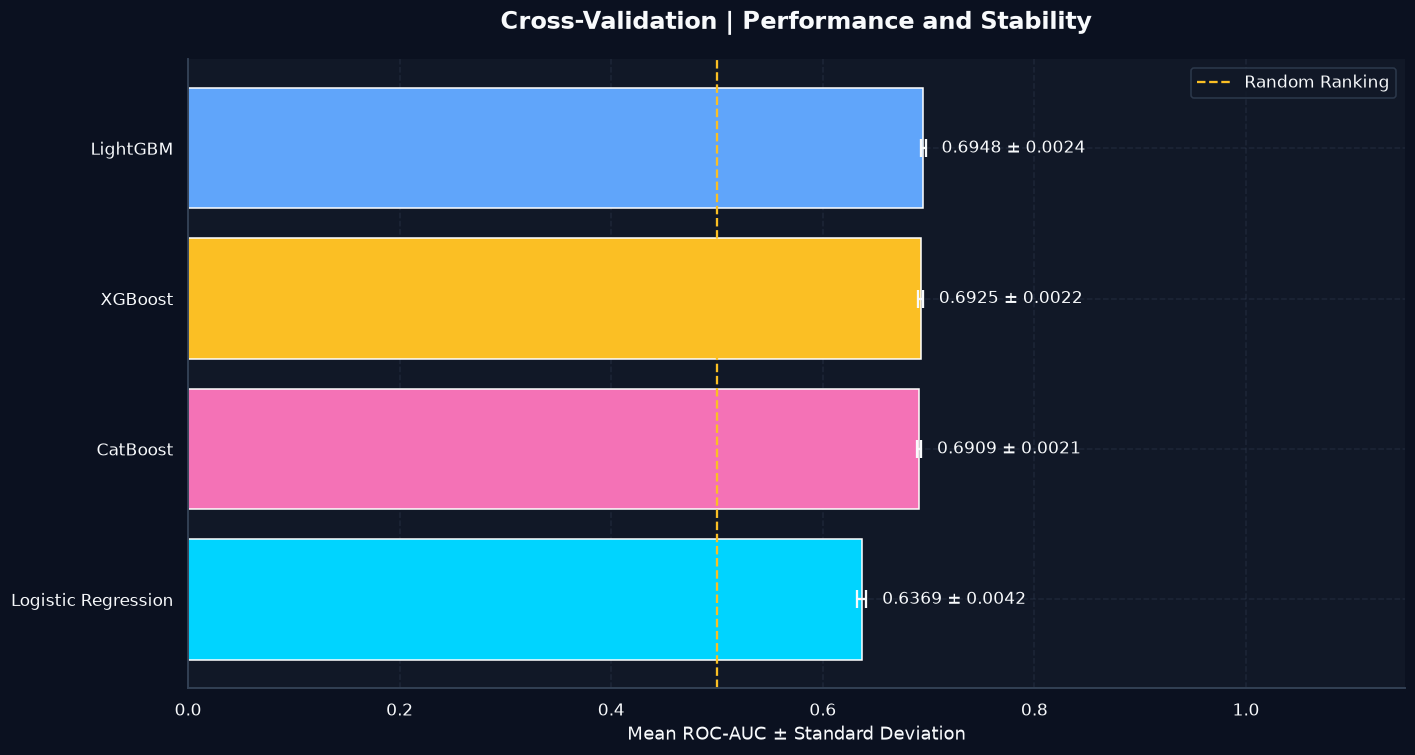

In [111]:
cv_plot = cv_leaderboard.sort_values(
    "CV_ROC_AUC_Mean"
)

fig, ax = plt.subplots(
    figsize=(13, 7)
)

colors = [
    model_colors.get(name, PURPLE)
    for name in cv_plot.index
]

ax.barh(
    cv_plot.index,

    cv_plot["CV_ROC_AUC_Mean"],

    xerr=cv_plot["CV_ROC_AUC_Std"],

    color=colors,

    capsize=6,

    error_kw={
        "ecolor": TEXT_COLOR,
        "elinewidth": 1.5,
        "capthick": 1.5
    }
)

for i, (name, row) in enumerate(
    cv_plot.iterrows()
):

    ax.text(
        row["CV_ROC_AUC_Mean"] +
        row["CV_ROC_AUC_Std"] +
        0.015,

        i,

        f"{row['CV_ROC_AUC_Mean']:.4f} "
        f"± {row['CV_ROC_AUC_Std']:.4f}",

        va="center",

        color=TEXT_COLOR
    )

ax.axvline(
    0.5,
    linestyle="--",
    color=GOLD,
    label="Random Ranking"
)

ax.set_xlim(0, 1.15)

ax.set_title(
    "Cross-Validation | Performance and Stability",
    pad=20
)

ax.set_xlabel(
    "Mean ROC-AUC ± Standard Deviation"
)

ax.legend()

finish_plot(
    fig,
    "24_cross_validation_stability.png"
)

In [113]:
model_selection_report = (
    leaderboard[
        [
            "ROC_AUC",
            "Average_Precision",
            "F1",
            "Brier_Score",
            "Log_Loss",
            "AUC_Gap",
            "Training_Time_Seconds"
        ]
    ]

    .join(
        cv_leaderboard[
            [
                "CV_ROC_AUC_Mean",
                "CV_ROC_AUC_Std",
                "CV_AUC_Gap"
            ]
        ],

        how="inner"
    )

    .sort_values(
        "CV_ROC_AUC_Mean",
        ascending=False
    )
)

model_selection_report[
    "Validation_CV_Difference"
] = (
    model_selection_report["ROC_AUC"] -
    model_selection_report["CV_ROC_AUC_Mean"]
).abs()

display(
    model_selection_report.round(5)
)

model_selection_report.to_csv(
    REPORTS_DIR /
    "model_selection_report.csv"
)

optimization_candidates = (
    model_selection_report

    .drop(
        index="Logistic Regression",
        errors="ignore"
    )

    .head(2)

    .index

    .tolist()
)

print("\nSelected optimization candidates:")

for i, name in enumerate(
    optimization_candidates,
    start=1
):

    print(f"{i}. {name}")

,ROC_AUC,Average_Precision,F1,Brier_Score,Log_Loss,AUC_Gap,Training_Time_Seconds,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_AUC_Gap,Validation_CV_Difference
Model,,,,,,,,,,,
LightGBM,0.6982,0.6873,0.6404,0.2196,0.6282,0.0782,5.7239,0.6948,0.0024,0.0966,0.0034
XGBoost,0.6973,0.6855,0.6414,0.2200,0.6294,0.0627,7.5582,0.6925,0.0022,0.0800,0.0048
CatBoost,0.6951,0.6802,0.6409,0.2209,0.6315,0.0451,53.2182,0.6909,0.0021,0.0596,0.0042
Logistic Regression,0.6356,0.6155,0.5895,0.2364,0.6656,0.0052,3.5155,0.6370,0.0042,0.0042,0.0014



Selected optimization candidates:
1. LightGBM
2. XGBoost


In [114]:
best_validation_model = leaderboard.index[0]

best_cv_model = cv_leaderboard.index[0]

best_probability_model = (
    probability_report.index[0]
)

best_recall_model = (
    leaderboard["Recall"].idxmax()
)

summary = pd.DataFrame([
    {
        "Category": "Best Validation ROC-AUC",

        "Model": best_validation_model,

        "Score": leaderboard.loc[
            best_validation_model,
            "ROC_AUC"
        ]
    },
    {
        "Category": "Best Cross-Validation ROC-AUC",

        "Model": best_cv_model,

        "Score": cv_leaderboard.loc[
            best_cv_model,
            "CV_ROC_AUC_Mean"
        ]
    },
    {
        "Category": "Lowest Brier Score",

        "Model": best_probability_model,

        "Score": probability_report.loc[
            best_probability_model,
            "Brier_Score"
        ]
    },
    {
        "Category": "Highest Recall",

        "Model": best_recall_model,

        "Score": leaderboard.loc[
            best_recall_model,
            "Recall"
        ]
    }
])

display(summary.round(5))

summary.to_csv(
    REPORTS_DIR /
    "initial_experiment_summary.csv",

    index=False
)

print("\nInitial model experimentation completed.")

,Category,Model,Score
0,Best Validation ROC-AUC,LightGBM,0.6982
1,Best Cross-Validation ROC-AUC,LightGBM,0.6948
2,Lowest Brier Score,LightGBM,0.2196
3,Highest Recall,CatBoost,0.6537



Initial model experimentation completed.


**Initial benchmark.** LightGBM achieved a recorded validation ROC-AUC of 0.6982 and five-fold mean ROC-AUC of 0.6948. Random Forest showed a much larger training–validation gap. These results support focusing optimization on gradient boosting while retaining simpler baselines for comparison.

# 17. Feature Ablation and Selection

Feature ablation experiments are conducted to quantify
the contribution of original and engineered features.

The objective is to identify a feature representation
that balances predictive performance, generalization,
interpretability and computational efficiency.

Four feature configurations are investigated:

1. Original features.
2. Original and engineered features.
3. Reduced redundancy features.
4. Behavioral and service-related features.

All comparisons use identical stratified cross-validation
partitions and consistent model hyperparameters.

The independent test dataset remains unused.

In [115]:
# ==========================================================
# FEATURE ABLATION — EXPERIMENT DATASETS
# ==========================================================

original_train = clean_domain_values(
    X_train_raw
)

original_val = clean_domain_values(
    X_val_raw
)

original_features = (
    original_train.columns.tolist()
)

all_features = X_train.columns.tolist()

engineered_features = [

    col for col in all_features

    if col not in original_features

]

print("=" * 65)
print("FEATURE EXPERIMENT CONFIGURATION")
print("=" * 65)

print(
    "Original Features:",
    len(original_features)
)

print(
    "Engineered Features:",
    len(engineered_features)
)

print(
    "Total Features:",
    len(all_features)
)

display(
    pd.DataFrame({
        "Engineered_Features": engineered_features
    })
)

FEATURE EXPERIMENT CONFIGURATION
Original Features: 83
Engineered Features: 17
Total Features: 100


,Engineered_Features
0,call_failure_ratio
1,call_completion_ratio
2,customer_care_intensity
3,usage_trend_ratio
4,call_volume_trend
5,usage_change_gap
6,incoming_outgoing_ratio
7,revenue_trend_ratio
8,revenue_change_gap
9,overage_revenue_ratio


In [116]:
# ==========================================================
# HIGHLY CORRELATED FEATURE ANALYSIS
# ==========================================================

REDUNDANCY_THRESHOLD = 0.98

redundancy_numeric = (
    X_train
    .select_dtypes(include="number")
    .columns
    .tolist()
)

redundancy_corr = (

    X_train[redundancy_numeric]

    .corr(method="spearman")

    .abs()

)

upper_corr = redundancy_corr.where(

    np.triu(

        np.ones(
            redundancy_corr.shape,
            dtype=bool
        ),

        k=1

    )

)

high_corr_pairs = (

    upper_corr

    .stack()

    .reset_index()

)

high_corr_pairs.columns = [

    "Feature_1",

    "Feature_2",

    "Absolute_Correlation"

]

high_corr_pairs = (

    high_corr_pairs[
        high_corr_pairs[
            "Absolute_Correlation"
        ] >= REDUNDANCY_THRESHOLD
    ]

    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )

)

display(
    high_corr_pairs.round(5)
)

print(
    "Highly redundant feature pairs:",
    len(high_corr_pairs)
)

,Feature_1,Feature_2,Absolute_Correlation
4799,totcalls,adjqty,0.9995
4891,totmou,adjmou,0.9994
1625,plcd_vce_Mean,attempt_Mean,0.9993
3386,peak_dat_Mean,mou_pead_Mean,0.9992
1998,comp_vce_Mean,complete_Mean,0.9991
2075,comp_dat_Mean,mou_cdat_Mean,0.9989
3762,opk_dat_Mean,mou_opkd_Mean,0.9987
2257,ccrndmou_Mean,cc_mou_Mean,0.9981
377,ovrmou_Mean,ovrrev_Mean,0.9978
8461,household_active_ratio,inactive_household_subscribers,0.9976


Highly redundant feature pairs: 21


In [117]:
from sklearn.base import BaseEstimator, TransformerMixin


class RedundancySelector(
    BaseEstimator,
    TransformerMixin
):

    def __init__(self, threshold=0.98):

        self.threshold = threshold


    def fit(self, X, y=None):

        numeric_columns = (
            X.select_dtypes(include="number")
            .columns
            .tolist()
        )

        corr_matrix = (

            X[numeric_columns]

            .corr(method="spearman")

            .abs()

        )

        missing_rates = X.isna().mean()

        # Prefer features with fewer missing values
        ordered_columns = sorted(
            numeric_columns,
            key=lambda col: missing_rates[col]
        )

        retained = []
        dropped = []

        for feature in ordered_columns:

            redundant = any(

                corr_matrix.loc[
                    feature, previous
                ] >= self.threshold

                for previous in retained

            )

            if redundant:

                dropped.append(feature)

            else:

                retained.append(feature)


        self.dropped_features_ = dropped

        self.selected_features_ = [

            col for col in X.columns

            if col not in dropped

        ]

        return self


    def transform(self, X):

        return X.loc[
            :, self.selected_features_
        ].copy()


    def get_feature_names_out(
        self,
        input_features=None
    ):

        return np.asarray(
            self.selected_features_,
            dtype=object
        )


print("Fold-safe redundancy selector initialized.")

Fold-safe redundancy selector initialized.


In [118]:
# ==========================================================
# BEHAVIORAL AND SERVICE-FOCUSED FEATURE SET
# ==========================================================

non_behavioral_features = [

    "area",

    "asl_flag",

    "adults",

    "infobase",

    "lor",

    "numbcars",

    "forgntvl",

    "truck",

    "rv"

]

behavioral_features = [

    col for col in all_features

    if col not in non_behavioral_features

]

feature_experiment_summary = pd.DataFrame([

    {
        "Experiment": "Original",
        "Features": len(original_features)
    },

    {
        "Experiment": "Full",
        "Features": len(all_features)
    },

    {
        "Experiment": "Reduced Redundancy",
        "Features": "Determined during fit"
    },

    {
        "Experiment": "Behavioral Focus",
        "Features": len(behavioral_features)
    }

])

display(feature_experiment_summary)

,Experiment,Features
0,Original,83
1,Full,100
2,Reduced Redundancy,Determined during fit
3,Behavioral Focus,91


In [119]:
from sklearn.compose import make_column_selector


def build_dynamic_preprocessor(
    scale_numeric=False
):

    numeric_steps = [

        (
            "imputer",

            SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )
        )

    ]

    if scale_numeric:

        numeric_steps.append(

            (
                "scaler",
                StandardScaler()
            )

        )


    numeric_pipeline = Pipeline(
        numeric_steps
    )


    categorical_pipeline = Pipeline([

        (
            "imputer",

            SimpleImputer(
                strategy="constant",
                fill_value="__MISSING__"
            )
        ),

        (
            "encoder",

            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
                sparse_output=True
            )
        )

    ])


    return ColumnTransformer(

        transformers=[

            (
                "numeric",

                numeric_pipeline,

                make_column_selector(
                    dtype_include=np.number
                )
            ),

            (
                "categorical",

                categorical_pipeline,

                make_column_selector(
                    dtype_exclude=np.number
                )
            )

        ],

        remainder="drop",

        sparse_threshold=0.3

    )


print("Dynamic preprocessing pipeline initialized.")

Dynamic preprocessing pipeline initialized.


In [120]:
# ==========================================================
# ABLATION EXPERIMENT CONFIGURATION
# ==========================================================

lgbm_base_parameters = (

    model_templates["LightGBM"]

    .named_steps["model"]

    .get_params()

)


def create_ablation_pipeline(
    use_redundancy_selector=False
):

    steps = []

    if use_redundancy_selector:

        steps.append(

            (
                "feature_selection",

                RedundancySelector(
                    threshold=REDUNDANCY_THRESHOLD
                )
            )

        )


    steps.extend([

        (
            "preprocessor",

            build_dynamic_preprocessor()
        ),

        (
            "model",

            LGBMClassifier(
                **lgbm_base_parameters
            )
        )

    ])

    return Pipeline(steps)


ablation_experiments = {

    "Original Features": {

        "features": original_features,

        "model":
            create_ablation_pipeline()
    },

    "Full Features": {

        "features": all_features,

        "model":
            create_ablation_pipeline()
    },

    "Reduced Redundancy": {

        "features": all_features,

        "model":
            create_ablation_pipeline(
                use_redundancy_selector=True
            )
    },

    "Behavioral Focus": {

        "features": behavioral_features,

        "model":
            create_ablation_pipeline()
    }

}


for name, experiment in ablation_experiments.items():

    clone(experiment["model"])

    print(f"[READY] {name}")

[READY] Original Features
[READY] Full Features
[READY] Reduced Redundancy
[READY] Behavioral Focus


In [121]:
# ==========================================================
# FEATURE ABLATION — CROSS-VALIDATION
# ==========================================================

ablation_results = []

ablation_fold_results = []

ablation_trained_models = {}

ablation_validation_predictions = {}


for name, experiment in ablation_experiments.items():

    print("\n" + "=" * 65)

    print(f"EXPERIMENT: {name}")

    print("=" * 65)


    features = experiment["features"]

    estimator = clone(
        experiment["model"]
    )

    if name == "Original Features":

        train_inputs = original_train[features]

        val_inputs = original_val[features]

    else:

        train_inputs = X_train[features]

        val_inputs = X_val[features]


    start_time = time.perf_counter()


    scores = cross_validate(

        estimator,

        train_inputs,

        y_train,

        cv=CV,

        scoring={

            "roc_auc": "roc_auc",

            "average_precision":
                "average_precision",

            "f1": "f1",

            "neg_log_loss":
                "neg_log_loss"

        },

        return_train_score=True,

        n_jobs=1,

        error_score="raise"

    )


    estimator.fit(
        train_inputs,
        y_train
    )


    val_probabilities = estimator.predict_proba(
        val_inputs
    )[:, 1]


    metrics = evaluate_model(
        y_val,
        val_probabilities
    )


    actual_feature_count = len(features)

    if "feature_selection" in estimator.named_steps:

        actual_feature_count = len(

            estimator

            .named_steps["feature_selection"]

            .selected_features_

        )


    ablation_results.append({

        "Experiment": name,

        "Features": actual_feature_count,

        "CV_ROC_AUC_Mean":
            scores["test_roc_auc"].mean(),

        "CV_ROC_AUC_Std":
            scores["test_roc_auc"].std(ddof=1),

        "CV_Train_AUC":
            scores["train_roc_auc"].mean(),

        "CV_Average_Precision":
            scores["test_average_precision"].mean(),

        "CV_F1":
            scores["test_f1"].mean(),

        "Validation_ROC_AUC":
            metrics["ROC_AUC"],

        "Validation_F1":
            metrics["F1"],

        "Validation_Brier":
            metrics["Brier_Score"],

        "Total_Time":
            time.perf_counter() - start_time

    })


    for fold_number, score in enumerate(

        scores["test_roc_auc"],

        start=1

    ):

        ablation_fold_results.append({

            "Experiment": name,

            "Fold": fold_number,

            "ROC_AUC": score

        })


    ablation_trained_models[name] = estimator

    ablation_validation_predictions[name] = (
        val_probabilities
    )


    print("Features:", actual_feature_count)

    print(

        "CV ROC-AUC:",

        f"{scores['test_roc_auc'].mean():.5f}"

    )

    print(

        "Validation ROC-AUC:",

        f"{metrics['ROC_AUC']:.5f}"

    )


    pd.DataFrame(ablation_results).to_csv(

        REPORTS_DIR /
        "ablation_intermediate_results.csv",

        index=False

    )

    gc.collect()


EXPERIMENT: Original Features
Features: 83
CV ROC-AUC: 0.69265
Validation ROC-AUC: 0.69718

EXPERIMENT: Full Features
Features: 100
CV ROC-AUC: 0.69484
Validation ROC-AUC: 0.69821

EXPERIMENT: Reduced Redundancy
Features: 84
CV ROC-AUC: 0.69403
Validation ROC-AUC: 0.69893

EXPERIMENT: Behavioral Focus
Features: 91
CV ROC-AUC: 0.69005
Validation ROC-AUC: 0.69425


In [122]:
ablation_leaderboard = (

    pd.DataFrame(ablation_results)

    .set_index("Experiment")

    .sort_values(

        "CV_ROC_AUC_Mean",

        ascending=False

    )

)


ablation_leaderboard["CV_AUC_Gap"] = (

    ablation_leaderboard["CV_Train_AUC"] -

    ablation_leaderboard["CV_ROC_AUC_Mean"]

)


original_auc = ablation_leaderboard.loc[

    "Original Features",

    "CV_ROC_AUC_Mean"

]


ablation_leaderboard["AUC_Gain_vs_Original"] = (

    ablation_leaderboard["CV_ROC_AUC_Mean"] -

    original_auc

)


display(
    ablation_leaderboard.round(5)
)


ablation_leaderboard.to_csv(

    REPORTS_DIR /
    "feature_ablation_leaderboard.csv"

)


print(

    "Best feature experiment:",

    ablation_leaderboard.index[0]

)

,Features,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_Train_AUC,CV_Average_Precision,CV_F1,Validation_ROC_AUC,Validation_F1,Validation_Brier,Total_Time,CV_AUC_Gap,AUC_Gain_vs_Original
Experiment,,,,,,,,,,,,
Full Features,100,0.6948,0.0024,0.7914,0.6805,0.6412,0.6982,0.6404,0.2196,44.2103,0.0966,0.0022
Reduced Redundancy,84,0.6940,0.0027,0.7903,0.6792,0.6409,0.6989,0.6426,0.2195,226.8584,0.0962,0.0014
Original Features,83,0.6926,0.0019,0.7854,0.6780,0.6384,0.6972,0.6387,0.2200,41.2798,0.0927,0.0000
Behavioral Focus,91,0.6901,0.0023,0.7880,0.6763,0.6372,0.6943,0.6363,0.2208,39.6230,0.0979,-0.0026


Best feature experiment: Full Features


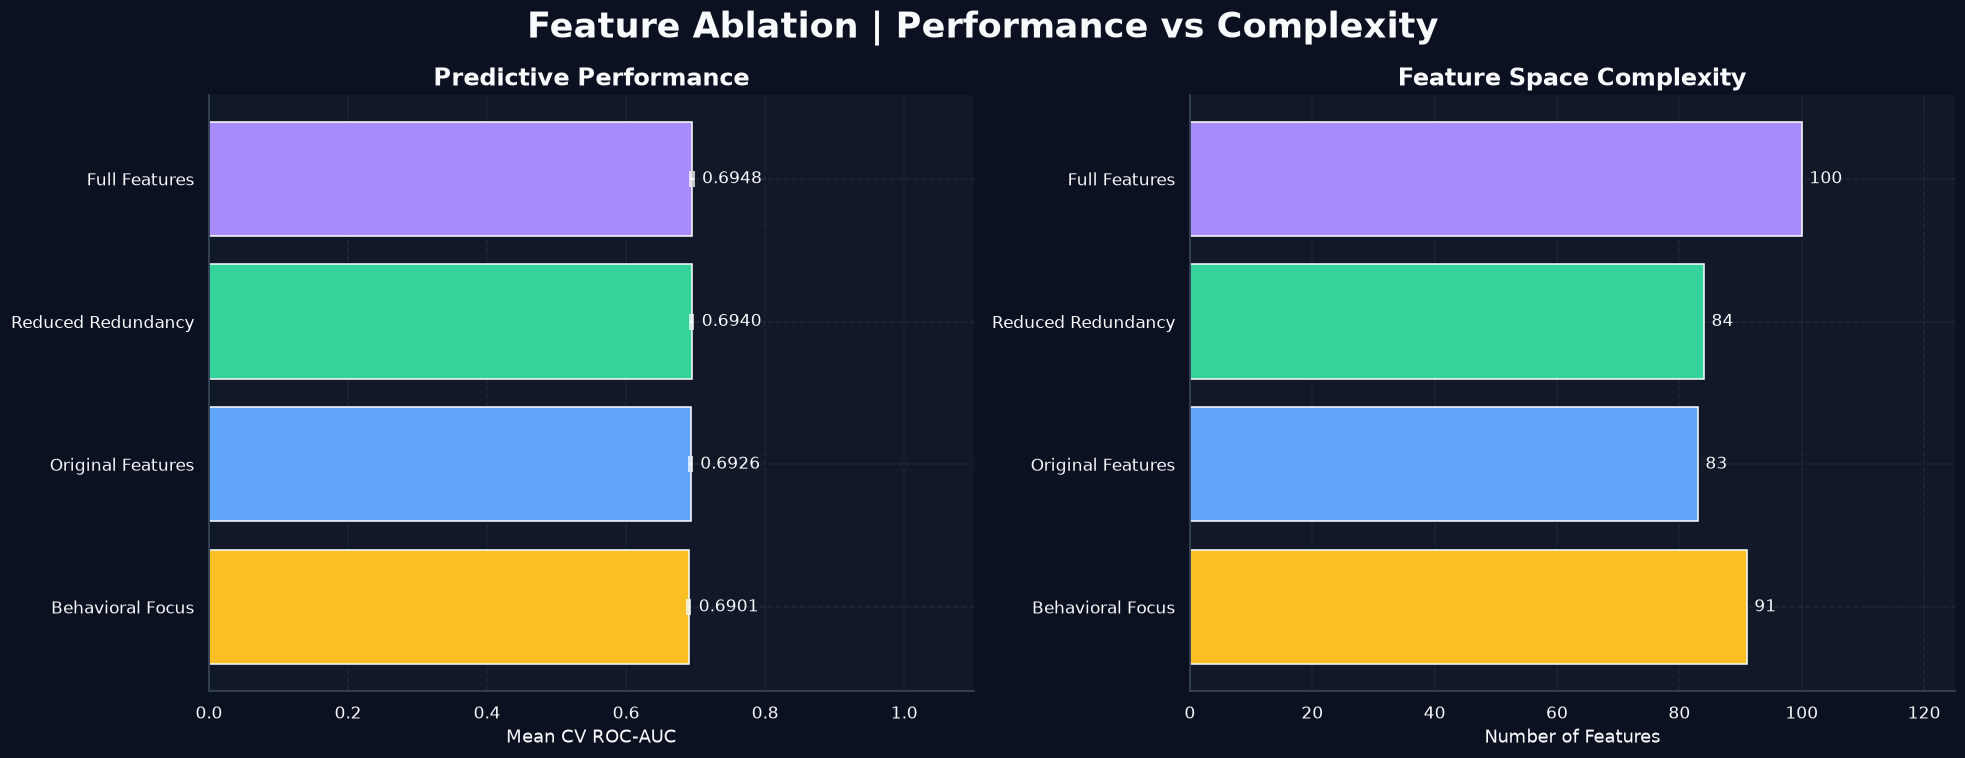

In [123]:
plot_data = ablation_leaderboard.sort_values(

    "CV_ROC_AUC_Mean"

)

fig, axes = plt.subplots(

    1, 2,

    figsize=(18, 7)

)


experiment_colors = {

    "Original Features": BLUE,

    "Full Features": PURPLE,

    "Reduced Redundancy": GREEN,

    "Behavioral Focus": GOLD

}


colors = [

    experiment_colors[name]

    for name in plot_data.index

]


axes[0].barh(

    plot_data.index,

    plot_data["CV_ROC_AUC_Mean"],

    xerr=plot_data["CV_ROC_AUC_Std"],

    color=colors,

    capsize=5,

    error_kw={
        "ecolor": TEXT_COLOR
    }

)


for i, (_, row) in enumerate(

    plot_data.iterrows()

):

    axes[0].text(

        row["CV_ROC_AUC_Mean"] +
        row["CV_ROC_AUC_Std"] + 0.012,

        i,

        f"{row['CV_ROC_AUC_Mean']:.4f}",

        va="center"

    )


axes[0].set_xlim(0, 1.1)

axes[0].set_title(
    "Predictive Performance"
)

axes[0].set_xlabel(
    "Mean CV ROC-AUC"
)


feature_bars = axes[1].barh(

    plot_data.index,

    plot_data["Features"],

    color=colors

)

axes[1].bar_label(

    feature_bars,

    fmt="%.0f",

    padding=5

)

axes[1].set_xlim(

    0,

    plot_data["Features"].max() * 1.25

)

axes[1].set_title(
    "Feature Space Complexity"
)

axes[1].set_xlabel(
    "Number of Features"
)


fig.suptitle(

    "Feature Ablation | Performance vs Complexity",

    fontsize=23,

    fontweight="bold"

)

finish_plot(

    fig,

    "26_feature_ablation_comparison.png"

)

In [124]:
best_ablation_auc = (

    ablation_leaderboard[
        "CV_ROC_AUC_Mean"
    ].max()

)

AUC_TOLERANCE = 0.001


competitive_experiments = ablation_leaderboard.loc[

    ablation_leaderboard["CV_ROC_AUC_Mean"]

    >= best_ablation_auc - AUC_TOLERANCE

].copy()


selected_experiment = (

    competitive_experiments

    .sort_values(

        ["Features", "CV_ROC_AUC_Mean"],

        ascending=[True, False]

    )

    .index[0]

)


selected_configuration = ablation_experiments[
    selected_experiment
]


selected_input_features = (
    selected_configuration["features"]
)


if selected_experiment == "Original Features":

    X_dev_train = original_train[
        selected_input_features
    ].copy()

    X_dev_val = original_val[
        selected_input_features
    ].copy()

else:

    X_dev_train = X_train[
        selected_input_features
    ].copy()

    X_dev_val = X_val[
        selected_input_features
    ].copy()


use_redundancy_selector = (

    selected_experiment == "Reduced Redundancy"

)


print("=" * 65)

print("SELECTED FEATURE CONFIGURATION")

print("=" * 65)

print("Experiment:", selected_experiment)

print("Input Features:", X_dev_train.shape[1])

print(
    "Fold-safe redundancy selection:",
    use_redundancy_selector
)

print("Training Shape:", X_dev_train.shape)

print("Validation Shape:", X_dev_val.shape)

SELECTED FEATURE CONFIGURATION
Experiment: Reduced Redundancy
Input Features: 100
Fold-safe redundancy selection: True
Training Shape: (70000, 100)
Validation Shape: (15000, 100)


**Ablation decision.** Full features achieved the highest recorded mean CV ROC-AUC (0.6948). Reduced Redundancy achieved 0.6940, within the preselected 0.001 tolerance, retaining 84 features in the full-training fit. The selector remains inside the pipeline so each fold learns its own feature subset.

In [125]:
from sklearn.inspection import permutation_importance


importance_cv = StratifiedKFold(

    n_splits=3,

    shuffle=True,

    random_state=SEED

)


importance_results = []


for fold, (train_idx, eval_idx) in enumerate(

    importance_cv.split(
        X_dev_train,
        y_train
    ),

    start=1

):

    print(f"Permutation Importance | Fold {fold}")


    fold_X_train = X_dev_train.iloc[train_idx]

    fold_y_train = y_train.iloc[train_idx]

    fold_X_eval = X_dev_train.iloc[eval_idx]

    fold_y_eval = y_train.iloc[eval_idx]


    sample_index = fold_X_eval.sample(

        n=min(3000, len(fold_X_eval)),

        random_state=SEED + fold

    ).index


    fold_X_eval = fold_X_eval.loc[sample_index]

    fold_y_eval = fold_y_eval.loc[sample_index]


    estimator = clone(
        selected_configuration["model"]
    )


    estimator.fit(
        fold_X_train,
        fold_y_train
    )


    importance = permutation_importance(

        estimator,

        fold_X_eval,

        fold_y_eval,

        scoring="roc_auc",

        n_repeats=3,

        random_state=SEED,

        n_jobs=1

    )


    for feature, mean_importance in zip(

        X_dev_train.columns,

        importance.importances_mean

    ):

        importance_results.append({

            "Fold": fold,

            "Feature": feature,

            "Importance": mean_importance

        })


    del estimator

    gc.collect()


importance_details = pd.DataFrame(
    importance_results
)


permutation_report = (

    importance_details

    .groupby("Feature")

    .agg(

        Mean_Importance=(
            "Importance", "mean"
        ),

        Std_Importance=(
            "Importance", "std"
        ),

        Positive_Folds=(

            "Importance",

            lambda x: (x > 0).sum()

        )

    )

    .sort_values(

        "Mean_Importance",

        ascending=False

    )

)


display(
    permutation_report.head(25).round(6)
)


permutation_report.to_csv(

    REPORTS_DIR /
    "cross_validated_permutation_importance.csv"

)

Permutation Importance | Fold 1
Permutation Importance | Fold 2
Permutation Importance | Fold 3


,Mean_Importance,Std_Importance,Positive_Folds
Feature,,,
months,0.0310,0.0003,3
change_mou,0.0286,0.0059,3
eqpdays,0.0277,0.0029,3
revenue_per_minute,0.0117,0.0024,3
totmrc_Mean,0.0072,0.0034,3
hnd_price,0.0070,0.0028,3
recurring_charge_ratio,0.0063,0.0028,3
avgqty,0.0046,0.0042,3
asl_flag,0.0037,0.0018,3


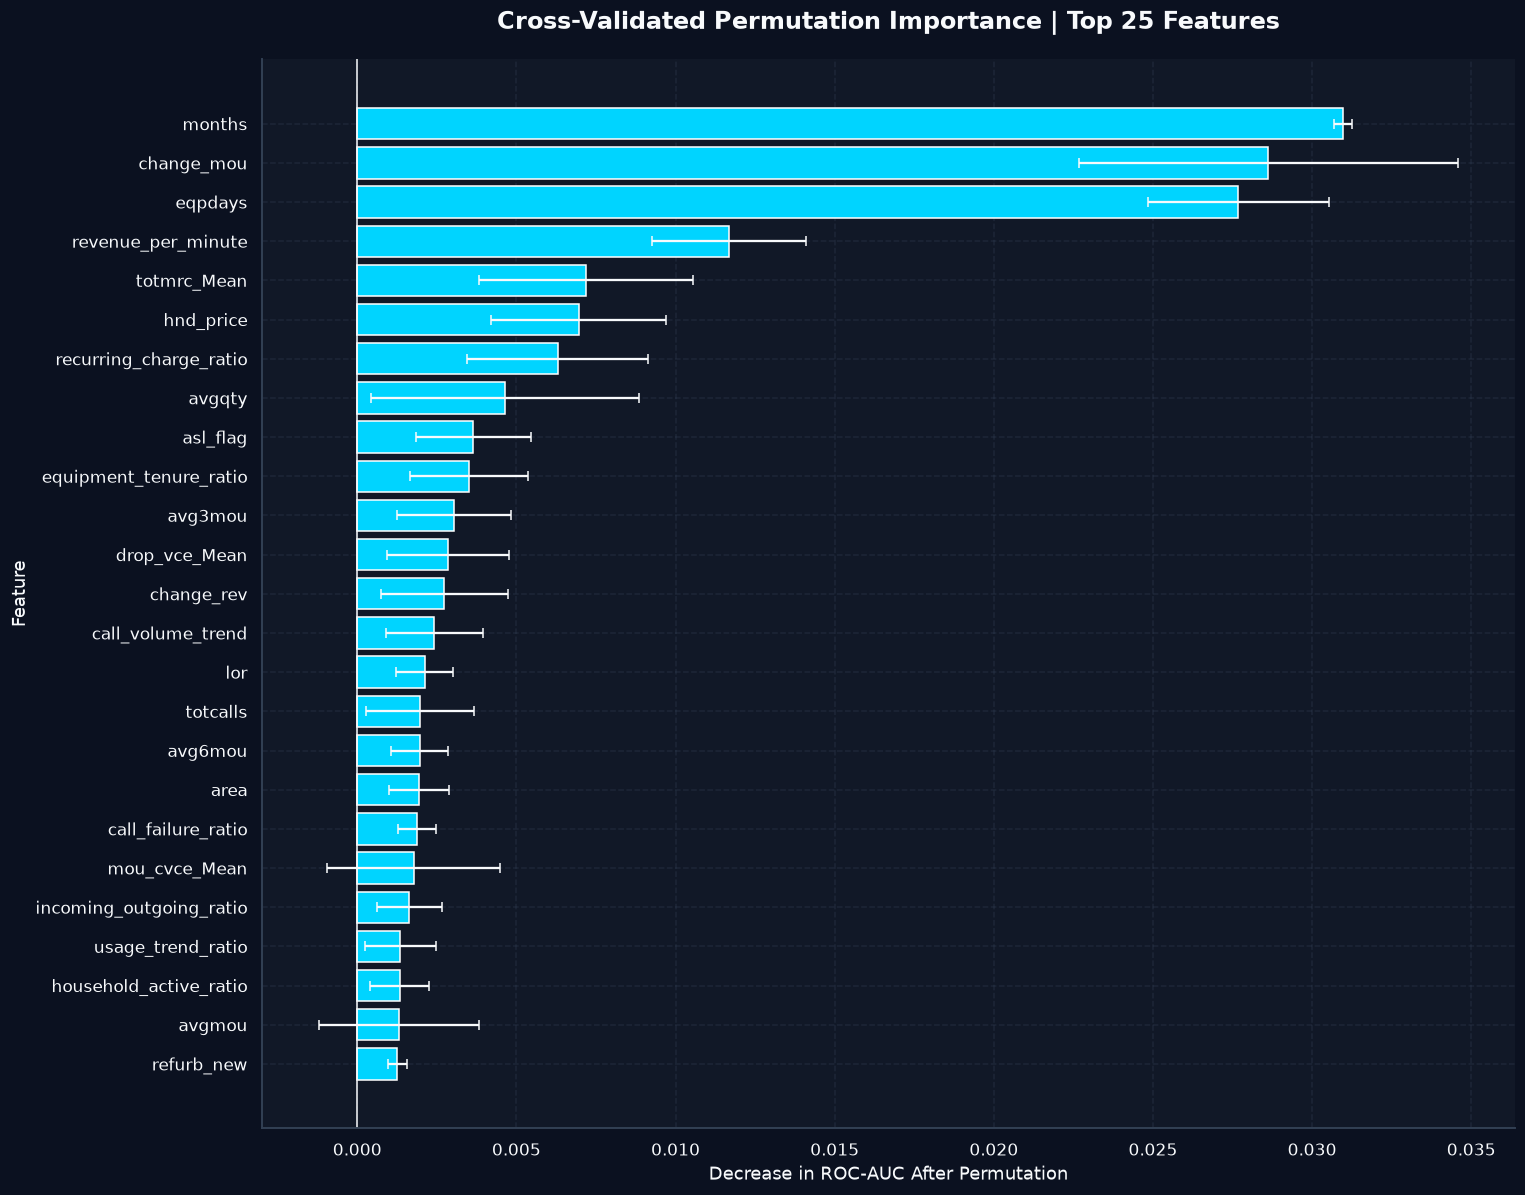

In [126]:
importance_plot = (

    permutation_report

    .head(25)

    .sort_values("Mean_Importance")

)


fig, ax = plt.subplots(

    figsize=(14, 11)

)


colors = [

    CYAN if value >= 0 else RED

    for value in importance_plot[
        "Mean_Importance"
    ]

]


ax.barh(

    importance_plot.index,

    importance_plot["Mean_Importance"],

    xerr=importance_plot["Std_Importance"].fillna(0),

    color=colors,

    capsize=3,

    error_kw={
        "ecolor": TEXT_COLOR
    }

)


ax.axvline(

    0,

    color=TEXT_COLOR,

    linewidth=1

)


ax.set_title(

    "Cross-Validated Permutation Importance | Top 25 Features",

    pad=20

)


ax.set_xlabel(

    "Decrease in ROC-AUC After Permutation"

)


ax.set_ylabel("Feature")


finish_plot(

    fig,

    "27_permutation_feature_importance.png"

)

# 18. Hyperparameter Optimization

Optuna is used to optimize the hyperparameters of
the strongest gradient boosting classifiers.

The optimization objective is mean stratified
cross-validation ROC-AUC.

The optimization process includes:

- Tree-structured Parzen Estimator sampling.
- Model-specific hyperparameter search spaces.
- Regularization and complexity control.
- Fold-level intermediate performance reporting.
- Trial pruning.
- Experiment persistence.
- Reproducible model configuration.

The validation dataset is reserved for comparing
completed optimization experiments.

The independent test dataset remains unused.

In [127]:
import optuna

from optuna.samplers import TPESampler

from optuna.pruners import MedianPruner

from optuna.trial import TrialState


OPTUNA_TRIALS = 25

OPTUNA_FOLDS = 3


OPTUNA_CV = StratifiedKFold(

    n_splits=OPTUNA_FOLDS,

    shuffle=True,

    random_state=SEED

)


OPTUNA_DB = (
    REPORTS_DIR / "optuna_studies.db"
)


OPTUNA_STORAGE = (
    f"sqlite:///{OPTUNA_DB.resolve().as_posix()}"
)


optuna.logging.set_verbosity(
    optuna.logging.INFO
)


print("=" * 65)

print("OPTUNA CONFIGURATION")

print("=" * 65)

print("Trials per model:", OPTUNA_TRIALS)

print("CV Folds:", OPTUNA_FOLDS)

print("Optimization Metric: ROC-AUC")

print("Storage:", OPTUNA_DB)

print("CPU Threads:", N_JOBS)

OPTUNA CONFIGURATION
Trials per model: 25
CV Folds: 3
Optimization Metric: ROC-AUC
Storage: D:\GCI\05. Final Assignment\05. Final Assignment (due Nov 28)\Grad-project\Telecom_Intelligence\Telecom_Intelligence\outputs\reports\optuna_studies.db
CPU Threads: 8


In [128]:
def build_optimization_pipeline(
    model_name,
    parameters
):

    steps = []


    if use_redundancy_selector:

        steps.append(

            (
                "feature_selection",

                RedundancySelector(
                    threshold=REDUNDANCY_THRESHOLD
                )
            )

        )


    if model_name == "LightGBM":

        steps.extend([

            (
                "preprocessor",

                build_dynamic_preprocessor()
            ),

            (
                "model",

                LGBMClassifier(
                    **parameters
                )
            )

        ])


    elif model_name == "XGBoost":

        steps.extend([

            (
                "preprocessor",

                build_dynamic_preprocessor()
            ),

            (
                "model",

                XGBClassifier(
                    **parameters
                )
            )

        ])


    else:

        raise ValueError(

            f"Unsupported model: {model_name}"

        )


    return Pipeline(steps)


print("Optimization pipeline factory initialized.")

Optimization pipeline factory initialized.


In [129]:
def suggest_lightgbm_parameters(trial):

    max_depth = trial.suggest_int(

        "max_depth",

        3, 9

    )


    max_leaves = min(
        2 ** max_depth,
        127
    )


    return {

        "objective": "binary",

        "n_estimators":

            trial.suggest_int(

                "n_estimators",

                250, 1000,

                step=50

            ),

        "learning_rate":

            trial.suggest_float(

                "learning_rate",

                0.01, 0.10,

                log=True

            ),

        "max_depth":
            max_depth,

        "num_leaves":

            trial.suggest_int(

                "num_leaves",

                7, max_leaves

            ),

        "min_child_samples":

            trial.suggest_int(

                "min_child_samples",

                30, 200

            ),

        "subsample":

            trial.suggest_float(

                "subsample",

                0.60, 1.0

            ),

        "subsample_freq": 1,

        "colsample_bytree":

            trial.suggest_float(

                "colsample_bytree",

                0.60, 1.0

            ),

        "reg_alpha":

            trial.suggest_float(

                "reg_alpha",

                1e-4, 20.0,

                log=True

            ),

        "reg_lambda":

            trial.suggest_float(

                "reg_lambda",

                1e-3, 30.0,

                log=True

            ),

        "min_split_gain":

            trial.suggest_float(

                "min_split_gain",

                0.0, 1.0

            ),

        "n_jobs": N_JOBS,

        "random_state": SEED,

        "verbosity": -1

    }

In [130]:
def suggest_xgboost_parameters(trial):

    return {

        "objective": "binary:logistic",

        "eval_metric": "auc",

        "tree_method": "hist",

        "n_estimators":

            trial.suggest_int(

                "n_estimators",

                250, 1000,

                step=50

            ),

        "learning_rate":

            trial.suggest_float(

                "learning_rate",

                0.01, 0.10,

                log=True

            ),

        "max_depth":

            trial.suggest_int(

                "max_depth",

                3, 8

            ),

        "min_child_weight":

            trial.suggest_float(

                "min_child_weight",

                1.0, 30.0,

                log=True

            ),

        "subsample":

            trial.suggest_float(

                "subsample",

                0.60, 1.0

            ),

        "colsample_bytree":

            trial.suggest_float(

                "colsample_bytree",

                0.60, 1.0

            ),

        "gamma":

            trial.suggest_float(

                "gamma",

                0.0, 5.0

            ),

        "reg_alpha":

            trial.suggest_float(

                "reg_alpha",

                1e-4, 20.0,

                log=True

            ),

        "reg_lambda":

            trial.suggest_float(

                "reg_lambda",

                1e-3, 30.0,

                log=True

            ),

        "n_jobs": N_JOBS,

        "random_state": SEED,

        "verbosity": 0

    }

In [131]:
def optimization_objective(
    trial,
    model_name
):

    if model_name == "LightGBM":

        parameters = (
            suggest_lightgbm_parameters(trial)
        )

    elif model_name == "XGBoost":

        parameters = (
            suggest_xgboost_parameters(trial)
        )

    else:

        raise ValueError(model_name)


    # Store the complete model configuration

    trial.set_user_attr(

        "full_parameters",

        parameters

    )


    fold_auc_scores = []

    fold_train_auc_scores = []


    for fold, (train_idx, eval_idx) in enumerate(

        OPTUNA_CV.split(
            X_dev_train,
            y_train
        ),

        start=1

    ):

        fold_X_train = X_dev_train.iloc[
            train_idx
        ]

        fold_y_train = y_train.iloc[
            train_idx
        ]

        fold_X_eval = X_dev_train.iloc[
            eval_idx
        ]

        fold_y_eval = y_train.iloc[
            eval_idx
        ]


        estimator = build_optimization_pipeline(

            model_name,

            parameters

        )


        estimator.fit(

            fold_X_train,

            fold_y_train

        )


        eval_probabilities = (
            estimator.predict_proba(
                fold_X_eval
            )[:, 1]
        )


        train_probabilities = (
            estimator.predict_proba(
                fold_X_train
            )[:, 1]
        )


        fold_auc = roc_auc_score(

            fold_y_eval,

            eval_probabilities

        )


        train_auc = roc_auc_score(

            fold_y_train,

            train_probabilities

        )


        fold_auc_scores.append(fold_auc)

        fold_train_auc_scores.append(train_auc)


        intermediate_score = float(
            np.mean(fold_auc_scores)
        )


        trial.report(

            intermediate_score,

            step=fold

        )


        del estimator

        gc.collect()


        if trial.should_prune():

            raise optuna.TrialPruned()


    mean_auc = float(

        np.mean(fold_auc_scores)

    )


    std_auc = float(

        np.std(
            fold_auc_scores,
            ddof=1
        )

    )


    mean_train_auc = float(

        np.mean(fold_train_auc_scores)

    )


    trial.set_user_attr(

        "cv_auc_std",

        std_auc

    )


    trial.set_user_attr(

        "cv_train_auc",

        mean_train_auc

    )


    trial.set_user_attr(

        "auc_gap",

        mean_train_auc - mean_auc

    )


    return mean_auc

In [132]:
import hashlib


data_hash = hashlib.sha256(

    pd.util.hash_pandas_object(

        X_dev_train,

        index=True

    ).to_numpy().tobytes()

).hexdigest()


target_hash = hashlib.sha256(

    pd.util.hash_pandas_object(

        y_train,

        index=True

    ).to_numpy().tobytes()

).hexdigest()


experiment_config = {

    "experiment_version": "telecom_v3",

    "selected_experiment":
        selected_experiment,

    "features":
        X_dev_train.columns.tolist(),

    "training_rows":
        len(X_dev_train),

    "data_hash":
        data_hash,

    "target_hash":
        target_hash,

    "cv_folds":
        OPTUNA_FOLDS,

    "seed":
        SEED,

    "redundancy_threshold":
        REDUNDANCY_THRESHOLD,

    "search_space_version":
        "v1"

}


experiment_id = hashlib.sha256(

    json.dumps(

        experiment_config,

        sort_keys=True

    ).encode()

).hexdigest()[:12]


def create_optimization_study(model_name):

    study_name = (

        f"{model_name.lower()}_"

        f"{experiment_id}"

    )


    return optuna.create_study(

        study_name=study_name,

        storage=OPTUNA_STORAGE,

        direction="maximize",

        sampler=TPESampler(

            seed=SEED,

            n_startup_trials=8

        ),

        pruner=MedianPruner(

            n_startup_trials=8,

            n_warmup_steps=2

        ),

        load_if_exists=True

    )


print("Experiment ID:", experiment_id)

Experiment ID: 1bfaba9ac866


In [133]:
lightgbm_study = create_optimization_study(

    "LightGBM"

)


completed_trials = sum(

    trial.state == TrialState.COMPLETE

    for trial in lightgbm_study.trials

)


pruned_trials = sum(

    trial.state == TrialState.PRUNED

    for trial in lightgbm_study.trials

)


remaining_trials = max(

    0,

    OPTUNA_TRIALS -
    completed_trials -
    pruned_trials

)


if remaining_trials > 0:

    lightgbm_study.optimize(

        lambda trial: optimization_objective(

            trial,

            "LightGBM"

        ),

        n_trials=remaining_trials,

        n_jobs=1,

        show_progress_bar=True,

        gc_after_trial=True

    )


print("\nLIGHTGBM OPTIMIZATION COMPLETED")


print(

    "Best CV ROC-AUC:",

    f"{lightgbm_study.best_value:.5f}"

)


display(

    pd.DataFrame(

        lightgbm_study.best_trial

        .user_attrs["full_parameters"].items(),

        columns=[
            "Parameter",
            "Best_Value"
        ]

    )

)

[I 2026-11-25 21:00:15,800] A new study created in RDB with name: lightgbm_1bfaba9ac866


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-11-25 21:01:48,655] Trial 0 finished with value: 0.6889002536754658 and parameters: {'max_depth': 5, 'n_estimators': 1000, 'learning_rate': 0.05395030966670229, 'num_leaves': 22, 'min_child_samples': 56, 'subsample': 0.662397808134481, 'colsample_bytree': 0.6232334448672797, 'reg_alpha': 3.905042189404141, 'reg_lambda': 0.49120728102827715, 'min_split_gain': 0.7080725777960455}. Best is trial 0 with value: 0.6889002536754658.
[I 2026-11-25 21:03:22,531] Trial 1 finished with value: 0.6888832385976746 and parameters: {'max_depth': 3, 'n_estimators': 1000, 'learning_rate': 0.06798962421591129, 'num_leaves': 7, 'min_child_samples': 61, 'subsample': 0.6733618039413735, 'colsample_bytree': 0.7216968971838151, 'reg_alpha': 0.06049919340010417, 'reg_lambda': 0.08587568688597208, 'min_split_gain': 0.2912291401980419}. Best is trial 0 with value: 0.6889002536754658.
[I 2026-11-25 21:04:53,446] Trial 2 finished with value: 0.6894465421113504 and parameters: {'max_depth': 7, 'n_estimators

,Parameter,Best_Value
0,objective,binary
1,n_estimators,500
2,learning_rate,0.0315
3,max_depth,7
4,num_leaves,33
5,min_child_samples,70
6,subsample,0.8055
7,subsample_freq,1
8,colsample_bytree,0.9481
9,reg_alpha,5.4404


In [134]:
xgboost_study = create_optimization_study(

    "XGBoost"

)


completed_trials = sum(

    trial.state == TrialState.COMPLETE

    for trial in xgboost_study.trials

)


pruned_trials = sum(

    trial.state == TrialState.PRUNED

    for trial in xgboost_study.trials

)


remaining_trials = max(

    0,

    OPTUNA_TRIALS -
    completed_trials -
    pruned_trials

)


if remaining_trials > 0:

    xgboost_study.optimize(

        lambda trial: optimization_objective(

            trial,

            "XGBoost"

        ),

        n_trials=remaining_trials,

        n_jobs=1,

        show_progress_bar=True,

        gc_after_trial=True

    )


print("\nXGBOOST OPTIMIZATION COMPLETED")


print(

    "Best CV ROC-AUC:",

    f"{xgboost_study.best_value:.5f}"

)


display(

    pd.DataFrame(

        xgboost_study.best_trial

        .user_attrs["full_parameters"].items(),

        columns=[
            "Parameter",
            "Best_Value"
        ]

    )

)

[I 2026-11-25 21:42:41,338] A new study created in RDB with name: xgboost_1bfaba9ac866


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-11-25 21:44:15,034] Trial 0 finished with value: 0.6767148406250506 and parameters: {'n_estimators': 500, 'learning_rate': 0.08927180304353628, 'max_depth': 7, 'min_child_weight': 7.6611007077713635, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'gamma': 0.2904180608409973, 'reg_alpha': 3.905042189404141, 'reg_lambda': 0.49120728102827715}. Best is trial 0 with value: 0.6767148406250506.
[I 2026-11-25 21:45:59,479] Trial 1 finished with value: 0.6923540182932917 and parameters: {'n_estimators': 800, 'learning_rate': 0.010485387725194618, 'max_depth': 8, 'min_child_weight': 16.967533607196547, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402, 'gamma': 0.9170225492671691, 'reg_alpha': 0.004100126498016682, 'reg_lambda': 0.22356209648036382}. Best is trial 1 with value: 0.6923540182932917.
[I 2026-11-25 21:47:30,868] Trial 2 finished with value: 0.6915836116874784 and parameters: {'n_estimators': 550, 'learning_rate': 0.019553708662

,Parameter,Best_Value
0,objective,binary:logistic
1,eval_metric,auc
2,tree_method,hist
3,n_estimators,850
4,learning_rate,0.0165
5,max_depth,8
6,min_child_weight,6.8237
7,subsample,0.7327
8,colsample_bytree,0.8275
9,gamma,1.4439


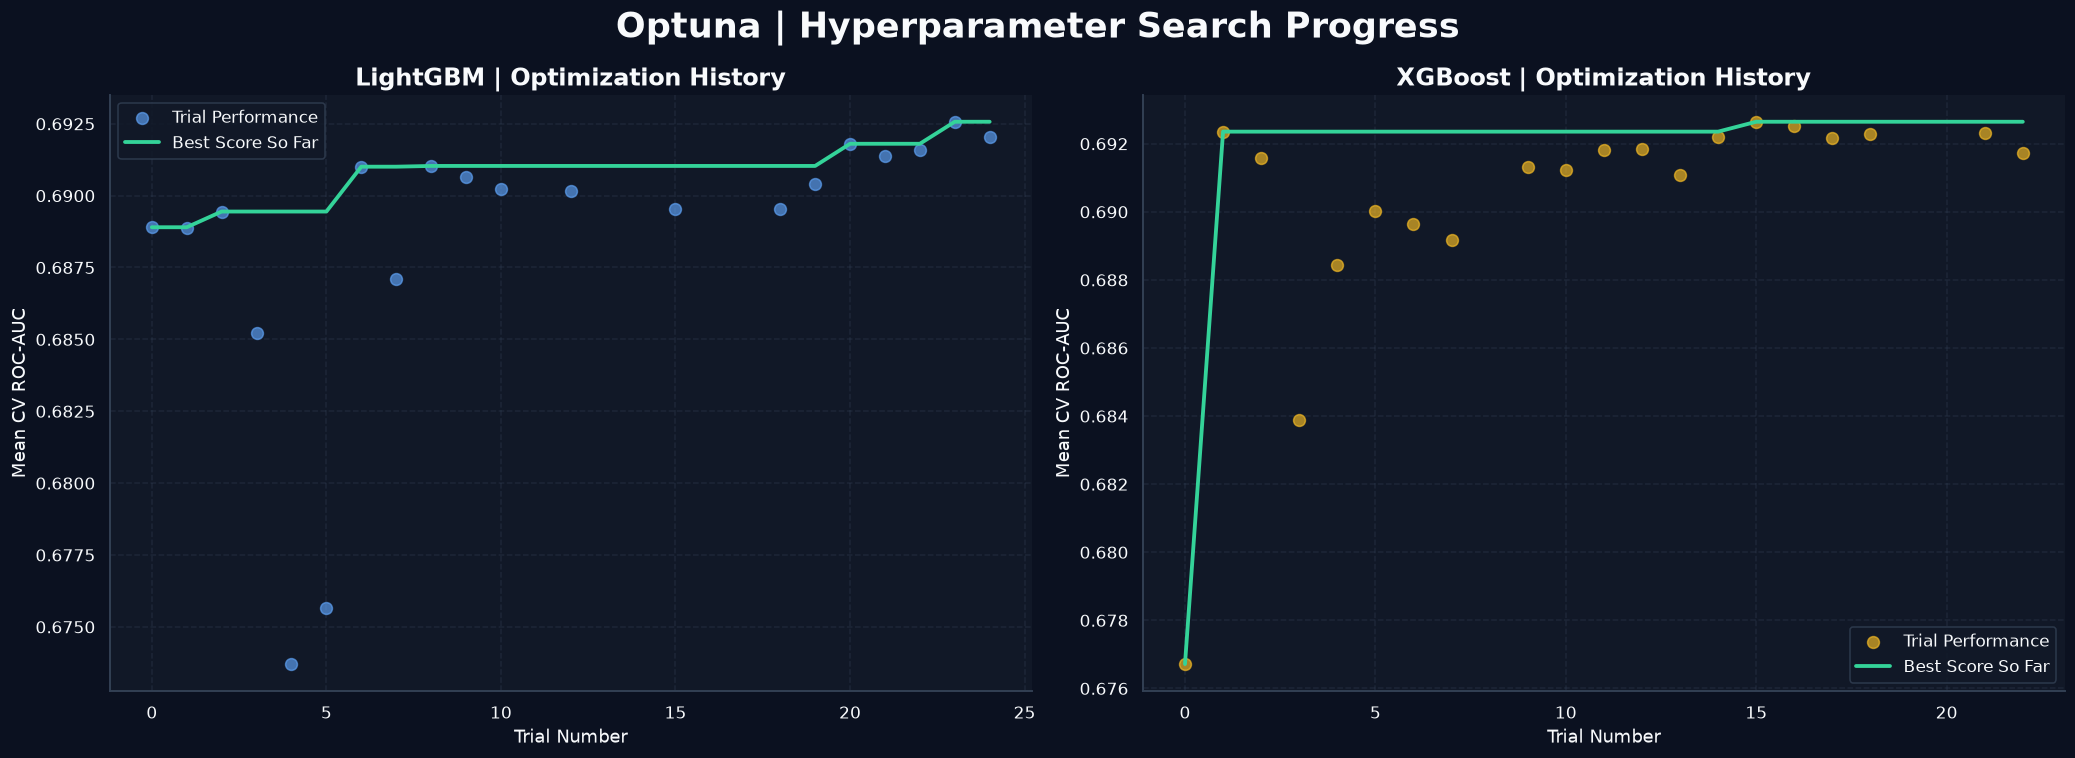

In [135]:
studies = {

    "LightGBM": lightgbm_study,

    "XGBoost": xgboost_study

}


fig, axes = plt.subplots(

    1, 2,

    figsize=(19, 7)

)


for ax, (name, study) in zip(

    axes,

    studies.items()

):

    completed = [

        trial

        for trial in study.trials

        if trial.state == TrialState.COMPLETE

    ]


    trial_numbers = [

        trial.number

        for trial in completed

    ]


    trial_values = np.array([

        trial.value

        for trial in completed

    ])


    best_so_far = np.maximum.accumulate(

        trial_values

    )


    ax.scatter(

        trial_numbers,

        trial_values,

        color=model_colors[name],

        alpha=0.65,

        s=60,

        label="Trial Performance"

    )


    ax.plot(

        trial_numbers,

        best_so_far,

        color=GREEN,

        linewidth=2.5,

        label="Best Score So Far"

    )


    ax.set_title(

        f"{name} | Optimization History"

    )


    ax.set_xlabel("Trial Number")

    ax.set_ylabel("Mean CV ROC-AUC")

    ax.legend()


fig.suptitle(

    "Optuna | Hyperparameter Search Progress",

    fontsize=23,

    fontweight="bold"

)


finish_plot(

    fig,

    "28_optuna_optimization_history.png"

)

d:\GCI\05. Final Assignment\05. Final Assignment (due Nov 28)\Grad-project\Telecom_Intelligence\Telecom_Intelligence\.venv\Lib\site-packages\optuna\importance\_ped_anova\evaluator.py:353: UserWarning: Some regimes for parameter `num_leaves` have less than 2 trials. The importance of the parameter may be inaccurate.
  optuna_warn(


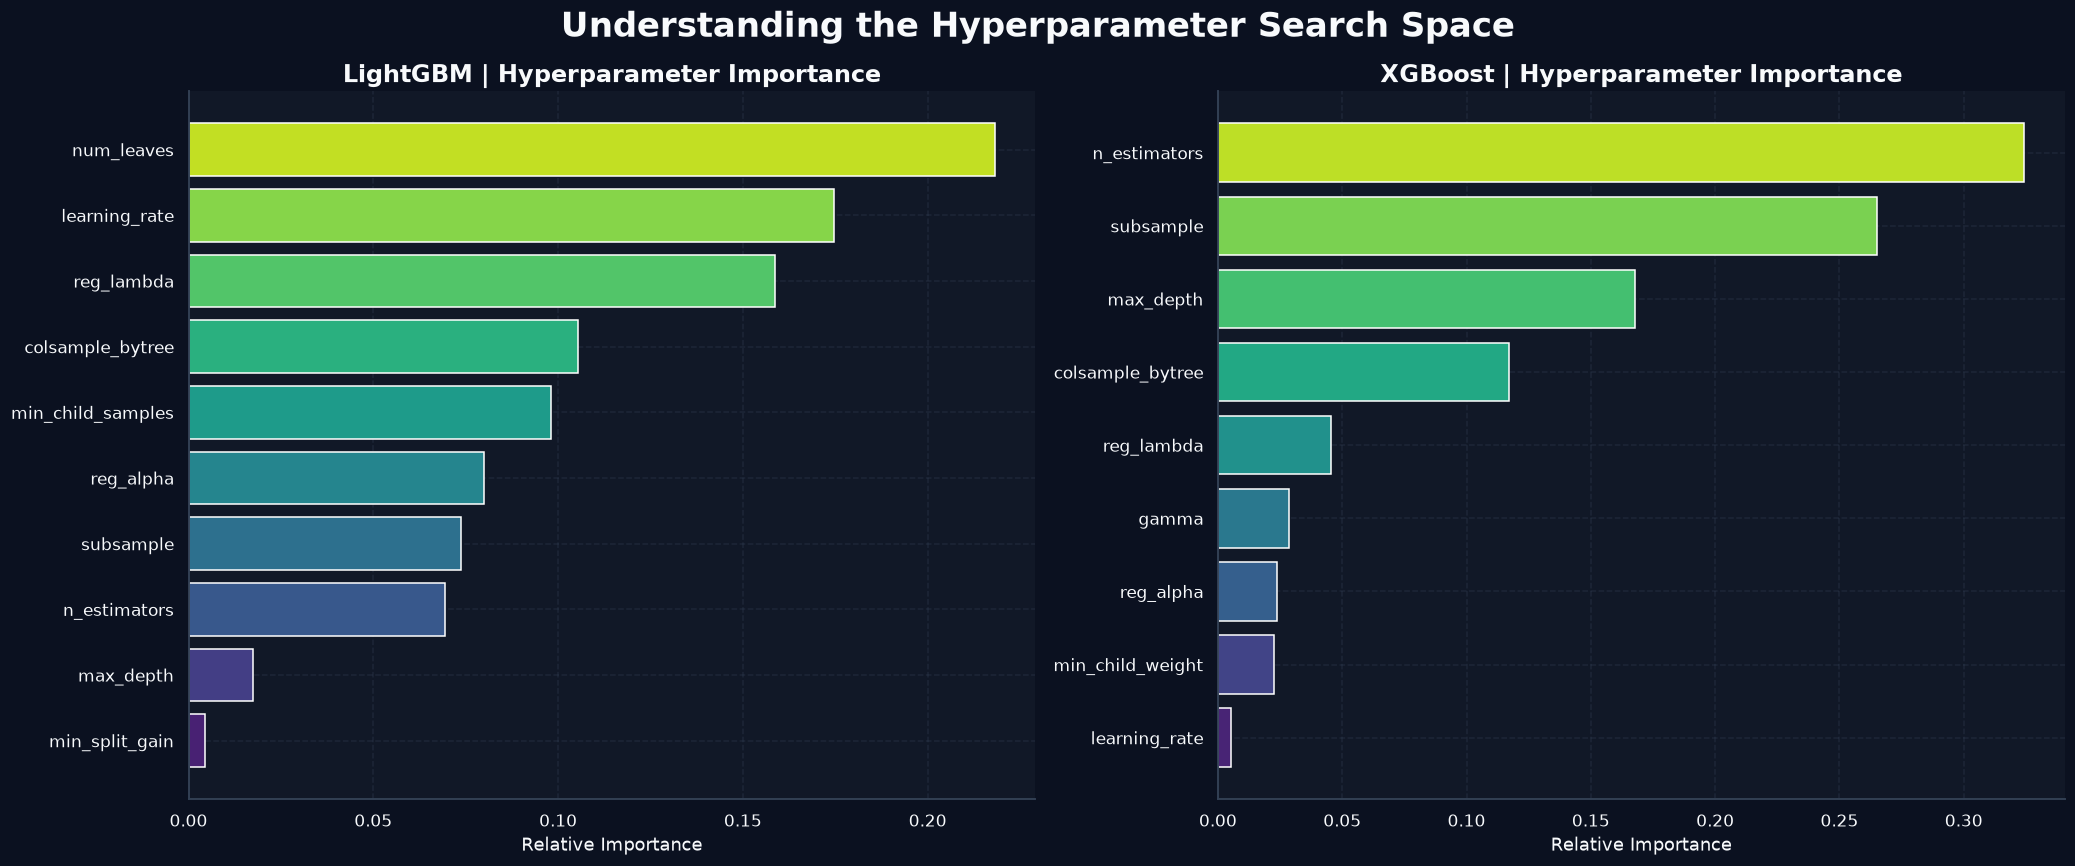

In [136]:
from optuna.importance import get_param_importances


fig, axes = plt.subplots(

    1, 2,

    figsize=(19, 8)

)


hyperparameter_reports = {}


for ax, (name, study) in zip(

    axes,

    studies.items()

):

    parameter_importance = (
        get_param_importances(study)
    )


    parameter_report = pd.Series(

        parameter_importance,

        name="Importance"

    ).sort_values()


    hyperparameter_reports[name] = (

        parameter_report

        .sort_values(ascending=False)

    )


    ax.barh(

        parameter_report.index,

        parameter_report.values,

        color=sns.color_palette(

            "viridis",

            n_colors=len(parameter_report)

        )

    )


    ax.set_title(

        f"{name} | Hyperparameter Importance"

    )


    ax.set_xlabel("Relative Importance")


    parameter_report.to_csv(

        REPORTS_DIR /

        f"{name.lower()}_hyperparameter_importance.csv"

    )


fig.suptitle(

    "Understanding the Hyperparameter Search Space",

    fontsize=22,

    fontweight="bold"

)


finish_plot(

    fig,

    "29_optuna_hyperparameter_importance.png"

)

In [137]:
optimization_summary = []


for name, study in studies.items():

    trials_df = study.trials_dataframe()


    trials_df.to_csv(

        REPORTS_DIR /

        f"{name.lower()}_optuna_trials.csv",

        index=False

    )


    best_trial = study.best_trial


    optimization_summary.append({

        "Model": name,

        "Best_CV_ROC_AUC":
            study.best_value,

        "CV_Std":
            best_trial.user_attrs["cv_auc_std"],

        "Train_AUC":
            best_trial.user_attrs["cv_train_auc"],

        "AUC_Gap":
            best_trial.user_attrs["auc_gap"],

        "Best_Trial":
            best_trial.number,

        "Completed_Trials": sum(

            trial.state == TrialState.COMPLETE

            for trial in study.trials

        ),

        "Pruned_Trials": sum(

            trial.state == TrialState.PRUNED

            for trial in study.trials

        )

    })


    with open(

        REPORTS_DIR /

        f"{name.lower()}_best_parameters.json",

        "w",

        encoding="utf-8"

    ) as file:

        json.dump(

            best_trial.user_attrs["full_parameters"],

            file,

            indent=4

        )


optimization_report = pd.DataFrame(

    optimization_summary

).set_index("Model")


display(optimization_report.round(5))


optimization_report.to_csv(

    REPORTS_DIR /
    "optimization_summary.csv"

)

,Best_CV_ROC_AUC,CV_Std,Train_AUC,AUC_Gap,Best_Trial,Completed_Trials,Pruned_Trials
Model,,,,,,,
LightGBM,0.6926,0.0023,0.7960,0.1035,23,20,5
XGBoost,0.6926,0.0033,0.9209,0.2283,15,20,5


In [138]:
# ==========================================================
# OPTIMIZED MODEL TRAINING
# ==========================================================

optimized_models = {}

optimized_templates = {}

optimized_predictions = {}

optimized_results = []


for name, study in studies.items():

    print("\n" + "=" * 65)

    print(f"TRAINING OPTIMIZED {name.upper()}")

    print("=" * 65)


    parameters = (

        study.best_trial

        .user_attrs["full_parameters"]

    )


    estimator = build_optimization_pipeline(

        name,

        parameters

    )


    optimized_templates[name] = clone(
        estimator
    )


    start_time = time.perf_counter()


    estimator.fit(

        X_dev_train,

        y_train

    )


    elapsed = (

        time.perf_counter() -

        start_time

    )


    train_probabilities = estimator.predict_proba(

        X_dev_train

    )[:, 1]


    val_probabilities = estimator.predict_proba(

        X_dev_val

    )[:, 1]


    metrics = evaluate_model(

        y_val,

        val_probabilities

    )


    metrics["Model"] = f"Tuned {name}"


    metrics["Train_ROC_AUC"] = roc_auc_score(

        y_train,

        train_probabilities

    )


    metrics["AUC_Gap"] = (

        metrics["Train_ROC_AUC"] -

        metrics["ROC_AUC"]

    )


    metrics["Training_Time_Seconds"] = elapsed


    optimized_models[name] = estimator


    optimized_predictions[name] = (

        val_probabilities

    )


    optimized_results.append(metrics)


    print(

        "Validation ROC-AUC:",

        f"{metrics['ROC_AUC']:.5f}"

    )


    print(

        "F1 Score:",

        f"{metrics['F1']:.5f}"

    )


    print(

        "AUC Gap:",

        f"{metrics['AUC_Gap']:.5f}"

    )


    gc.collect()


TRAINING OPTIMIZED LIGHTGBM
Validation ROC-AUC: 0.69970
F1 Score: 0.64160
AUC Gap: 0.07200

TRAINING OPTIMIZED XGBOOST
Validation ROC-AUC: 0.70111
F1 Score: 0.63834
AUC Gap: 0.18486


In [139]:
optimized_leaderboard = (

    pd.DataFrame(optimized_results)

    .set_index("Model")

    .sort_values(

        "ROC_AUC",

        ascending=False

    )

)


optimization_comparison = []


for name in ["LightGBM", "XGBoost"]:

    old_result = leaderboard.loc[name]

    new_result = optimized_leaderboard.loc[
        f"Tuned {name}"
    ]


    optimization_comparison.append({

        "Model": name,

        "Previous_AUC":
            old_result["ROC_AUC"],

        "Optimized_AUC":
            new_result["ROC_AUC"],

        "AUC_Improvement":

            new_result["ROC_AUC"] -
            old_result["ROC_AUC"],

        "Previous_F1":
            old_result["F1"],

        "Optimized_F1":
            new_result["F1"],

        "Previous_AUC_Gap":
            old_result["AUC_Gap"],

        "Optimized_AUC_Gap":
            new_result["AUC_Gap"],

        "Previous_Brier":
            old_result["Brier_Score"],

        "Optimized_Brier":
            new_result["Brier_Score"]

    })


optimization_comparison = pd.DataFrame(

    optimization_comparison

).set_index("Model")


display(
    optimization_comparison.round(5)
)


display(
    optimized_leaderboard.round(5)
)


optimization_comparison.to_csv(

    REPORTS_DIR /
    "before_after_optimization.csv"

)


optimized_leaderboard.to_csv(

    REPORTS_DIR /
    "optimized_model_leaderboard.csv"

)

,Previous_AUC,Optimized_AUC,AUC_Improvement,Previous_F1,Optimized_F1,Previous_AUC_Gap,Optimized_AUC_Gap,Previous_Brier,Optimized_Brier
Model,,,,,,,,,
LightGBM,0.6982,0.6997,0.0015,0.6404,0.6416,0.0782,0.0720,0.2196,0.2192
XGBoost,0.6973,0.7011,0.0039,0.6414,0.6383,0.0627,0.1849,0.2200,0.2185


,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss,Train_ROC_AUC,AUC_Gap,Training_Time_Seconds
Model,,,,,,,,,,,,,,
Tuned XGBoost,0.6379,0.6380,0.6322,0.6446,0.6313,0.6383,0.7011,0.6919,0.2760,0.2185,0.6256,0.8860,0.1849,52.7578
Tuned LightGBM,0.6410,0.6411,0.6351,0.6483,0.6338,0.6416,0.6997,0.6887,0.2821,0.2192,0.6274,0.7717,0.0720,42.7214


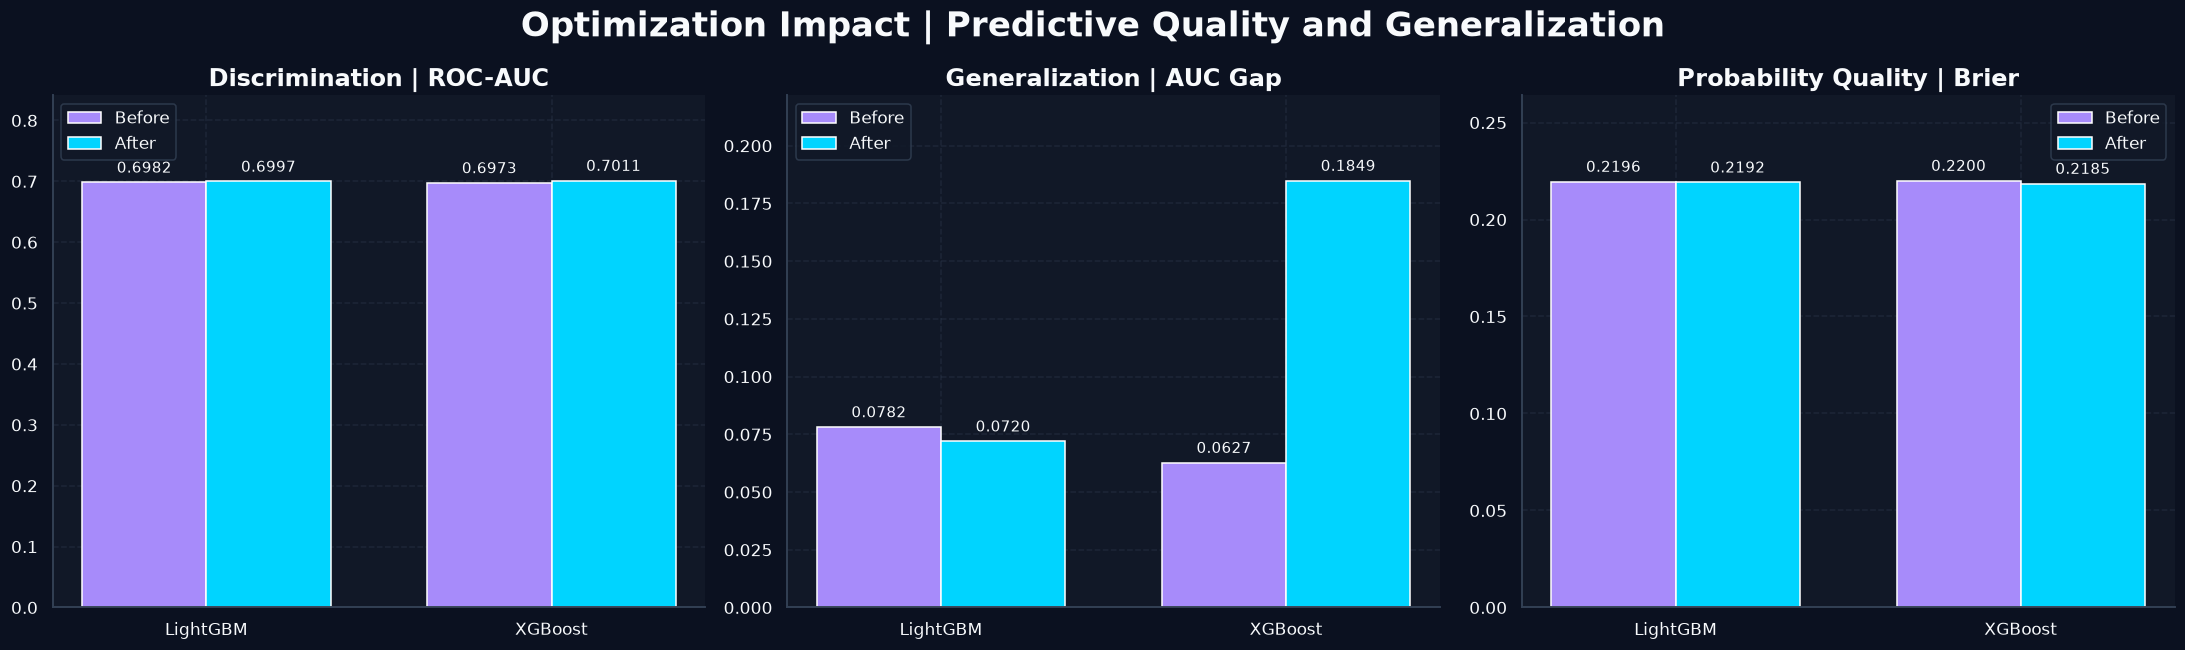

In [140]:
fig, axes = plt.subplots(

    1, 3,

    figsize=(20, 6)

)


plot_metrics = [

    (
        "Previous_AUC",
        "Optimized_AUC",
        "Discrimination | ROC-AUC"
    ),

    (
        "Previous_AUC_Gap",
        "Optimized_AUC_Gap",
        "Generalization | AUC Gap"
    ),

    (
        "Previous_Brier",
        "Optimized_Brier",
        "Probability Quality | Brier"
    )

]


positions = np.arange(

    len(optimization_comparison)

)


for ax, (old_col, new_col, title) in zip(

    axes,

    plot_metrics

):

    before = ax.bar(

        positions - 0.18,

        optimization_comparison[old_col],

        width=0.36,

        color=PURPLE,

        label="Before"

    )


    after = ax.bar(

        positions + 0.18,

        optimization_comparison[new_col],

        width=0.36,

        color=CYAN,

        label="After"

    )


    for bars in [before, after]:

        ax.bar_label(

            bars,

            fmt="%.4f",

            padding=4,

            fontsize=10

        )


    ax.set_xticks(positions)

    ax.set_xticklabels(

        optimization_comparison.index

    )


    ax.set_title(title)

    ax.margins(y=0.20)

    ax.legend()


fig.suptitle(

    "Optimization Impact | Predictive Quality and Generalization",

    fontsize=22,

    fontweight="bold"

)


finish_plot(

    fig,

    "30_optimization_impact.png"

)

# 19. Ensemble Learning

Ensemble methods are investigated to combine
complementary predictive patterns from multiple
machine learning models.

The experiments include:

- Prediction diversity analysis.
- Out-of-fold probability generation.
- Equal-weight soft voting.
- Optimized weighted soft voting.
- Logistic regression stacking.

Ensemble weights and meta-learning parameters are
estimated using training-data out-of-fold predictions.

The separate validation dataset is used for comparison.

In [141]:
# ==========================================================
# ENSEMBLE CANDIDATE CONFIGURATION
# ==========================================================

ensemble_templates = {}

ensemble_features = {}

ensemble_input_types = {}


for name in ["LightGBM", "XGBoost"]:

    tuned_auc = optimized_leaderboard.loc[

        f"Tuned {name}",

        "ROC_AUC"

    ]


    original_auc = leaderboard.loc[

        name,

        "ROC_AUC"

    ]


    if tuned_auc >= original_auc:

        ensemble_templates[name] = clone(

            optimized_templates[name]

        )


        ensemble_features[name] = (

            X_dev_train.columns.tolist()

        )


        ensemble_input_types[name] = (

            "original"

            if selected_experiment == "Original Features"

            else "engineered"

        )


        print(f"{name}: Optimized version selected")


    else:

        ensemble_templates[name] = clone(

            model_templates[name]

        )


        ensemble_features[name] = (

            X_train.columns.tolist()

        )


        ensemble_input_types[name] = "engineered"


        print(f"{name}: Previous version retained")


ensemble_templates["CatBoost"] = clone(

    model_templates["CatBoost"]

)


ensemble_features["CatBoost"] = (

    X_train.columns.tolist()

)


ensemble_input_types["CatBoost"] = "engineered"


print("CatBoost: Native categorical model selected")


ensemble_model_names = list(

    ensemble_templates.keys()

)


def get_ensemble_inputs(model_name):

    features = ensemble_features[
        model_name
    ]


    if ensemble_input_types[model_name] == "original":

        return (

            original_train[features],

            original_val[features]

        )


    return (

        X_train[features],

        X_val[features]

    )


print("\nEnsemble candidates initialized.")

LightGBM: Optimized version selected
XGBoost: Optimized version selected
CatBoost: Native categorical model selected

Ensemble candidates initialized.


In [142]:
# ==========================================================
# OUT-OF-FOLD ENSEMBLE PREDICTIONS
# ==========================================================

ENSEMBLE_FOLDS = 5


ensemble_cv = StratifiedKFold(

    n_splits=ENSEMBLE_FOLDS,

    shuffle=True,

    random_state=SEED

)


ensemble_splits = list(

    ensemble_cv.split(

        X_train,

        y_train

    )

)


n_models = len(
    ensemble_model_names
)


oof_predictions = np.full(

    (len(y_train), n_models),

    np.nan

)


ensemble_val_predictions = np.full(

    (len(y_val), n_models),

    np.nan

)


ensemble_full_models = {}

ensemble_base_results = []


for model_index, name in enumerate(

    ensemble_model_names

):

    print("\n" + "=" * 65)

    print(f"GENERATING OOF PREDICTIONS: {name}")

    print("=" * 65)


    model_X_train, model_X_val = (

        get_ensemble_inputs(name)

    )


    assert model_X_train.index.equals(
        y_train.index
    )

    assert model_X_val.index.equals(
        y_val.index
    )


    for fold, (fit_idx, eval_idx) in enumerate(

        ensemble_splits,

        start=1

    ):

        estimator = clone(

            ensemble_templates[name]

        )


        estimator.fit(

            model_X_train.iloc[fit_idx],

            y_train.iloc[fit_idx]

        )


        fold_probabilities = estimator.predict_proba(

            model_X_train.iloc[eval_idx]

        )[:, 1]


        oof_predictions[

            eval_idx,

            model_index

        ] = fold_probabilities


        fold_auc = roc_auc_score(

            y_train.iloc[eval_idx],

            fold_probabilities

        )


        print(

            f"Fold {fold} ROC-AUC: {fold_auc:.5f}"

        )


        del estimator

        gc.collect()


    full_estimator = clone(

        ensemble_templates[name]

    )


    full_estimator.fit(

        model_X_train,

        y_train

    )


    ensemble_full_models[name] = (

        full_estimator

    )


    ensemble_val_predictions[

        :, model_index

    ] = full_estimator.predict_proba(

        model_X_val

    )[:, 1]


    ensemble_base_results.append({

        "Model": name,

        "OOF_ROC_AUC": roc_auc_score(

            y_train,

            oof_predictions[:, model_index]

        ),

        "Validation_ROC_AUC": roc_auc_score(

            y_val,

            ensemble_val_predictions[:, model_index]

        )

    })


assert np.isfinite(
    oof_predictions
).all()


assert np.isfinite(
    ensemble_val_predictions
).all()


assert np.all(

    (oof_predictions >= 0) &

    (oof_predictions <= 1)

)


assert np.all(

    (ensemble_val_predictions >= 0) &

    (ensemble_val_predictions <= 1)

)


display(

    pd.DataFrame(
        ensemble_base_results
    ).round(5)

)


print("\nOOF Matrix:", oof_predictions.shape)

print(

    "Validation Matrix:",

    ensemble_val_predictions.shape

)


GENERATING OOF PREDICTIONS: LightGBM
Fold 1 ROC-AUC: 0.69229
Fold 2 ROC-AUC: 0.69298
Fold 3 ROC-AUC: 0.69521
Fold 4 ROC-AUC: 0.69599
Fold 5 ROC-AUC: 0.69578

GENERATING OOF PREDICTIONS: XGBoost
Fold 1 ROC-AUC: 0.69084
Fold 2 ROC-AUC: 0.69314
Fold 3 ROC-AUC: 0.69501
Fold 4 ROC-AUC: 0.69642
Fold 5 ROC-AUC: 0.69559

GENERATING OOF PREDICTIONS: CatBoost
Fold 1 ROC-AUC: 0.68855
Fold 2 ROC-AUC: 0.68905
Fold 3 ROC-AUC: 0.69090
Fold 4 ROC-AUC: 0.69265
Fold 5 ROC-AUC: 0.69317


,Model,OOF_ROC_AUC,Validation_ROC_AUC
0,LightGBM,0.6944,0.6997
1,XGBoost,0.6942,0.7011
2,CatBoost,0.6909,0.6951



OOF Matrix: (70000, 3)
Validation Matrix: (15000, 3)


In [143]:
oof_df = pd.DataFrame(

    oof_predictions,

    columns=ensemble_model_names,

    index=y_train.index

)


oof_df[KEY] = train_df.loc[
    oof_df.index, KEY
]


oof_df["Actual_Churn"] = y_train


oof_df.to_csv(

    PREDICTIONS_DIR /
    "ensemble_oof_predictions.csv",

    index=False

)


ensemble_val_df = pd.DataFrame(

    ensemble_val_predictions,

    columns=ensemble_model_names,

    index=y_val.index

)


ensemble_val_df[KEY] = val_df.loc[
    ensemble_val_df.index, KEY
]


ensemble_val_df["Actual_Churn"] = y_val


ensemble_val_df.to_csv(

    PREDICTIONS_DIR /
    "ensemble_validation_predictions.csv",

    index=False

)


display(oof_df.head())

print("OOF predictions exported successfully.")

,LightGBM,XGBoost,CatBoost,Customer_ID,Actual_Churn
49013,0.4179,0.3909,0.4804,1049014,1
5428,0.4762,0.5292,0.5282,1005429,1
70532,0.4263,0.4305,0.3819,1070533,1
99153,0.6716,0.6548,0.6279,1099154,1
36029,0.5825,0.6099,0.5244,1036030,0


OOF predictions exported successfully.


In [144]:
oof_probability_df = pd.DataFrame(

    oof_predictions,

    columns=ensemble_model_names

)


prediction_correlation = (

    oof_probability_df.corr(

        method="spearman"

    )

)


oof_binary = (

    oof_predictions >= 0.5

).astype(int)


actual_labels = y_train.to_numpy()


error_matrix = (

    oof_binary != actual_labels[:, None]

)


error_correlation = pd.DataFrame(

    error_matrix.astype(int),

    columns=ensemble_model_names

).corr()


display(

    prediction_correlation.round(4)

)


display(

    error_correlation.round(4)

)

,LightGBM,XGBoost,CatBoost
LightGBM,1.0000,0.9711,0.9535
XGBoost,0.9711,1.0000,0.9381
CatBoost,0.9535,0.9381,1.0000


,LightGBM,XGBoost,CatBoost
LightGBM,1.0000,0.8403,0.7960
XGBoost,0.8403,1.0000,0.7694
CatBoost,0.7960,0.7694,1.0000


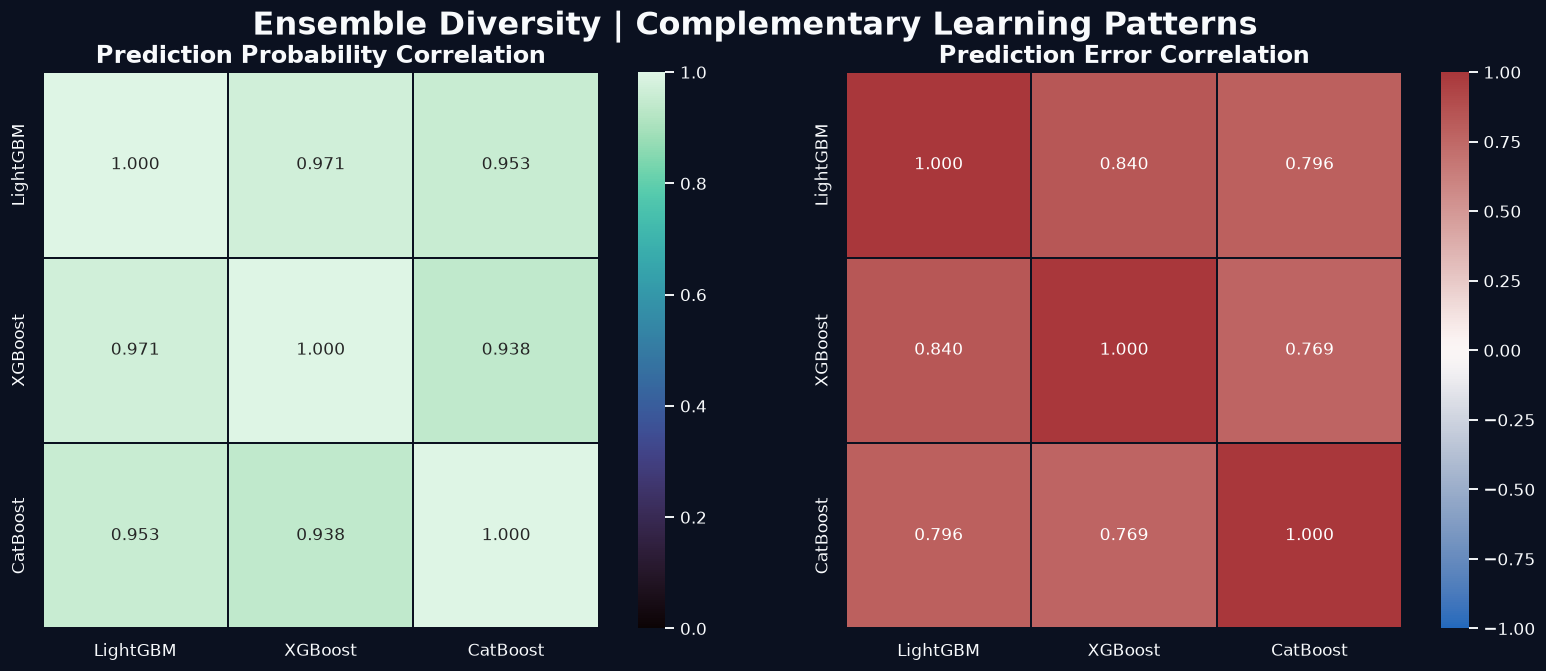

In [145]:
fig, axes = plt.subplots(

    1, 2,

    figsize=(15, 6)

)


sns.heatmap(

    prediction_correlation,

    annot=True,

    fmt=".3f",

    cmap="mako",

    vmin=0,

    vmax=1,

    square=True,

    linewidths=1,

    linecolor=BG_COLOR,

    ax=axes[0]

)


sns.heatmap(

    error_correlation,

    annot=True,

    fmt=".3f",

    cmap="vlag",

    vmin=-1,

    vmax=1,

    center=0,

    square=True,

    linewidths=1,

    linecolor=BG_COLOR,

    ax=axes[1]

)


axes[0].set_title(

    "Prediction Probability Correlation"

)


axes[1].set_title(

    "Prediction Error Correlation"

)


fig.suptitle(

    "Ensemble Diversity | Complementary Learning Patterns",

    fontsize=21,

    fontweight="bold"

)


finish_plot(

    fig,

    "31_ensemble_diversity.png"

)

In [146]:
# ==========================================================
# EQUAL-WEIGHT SOFT VOTING
# ==========================================================

equal_weights = np.ones(

    n_models

) / n_models


equal_voting_oof = (

    oof_predictions @ equal_weights

)


equal_voting_val = (

    ensemble_val_predictions @ equal_weights

)


equal_voting_metrics = evaluate_model(

    y_val,

    equal_voting_val

)


display(

    pd.DataFrame(

        [equal_voting_metrics],

        index=["Equal Soft Voting"]

    ).round(5)

)


print(

    "OOF ROC-AUC:",

    roc_auc_score(

        y_train,

        equal_voting_oof

    )

)

,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss
Equal Soft Voting,0.6386,0.6387,0.6315,0.6504,0.6270,0.6408,0.7013,0.6903,0.2774,0.2188,0.6266


OOF ROC-AUC: 0.6959302805983805


In [147]:
from scipy.optimize import minimize


def voting_objective(weights):

    probabilities = (

        oof_predictions @ weights

    )


    probabilities = np.clip(

        probabilities,

        1e-7,

        1 - 1e-7

    )


    return log_loss(

        y_train,

        probabilities,

        labels=[0, 1]

    )


weight_optimization = minimize(

    voting_objective,

    x0=equal_weights,

    method="SLSQP",

    bounds=[

        (0, 1)

    ] * n_models,

    constraints=[

        {

            "type": "eq",

            "fun": lambda weights: (

                np.sum(weights) - 1

            )

        }

    ],

    options={

        "maxiter": 500,

        "ftol": 1e-10

    }

)


if weight_optimization.success:

    optimized_weights = np.clip(

        weight_optimization.x,

        0,

        1

    )


    optimized_weights /= (

        optimized_weights.sum()

    )


else:

    print(

        "Weight optimization failed. "

        "Using equal weights."

    )


    optimized_weights = equal_weights.copy()


assert np.isclose(

    optimized_weights.sum(),

    1.0

)


voting_weight_report = pd.DataFrame({

    "Model": ensemble_model_names,

    "Equal_Weight": equal_weights,

    "Optimized_Weight": optimized_weights

})


display(
    voting_weight_report.round(5)
)


print(

    "Optimization status:",

    weight_optimization.message

)


print(

    "Optimized OOF Log Loss:",

    voting_objective(
        optimized_weights
    )

)

,Model,Equal_Weight,Optimized_Weight
0,LightGBM,0.3333,0.3318
1,XGBoost,0.3333,0.5222
2,CatBoost,0.3333,0.1460


Optimization status: Optimization terminated successfully
Optimized OOF Log Loss: 0.6302436071396966


In [148]:
weighted_voting_oof = (

    oof_predictions @ optimized_weights

)


weighted_voting_val = (

    ensemble_val_predictions @ optimized_weights

)


weighted_voting_metrics = evaluate_model(

    y_val,

    weighted_voting_val

)


display(

    pd.DataFrame(

        [

            equal_voting_metrics,

            weighted_voting_metrics

        ],

        index=[

            "Equal Soft Voting",

            "Weighted Soft Voting"

        ]

    ).round(5)

)


voting_weight_report.to_csv(

    REPORTS_DIR /
    "optimized_voting_weights.csv",

    index=False

)

,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss
Equal Soft Voting,0.6386,0.6387,0.6315,0.6504,0.6270,0.6408,0.7013,0.6903,0.2774,0.2188,0.6266
Weighted Soft Voting,0.6385,0.6385,0.6321,0.6476,0.6295,0.6397,0.7017,0.6917,0.2771,0.2185,0.6258


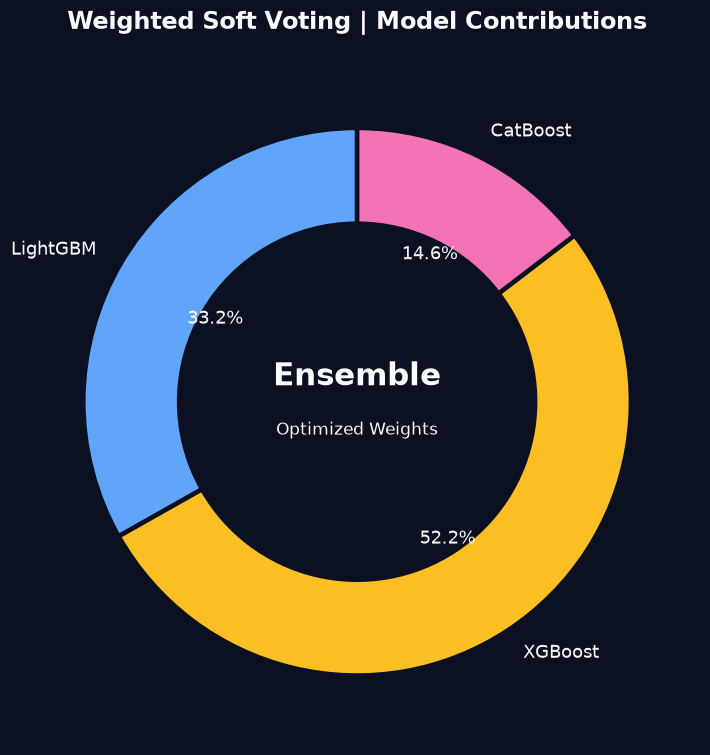

In [149]:
fig, ax = plt.subplots(

    figsize=(10, 7)

)


colors = [

    model_colors.get(name, PURPLE)

    for name in ensemble_model_names

]


wedges, texts, autotexts = ax.pie(

    optimized_weights,

    labels=ensemble_model_names,

    colors=colors,

    autopct="%1.1f%%",

    startangle=90,

    wedgeprops={

        "width": 0.35,

        "edgecolor": BG_COLOR,

        "linewidth": 3

    },

    textprops={

        "color": TEXT_COLOR,

        "fontsize": 12

    }

)


ax.text(

    0,

    0.06,

    "Ensemble",

    ha="center",

    fontsize=20,

    fontweight="bold"

)


ax.text(

    0,

    -0.12,

    "Optimized Weights",

    ha="center",

    fontsize=11

)


ax.set_title(

    "Weighted Soft Voting | Model Contributions",

    pad=20

)


finish_plot(

    fig,

    "32_optimized_ensemble_weights.png"

)

In [150]:
# ==========================================================
# OOF STACKING META-LEARNER
# ==========================================================

from sklearn.model_selection import GridSearchCV


meta_cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=SEED

)


meta_estimator = LogisticRegression(

    solver="lbfgs",

    max_iter=2000,

    random_state=SEED

)


meta_search = GridSearchCV(

    estimator=meta_estimator,

    param_grid={

        "C": [

            0.01,

            0.1,

            1.0,

            10.0

        ]

    },

    scoring="neg_log_loss",

    cv=meta_cv,

    n_jobs=1,

    refit=True,

    error_score="raise"

)


meta_search.fit(

    oof_predictions,

    y_train

)


stacking_meta_model = (

    meta_search.best_estimator_

)


stacking_val_probabilities = (

    stacking_meta_model.predict_proba(

        ensemble_val_predictions

    )[:, 1]

)


stacking_metrics = evaluate_model(

    y_val,

    stacking_val_probabilities

)


print(

    "Best Meta-Learner Parameters:",

    meta_search.best_params_

)


display(

    pd.DataFrame(

        [stacking_metrics],

        index=["OOF Stacking"]

    ).round(5)

)

Best Meta-Learner Parameters: {'C': 10.0}


,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss
OOF Stacking,0.6389,0.6390,0.6324,0.6487,0.6293,0.6404,0.7014,0.6907,0.2781,0.2187,0.6264


,Base_Model,Coefficient
0,LightGBM,1.6283
1,XGBoost,1.7656
2,CatBoost,1.3417


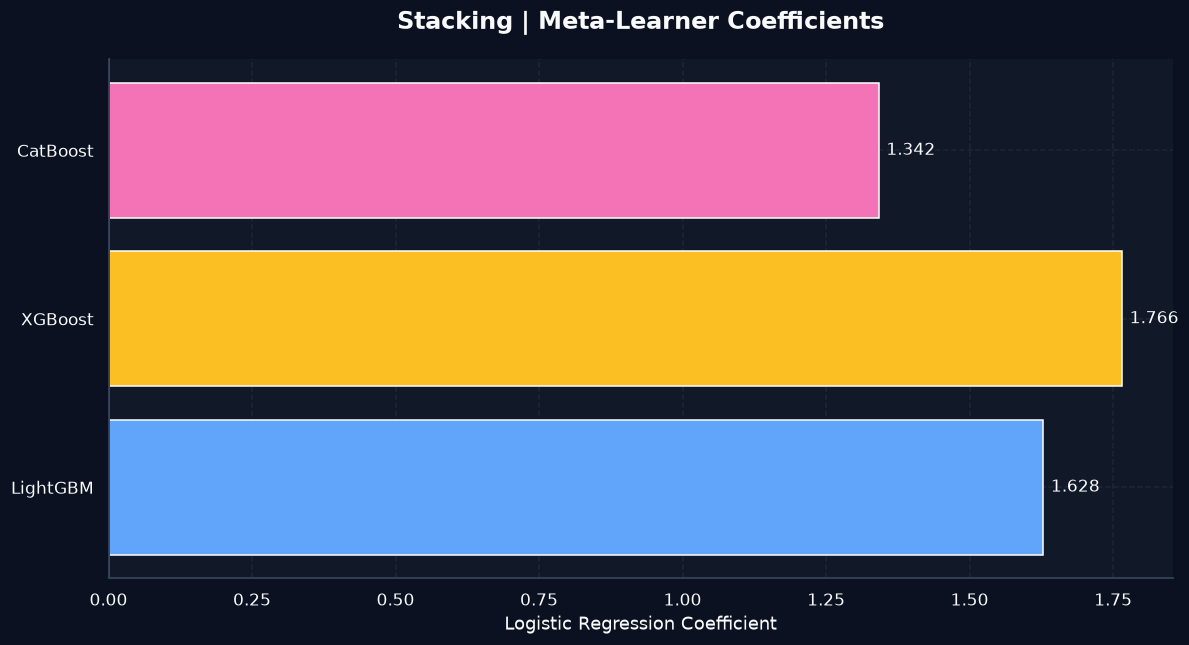

In [151]:
meta_coefficients = pd.DataFrame({

    "Base_Model":
        ensemble_model_names,

    "Coefficient":

        stacking_meta_model.coef_.ravel()

})


display(

    meta_coefficients.round(5)

)


fig, ax = plt.subplots(

    figsize=(11, 6)

)


bars = ax.barh(

    meta_coefficients["Base_Model"],

    meta_coefficients["Coefficient"],

    color=[

        model_colors.get(name, PURPLE)

        for name in ensemble_model_names

    ]

)


ax.axvline(

    0,

    color=TEXT_COLOR,

    linewidth=1

)


ax.bar_label(

    bars,

    fmt="%.3f",

    padding=5

)


ax.set_title(

    "Stacking | Meta-Learner Coefficients",

    pad=20

)


ax.set_xlabel(

    "Logistic Regression Coefficient"

)


finish_plot(

    fig,

    "33_stacking_meta_coefficients.png"

)

In [152]:
development_predictions = {

    **validation_predictions

}


development_predictions.update({

    "Tuned LightGBM":
        optimized_predictions["LightGBM"],

    "Tuned XGBoost":
        optimized_predictions["XGBoost"],

    "Equal Soft Voting":
        equal_voting_val,

    "Weighted Soft Voting":
        weighted_voting_val,

    "OOF Stacking":
        stacking_val_probabilities

})


development_results = []


for name, probabilities in development_predictions.items():

    assert len(probabilities) == len(y_val)


    assert np.isfinite(probabilities).all()


    metrics = evaluate_model(

        y_val,

        probabilities

    )


    metrics["Model"] = name


    development_results.append(metrics)


development_leaderboard = (

    pd.DataFrame(development_results)

    .set_index("Model")

    .sort_values(

        "ROC_AUC",

        ascending=False

    )

)


development_leaderboard["AUC_Gain_vs_Baseline"] = (

    development_leaderboard["ROC_AUC"] -

    development_leaderboard.loc[

        "Logistic Regression",

        "ROC_AUC"

    ]

)


display(

    development_leaderboard.round(5)

)


development_leaderboard.to_csv(

    REPORTS_DIR /
    "development_model_leaderboard.csv"

)

,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss,AUC_Gain_vs_Baseline
Model,,,,,,,,,,,,
Weighted Soft Voting,0.6385,0.6385,0.6321,0.6476,0.6295,0.6397,0.7017,0.6917,0.2771,0.2185,0.6258,0.0662
OOF Stacking,0.6389,0.6390,0.6324,0.6487,0.6293,0.6404,0.7014,0.6907,0.2781,0.2187,0.6264,0.0659
Equal Soft Voting,0.6386,0.6387,0.6315,0.6504,0.6270,0.6408,0.7013,0.6903,0.2774,0.2188,0.6266,0.0657
Tuned XGBoost,0.6379,0.6380,0.6322,0.6446,0.6313,0.6383,0.7011,0.6919,0.2760,0.2185,0.6256,0.0655
Tuned LightGBM,0.6410,0.6411,0.6351,0.6483,0.6338,0.6416,0.6997,0.6887,0.2821,0.2192,0.6274,0.0641
LightGBM,0.6387,0.6388,0.6319,0.6492,0.6283,0.6404,0.6982,0.6873,0.2776,0.2196,0.6282,0.0626
XGBoost,0.6393,0.6394,0.6323,0.6507,0.6282,0.6414,0.6973,0.6855,0.2789,0.2200,0.6294,0.0617
CatBoost,0.6369,0.6370,0.6286,0.6537,0.6204,0.6409,0.6951,0.6802,0.2741,0.2209,0.6315,0.0595
Random Forest,0.6288,0.6290,0.6190,0.6531,0.6049,0.6356,0.6831,0.6663,0.2583,0.2253,0.6412,0.0475


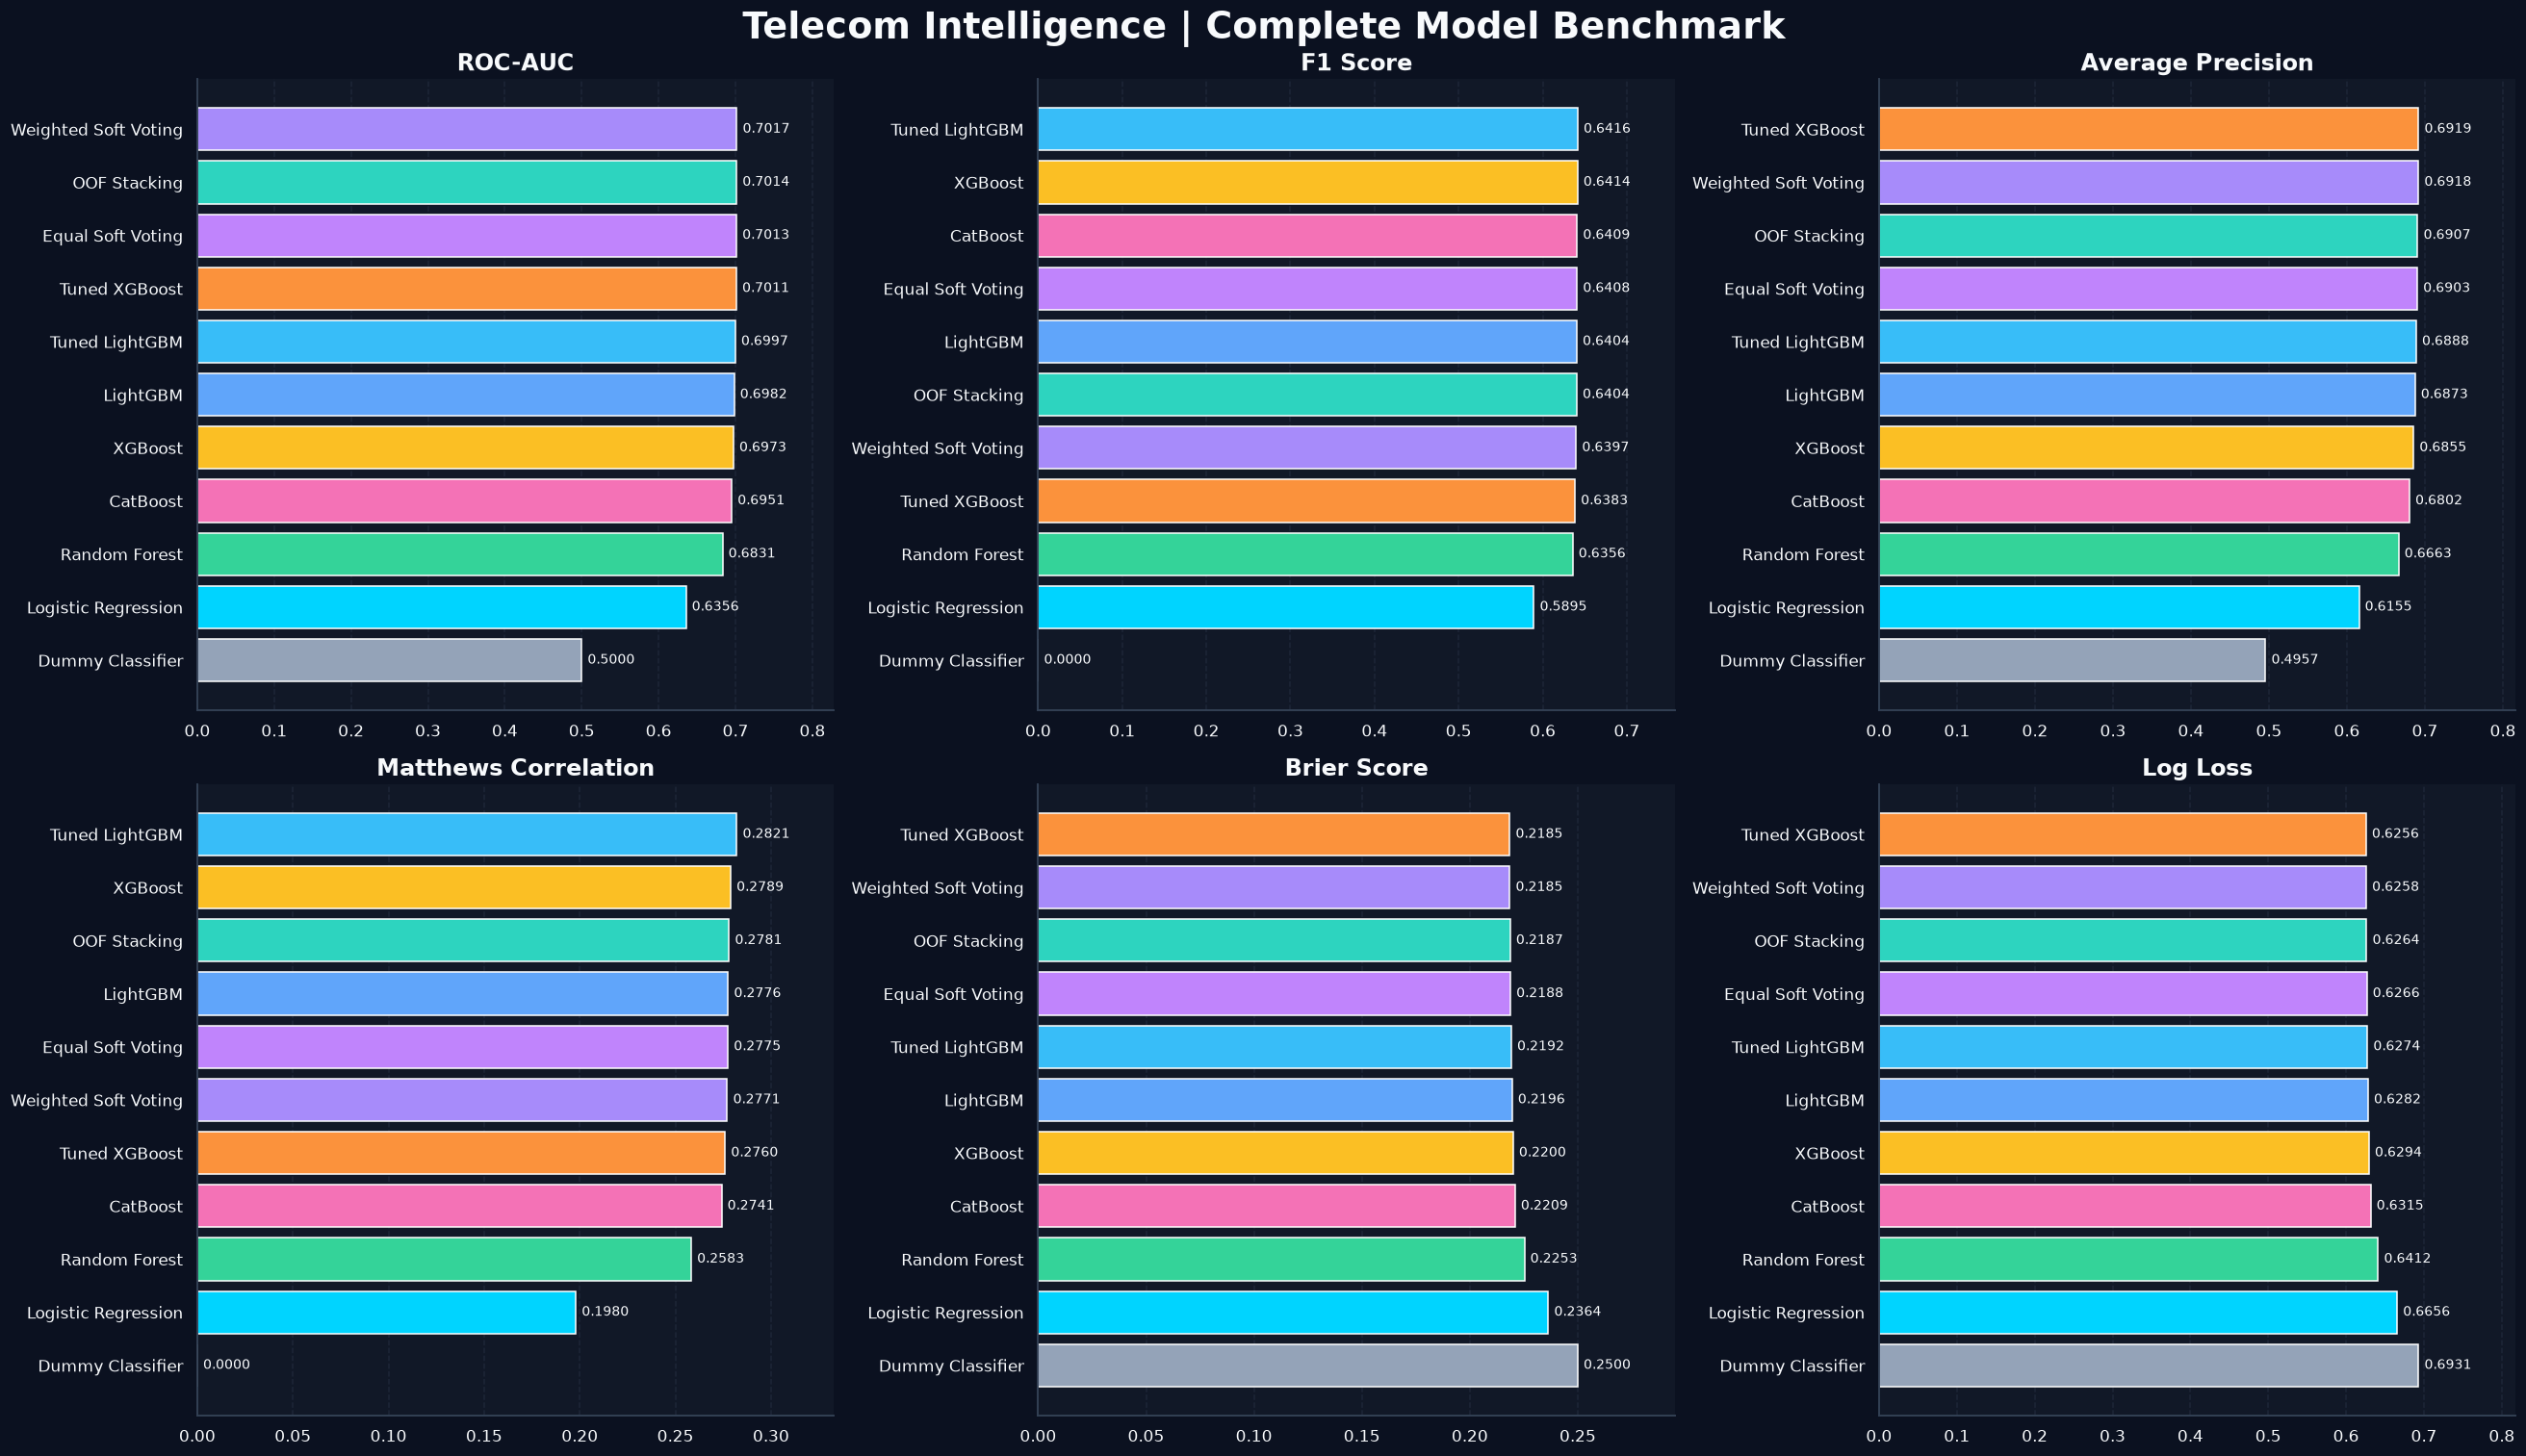

In [153]:
model_colors.update({

    "Tuned LightGBM": "#38BDF8",

    "Tuned XGBoost": "#FB923C",

    "Equal Soft Voting": "#C084FC",

    "Weighted Soft Voting": "#A78BFA",

    "OOF Stacking": "#2DD4BF"

})


metrics_to_plot = [

    ("ROC_AUC", "ROC-AUC", True),

    ("F1", "F1 Score", True),

    ("Average_Precision", "Average Precision", True),

    ("MCC", "Matthews Correlation", True),

    ("Brier_Score", "Brier Score", False),

    ("Log_Loss", "Log Loss", False)

]


fig, axes = plt.subplots(

    2, 3,

    figsize=(24, 14)

)


for ax, (metric, title, higher_better) in zip(

    axes.flat,

    metrics_to_plot

):

    data = development_leaderboard.sort_values(

        metric,

        ascending=higher_better

    )


    colors = [

        model_colors.get(name, PURPLE)

        for name in data.index

    ]


    bars = ax.barh(

        data.index,

        data[metric],

        color=colors

    )


    ax.bar_label(

        bars,

        fmt="%.4f",

        padding=4,

        fontsize=9

    )


    ax.set_title(title)


    ax.margins(x=0.18)


    ax.grid(

        axis="y",

        visible=False

    )


fig.suptitle(

    "Telecom Intelligence | Complete Model Benchmark",

    fontsize=25,

    fontweight="bold"

)


finish_plot(

    fig,

    "34_development_model_dashboard.png"

)

In [154]:
def evaluate_top_k(

    y_true,

    probabilities,

    fraction=0.20

):

    y_true = np.asarray(y_true)

    probabilities = np.asarray(probabilities)


    k = max(

        1,

        int(np.ceil(len(y_true) * fraction))

    )


    ranked_indices = np.argsort(

        -probabilities,

        kind="stable"

    )


    top_indices = ranked_indices[:k]


    captured_churners = y_true[
        top_indices
    ].sum()


    precision_at_k = (

        captured_churners / k

    )


    recall_at_k = (

        captured_churners / y_true.sum()

    )


    prevalence = y_true.mean()


    lift_at_k = (

        precision_at_k / prevalence

    )


    return {

        "Target_Fraction": fraction,

        "Targeted_Customers": k,

        "Captured_Churners":
            captured_churners,

        "Precision_at_K":
            precision_at_k,

        "Recall_at_K":
            recall_at_k,

        "Lift_at_K":
            lift_at_k

    }

In [155]:
campaign_results = []


for name, probabilities in development_predictions.items():

    if name == "Dummy Classifier":

        continue


    for fraction in [0.10, 0.20, 0.30]:

        metrics = evaluate_top_k(

            y_val,

            probabilities,

            fraction=fraction

        )


        metrics["Model"] = name


        campaign_results.append(metrics)


campaign_report = pd.DataFrame(

    campaign_results

)


campaign_20 = (

    campaign_report.loc[

        campaign_report["Target_Fraction"] == 0.20

    ]

    .sort_values(

        "Lift_at_K",

        ascending=False

    )

)


display(

    campaign_20.round(5)

)


campaign_report.to_csv(

    REPORTS_DIR /
    "development_campaign_targeting.csv",

    index=False

)

,Target_Fraction,Targeted_Customers,Captured_Churners,Precision_at_K,Recall_at_K,Lift_at_K,Model
19,0.2000,3000,2245,0.7483,0.3019,1.5097,Tuned XGBoost
25,0.2000,3000,2245,0.7483,0.3019,1.5097,Weighted Soft Voting
28,0.2000,3000,2236,0.7453,0.3007,1.5037,OOF Stacking
22,0.2000,3000,2234,0.7447,0.3005,1.5024,Equal Soft Voting
16,0.2000,3000,2229,0.7430,0.2998,1.4990,Tuned LightGBM
10,0.2000,3000,2207,0.7357,0.2968,1.4842,LightGBM
7,0.2000,3000,2205,0.7350,0.2966,1.4829,XGBoost
13,0.2000,3000,2198,0.7327,0.2956,1.4781,CatBoost
4,0.2000,3000,2134,0.7113,0.2870,1.4351,Random Forest
1,0.2000,3000,1938,0.6460,0.2607,1.3033,Logistic Regression


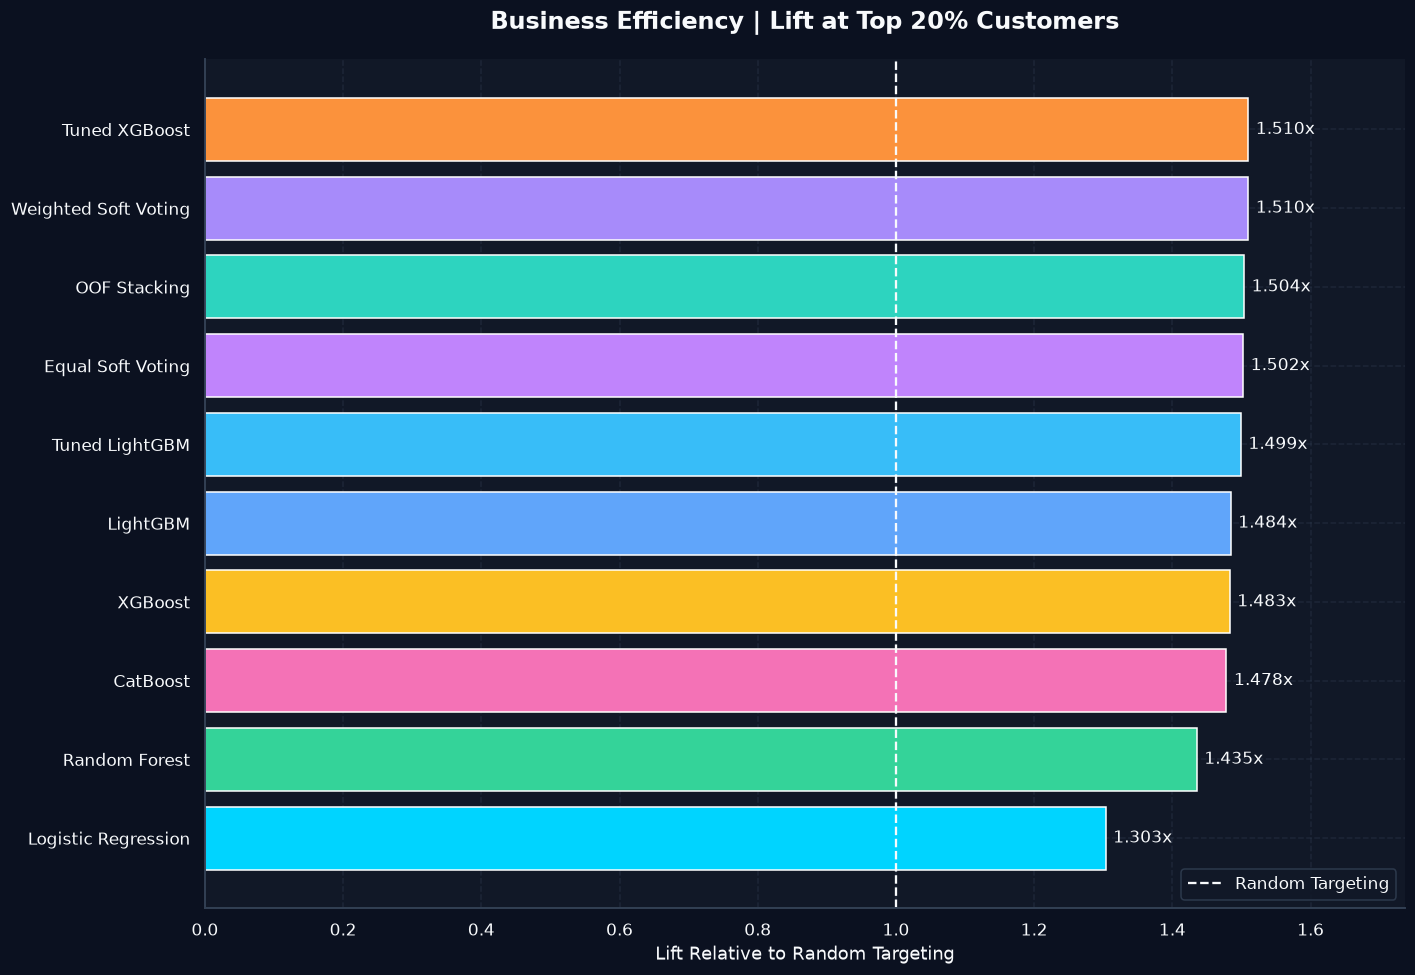

In [156]:
campaign_plot = campaign_20.sort_values(

    "Lift_at_K",

    ascending=True

)


fig, ax = plt.subplots(

    figsize=(13, 9)

)


bars = ax.barh(

    campaign_plot["Model"],

    campaign_plot["Lift_at_K"],

    color=[

        model_colors.get(name, PURPLE)

        for name in campaign_plot["Model"]

    ]

)


ax.bar_label(

    bars,

    fmt="%.3fx",

    padding=5

)


ax.axvline(

    1,

    color=TEXT_COLOR,

    linestyle="--",

    label="Random Targeting"

)


ax.set_title(

    "Business Efficiency | Lift at Top 20% Customers",

    pad=20

)


ax.set_xlabel(

    "Lift Relative to Random Targeting"

)


ax.margins(x=0.15)


ax.legend()


finish_plot(

    fig,

    "35_campaign_targeting_efficiency.png"

)

In [157]:
champion_report = development_leaderboard[

    [

        "ROC_AUC",

        "F1",

        "Recall",

        "Precision",

        "Average_Precision",

        "MCC",

        "Brier_Score",

        "Log_Loss"

    ]

].join(

    campaign_20.set_index("Model")[

        [

            "Precision_at_K",

            "Recall_at_K",

            "Lift_at_K"

        ]

    ],

    how="inner"

)


champion_report = champion_report.sort_values(

    "ROC_AUC",

    ascending=False

)


display(

    champion_report.round(5)

)


champion_report.to_csv(

    REPORTS_DIR /
    "champion_model_selection_report.csv"

)


best_auc = champion_report["ROC_AUC"].max()


competitive_models = champion_report.loc[

    champion_report["ROC_AUC"]

    >= best_auc - 0.001

].copy()


provisional_champion = (

    competitive_models

    .sort_values(

        ["Brier_Score", "Lift_at_K"],

        ascending=[True, False]

    )

    .index[0]

)


print("=" * 65)

print("PROVISIONAL CHAMPION MODEL")

print("=" * 65)

print("Selected Model:", provisional_champion)

print(

    "ROC-AUC:",

    champion_report.loc[

        provisional_champion,

        "ROC_AUC"

    ]

)

print(

    "Brier Score:",

    champion_report.loc[

        provisional_champion,

        "Brier_Score"

    ]

)

print(

    "Lift at Top 20%:",

    champion_report.loc[

        provisional_champion,

        "Lift_at_K"

    ]

)

print("=" * 65)

,ROC_AUC,F1,Recall,Precision,Average_Precision,MCC,Brier_Score,Log_Loss,Precision_at_K,Recall_at_K,Lift_at_K
Model,,,,,,,,,,,
Weighted Soft Voting,0.7017,0.6397,0.6476,0.6321,0.6917,0.2771,0.2185,0.6258,0.7483,0.3019,1.5097
OOF Stacking,0.7014,0.6404,0.6487,0.6324,0.6907,0.2781,0.2187,0.6264,0.7453,0.3007,1.5037
Equal Soft Voting,0.7013,0.6408,0.6504,0.6315,0.6903,0.2774,0.2188,0.6266,0.7447,0.3005,1.5024
Tuned XGBoost,0.7011,0.6383,0.6446,0.6322,0.6919,0.2760,0.2185,0.6256,0.7483,0.3019,1.5097
Tuned LightGBM,0.6997,0.6416,0.6483,0.6351,0.6887,0.2821,0.2192,0.6274,0.7430,0.2998,1.4990
LightGBM,0.6982,0.6404,0.6492,0.6319,0.6873,0.2776,0.2196,0.6282,0.7357,0.2968,1.4842
XGBoost,0.6973,0.6414,0.6507,0.6323,0.6855,0.2789,0.2200,0.6294,0.7350,0.2966,1.4829
CatBoost,0.6951,0.6409,0.6537,0.6286,0.6802,0.2741,0.2209,0.6315,0.7327,0.2956,1.4781
Random Forest,0.6831,0.6356,0.6531,0.6190,0.6663,0.2583,0.2253,0.6412,0.7113,0.2870,1.4351


PROVISIONAL CHAMPION MODEL
Selected Model: Tuned XGBoost
ROC-AUC: 0.7011146170534587
Brier Score: 0.2185119092464447
Lift at Top 20%: 1.5097511768661735


**Champion decision.** Weighted Soft Voting recorded a slightly higher validation ROC-AUC (0.7017) than Tuned XGBoost (0.7011). Under the predefined 0.001 tolerance and Brier/lift tie-breaking rule, Tuned XGBoost was selected. This is a practical selection rule, not evidence of statistically significant superiority. The OOF ensemble experiments are development results, not an independent nested-CV estimate.

## Development Experiment Conclusions

Feature ablation, hyperparameter optimization and
ensemble learning experiments have been conducted.

The candidate models are compared using:

- Predictive discrimination.
- Classification performance.
- Probability quality.
- Cross-validation stability.
- Feature complexity.
- Campaign targeting efficiency.

The provisional champion model is selected using
validation performance and business-oriented metrics.

All model-selection decisions remain independent
of the reserved test dataset.

The following stage will focus on probability
calibration, decision threshold optimization,
final independent testing and explainable AI.

# 20. Final Model Selection and Decision Optimization

The final predictive system is constructed using the
strongest candidate identified during model development.

This section focuses on:

- Champion model configuration.
- Probability calibration.
- Business-oriented decision thresholds.
- Independent test-set evaluation.
- Statistical confidence intervals.
- Explainable artificial intelligence.
- Revenue-aware customer retention.
- Model persistence and monitoring.

All model-selection and decision-policy parameters
are finalized before evaluating the independent test set.

In [158]:
required_variables = [

    "provisional_champion",
    "development_leaderboard",
    "development_predictions",

    "trained_models",
    "optimized_models",
    "ensemble_full_models",

    "ensemble_model_names",
    "ensemble_features",
    "ensemble_input_types",

    "oof_predictions",
    "optimized_weights",
    "stacking_meta_model",

    "X_train_raw",
    "X_val_raw",
    "X_test_raw",

    "y_train",
    "y_val",
    "y_test"

]


missing_variables = [

    name for name in required_variables

    if name not in globals()

]


assert not missing_variables, (

    f"Missing variables: {missing_variables}"

)


assert provisional_champion in development_predictions


CHAMPION_NAME = provisional_champion


print("=" * 65)
print("FINAL MODEL CONFIGURATION")
print("=" * 65)

print("Champion:", CHAMPION_NAME)

display(

    development_leaderboard.loc[
        [CHAMPION_NAME]
    ].round(5)

)

print("Development state validation passed.")

FINAL MODEL CONFIGURATION
Champion: Tuned XGBoost


,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss,AUC_Gain_vs_Baseline
Model,,,,,,,,,,,,
Tuned XGBoost,0.6379,0.6380,0.6322,0.6446,0.6313,0.6383,0.7011,0.6919,0.2760,0.2185,0.6256,0.0655


Development state validation passed.


In [159]:
# ==========================================================
# UNIVERSAL CHAMPION PREDICTION ENGINE
# ==========================================================

def prepare_model_inputs(
    raw_data,
    features,
    input_type
):

    if input_type == "original":

        processed = clean_domain_values(
            raw_data
        )

    elif input_type == "engineered":

        processed = engineer_features_v2(
            raw_data
        )

    else:

        raise ValueError(
            f"Unknown input type: {input_type}"
        )


    missing_columns = [

        col for col in features

        if col not in processed.columns

    ]


    if missing_columns:

        raise ValueError(

            f"Missing model features: {missing_columns}"

        )


    return processed.loc[:, features]


def predict_raw_probability(raw_data):

    if CHAMPION_NAME in trained_models:

        inputs = prepare_model_inputs(

            raw_data,

            X_train.columns.tolist(),

            "engineered"

        )

        probabilities = trained_models[
            CHAMPION_NAME
        ].predict_proba(inputs)[:, 1]


    elif CHAMPION_NAME.startswith("Tuned "):

        name = CHAMPION_NAME.replace(
            "Tuned ", "", 1
        )

        input_type = (

            "original"

            if selected_experiment == "Original Features"

            else "engineered"

        )

        inputs = prepare_model_inputs(

            raw_data,

            X_dev_train.columns.tolist(),

            input_type

        )

        probabilities = optimized_models[
            name
        ].predict_proba(inputs)[:, 1]


    else:

        base_probabilities = []

        for name in ensemble_model_names:

            inputs = prepare_model_inputs(

                raw_data,

                ensemble_features[name],

                ensemble_input_types[name]

            )

            predictions = ensemble_full_models[
                name
            ].predict_proba(inputs)[:, 1]

            base_probabilities.append(
                predictions
            )


        probability_matrix = np.column_stack(
            base_probabilities
        )


        if CHAMPION_NAME == "Equal Soft Voting":

            probabilities = (
                probability_matrix @ equal_weights
            )


        elif CHAMPION_NAME == "Weighted Soft Voting":

            probabilities = (
                probability_matrix @ optimized_weights
            )


        elif CHAMPION_NAME == "OOF Stacking":

            probabilities = (
                stacking_meta_model.predict_proba(
                    probability_matrix
                )[:, 1]
            )


        else:

            raise ValueError(
                f"Unsupported champion: {CHAMPION_NAME}"
            )


    probabilities = np.asarray(
        probabilities,
        dtype=float
    )


    assert np.isfinite(probabilities).all()

    assert np.all(
        (probabilities >= 0) &
        (probabilities <= 1)
    )


    return probabilities

In [160]:
raw_val_probabilities = predict_raw_probability(
    X_val_raw
)

reference_probabilities = development_predictions[
    CHAMPION_NAME
]

np.testing.assert_allclose(

    raw_val_probabilities,

    reference_probabilities,

    rtol=1e-5,

    atol=1e-6

)


print("Champion:", CHAMPION_NAME)

print("Predictions:", len(raw_val_probabilities))

print(
    "Prediction range:",
    raw_val_probabilities.min(),
    raw_val_probabilities.max()
)

print("Prediction consistency test passed.")

Champion: Tuned XGBoost
Predictions: 15000
Prediction range: 0.049526482820510864 0.9748380184173584
Prediction consistency test passed.


In [161]:
from sklearn.model_selection import train_test_split

from sklearn.isotonic import IsotonicRegression

from scipy.special import logit


validation_positions = np.arange(
    len(y_val)
)


calibration_fit_idx, remaining_idx = train_test_split(

    validation_positions,

    test_size=0.60,

    stratify=y_val.to_numpy(),

    random_state=SEED

)


calibration_eval_idx, decision_idx = train_test_split(

    remaining_idx,

    test_size=0.50,

    stratify=y_val.iloc[remaining_idx],

    random_state=SEED

)


assert not set(calibration_fit_idx) & set(
    calibration_eval_idx
)

assert not set(calibration_fit_idx) & set(
    decision_idx
)

assert not set(calibration_eval_idx) & set(
    decision_idx
)


print("Calibration fitting:", len(calibration_fit_idx))

print("Calibration selection:", len(calibration_eval_idx))

print("Decision optimization:", len(decision_idx))

Calibration fitting: 6000
Calibration selection: 4500
Decision optimization: 4500


In [162]:
def probability_to_logit(probabilities):

    probabilities = np.clip(

        np.asarray(probabilities),

        1e-7,

        1 - 1e-7

    )

    return logit(probabilities).reshape(-1, 1)


p_calibration = raw_val_probabilities[
    calibration_fit_idx
]

y_calibration = y_val.iloc[
    calibration_fit_idx
]


sigmoid_calibrator = LogisticRegression(

    C=1e6,

    max_iter=2000,

    random_state=SEED

)


sigmoid_calibrator.fit(

    probability_to_logit(p_calibration),

    y_calibration

)


isotonic_calibrator = IsotonicRegression(

    out_of_bounds="clip",

    y_min=0,

    y_max=1

)


isotonic_calibrator.fit(

    p_calibration,

    y_calibration

)


def apply_calibration(
    probabilities,
    method
):

    probabilities = np.asarray(
        probabilities
    )


    if method == "Uncalibrated":

        return probabilities


    elif method == "Sigmoid":

        return sigmoid_calibrator.predict_proba(

            probability_to_logit(probabilities)

        )[:, 1]


    elif method == "Isotonic":

        return isotonic_calibrator.predict(
            probabilities
        )


    else:

        raise ValueError(method)


print("Probability calibrators trained successfully.")

Probability calibrators trained successfully.


In [163]:
calibration_methods = [

    "Uncalibrated",

    "Sigmoid",

    "Isotonic"

]


calibration_results = []

calibration_predictions = {}


y_cal_eval = y_val.iloc[
    calibration_eval_idx
]

p_cal_eval = raw_val_probabilities[
    calibration_eval_idx
]


for method in calibration_methods:

    probabilities = apply_calibration(

        p_cal_eval,

        method

    )


    calibration_predictions[method] = (
        probabilities
    )


    metrics = evaluate_model(

        y_cal_eval,

        probabilities

    )


    calibration_results.append({

        "Method": method,

        **metrics

    })


calibration_report = (

    pd.DataFrame(calibration_results)

    .set_index("Method")

    .sort_values("Brier_Score")

)


display(calibration_report.round(5))


FINAL_CALIBRATION = calibration_report.index[0]


print("Selected calibration method:", FINAL_CALIBRATION)


calibration_report.to_csv(

    REPORTS_DIR /
    "final_calibration_comparison.csv"

)

,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,MCC,Brier_Score,Log_Loss
Method,,,,,,,,,,,
Uncalibrated,0.6302,0.6303,0.6233,0.6423,0.6183,0.6327,0.6968,0.6908,0.2607,0.2195,0.6275
Sigmoid,0.6300,0.6301,0.6228,0.6432,0.6170,0.6329,0.6968,0.6908,0.2603,0.2195,0.6275
Isotonic,0.6322,0.6320,0.6355,0.6056,0.6584,0.6201,0.6954,0.6742,0.2644,0.2200,0.6427


Selected calibration method: Uncalibrated


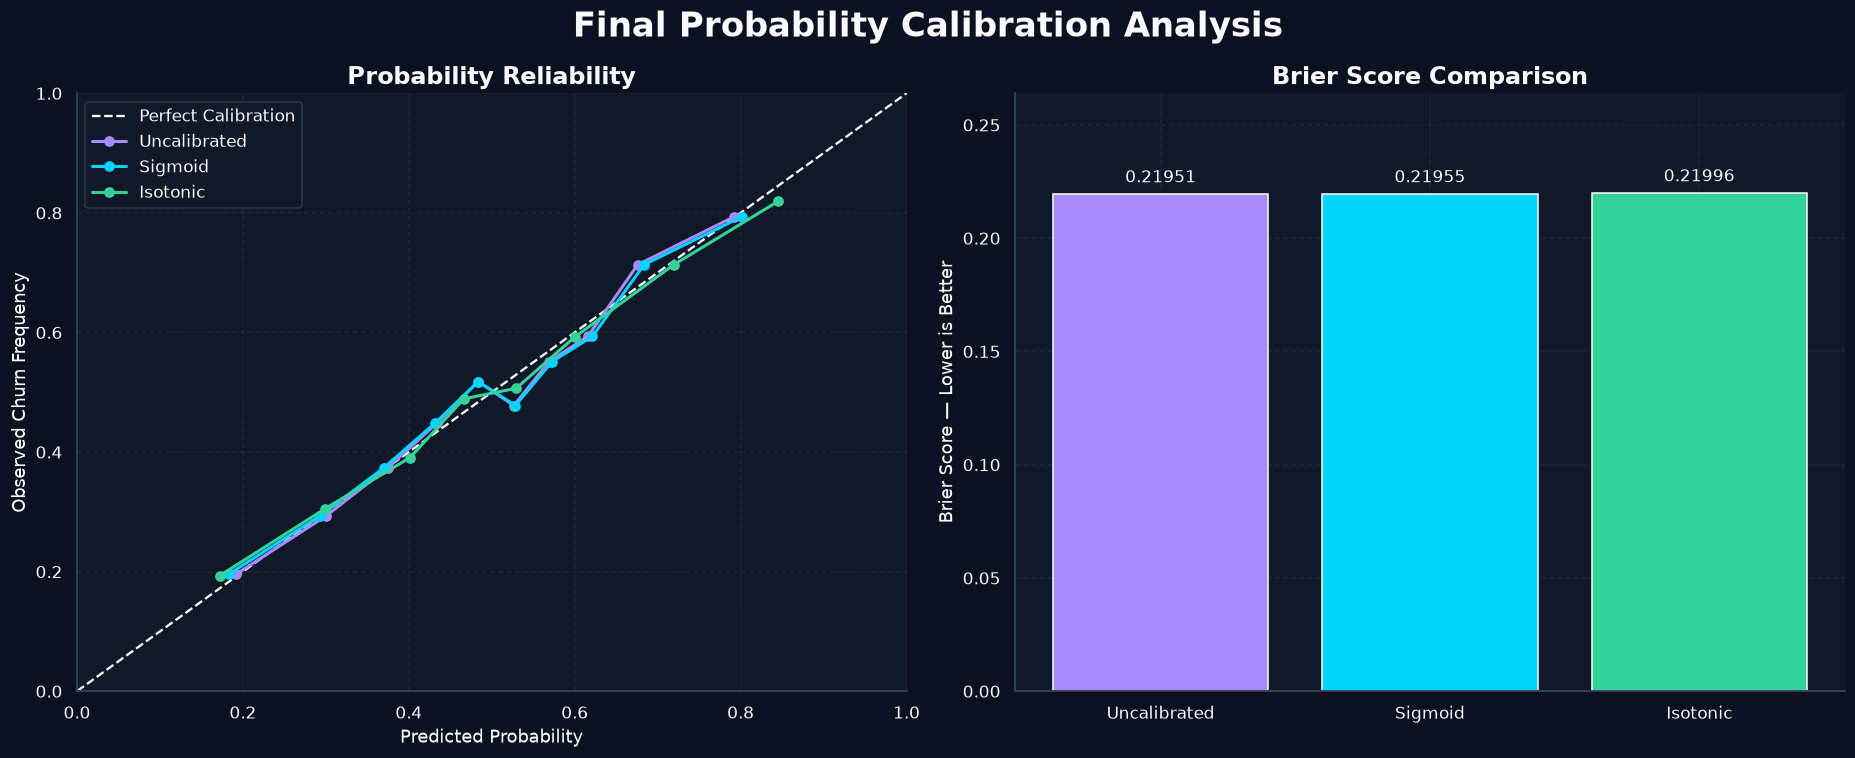

In [164]:
from sklearn.calibration import calibration_curve


fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7)
)


calibration_colors = {

    "Uncalibrated": PURPLE,

    "Sigmoid": CYAN,

    "Isotonic": GREEN

}


axes[0].plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    color=TEXT_COLOR,

    label="Perfect Calibration"

)


for name, probabilities in calibration_predictions.items():

    observed, predicted = calibration_curve(

        y_cal_eval,

        probabilities,

        n_bins=10,

        strategy="quantile"

    )


    axes[0].plot(

        predicted,

        observed,

        marker="o",

        color=calibration_colors[name],

        linewidth=2,

        label=name

    )


axes[0].set_title("Probability Reliability")

axes[0].set_xlabel("Predicted Probability")

axes[0].set_ylabel("Observed Churn Frequency")

axes[0].set_xlim(0, 1)

axes[0].set_ylim(0, 1)

axes[0].legend()


bars = axes[1].bar(

    calibration_report.index,

    calibration_report["Brier_Score"],

    color=[

        calibration_colors[name]

        for name in calibration_report.index

    ]

)


axes[1].bar_label(

    bars,

    fmt="%.5f",

    padding=5

)


axes[1].set_title("Brier Score Comparison")

axes[1].set_ylabel("Brier Score — Lower is Better")

axes[1].margins(y=0.20)


fig.suptitle(

    "Final Probability Calibration Analysis",

    fontsize=22,

    fontweight="bold"

)


finish_plot(

    fig,

    "36_final_probability_calibration.png"

)

In [165]:
# ==========================================================
# BUSINESS ASSUMPTIONS — SCENARIO PARAMETERS
# ==========================================================

BUSINESS_CONFIG = {

    "false_positive_cost": 10.0,

    "false_negative_cost": 50.0,

    "campaign_contact_cost": 5.0,

    "retention_offer_cost": 15.0,

    "retention_success_rate": 0.15,

    "retention_months": 6,

    "contribution_margin": 0.60,

    "campaign_capacity": 0.20

}


display(

    pd.DataFrame(

        BUSINESS_CONFIG.items(),

        columns=["Parameter", "Assumed_Value"]

    )

)

,Parameter,Assumed_Value
0,false_positive_cost,10.0000
1,false_negative_cost,50.0000
2,campaign_contact_cost,5.0000
3,retention_offer_cost,15.0000
4,retention_success_rate,0.1500
5,retention_months,6.0000
6,contribution_margin,0.6000
7,campaign_capacity,0.2000


In [166]:
y_decision = y_val.iloc[
    decision_idx
]

p_decision = apply_calibration(

    raw_val_probabilities[decision_idx],

    FINAL_CALIBRATION

)


threshold_results = []


for threshold in np.linspace(
    0.01, 0.99, 99
):

    predictions = (
        p_decision >= threshold
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(

        y_decision,

        predictions,

        labels=[0, 1]

    ).ravel()


    metrics = evaluate_model(

        y_decision,

        p_decision,

        threshold=threshold

    )


    total_cost = (

        fp * BUSINESS_CONFIG["false_positive_cost"]

        +

        fn * BUSINESS_CONFIG["false_negative_cost"]

    )


    threshold_results.append({

        "Threshold": threshold,

        "Precision": metrics["Precision"],

        "Recall": metrics["Recall"],

        "F1": metrics["F1"],

        "Specificity": metrics["Specificity"],

        "MCC": metrics["MCC"],

        "False_Positives": fp,

        "False_Negatives": fn,

        "Targeted_Customers": tp + fp,

        "Targeting_Rate": (tp + fp) / len(y_decision),

        "Estimated_Error_Cost": total_cost

    })


threshold_report = pd.DataFrame(
    threshold_results
)


best_f1_threshold = float(

    threshold_report.loc[

        threshold_report["F1"].idxmax(),

        "Threshold"

    ]

)


best_cost_threshold = float(

    threshold_report.loc[

        threshold_report["Estimated_Error_Cost"].idxmin(),

        "Threshold"

    ]

)


print("Default Threshold:", 0.50)

print("Best F1 Threshold:", best_f1_threshold)

print("Best Cost Threshold:", best_cost_threshold)


threshold_report.to_csv(

    REPORTS_DIR / "threshold_optimization.csv",

    index=False

)

Default Threshold: 0.5
Best F1 Threshold: 0.33
Best Cost Threshold: 0.13


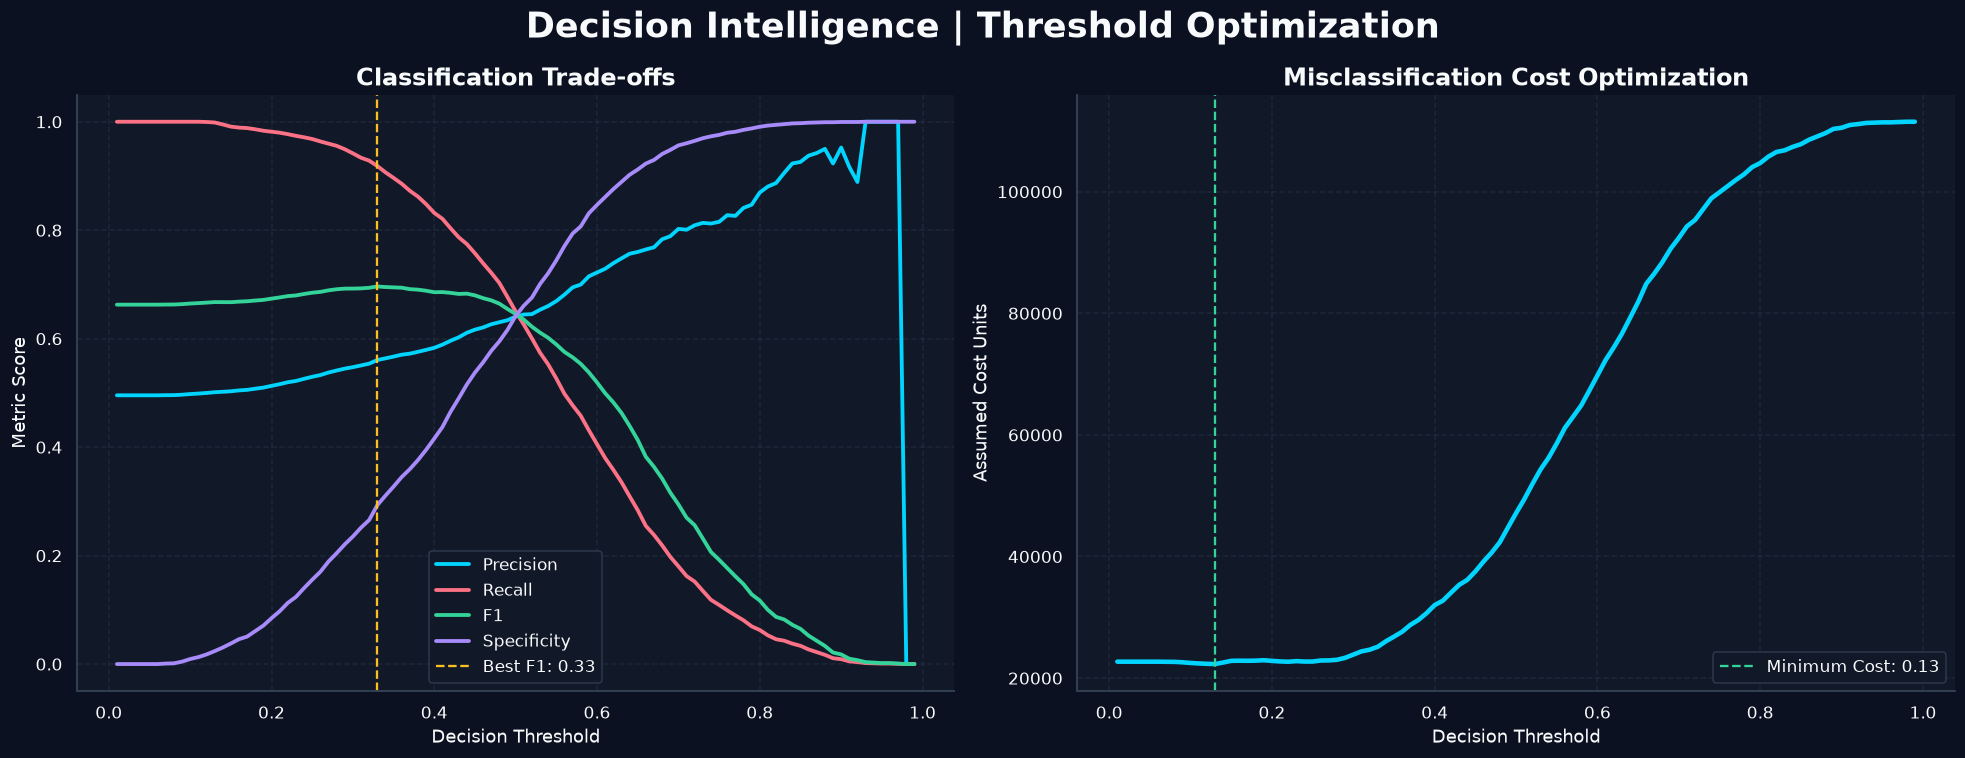

In [167]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 7)
)


for metric, color in [

    ("Precision", CYAN),

    ("Recall", RED),

    ("F1", GREEN),

    ("Specificity", PURPLE)

]:

    axes[0].plot(

        threshold_report["Threshold"],

        threshold_report[metric],

        color=color,

        linewidth=2.5,

        label=metric

    )


axes[0].axvline(

    best_f1_threshold,

    linestyle="--",

    color=GOLD,

    label=f"Best F1: {best_f1_threshold:.2f}"

)


axes[0].set_title("Classification Trade-offs")

axes[0].set_xlabel("Decision Threshold")

axes[0].set_ylabel("Metric Score")

axes[0].legend()


axes[1].plot(

    threshold_report["Threshold"],

    threshold_report["Estimated_Error_Cost"],

    color=CYAN,

    linewidth=3

)


axes[1].axvline(

    best_cost_threshold,

    linestyle="--",

    color=GREEN,

    label=f"Minimum Cost: {best_cost_threshold:.2f}"

)


axes[1].set_title("Misclassification Cost Optimization")

axes[1].set_xlabel("Decision Threshold")

axes[1].set_ylabel("Assumed Cost Units")

axes[1].legend()


fig.suptitle(

    "Decision Intelligence | Threshold Optimization",

    fontsize=23,

    fontweight="bold"

)


finish_plot(

    fig,

    "37_threshold_optimization.png"

)

In [168]:
threshold_strategies = {

    "Default": 0.50,

    "F1 Optimized": best_f1_threshold,

    "Cost Optimized": best_cost_threshold

}


strategy_results = []


for strategy, threshold in threshold_strategies.items():

    metrics = evaluate_model(

        y_decision,

        p_decision,

        threshold=threshold

    )


    predictions = (
        p_decision >= threshold
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(

        y_decision,

        predictions,

        labels=[0, 1]

    ).ravel()


    strategy_results.append({

        "Strategy": strategy,

        "Threshold": threshold,

        "Precision": metrics["Precision"],

        "Recall": metrics["Recall"],

        "F1": metrics["F1"],

        "Targeting_Rate": predictions.mean(),

        "False_Positives": fp,

        "False_Negatives": fn,

        "Assumed_Error_Cost": (

            fp * BUSINESS_CONFIG["false_positive_cost"]

            +

            fn * BUSINESS_CONFIG["false_negative_cost"]

        )

    })


decision_strategy_report = (

    pd.DataFrame(strategy_results)

    .set_index("Strategy")

)


display(decision_strategy_report.round(5))


decision_strategy_report.to_csv(

    REPORTS_DIR / "decision_strategy_comparison.csv"

)

,Threshold,Precision,Recall,F1,Targeting_Rate,False_Positives,False_Negatives,Assumed_Error_Cost
Strategy,,,,,,,,
Default,0.5000,0.6407,0.6502,0.6454,0.5029,813,780,"47,130.0000"
F1 Optimized,0.3300,0.5606,0.9184,0.6962,0.8118,1605,182,"25,150.0000"
Cost Optimized,0.1300,0.5012,0.9987,0.6675,0.9873,2216,3,"22,310.0000"


In [169]:
FINAL_THRESHOLD = best_f1_threshold


FINAL_POLICY = {

    "champion_model": CHAMPION_NAME,

    "calibration_method": FINAL_CALIBRATION,

    "classification_threshold": FINAL_THRESHOLD,

    "threshold_selection": "Maximum development F1",

    "campaign_capacity": BUSINESS_CONFIG[
        "campaign_capacity"
    ],

    "business_assumptions": BUSINESS_CONFIG

}


with open(

    MODELS_DIR / "final_decision_policy.json",

    "w",

    encoding="utf-8"

) as file:

    json.dump(
        FINAL_POLICY,
        file,
        indent=4
    )


print("=" * 65)

print("FINAL MODEL AND DECISION POLICY FROZEN")

print("=" * 65)

print("Model:", CHAMPION_NAME)

print("Calibration:", FINAL_CALIBRATION)

print("Threshold:", FINAL_THRESHOLD)

print("=" * 65)

FINAL MODEL AND DECISION POLICY FROZEN
Model: Tuned XGBoost
Calibration: Uncalibrated
Threshold: 0.33


**Decision policy.** The recorded run retained the uncalibrated probabilities and selected a classification threshold of 0.33 by development F1. Campaign targeting is separate: it uses expected incremental contribution and a capacity constraint. Neither threshold nor model is retuned on the independent test results.

# 21. Independent Test Evaluation

The final model architecture, probability calibration
method and classification threshold have been frozen.

The independent test dataset is now used to estimate
the generalization performance of the complete system.

Test results are reported without further model tuning
or threshold selection.

In [170]:
assert X_test_raw.index.equals(
    y_test.index
)


test_raw_probabilities = predict_raw_probability(

    X_test_raw

)


test_probabilities = apply_calibration(

    test_raw_probabilities,

    FINAL_CALIBRATION

)


test_predictions = (

    test_probabilities >= FINAL_THRESHOLD

).astype(int)


assert len(test_probabilities) == len(y_test)

assert np.isfinite(test_probabilities).all()

assert np.all(

    (test_probabilities >= 0)

    &

    (test_probabilities <= 1)

)


print("Independent Test Customers:", len(y_test))

print("Champion Model:", CHAMPION_NAME)

print("Final Threshold:", FINAL_THRESHOLD)

print("Test predictions generated successfully.")

Independent Test Customers: 15000
Champion Model: Tuned XGBoost
Final Threshold: 0.33
Test predictions generated successfully.


In [171]:
final_test_metrics = evaluate_model(

    y_test,

    test_probabilities,

    threshold=FINAL_THRESHOLD

)


final_test_report = pd.DataFrame(

    [final_test_metrics],

    index=[CHAMPION_NAME]

)


display(
    final_test_report.T.round(5)
)


final_test_report.to_csv(

    REPORTS_DIR / "final_independent_test_metrics.csv"

)


print("\nCLASSIFICATION REPORT\n")


print(

    classification_report(

        y_test,

        test_predictions,

        target_names=[
            "Retained",
            "Churned"
        ],

        digits=4,

        zero_division=0

    )

)

,Tuned XGBoost
Accuracy,0.5915
Balanced_Accuracy,0.5943
Precision,0.5533
Recall,0.9118
Specificity,0.2768
F1,0.6887
ROC_AUC,0.6937
Average_Precision,0.6824
MCC,0.2436
Brier_Score,0.2207



CLASSIFICATION REPORT

              precision    recall  f1-score   support

    Retained     0.7615    0.2768    0.4060      7566
     Churned     0.5533    0.9118    0.6887      7434

    accuracy                         0.5915     15000
   macro avg     0.6574    0.5943    0.5473     15000
weighted avg     0.6583    0.5915    0.5461     15000



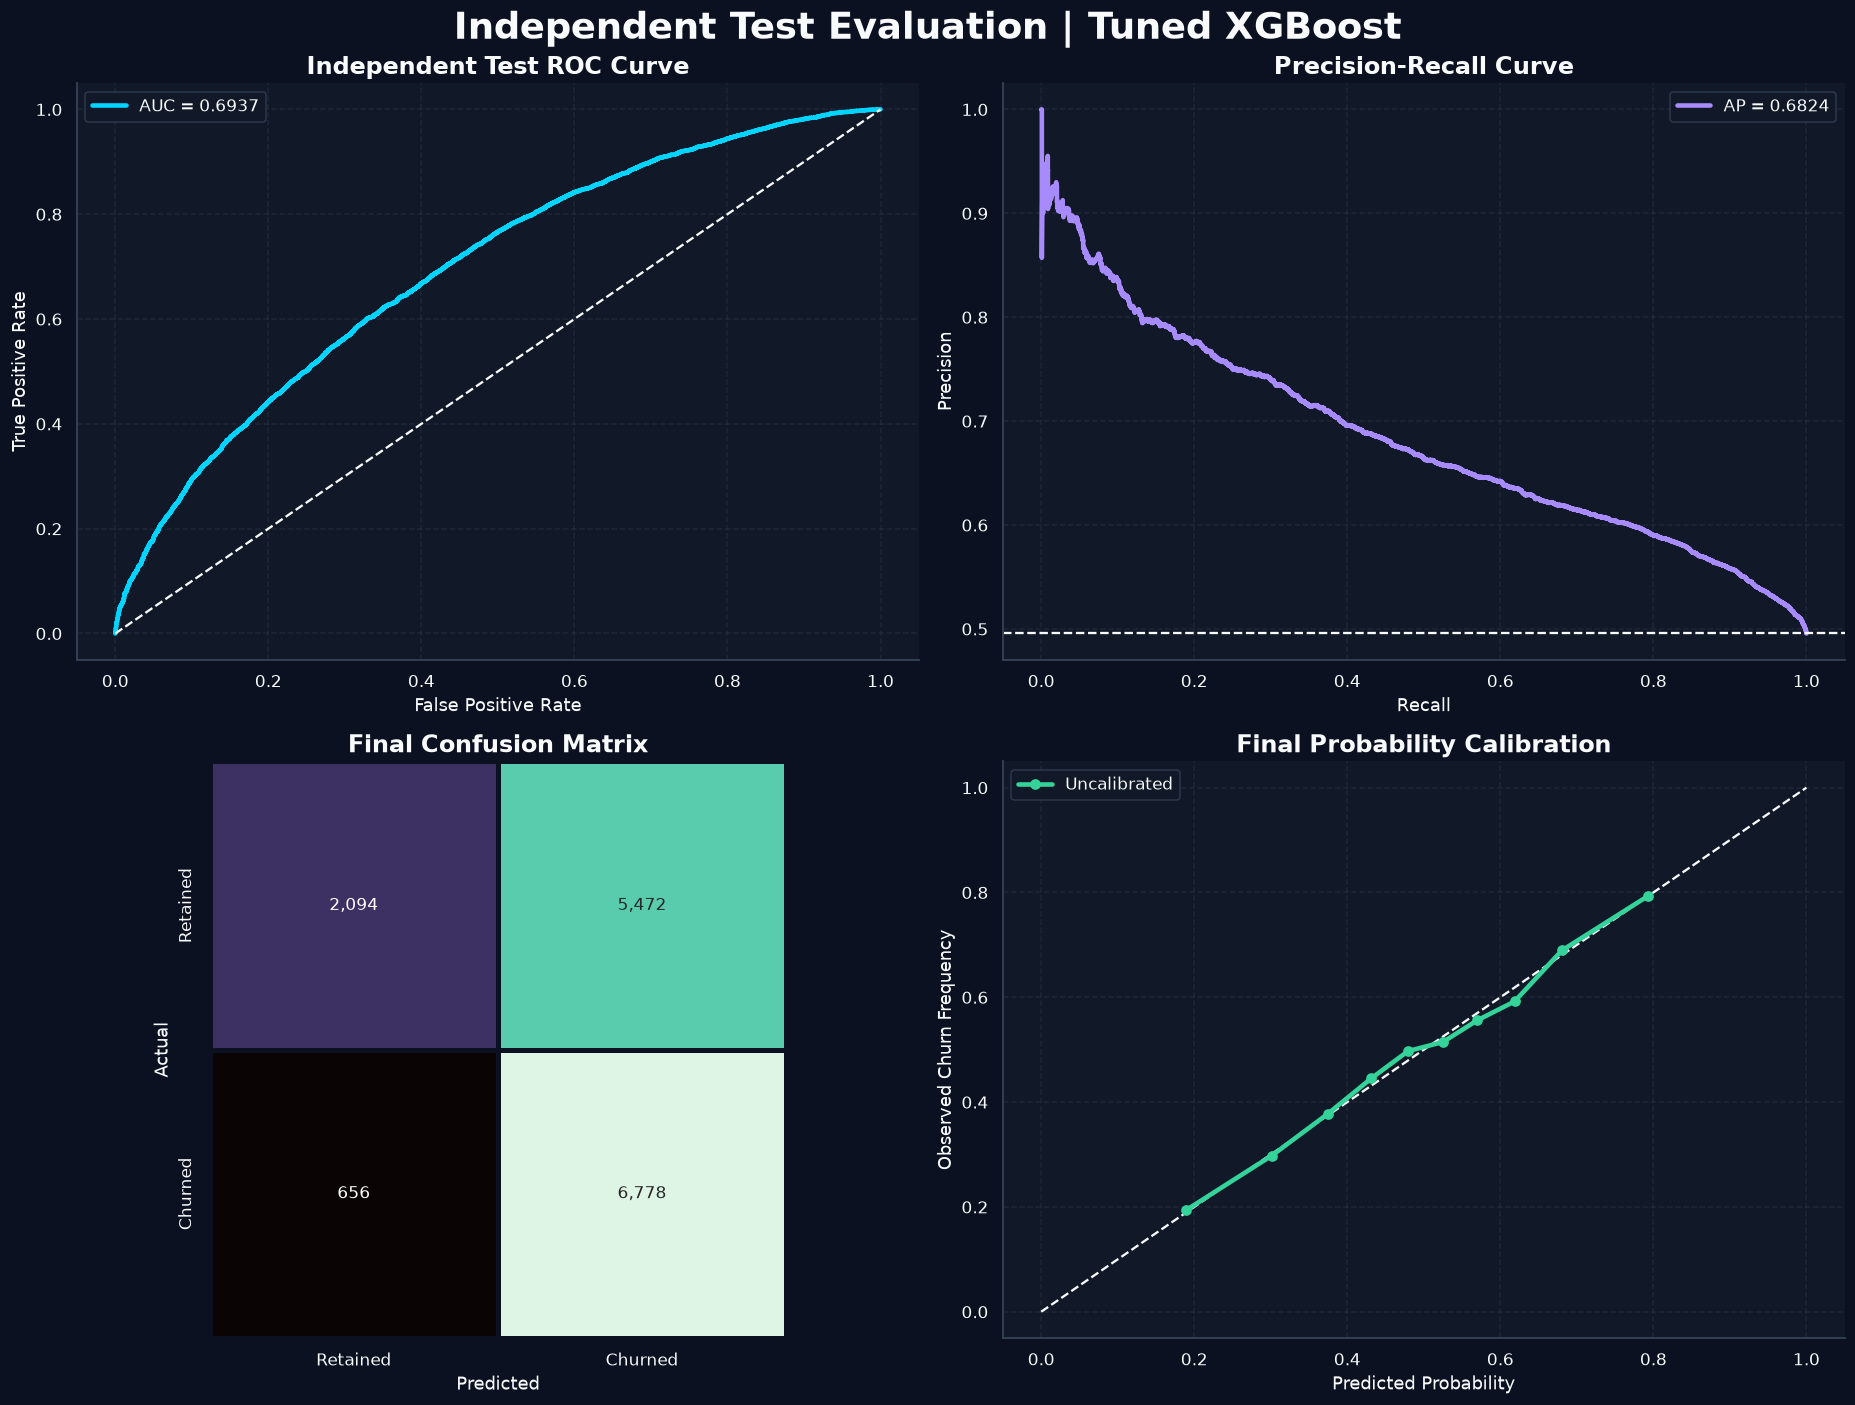

In [172]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(17, 13)
)


# 1. ROC Curve

fpr, tpr, _ = roc_curve(
    y_test,
    test_probabilities
)

axes[0, 0].plot(

    fpr,
    tpr,

    color=CYAN,

    linewidth=3,

    label=f"AUC = {final_test_metrics['ROC_AUC']:.4f}"

)

axes[0, 0].plot(

    [0, 1],
    [0, 1],

    linestyle="--",

    color=TEXT_COLOR

)

axes[0, 0].set_title("Independent Test ROC Curve")

axes[0, 0].set_xlabel("False Positive Rate")

axes[0, 0].set_ylabel("True Positive Rate")

axes[0, 0].legend()


# 2. Precision-Recall Curve

precision, recall, _ = precision_recall_curve(

    y_test,

    test_probabilities

)

axes[0, 1].plot(

    recall,

    precision,

    color=PURPLE,

    linewidth=3,

    label=(

        f"AP = "

        f"{final_test_metrics['Average_Precision']:.4f}"

    )

)

axes[0, 1].axhline(

    y_test.mean(),

    linestyle="--",

    color=TEXT_COLOR

)

axes[0, 1].set_title("Precision-Recall Curve")

axes[0, 1].set_xlabel("Recall")

axes[0, 1].set_ylabel("Precision")

axes[0, 1].legend()


# 3. Confusion Matrix

cm = confusion_matrix(

    y_test,

    test_predictions,

    labels=[0, 1]

)

sns.heatmap(

    cm,

    annot=True,

    fmt=",.0f",

    cmap="mako",

    cbar=False,

    square=True,

    linewidths=2,

    linecolor=BG_COLOR,

    xticklabels=["Retained", "Churned"],

    yticklabels=["Retained", "Churned"],

    ax=axes[1, 0]

)

axes[1, 0].set_title("Final Confusion Matrix")

axes[1, 0].set_xlabel("Predicted")

axes[1, 0].set_ylabel("Actual")


# 4. Calibration Curve

observed, predicted = calibration_curve(

    y_test,

    test_probabilities,

    n_bins=10,

    strategy="quantile"

)

axes[1, 1].plot(

    [0, 1],
    [0, 1],

    linestyle="--",

    color=TEXT_COLOR

)

axes[1, 1].plot(

    predicted,

    observed,

    marker="o",

    color=GREEN,

    linewidth=3,

    label=FINAL_CALIBRATION

)

axes[1, 1].set_title("Final Probability Calibration")

axes[1, 1].set_xlabel("Predicted Probability")

axes[1, 1].set_ylabel("Observed Churn Frequency")

axes[1, 1].legend()


fig.suptitle(

    f"Independent Test Evaluation | {CHAMPION_NAME}",

    fontsize=24,

    fontweight="bold"

)


finish_plot(

    fig,

    "38_final_test_dashboard.png"

)

In [173]:
final_val_probabilities = apply_calibration(

    raw_val_probabilities,

    FINAL_CALIBRATION

)


decision_metrics = evaluate_model(

    y_decision,

    p_decision,

    threshold=FINAL_THRESHOLD

)


final_comparison = pd.DataFrame({

    "Development_Decision_Set": decision_metrics,

    "Independent_Test_Set": final_test_metrics

})


final_comparison["Difference"] = (

    final_comparison["Independent_Test_Set"]

    -

    final_comparison["Development_Decision_Set"]

)


display(final_comparison.round(5))


final_comparison.to_csv(

    REPORTS_DIR / "development_vs_test_comparison.csv"

)

,Development_Decision_Set,Independent_Test_Set,Difference
Accuracy,0.6029,0.5915,-0.0114
Balanced_Accuracy,0.6057,0.5943,-0.0114
Precision,0.5606,0.5533,-0.0073
Recall,0.9184,0.9118,-0.0066
Specificity,0.2929,0.2768,-0.0162
F1,0.6962,0.6887,-0.0076
ROC_AUC,0.7071,0.6937,-0.0135
Average_Precision,0.6950,0.6824,-0.0127
MCC,0.2703,0.2436,-0.0267
Brier_Score,0.2172,0.2207,0.0036


In [174]:
BOOTSTRAP_ITERATIONS = 1000

rng = np.random.default_rng(SEED)

y_test_array = y_test.to_numpy()

bootstrap_results = []


for iteration in tqdm(

    range(BOOTSTRAP_ITERATIONS),

    desc="Bootstrap Evaluation"

):

    sample_indices = rng.integers(

        0,

        len(y_test_array),

        size=len(y_test_array)

    )


    sampled_y = y_test_array[sample_indices]

    sampled_probabilities = test_probabilities[
        sample_indices
    ]


    if np.unique(sampled_y).size < 2:
        continue


    sampled_predictions = (

        sampled_probabilities >= FINAL_THRESHOLD

    ).astype(int)


    bootstrap_results.append({

        "ROC_AUC": roc_auc_score(

            sampled_y,

            sampled_probabilities

        ),

        "Accuracy": accuracy_score(

            sampled_y,

            sampled_predictions

        ),

        "F1": f1_score(

            sampled_y,

            sampled_predictions,

            zero_division=0

        ),

        "Recall": recall_score(

            sampled_y,

            sampled_predictions,

            zero_division=0

        ),

        "Precision": precision_score(

            sampled_y,

            sampled_predictions,

            zero_division=0

        ),

        "Brier_Score": brier_score_loss(

            sampled_y,

            sampled_probabilities

        )

    })


bootstrap_df = pd.DataFrame(
    bootstrap_results
)


confidence_report = pd.DataFrame({

    "Test_Score": pd.Series(final_test_metrics),

    "Bootstrap_Mean": bootstrap_df.mean(),

    "CI_Lower_95": bootstrap_df.quantile(0.025),

    "CI_Upper_95": bootstrap_df.quantile(0.975)

}).loc[bootstrap_df.columns]


display(confidence_report.round(5))


confidence_report.to_csv(

    REPORTS_DIR / "bootstrap_confidence_intervals.csv"

)

Bootstrap Evaluation:   0%|          | 0/1000 [00:00<?, ?it/s]

,Test_Score,Bootstrap_Mean,CI_Lower_95,CI_Upper_95
ROC_AUC,0.6937,0.6936,0.6851,0.7017
Accuracy,0.5915,0.5914,0.5835,0.5995
F1,0.6887,0.6885,0.6813,0.6960
Recall,0.9118,0.9117,0.9052,0.9182
Precision,0.5533,0.5532,0.5445,0.5616
Brier_Score,0.2207,0.2207,0.2184,0.2232


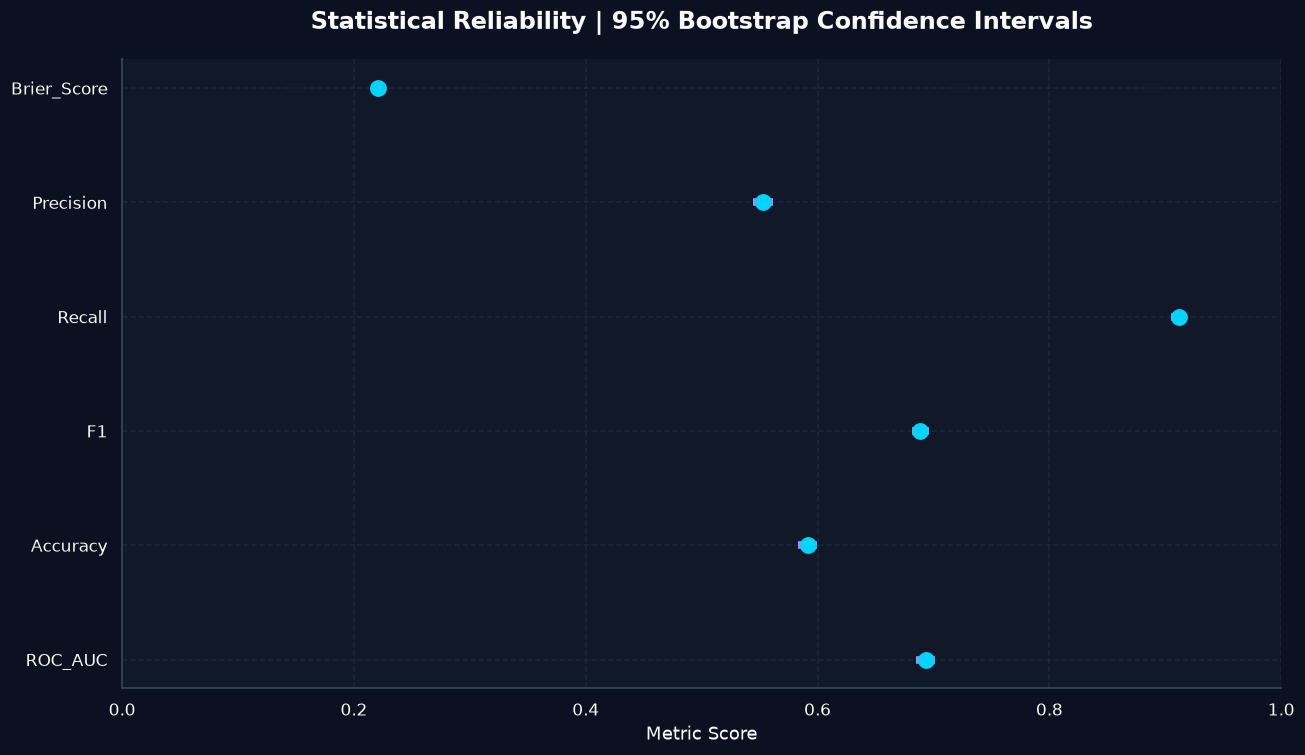

In [175]:
ci_plot = confidence_report.copy()

positions = np.arange(len(ci_plot))

fig, ax = plt.subplots(figsize=(12, 7))


ax.hlines(

    positions,

    ci_plot["CI_Lower_95"],

    ci_plot["CI_Upper_95"],

    color=PURPLE,

    linewidth=5

)


ax.scatter(

    ci_plot["Test_Score"],

    positions,

    color=CYAN,

    s=100,

    zorder=3

)


ax.set_yticks(positions)

ax.set_yticklabels(ci_plot.index)

ax.set_xlim(0, 1)

ax.set_xlabel("Metric Score")

ax.set_title(

    "Statistical Reliability | 95% Bootstrap Confidence Intervals",

    pad=20

)

finish_plot(

    fig,

    "39_bootstrap_confidence_intervals.png"

)

**Independent evaluation.** Test ROC-AUC is 0.6937 (95% bootstrap interval 0.6851–0.7017), with accuracy 59.15%, F1 0.6887, recall 91.18% and precision 55.33%. The model is better than random ranking but has moderate discrimination. Bootstrap intervals describe sampling uncertainty for the fixed model, not future market or retraining uncertainty.

# 22. Explainable Artificial Intelligence

Explainability techniques are used to investigate
the predictive behavior of the final model.

The analysis includes model-agnostic permutation
importance and SHAP-based explanations.

The findings describe model associations and do not
establish causal effects on customer churn.

In [176]:
explain_raw = X_val_raw.sample(

    n=min(1500, len(X_val_raw)),

    random_state=SEED

).copy()


explain_y = y_val.loc[
    explain_raw.index
]


def predict_final_probability(raw_data):

    probabilities = predict_raw_probability(
        raw_data
    )

    return apply_calibration(

        probabilities,

        FINAL_CALIBRATION

    )


base_explain_auc = roc_auc_score(

    explain_y,

    predict_final_probability(explain_raw)

)


rng = np.random.default_rng(SEED)

final_importance_results = []


for feature in tqdm(

    explain_raw.columns,

    desc="Final System Explainability"

):

    importance_scores = []


    for repeat in range(3):

        shuffled = explain_raw.copy()

        shuffled[feature] = rng.permutation(

            shuffled[feature].to_numpy()

        )


        shuffled_auc = roc_auc_score(

            explain_y,

            predict_final_probability(shuffled)

        )


        importance_scores.append(

            base_explain_auc - shuffled_auc

        )


    final_importance_results.append({

        "Feature": feature,

        "Importance": np.mean(importance_scores),

        "Std": np.std(importance_scores, ddof=1)

    })


final_importance = (

    pd.DataFrame(final_importance_results)

    .sort_values("Importance", ascending=False)

    .reset_index(drop=True)

)


display(final_importance.head(20).round(6))


final_importance.to_csv(

    REPORTS_DIR / "final_system_feature_importance.csv",

    index=False

)

Final System Explainability:   0%|          | 0/83 [00:00<?, ?it/s]

,Feature,Importance,Std
0,months,0.0402,0.0029
1,change_mou,0.0321,0.0020
2,eqpdays,0.0307,0.0071
3,totmrc_Mean,0.0164,0.0055
4,mou_Mean,0.0089,0.0024
5,uniqsubs,0.0085,0.0023
6,lor,0.0076,0.0011
7,actvsubs,0.0065,0.0011
8,avgqty,0.0059,0.0009
9,avgmou,0.0058,0.0020


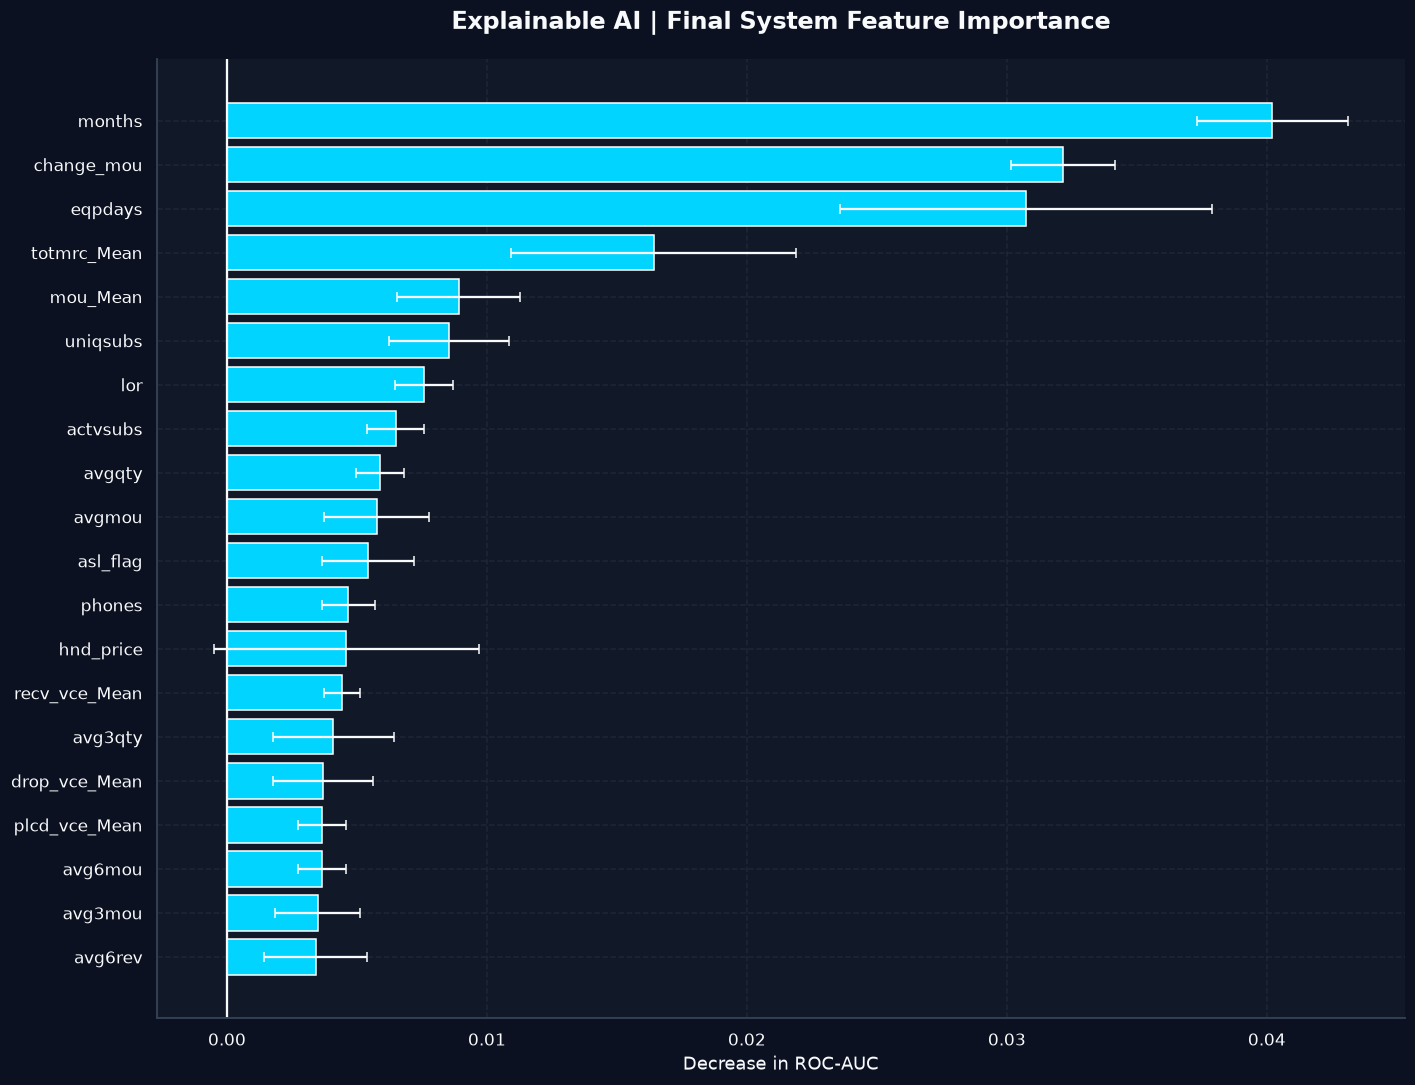

In [177]:
importance_plot = (

    final_importance

    .head(20)

    .sort_values("Importance")

)


fig, ax = plt.subplots(figsize=(13, 10))


ax.barh(

    importance_plot["Feature"],

    importance_plot["Importance"],

    xerr=importance_plot["Std"],

    color=[

        CYAN if value >= 0 else RED

        for value in importance_plot["Importance"]

    ],

    capsize=3,

    error_kw={"ecolor": TEXT_COLOR}

)


ax.axvline(0, color=TEXT_COLOR)


ax.set_title(

    "Explainable AI | Final System Feature Importance",

    pad=20

)


ax.set_xlabel("Decrease in ROC-AUC")


finish_plot(

    fig,

    "40_final_system_feature_importance.png"

)

In [178]:
import shap

from scipy import sparse


if CHAMPION_NAME in [

    "Equal Soft Voting",

    "Weighted Soft Voting",

    "OOF Stacking"

]:

    # Explain the LightGBM component of the ensemble

    SHAP_MODEL_NAME = "LightGBM"

    shap_pipeline = ensemble_full_models[
        SHAP_MODEL_NAME
    ]

    _, shap_inputs = get_ensemble_inputs(
        SHAP_MODEL_NAME
    )

    SHAP_SCOPE = "Ensemble component"


elif CHAMPION_NAME.startswith("Tuned "):

    SHAP_MODEL_NAME = CHAMPION_NAME.replace(
        "Tuned ", "", 1
    )

    shap_pipeline = optimized_models[
        SHAP_MODEL_NAME
    ]

    shap_inputs = X_dev_val

    SHAP_SCOPE = "Champion base model"


else:

    SHAP_MODEL_NAME = CHAMPION_NAME

    shap_pipeline = trained_models[
        CHAMPION_NAME
    ]

    shap_inputs = X_val

    SHAP_SCOPE = "Champion base model"


shap_sample = shap_inputs.sample(

    n=min(500, len(shap_inputs)),

    random_state=SEED

)


shap_preprocessing = shap_pipeline[:-1]

shap_model = shap_pipeline.named_steps["model"]

shap_transformed = shap_preprocessing.transform(

    shap_sample

)


if sparse.issparse(shap_transformed):

    shap_transformed = shap_transformed.toarray()


if SHAP_MODEL_NAME == "CatBoost":

    shap_feature_names = shap_sample.columns.tolist()


else:

    shap_feature_names = (

        shap_preprocessing

        .get_feature_names_out()

        .tolist()

    )


shap_data = pd.DataFrame(

    shap_transformed,

    columns=shap_feature_names

)


print("SHAP Model:", SHAP_MODEL_NAME)

print("Explanation Scope:", SHAP_SCOPE)

print("SHAP Data Shape:", shap_data.shape)

SHAP Model: XGBoost
Explanation Scope: Champion base model
SHAP Data Shape: (500, 151)


In [179]:
if SHAP_MODEL_NAME == "Logistic Regression":

    shap_explainer = shap.LinearExplainer(

        shap_model,

        shap_data

    )


else:

    shap_explainer = shap.TreeExplainer(

        shap_model

    )


shap_values = shap_explainer(
    shap_data
)


# Handle binary classifiers with two output classes

if shap_values.values.ndim == 3:

    shap_values = shap_values[:, :, 1]


print("SHAP calculations completed.")

print("SHAP values shape:", shap_values.values.shape)

SHAP calculations completed.
SHAP values shape: (500, 151)


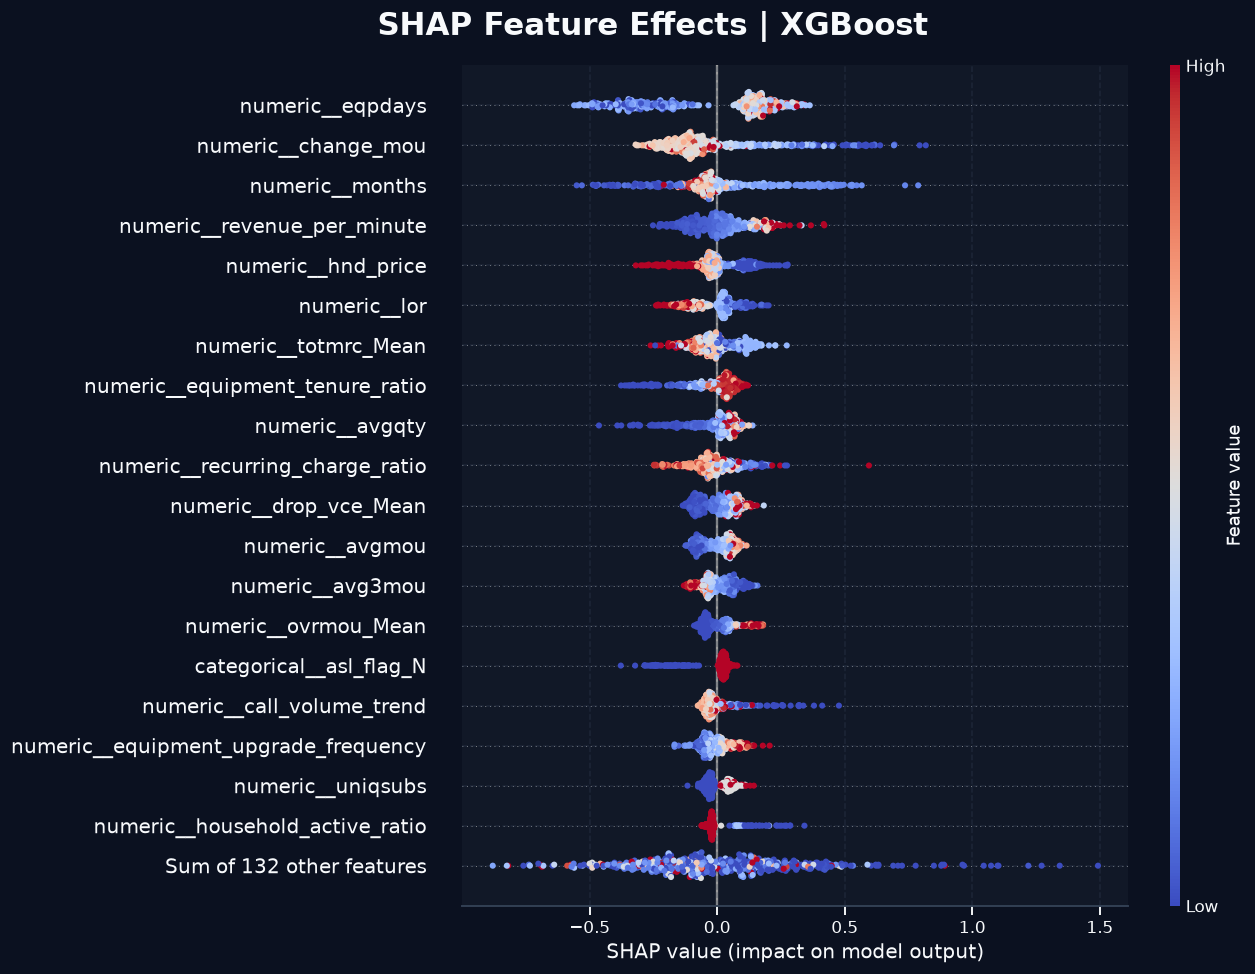

In [180]:
shap.plots.beeswarm(

    shap_values,

    max_display=20,

    show=False,

    plot_size=(12, 9),

    color=plt.get_cmap("coolwarm"),

    color_bar=True

)


fig = plt.gcf()

fig.patch.set_facecolor(BG_COLOR)


for ax in fig.axes:

    ax.set_facecolor(PANEL_COLOR)

    ax.tick_params(colors=TEXT_COLOR)

    ax.xaxis.label.set_color(TEXT_COLOR)

    ax.yaxis.label.set_color(TEXT_COLOR)


fig.suptitle(

    f"SHAP Feature Effects | {SHAP_MODEL_NAME}",

    color=TEXT_COLOR,

    fontsize=20,

    fontweight="bold"

)


finish_plot(

    fig,

    "41_shap_beeswarm.png"

)

,Feature,Mean_Absolute_SHAP
62,numeric__eqpdays,0.2295
7,numeric__change_mou,0.1584
38,numeric__months,0.1455
71,numeric__revenue_per_minute,0.0876
53,numeric__hnd_price,0.0714
58,numeric__lor,0.0695
1,numeric__totmrc_Mean,0.0679
73,numeric__equipment_tenure_ratio,0.0658
46,numeric__avgqty,0.0643
72,numeric__recurring_charge_ratio,0.0635


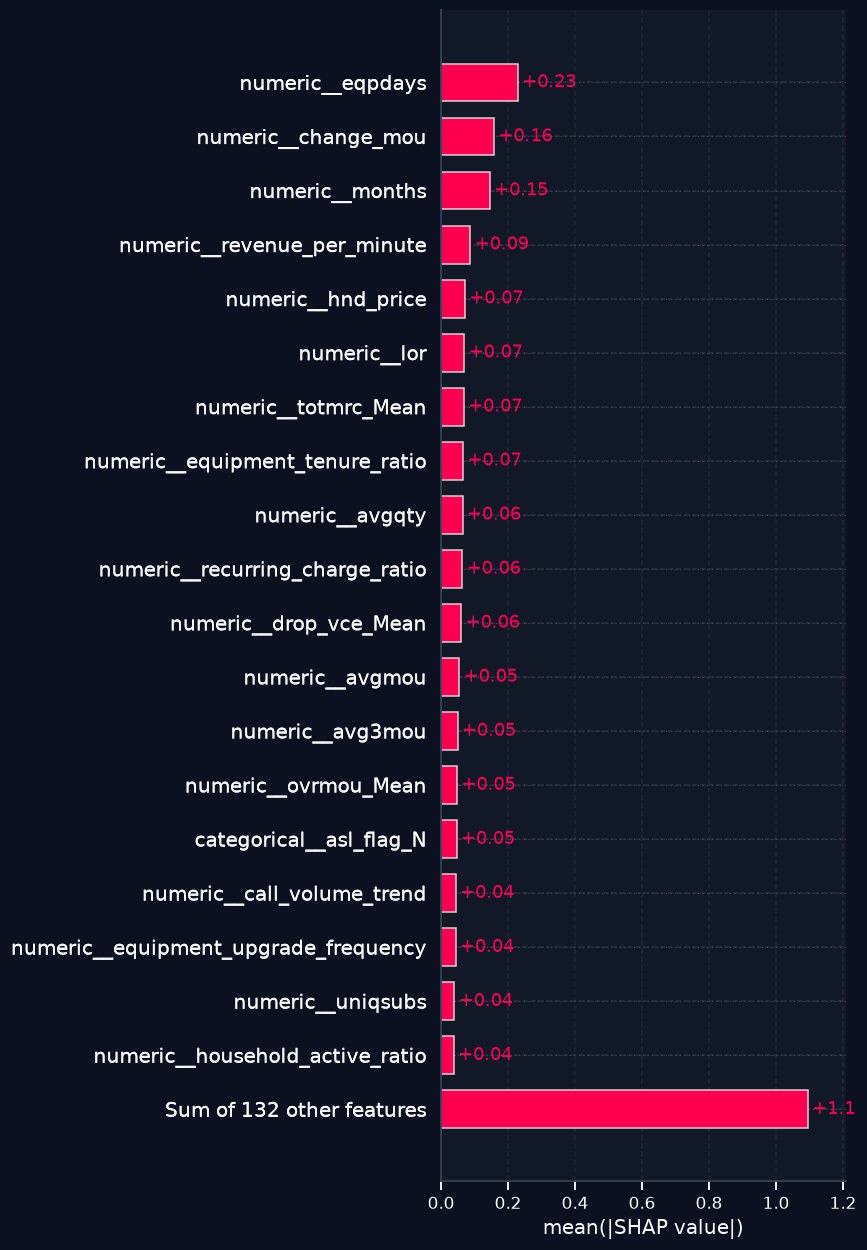

In [181]:
shap_global_importance = pd.DataFrame({

    "Feature": shap_feature_names,

    "Mean_Absolute_SHAP": np.abs(

        shap_values.values

    ).mean(axis=0)

}).sort_values(

    "Mean_Absolute_SHAP",

    ascending=False

)


display(
    shap_global_importance.head(20)
)


shap_global_importance.to_csv(

    REPORTS_DIR / "shap_global_importance.csv",

    index=False

)


shap.plots.bar(

    shap_values,

    max_display=20,

    show=False

)


fig = plt.gcf()

fig.patch.set_facecolor(BG_COLOR)


for ax in fig.axes:

    ax.set_facecolor(PANEL_COLOR)

    ax.tick_params(colors=TEXT_COLOR)


finish_plot(

    fig,

    "42_shap_global_importance.png"

)

Explanation Scope: Champion base model
Base Model Probability: 0.9206


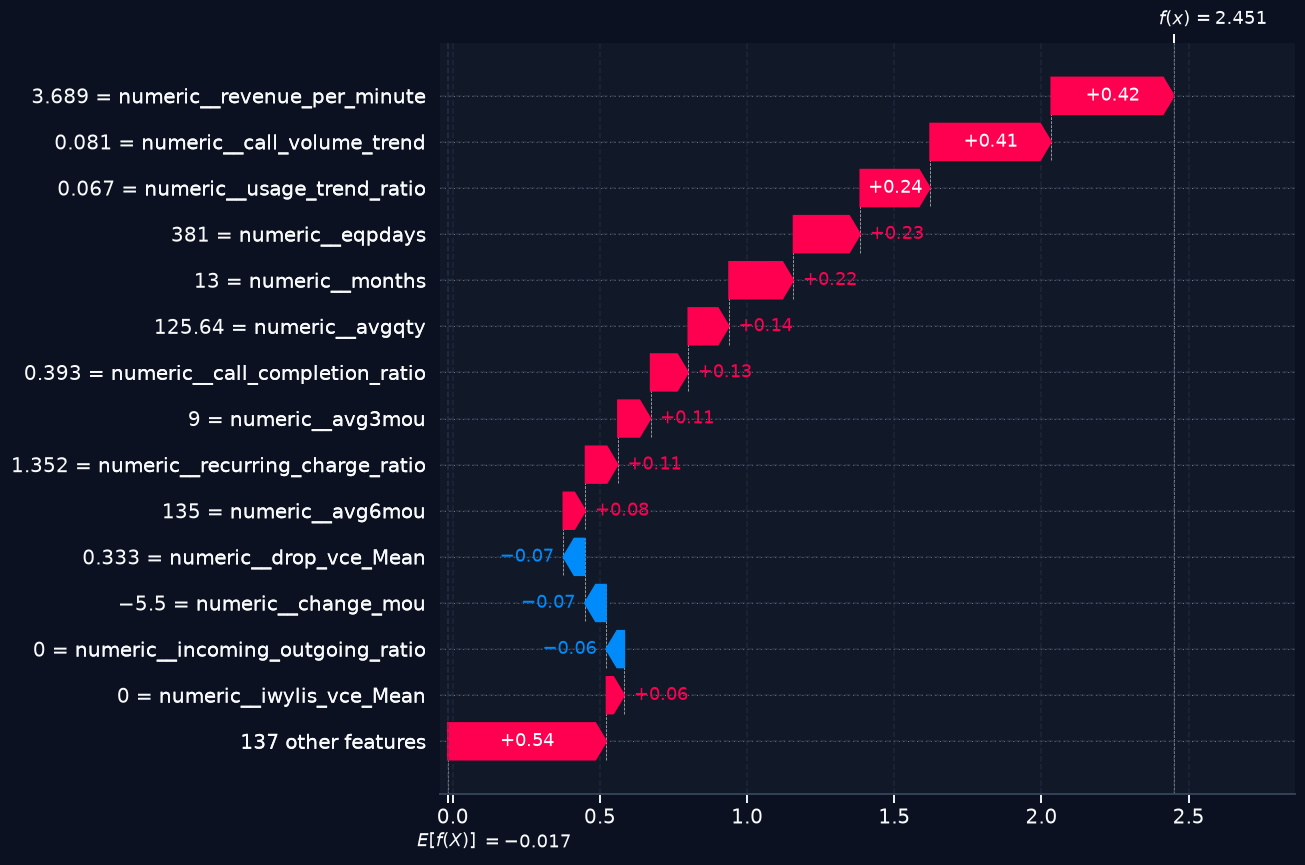

In [182]:
shap_sample_probabilities = shap_pipeline.predict_proba(

    shap_sample

)[:, 1]


customer_position = int(

    np.argmax(shap_sample_probabilities)

)


print("Explanation Scope:", SHAP_SCOPE)

print(

    "Base Model Probability:",

    f"{shap_sample_probabilities[customer_position]:.4f}"

)


shap.plots.waterfall(

    shap_values[customer_position],

    max_display=15,

    show=False

)


fig = plt.gcf()

fig.set_size_inches(12, 8)

fig.patch.set_facecolor(BG_COLOR)


for ax in fig.axes:

    ax.set_facecolor(PANEL_COLOR)

    ax.tick_params(colors=TEXT_COLOR)


finish_plot(

    fig,

    "43_shap_customer_waterfall.png"

)

In [183]:
ranking_data = pd.DataFrame({

    "Actual_Churn": y_test.to_numpy(),

    "Churn_Probability": test_probabilities

})


ranking_data = (

    ranking_data

    .sort_values(

        "Churn_Probability",

        ascending=False,

        kind="stable"

    )

    .reset_index(drop=True)

)


ranking_data["Population_Fraction"] = (

    np.arange(1, len(ranking_data) + 1)

    / len(ranking_data)

)


ranking_data["Cumulative_Churners"] = (

    ranking_data["Actual_Churn"].cumsum()

)


ranking_data["Cumulative_Gain"] = (

    ranking_data["Cumulative_Churners"]

    / ranking_data["Actual_Churn"].sum()

)


ranking_data["Lift"] = (

    ranking_data["Cumulative_Gain"]

    / ranking_data["Population_Fraction"]

)


lift_results = []


for fraction in [

    0.05, 0.10, 0.20,

    0.30, 0.40, 0.50

]:

    lift_results.append(

        evaluate_top_k(

            y_test,

            test_probabilities,

            fraction=fraction

        )

    )


final_lift_report = pd.DataFrame(
    lift_results
)


display(final_lift_report.round(5))


final_lift_report.to_csv(

    REPORTS_DIR / "final_test_lift_analysis.csv",

    index=False

)

,Target_Fraction,Targeted_Customers,Captured_Churners,Precision_at_K,Recall_at_K,Lift_at_K
0,0.0500,750,633,0.8440,0.0852,1.7030
1,0.1000,1500,1189,0.7927,0.1599,1.5994
2,0.2000,3000,2223,0.7410,0.2990,1.4952
3,0.3000,4500,3111,0.6913,0.4185,1.3949
4,0.4000,6000,3945,0.6575,0.5307,1.3267
5,0.5000,7500,4717,0.6289,0.6345,1.2690


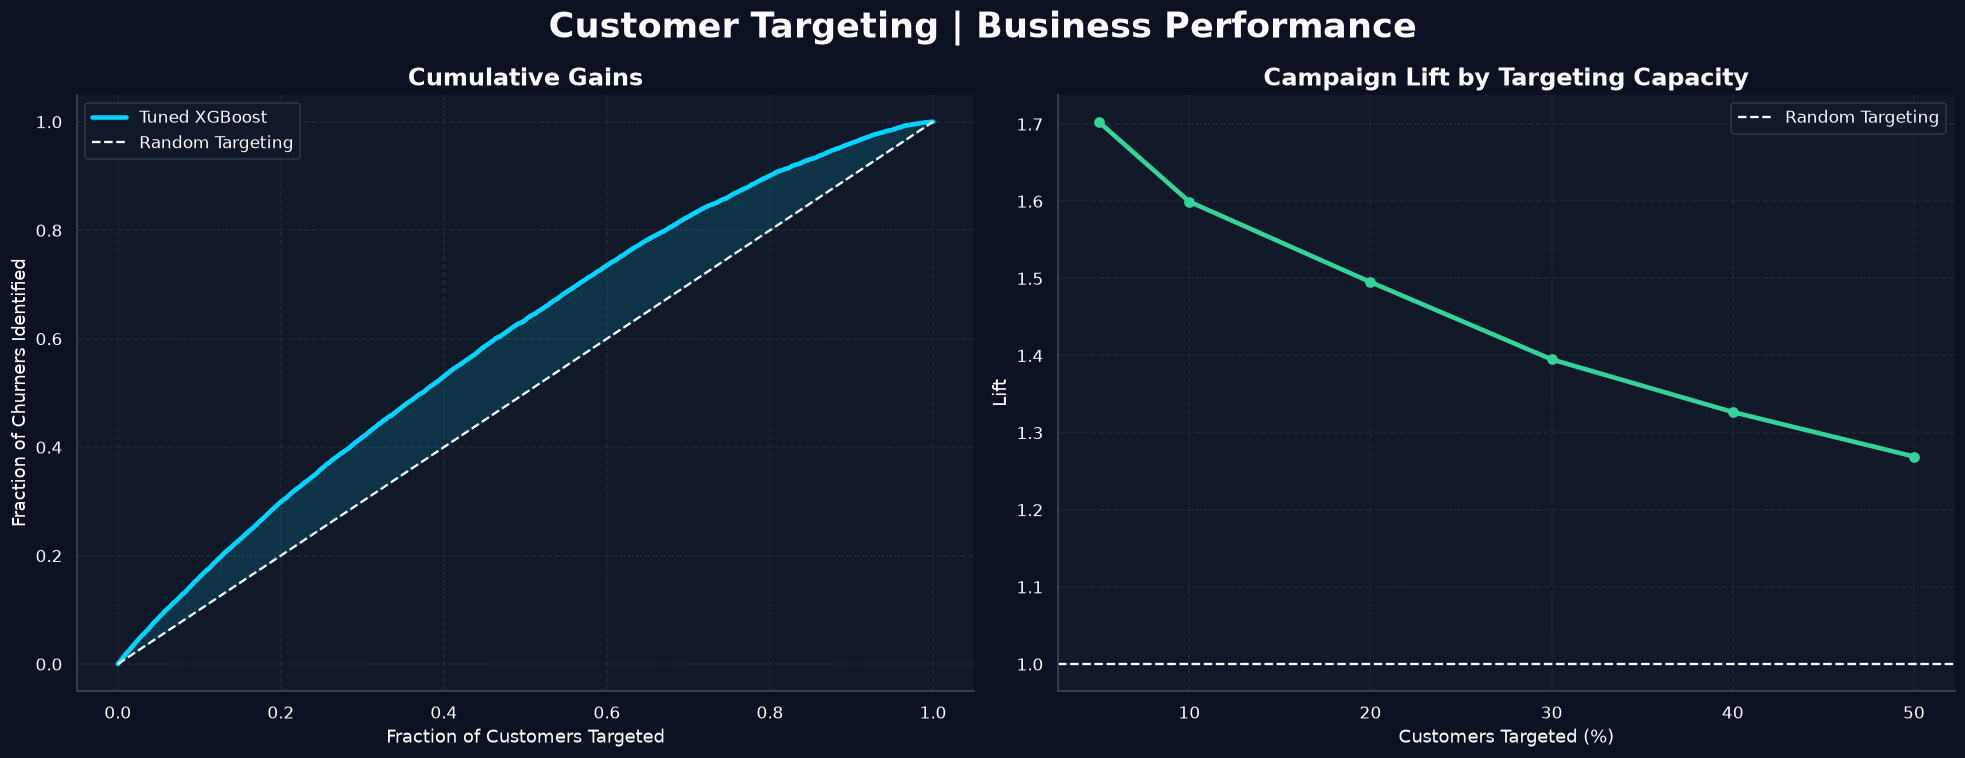

In [184]:
fig, axes = plt.subplots(

    1, 2,

    figsize=(18, 7)

)


axes[0].plot(

    ranking_data["Population_Fraction"],

    ranking_data["Cumulative_Gain"],

    color=CYAN,

    linewidth=3,

    label=CHAMPION_NAME

)


axes[0].plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    color=TEXT_COLOR,

    label="Random Targeting"

)


axes[0].fill_between(

    ranking_data["Population_Fraction"],

    ranking_data["Population_Fraction"],

    ranking_data["Cumulative_Gain"],

    color=CYAN,

    alpha=0.15

)


axes[0].set_title("Cumulative Gains")

axes[0].set_xlabel("Fraction of Customers Targeted")

axes[0].set_ylabel("Fraction of Churners Identified")

axes[0].legend()


axes[1].plot(

    final_lift_report["Target_Fraction"] * 100,

    final_lift_report["Lift_at_K"],

    color=GREEN,

    linewidth=3,

    marker="o"

)


axes[1].axhline(

    1,

    linestyle="--",

    color=TEXT_COLOR,

    label="Random Targeting"

)


axes[1].set_title("Campaign Lift by Targeting Capacity")

axes[1].set_xlabel("Customers Targeted (%)")

axes[1].set_ylabel("Lift")

axes[1].legend()


fig.suptitle(

    "Customer Targeting | Business Performance",

    fontsize=23,

    fontweight="bold"

)


finish_plot(

    fig,

    "44_lift_and_gains.png"

)

**Campaign interpretation.** Risk ranking at the top 20% achieved 74.10% precision and 1.4952× lift in the recorded test set. This is historical targeting performance, not evidence that those customers can actually be retained.

# 23. Revenue-Aware Retention Decision System

The proposed system combines predicted churn risk with
historical customer revenue and estimated intervention
economics.

Customers are prioritized according to expected net
incremental contribution under transparent business
assumptions.

The system is designed as a decision-support prototype,
rather than an automated causal treatment allocation model.

In [185]:
customer_intelligence = pd.DataFrame({

    "Customer_ID": test_df.loc[
        X_test_raw.index, KEY
    ],

    "Actual_Churn": y_test,

    "Churn_Probability": test_probabilities,

    "Predicted_Churn": test_predictions,

    "Monthly_Revenue": X_test_raw["rev_Mean"],

    "Tenure_Months": X_test_raw["months"],

    "Equipment_Age_Days": X_test_raw["eqpdays"]

})


customer_intelligence["Revenue_Valid"] = (

    customer_intelligence["Monthly_Revenue"].notna()

    &

    (customer_intelligence["Monthly_Revenue"] >= 0)

)


customer_intelligence["Monthly_Revenue"] = (

    customer_intelligence["Monthly_Revenue"]

    .where(customer_intelligence["Revenue_Valid"])

)


customer_intelligence["Monthly_Revenue_Exposure"] = (

    customer_intelligence["Churn_Probability"]

    *

    customer_intelligence["Monthly_Revenue"]

)


print("Customer Intelligence Records:", len(customer_intelligence))

print(

    "Customers with unknown or negative revenue:",

    (~customer_intelligence["Revenue_Valid"]).sum()

)


display(customer_intelligence.head(10))

Customer Intelligence Records: 15000
Customers with unknown or negative revenue: 52


,Customer_ID,Actual_Churn,Churn_Probability,Predicted_Churn,Monthly_Revenue,Tenure_Months,Equipment_Age_Days,Revenue_Valid,Monthly_Revenue_Exposure
96535,1096536,0,0.2675,0,10.0000,7,208.0000,True,2.6754
77868,1077869,0,0.1270,0,54.4400,7,217.0000,True,6.9128
26375,1026376,0,0.6365,1,38.8375,26,411.0000,True,24.7202
18584,1018585,1,0.4016,1,344.9275,27,128.0000,True,138.5093
89070,1089071,0,0.1078,0,38.9900,9,28.0000,True,4.2048
98872,1098873,0,0.6241,1,79.9850,33,617.0000,True,49.9176
81443,1081444,0,0.5314,1,61.7600,13,374.0000,True,32.8223
42872,1042873,1,0.3392,1,36.6650,21,118.0000,True,12.4374
14139,1014140,1,0.3585,1,17.3800,29,871.0000,True,6.2314
65718,1065719,1,0.5723,1,30.5150,12,350.0000,True,17.4646


In [186]:
revenue_cutoff = (

    original_train["rev_Mean"]

    .where(original_train["rev_Mean"] >= 0)

    .quantile(0.75)

)


customer_intelligence["Risk_Segment"] = np.where(

    customer_intelligence["Churn_Probability"]

    >= FINAL_THRESHOLD,

    "High Risk",

    "Lower Risk"

)


customer_intelligence["Value_Segment"] = np.select(

    [

        ~customer_intelligence["Revenue_Valid"],

        customer_intelligence["Monthly_Revenue"]

        >= revenue_cutoff

    ],

    [

        "Unknown Value",

        "High Value"

    ],

    default="Standard Value"

)


conditions = [

    customer_intelligence["Value_Segment"]
    .eq("Unknown Value"),

    customer_intelligence["Risk_Segment"]
    .eq("High Risk")

    &

    customer_intelligence["Value_Segment"]
    .eq("High Value"),

    customer_intelligence["Risk_Segment"]
    .eq("High Risk")

    &

    customer_intelligence["Value_Segment"]
    .eq("Standard Value"),

    customer_intelligence["Risk_Segment"]
    .eq("Lower Risk")

    &

    customer_intelligence["Value_Segment"]
    .eq("High Value")

]


customer_intelligence["Priority_Segment"] = np.select(

    conditions,

    [

        "Manual Revenue Review",

        "Priority Retention",

        "Cost-Effective Retention",

        "Loyalty Development"

    ],

    default="Routine Monitoring"

)


segment_report = (

    customer_intelligence

    .groupby("Priority_Segment")

    .agg(

        Customers=("Customer_ID", "size"),

        Mean_Risk=("Churn_Probability", "mean"),

        Mean_Revenue=("Monthly_Revenue", "mean"),

        Expected_Exposure=("Monthly_Revenue_Exposure", "sum")

    )

    .sort_values("Expected_Exposure", ascending=False)

)


display(segment_report.round(3))

,Customers,Mean_Risk,Mean_Revenue,Expected_Exposure
Priority_Segment,,,,
Cost-Effective Retention,9156,0.5580,39.6820,"201,445.4590"
Priority Retention,3046,0.5410,115.6940,"190,049.4200"
Routine Monitoring,2067,0.2300,41.9630,"20,043.2280"
Loyalty Development,679,0.2580,106.8880,"18,809.7390"
Manual Revenue Review,52,0.7170,NaN,0.0000


In [187]:
usage_ratio = safe_divide(

    X_test_raw["avg3mou"],

    X_test_raw["avg6mou"]

)


customer_intelligence["Usage_Trend_Ratio"] = usage_ratio


def recommend_action(row):

    if not row["Revenue_Valid"]:

        return "Review Missing Revenue Data"


    if row["Risk_Segment"] != "High Risk":

        return "Routine Engagement and Monitoring"


    if (

        pd.notna(row["Equipment_Age_Days"])

        and row["Equipment_Age_Days"] > 730

    ):

        return "Evaluate Device Upgrade Offer"


    if (

        pd.notna(row["Usage_Trend_Ratio"])

        and row["Usage_Trend_Ratio"] <= 0.80

    ):

        return "Evaluate Personalized Usage Plan"


    if row["Value_Segment"] == "High Value":

        return "Priority Retention Consultation"


    return "Proactive Customer Support"


customer_intelligence["Recommended_Action"] = (

    customer_intelligence.apply(

        recommend_action,

        axis=1

    )

)


display(

    customer_intelligence["Recommended_Action"]

    .value_counts()

)

Recommended_Action
Proactive Customer Support           5983
Routine Engagement and Monitoring    2746
Priority Retention Consultation      2620
Evaluate Personalized Usage Plan     2048
Evaluate Device Upgrade Offer        1551
Review Missing Revenue Data            52
Name: count, dtype: int64

In [188]:
def calculate_expected_contribution(

    customers,

    success_rate,

    retention_months,

    contribution_margin,

    contact_cost,

    offer_cost

):

    return (

        customers["Churn_Probability"]

        *

        success_rate

        *

        customers["Monthly_Revenue"]

        *

        retention_months

        *

        contribution_margin

        -

        contact_cost

        -

        offer_cost

    )


customer_intelligence["Expected_Net_Contribution"] = (

    calculate_expected_contribution(

        customer_intelligence,

        success_rate=BUSINESS_CONFIG["retention_success_rate"],

        retention_months=BUSINESS_CONFIG["retention_months"],

        contribution_margin=BUSINESS_CONFIG["contribution_margin"],

        contact_cost=BUSINESS_CONFIG["campaign_contact_cost"],

        offer_cost=BUSINESS_CONFIG["retention_offer_cost"]

    )

)


campaign_budget_capacity = int(

    len(customer_intelligence)

    *

    BUSINESS_CONFIG["campaign_capacity"]

)


eligible_customers = (

    customer_intelligence.loc[

        customer_intelligence["Revenue_Valid"]

        &

        (

            customer_intelligence["Expected_Net_Contribution"]

            > 0

        )

    ]

    .sort_values(

        "Expected_Net_Contribution",

        ascending=False

    )

)


selected_campaign = (

    eligible_customers

    .head(campaign_budget_capacity)

    .copy()

)


customer_intelligence["Campaign_Selected"] = (

    customer_intelligence["Customer_ID"]

    .isin(selected_campaign["Customer_ID"])

)


customer_intelligence["Final_Campaign_Action"] = np.where(

    customer_intelligence["Campaign_Selected"],

    "Contact for Retention Assessment",

    "No Paid Intervention"

)


print("Campaign Capacity:", campaign_budget_capacity)

print("Eligible Customers:", len(eligible_customers))

print("Selected Customers:", len(selected_campaign))


display(

    selected_campaign[

        [

            "Customer_ID",

            "Churn_Probability",

            "Monthly_Revenue",

            "Expected_Net_Contribution",

            "Recommended_Action"

        ]

    ].head(20)

)

Campaign Capacity: 3000
Eligible Customers: 3394
Selected Customers: 3000


,Customer_ID,Churn_Probability,Monthly_Revenue,Expected_Net_Contribution,Recommended_Action
93989,1093990,0.6152,680.8175,206.1842,Priority Retention Consultation
76358,1076359,0.4616,861.1050,194.6246,Priority Retention Consultation
49039,1049040,0.6148,575.7500,171.1567,Priority Retention Consultation
44942,1044943,0.7191,465.6400,160.8022,Priority Retention Consultation
35015,1035016,0.6488,474.1300,146.1007,Priority Retention Consultation
40728,1040729,0.4838,629.5050,144.4563,Priority Retention Consultation
96450,1096451,0.6434,457.2100,138.8439,Priority Retention Consultation
42738,1042739,0.5078,558.9325,133.2668,Priority Retention Consultation
34759,1034760,0.7122,387.7775,129.1406,Priority Retention Consultation
62476,1062477,0.4585,587.0350,125.3596,Priority Retention Consultation


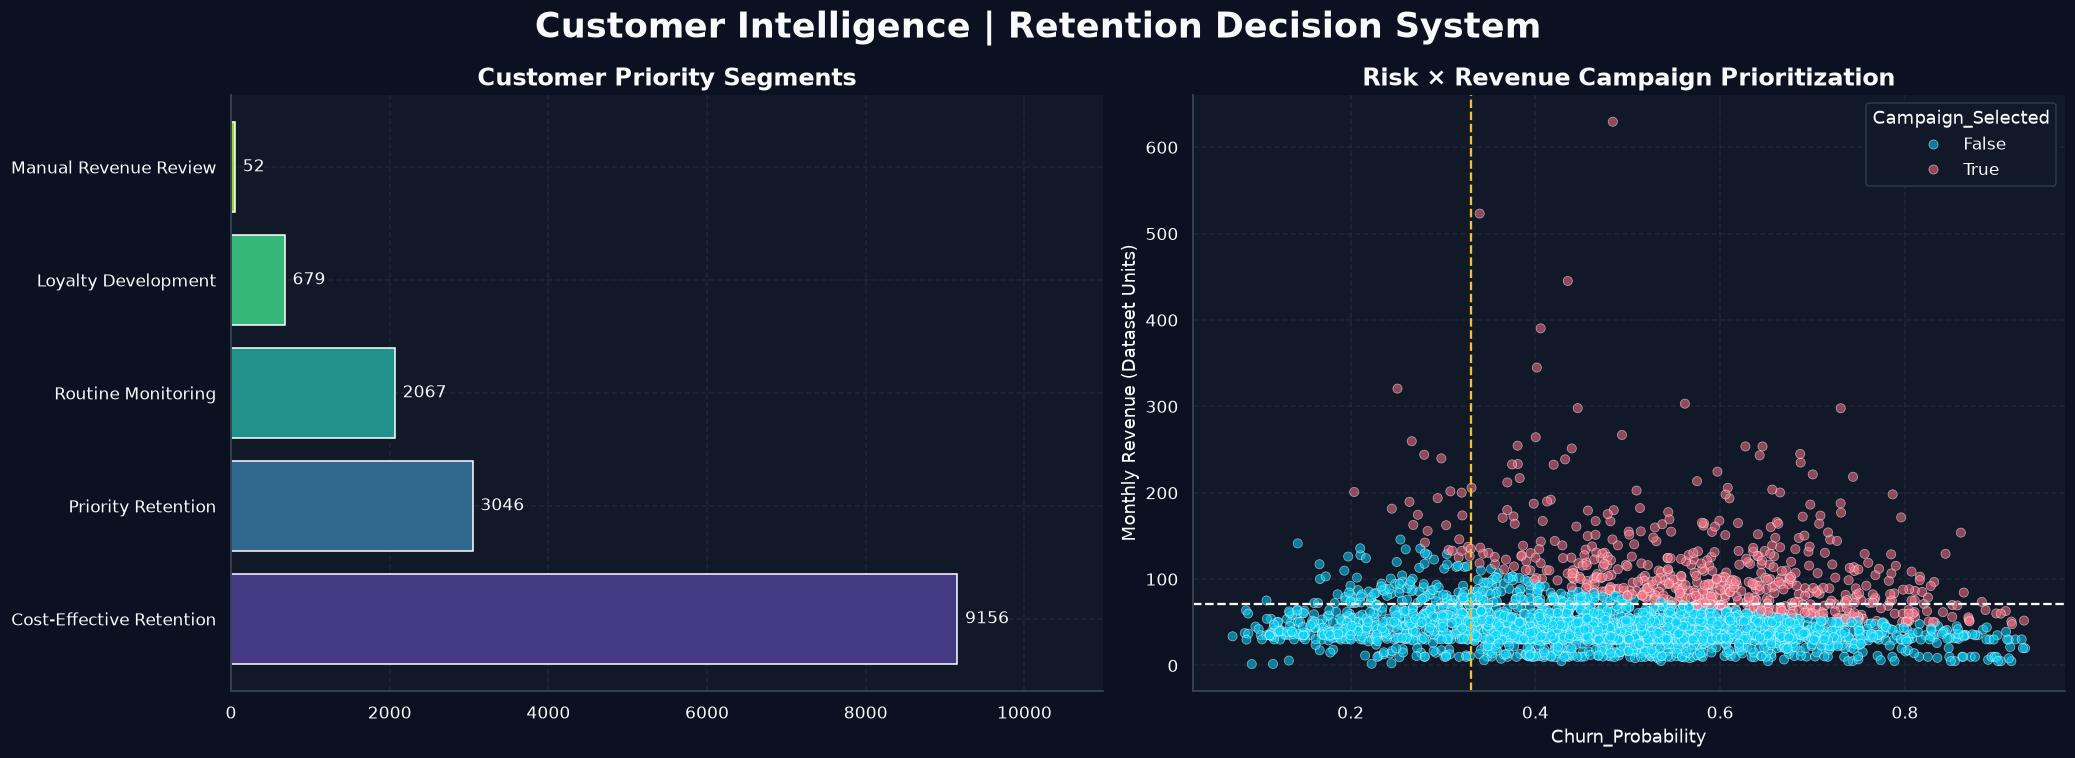

In [189]:
fig, axes = plt.subplots(

    1, 2,

    figsize=(19, 7)

)


segment_counts = (

    customer_intelligence["Priority_Segment"]

    .value_counts()

)


bars = axes[0].barh(

    segment_counts.index,

    segment_counts.values,

    color=sns.color_palette(

        "viridis",

        len(segment_counts)

    )

)


axes[0].bar_label(

    bars,

    fmt="%.0f",

    padding=5

)


axes[0].set_title("Customer Priority Segments")

axes[0].margins(x=0.20)


scatter_data = (

    customer_intelligence

    .dropna(subset=["Monthly_Revenue"])

    .sample(

        n=min(

            3000,

            customer_intelligence["Monthly_Revenue"].notna().sum()

        ),

        random_state=SEED

    )

)


sns.scatterplot(

    data=scatter_data,

    x="Churn_Probability",

    y="Monthly_Revenue",

    hue="Campaign_Selected",

    palette={

        True: RED,

        False: CYAN

    },

    alpha=0.55,

    ax=axes[1]

)


axes[1].axvline(

    FINAL_THRESHOLD,

    color=GOLD,

    linestyle="--"

)


axes[1].axhline(

    revenue_cutoff,

    color=TEXT_COLOR,

    linestyle="--"

)


axes[1].set_title("Risk × Revenue Campaign Prioritization")

axes[1].set_ylabel("Monthly Revenue (Dataset Units)")


fig.suptitle(

    "Customer Intelligence | Retention Decision System",

    fontsize=23,

    fontweight="bold"

)


finish_plot(

    fig,

    "45_customer_intelligence_dashboard.png"

)

In [190]:
customer_intelligence.to_csv(

    PREDICTIONS_DIR / "customer_intelligence_results.csv",

    index=False

)


selected_campaign[

    [

        "Customer_ID",

        "Churn_Probability",

        "Monthly_Revenue",

        "Priority_Segment",

        "Expected_Net_Contribution",

        "Recommended_Action"

    ]

].to_csv(

    PREDICTIONS_DIR / "retention_campaign_candidates.csv",

    index=False

)


segment_report.to_csv(

    REPORTS_DIR / "final_customer_segmentation.csv"

)


print("Customer intelligence outputs exported.")

Customer intelligence outputs exported.


## Financial impact and scenario analysis

The campaign simulation assumes intervention costs, incremental retention success among otherwise-churning customers, additional retention duration and contribution margin. It excludes implementation and ongoing infrastructure costs. The financial comparison is model-based, not a randomized treatment-effect estimate.

In [191]:
def simulate_campaign(

    customers,

    success_rate=0.15,

    retention_months=6,

    contribution_margin=0.60,

    contact_cost=5.0,

    offer_cost=15.0

):

    valid_customers = customers.loc[

        customers["Monthly_Revenue"].notna()

    ]


    targeted = len(valid_customers)


    expected_churners = (

        valid_customers["Churn_Probability"].sum()

    )


    expected_saved_customers = (

        expected_churners * success_rate

    )


    expected_retained_revenue = (

        valid_customers["Churn_Probability"]

        *

        valid_customers["Monthly_Revenue"]

        *

        success_rate

        *

        retention_months

    ).sum()


    gross_contribution = (

        expected_retained_revenue

        *

        contribution_margin

    )


    campaign_cost = (

        targeted

        *

        (contact_cost + offer_cost)

    )


    net_contribution = (

        gross_contribution

        -

        campaign_cost

    )


    roi = (

        net_contribution / campaign_cost * 100

        if campaign_cost > 0

        else np.nan

    )


    return {

        "Targeted_Customers": targeted,

        "Expected_Churners": expected_churners,

        "Expected_Saved_Customers": expected_saved_customers,

        "Expected_Retained_Revenue": expected_retained_revenue,

        "Gross_Contribution": gross_contribution,

        "Campaign_Cost": campaign_cost,

        "Net_Contribution": net_contribution,

        "ROI_Percentage": roi

    }


base_business_result = simulate_campaign(

    selected_campaign,

    success_rate=BUSINESS_CONFIG["retention_success_rate"],

    retention_months=BUSINESS_CONFIG["retention_months"],

    contribution_margin=BUSINESS_CONFIG["contribution_margin"],

    contact_cost=BUSINESS_CONFIG["campaign_contact_cost"],

    offer_cost=BUSINESS_CONFIG["retention_offer_cost"]

)


display(

    pd.DataFrame(

        base_business_result.items(),

        columns=["Metric", "Value"]

    ).round(2)

)

,Metric,Value
0,Targeted_Customers,"3,000.0000"
1,Expected_Churners,"1,781.6000"
2,Expected_Saved_Customers,267.2400
3,Expected_Retained_Revenue,"176,251.5600"
4,Gross_Contribution,"105,750.9300"
5,Campaign_Cost,"60,000.0000"
6,Net_Contribution,"45,750.9300"
7,ROI_Percentage,76.2500


In [192]:
business_scenarios = {

    "Conservative": {

        "success_rate": 0.05,

        "retention_months": 3,

        "contribution_margin": 0.40,

        "contact_cost": 5,

        "offer_cost": 20

    },


    "Base Case": {

        "success_rate": 0.15,

        "retention_months": 6,

        "contribution_margin": 0.60,

        "contact_cost": 5,

        "offer_cost": 15

    },


    "Optimistic": {

        "success_rate": 0.25,

        "retention_months": 9,

        "contribution_margin": 0.70,

        "contact_cost": 5,

        "offer_cost": 10

    }

}


scenario_results = []


for name, assumptions in business_scenarios.items():

    result = simulate_campaign(

        selected_campaign,

        **assumptions

    )


    result["Scenario"] = name

    scenario_results.append(result)


scenario_report = (

    pd.DataFrame(scenario_results)

    .set_index("Scenario")

)


display(scenario_report.round(2))


scenario_report.to_csv(

    REPORTS_DIR / "business_scenario_analysis.csv"

)

,Targeted_Customers,Expected_Churners,Expected_Saved_Customers,Expected_Retained_Revenue,Gross_Contribution,Campaign_Cost,Net_Contribution,ROI_Percentage
Scenario,,,,,,,,
Conservative,3000,"1,781.6000",89.0800,"29,375.2600","11,750.1000",75000,"-63,249.9000",-84.3300
Base Case,3000,"1,781.6000",267.2400,"176,251.5600","105,750.9300",60000,"45,750.9300",76.2500
Optimistic,3000,"1,781.6000",445.4000,"440,628.8900","308,440.2200",45000,"263,440.2200",585.4200


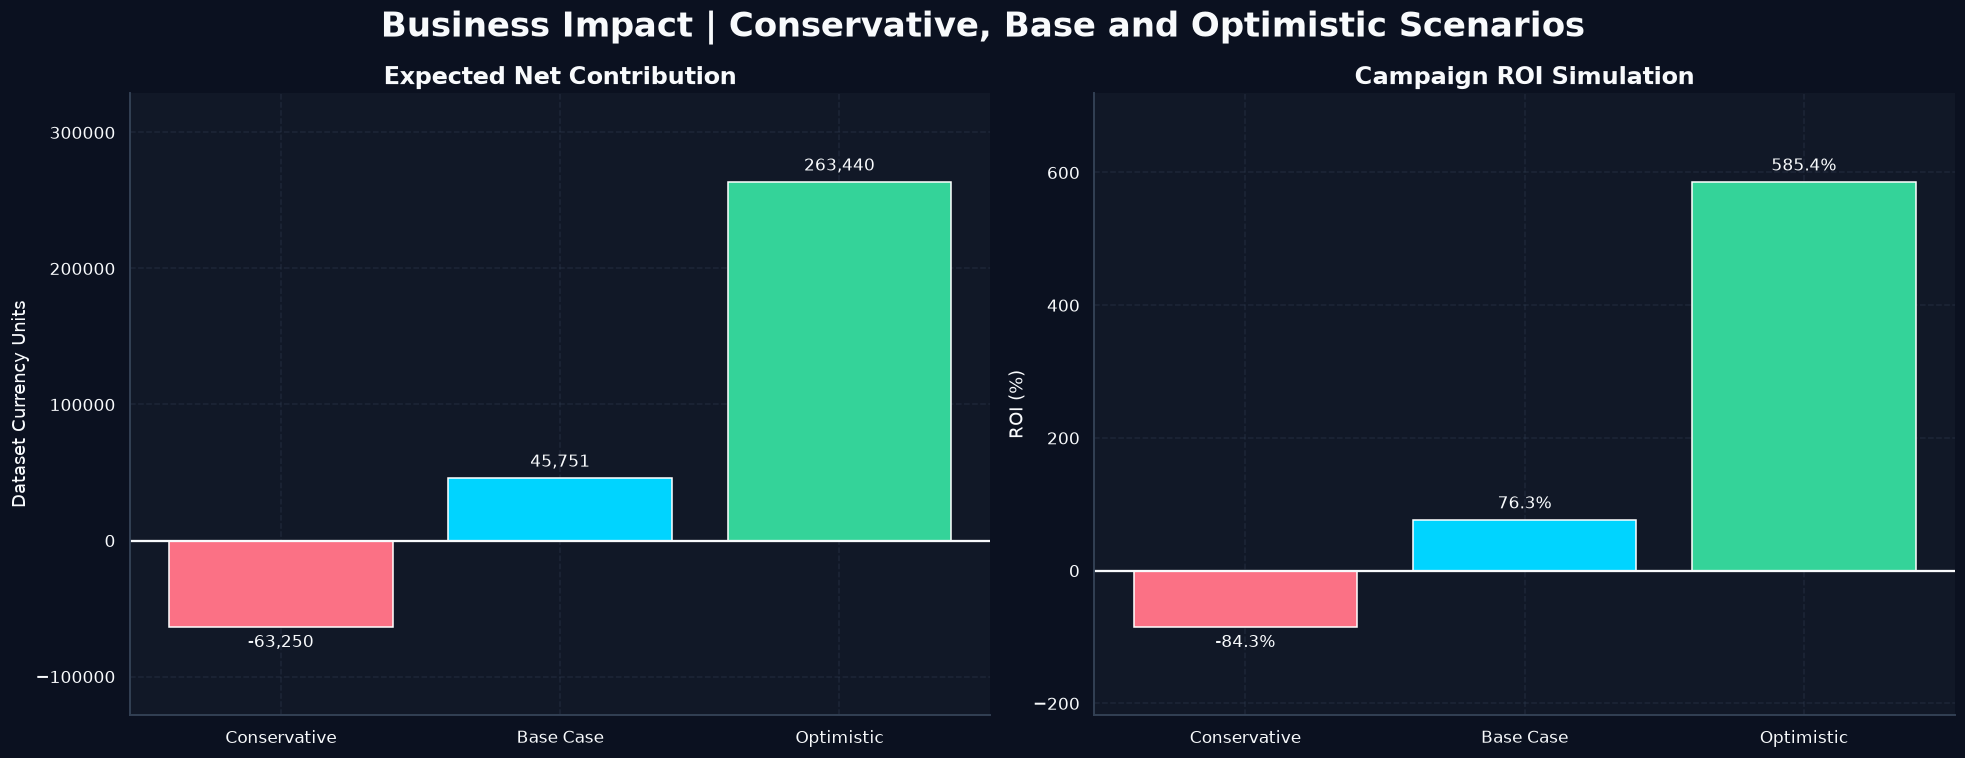

In [193]:
fig, axes = plt.subplots(

    1, 2,

    figsize=(18, 7)

)


scenario_colors = [

    RED,

    CYAN,

    GREEN

]


bars1 = axes[0].bar(

    scenario_report.index,

    scenario_report["Net_Contribution"],

    color=scenario_colors

)


axes[0].bar_label(

    bars1,

    labels=[

        f"{value:,.0f}"

        for value in scenario_report["Net_Contribution"]

    ],

    padding=5

)


axes[0].axhline(0, color=TEXT_COLOR)

axes[0].set_title("Expected Net Contribution")

axes[0].set_ylabel("Dataset Currency Units")

axes[0].margins(y=0.20)


bars2 = axes[1].bar(

    scenario_report.index,

    scenario_report["ROI_Percentage"],

    color=scenario_colors

)


axes[1].bar_label(

    bars2,

    fmt="%.1f%%",

    padding=5

)


axes[1].axhline(0, color=TEXT_COLOR)

axes[1].set_title("Campaign ROI Simulation")

axes[1].set_ylabel("ROI (%)")

axes[1].margins(y=0.20)


fig.suptitle(

    "Business Impact | Conservative, Base and Optimistic Scenarios",

    fontsize=22,

    fontweight="bold"

)


finish_plot(

    fig,

    "46_business_scenario_analysis.png"

)

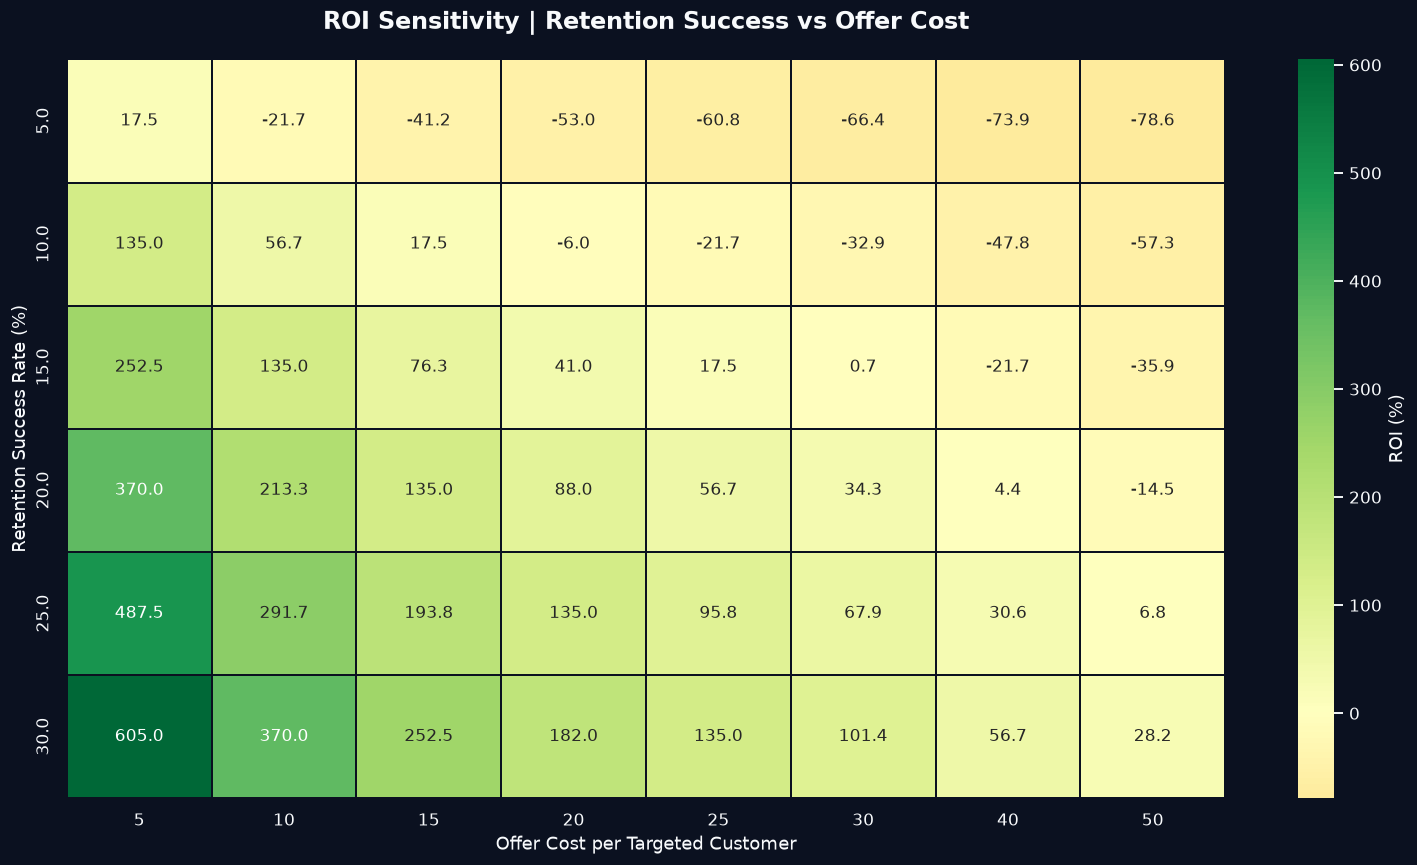

In [194]:
sensitivity_results = []


for success_rate in np.arange(

    0.05, 0.31, 0.05

):

    for offer_cost in [

        5, 10, 15, 20, 25, 30, 40, 50

    ]:

        result = simulate_campaign(

            selected_campaign,

            success_rate=success_rate,

            retention_months=6,

            contribution_margin=0.60,

            contact_cost=5,

            offer_cost=offer_cost

        )


        sensitivity_results.append({

            "Success_Rate": round(success_rate * 100, 1),

            "Offer_Cost": offer_cost,

            "ROI": result["ROI_Percentage"],

            "Net_Contribution": result["Net_Contribution"]

        })


sensitivity_df = pd.DataFrame(
    sensitivity_results
)


roi_matrix = sensitivity_df.pivot(

    index="Success_Rate",

    columns="Offer_Cost",

    values="ROI"

)


fig, ax = plt.subplots(figsize=(14, 8))


sns.heatmap(

    roi_matrix,

    annot=True,

    fmt=".1f",

    cmap="RdYlGn",

    center=0,

    linewidths=1,

    linecolor=BG_COLOR,

    cbar_kws={"label": "ROI (%)"},

    ax=ax

)


ax.set_title(

    "ROI Sensitivity | Retention Success vs Offer Cost",

    pad=20

)


ax.set_xlabel("Offer Cost per Targeted Customer")

ax.set_ylabel("Retention Success Rate (%)")


finish_plot(

    fig,

    "47_roi_sensitivity_analysis.png"

)


sensitivity_df.to_csv(

    REPORTS_DIR / "roi_sensitivity_analysis.csv",

    index=False

)

## Segment reliability

Compare error rates across tenure and device-age segments; this is not a comprehensive protected-group fairness audit.

In [197]:
fairness_data = pd.DataFrame({

    "Actual": y_test.to_numpy(),

    "Probability": test_probabilities,

    "Prediction": test_predictions,

    "Tenure": X_test_raw["months"].to_numpy(),

    "Equipment_Age": X_test_raw["eqpdays"].to_numpy()

})


fairness_data["Tenure_Group"] = pd.cut(

    fairness_data["Tenure"],

    bins=[0, 12, 24, 36, np.inf],

    labels=[

        "0-1 Year",

        "1-2 Years",

        "2-3 Years",

        "3+ Years"

    ],

    include_lowest=True

)


fairness_data["Device_Group"] = pd.cut(

    fairness_data["Equipment_Age"],

    bins=[0, 365, 730, np.inf],

    labels=[

        "Recent Device",

        "Aging Device",

        "Old Device"

    ],

    include_lowest=True

)


segment_performance_results = []


for feature in ["Tenure_Group", "Device_Group"]:

    for group, subset in fairness_data.groupby(

        feature,

        observed=True

    ):

        if len(subset) < 100:

            continue


        if subset["Actual"].nunique() < 2:

            continue


        metrics = evaluate_model(

            subset["Actual"],

            subset["Probability"],

            threshold=FINAL_THRESHOLD

        )


        segment_performance_results.append({

            "Segment_Type": feature,

            "Segment": str(group),

            "Customers": len(subset),

            "Observed_Churn_Rate": subset["Actual"].mean(),

            "ROC_AUC": metrics["ROC_AUC"],

            "Recall": metrics["Recall"],

            "Precision": metrics["Precision"],

            "False_Positive_Rate": 1 - metrics["Specificity"],

            "Brier_Score": metrics["Brier_Score"]

        })


segment_performance_report = pd.DataFrame(

    segment_performance_results

)


display(segment_performance_report.round(4))


segment_performance_report.to_csv(

    REPORTS_DIR / "segment_performance_report.csv",

    index=False

)

,Segment_Type,Segment,Customers,Observed_Churn_Rate,ROC_AUC,Recall,Precision,False_Positive_Rate,Brier_Score
0,Tenure_Group,0-1 Year,4829,0.4761,0.7533,0.8604,0.5938,0.5348,0.2014
1,Tenure_Group,1-2 Years,6470,0.5071,0.6464,0.9537,0.5306,0.8680,0.2332
2,Tenure_Group,2-3 Years,2840,0.5063,0.6741,0.9075,0.5509,0.7589,0.2265
3,Tenure_Group,3+ Years,861,0.4832,0.7100,0.8798,0.5605,0.6449,0.2165
4,Device_Group,Recent Device,8091,0.4580,0.7191,0.8451,0.5556,0.5713,0.2121
5,Device_Group,Aging Device,5273,0.5230,0.6475,0.9764,0.5352,0.9300,0.2329
6,Device_Group,Old Device,1621,0.5959,0.6505,0.9834,0.6043,0.9496,0.2243


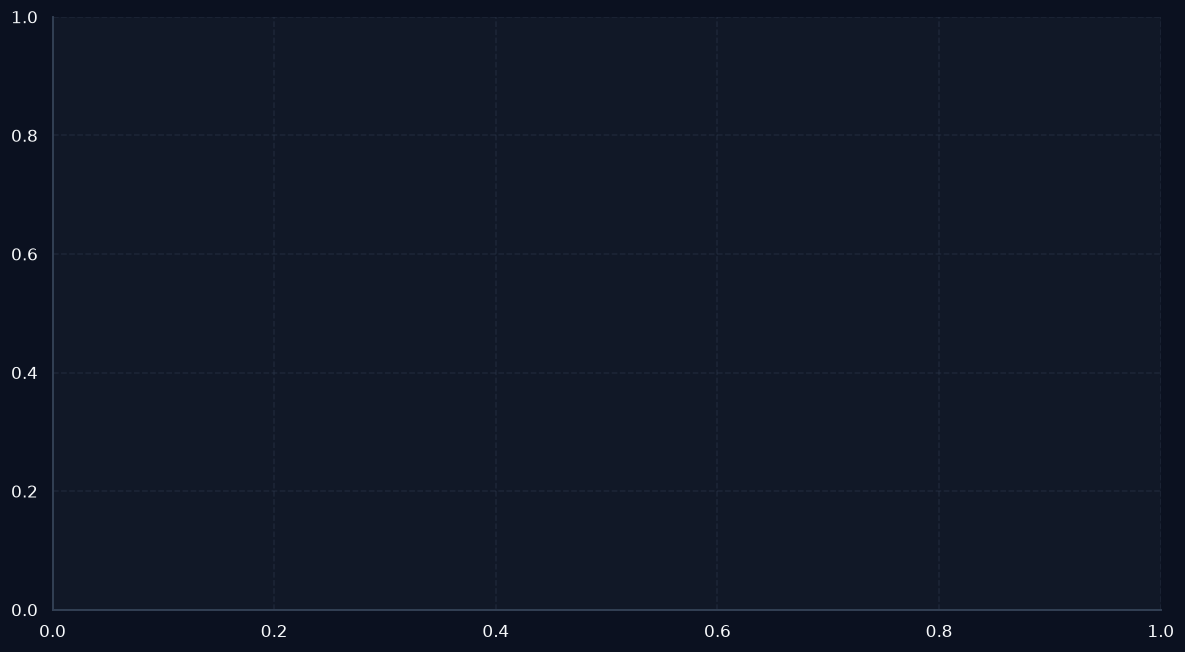

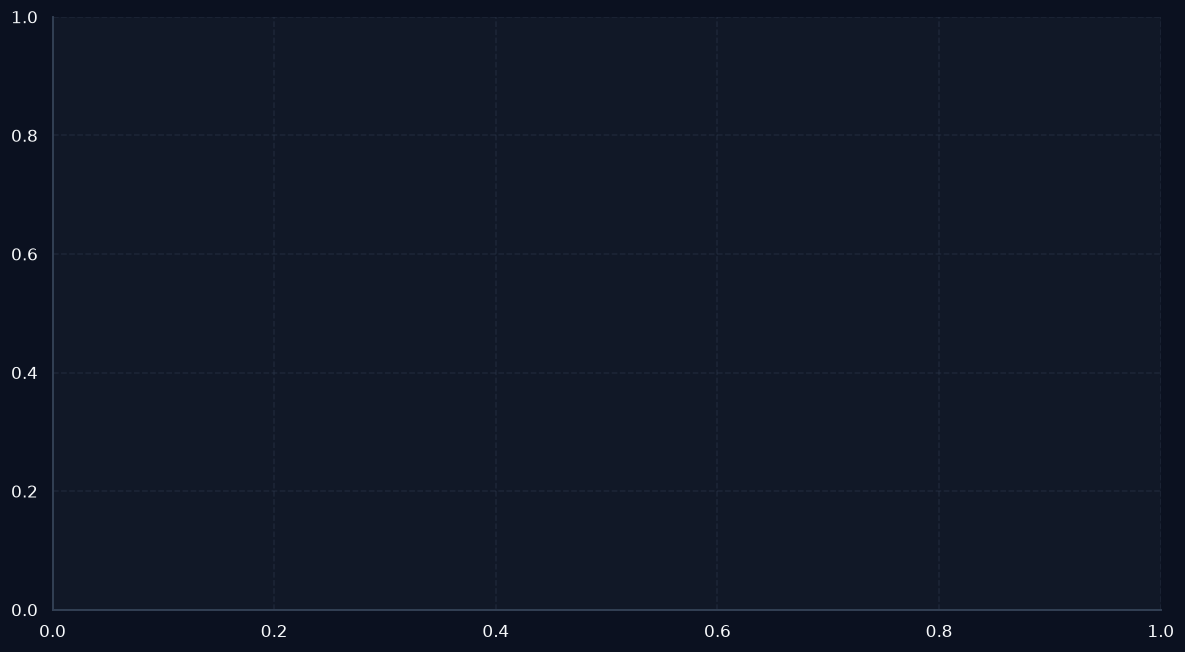

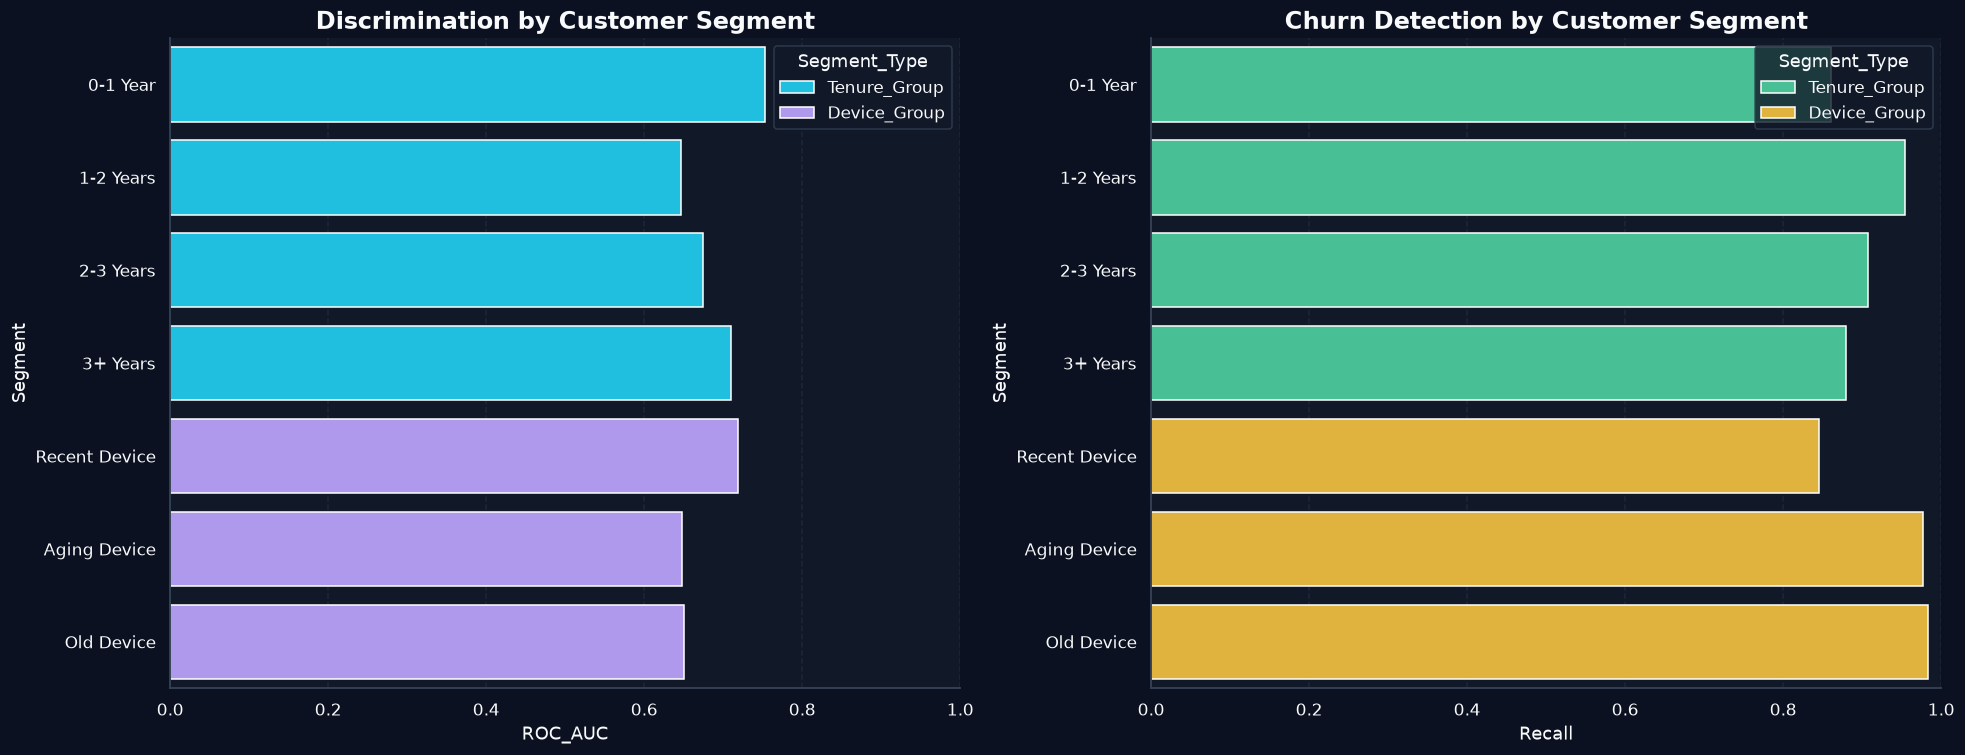

In [198]:
fig, axes = plt.subplots(

    1, 2,

    figsize=(18, 7)

)


sns.barplot(

    data=segment_performance_report,

    y="Segment",

    x="ROC_AUC",

    hue="Segment_Type",

    palette=[CYAN, PURPLE],

    dodge=False,

    ax=axes[0]

)


sns.barplot(

    data=segment_performance_report,

    y="Segment",

    x="Recall",

    hue="Segment_Type",

    palette=[GREEN, GOLD],

    dodge=False,

    ax=axes[1]

)


axes[0].set_xlim(0, 1)

axes[1].set_xlim(0, 1)

axes[0].set_title("Discrimination by Customer Segment")

axes[1].set_title("Churn Detection by Customer Segment")


finish_plot(

    fig,

    "49_segment_performance.png"

)

## Model persistence and reproducibility tests

The saved bundle contains model components, feature preparation, calibration and policy. The standalone module is generated in the existing project layout. Only load trusted pickle files.

In [199]:
%pip install cloudpickle

Note: you may need to restart the kernel to use updated packages.


In [200]:
model_components = {}


if CHAMPION_NAME in trained_models:

    model_components[CHAMPION_NAME] = {

        "estimator": trained_models[CHAMPION_NAME],

        "features": X_train.columns.tolist(),

        "input_type": "engineered"

    }


elif CHAMPION_NAME.startswith("Tuned "):

    name = CHAMPION_NAME.replace("Tuned ", "", 1)


    model_components[name] = {

        "estimator": optimized_models[name],

        "features": X_dev_train.columns.tolist(),

        "input_type": (

            "original"

            if selected_experiment == "Original Features"

            else "engineered"

        )

    }


else:

    for name in ensemble_model_names:

        model_components[name] = {

            "estimator": ensemble_full_models[name],

            "features": ensemble_features[name],

            "input_type": ensemble_input_types[name]

        }


if FINAL_CALIBRATION == "Sigmoid":

    saved_calibrator = sigmoid_calibrator

elif FINAL_CALIBRATION == "Isotonic":

    saved_calibrator = isotonic_calibrator

else:

    saved_calibrator = None


model_bundle = {

    "system_name": "Telecom Intelligence",

    "system_version": "1.0.0",

    "champion": CHAMPION_NAME,

    "components": model_components,

    "raw_features": X_train_raw.columns.tolist(),

    "raw_numeric_features": (

        X_train_raw

        .select_dtypes(include="number")

        .columns.tolist()

    ),

    "domain_cleaner": clean_domain_values,

    "feature_engineer": engineer_features_v2,

    "calibration_method": FINAL_CALIBRATION,

    "calibrator": saved_calibrator,

    "threshold": FINAL_THRESHOLD,

    "equal_weights": equal_weights,

    "optimized_weights": optimized_weights,

    "meta_model": stacking_meta_model,

    "business_config": BUSINESS_CONFIG,

    "revenue_cutoff": float(revenue_cutoff),

    "library_versions": dict(

        zip(

            versions["Library"],

            versions["Version"]

        )

    )

}


print("Model bundle assembled successfully.")

print("Saved components:", list(model_components.keys()))

Model bundle assembled successfully.
Saved components: ['XGBoost']


In [204]:
import cloudpickle

# ==========================================================
# SAVE THE COMPLETE MODEL BUNDLE
# ==========================================================

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert "model_bundle" in globals(), (
    "Run the model bundle creation cell first."
)

MODEL_PATH = MODELS_DIR / "telecom_intelligence_v1.pkl"

with open(MODEL_PATH, "wb") as file:

    cloudpickle.dump(
        model_bundle,
        file
    )

model_size_mb = (
    MODEL_PATH.stat().st_size / 1024**2
)

assert MODEL_PATH.exists()

assert MODEL_PATH.stat().st_size > 0

print("=" * 65)
print("MODEL PERSISTENCE")
print("=" * 65)

print("Model saved successfully.")
print("Champion:", CHAMPION_NAME)
print("Location:", MODEL_PATH)
print(f"Model Size: {model_size_mb:.2f} MB")

print("=" * 65)

MODEL PERSISTENCE
Model saved successfully.
Champion: Tuned XGBoost
Location: D:\GCI\05. Final Assignment\05. Final Assignment (due Nov 28)\Grad-project\Telecom_Intelligence\Telecom_Intelligence\models\telecom_intelligence_v1.pkl
Model Size: 6.68 MB


In [205]:
with open(MODEL_PATH, "rb") as file:

    loaded_bundle = cloudpickle.load(file)

assert loaded_bundle["champion"] == CHAMPION_NAME

assert loaded_bundle["threshold"] == FINAL_THRESHOLD

assert loaded_bundle["calibration_method"] == FINAL_CALIBRATION

assert len(loaded_bundle["components"]) > 0

print("Model bundle integrity test passed.")

Model bundle integrity test passed.


In [206]:
%%writefile ../retention_system.py
import cloudpickle
import numpy as np
import pandas as pd

from scipy.special import logit


class TelecomRetentionSystem:

    def __init__(self, model_path):

        with open(model_path, "rb") as file:

            self.bundle = cloudpickle.load(file)


    def validate_input(self, data):

        if not isinstance(data, pd.DataFrame):

            raise TypeError(
                "Input must be a pandas DataFrame."
            )


        if data.empty:

            raise ValueError("Input data is empty.")


        if not data.columns.is_unique:

            raise ValueError("Duplicate column names detected.")


        required = self.bundle["raw_features"]


        missing = [

            feature for feature in required

            if feature not in data.columns

        ]


        if missing:

            raise ValueError(

                f"Missing required columns: {missing}"

            )


        result = data.loc[:, required].copy()


        for feature in self.bundle["raw_numeric_features"]:

            original = result[feature]

            converted = pd.to_numeric(

                original,

                errors="coerce"

            )


            invalid = original.notna() & converted.isna()


            if invalid.any():

                raise ValueError(

                    f"Invalid numeric input: {feature}"

                )


            result[feature] = converted


        categorical = [

            feature for feature in required

            if feature not in self.bundle["raw_numeric_features"]

        ]


        for feature in categorical:

            result[feature] = (

                result[feature]

                .astype(object)

                .where(result[feature].notna(), np.nan)

            )


        return result


    def predict_proba(self, data):

        raw = self.validate_input(data)

        bundle = self.bundle

        predictions = []


        for component in bundle["components"].values():

            if component["input_type"] == "original":

                processed = bundle["domain_cleaner"](raw)

            else:

                processed = bundle["feature_engineer"](raw)


            inputs = processed.loc[

                :, component["features"]

            ]


            probabilities = component["estimator"].predict_proba(

                inputs

            )[:, 1]


            predictions.append(probabilities)


        matrix = np.column_stack(predictions)

        champion = bundle["champion"]


        if champion == "Equal Soft Voting":

            probabilities = matrix @ bundle["equal_weights"]


        elif champion == "Weighted Soft Voting":

            probabilities = matrix @ bundle["optimized_weights"]


        elif champion == "OOF Stacking":

            probabilities = (

                bundle["meta_model"]

                .predict_proba(matrix)[:, 1]

            )


        else:

            probabilities = matrix[:, 0]


        calibration = bundle["calibration_method"]


        if calibration == "Sigmoid":

            logits = logit(

                np.clip(probabilities, 1e-7, 1 - 1e-7)

            ).reshape(-1, 1)


            probabilities = (

                bundle["calibrator"]

                .predict_proba(logits)[:, 1]

            )


        elif calibration == "Isotonic":

            probabilities = bundle["calibrator"].predict(

                probabilities

            )


        if not np.isfinite(probabilities).all():

            raise ValueError("Non-finite predictions detected.")


        return np.clip(probabilities, 0, 1)


    def predict(self, data):

        probabilities = self.predict_proba(data)


        return (

            probabilities >= self.bundle["threshold"]

        ).astype(int)


    def score_customers(self, data):

        probabilities = self.predict_proba(data)

        config = self.bundle["business_config"]


        result = pd.DataFrame({

            "Churn_Probability": probabilities,

            "Predicted_Churn": (

                probabilities >= self.bundle["threshold"]

            ).astype(int)

        }, index=data.index)


        revenue = pd.to_numeric(

            data["rev_Mean"],

            errors="coerce"

        )


        result["Monthly_Revenue"] = revenue.where(

            revenue >= 0

        )


        result["Monthly_Revenue_Exposure"] = (

            result["Churn_Probability"]

            *

            result["Monthly_Revenue"]

        )


        result["Expected_Net_Contribution"] = (

            result["Monthly_Revenue_Exposure"]

            *

            config["retention_success_rate"]

            *

            config["retention_months"]

            *

            config["contribution_margin"]

            -

            config["campaign_contact_cost"]

            -

            config["retention_offer_cost"]

        )


        result["Campaign_Selected"] = False


        capacity = int(

            len(result) * config["campaign_capacity"]

        )


        eligible = result.loc[

            result["Expected_Net_Contribution"] > 0

        ].sort_values(

            "Expected_Net_Contribution",

            ascending=False

        )


        selected = eligible.head(capacity).index


        result.loc[

            selected,

            "Campaign_Selected"

        ] = True


        return result

Writing ../retention_system.py


In [208]:
import sys

import importlib


if str(PROJECT_ROOT) not in sys.path:

    sys.path.insert(

        0,

        str(PROJECT_ROOT)

    )


import retention_system

importlib.reload(retention_system)


from retention_system import TelecomRetentionSystem


retention_ai = TelecomRetentionSystem(

    MODEL_PATH

)


sample_inputs = X_val_raw.head(100).copy()


reloaded_probabilities = retention_ai.predict_proba(

    sample_inputs

)


np.testing.assert_allclose(

    reloaded_probabilities,

    final_val_probabilities[:100],

    rtol=1e-5,

    atol=1e-6

)


print("Standalone model reload test passed.")

display(

    retention_ai.score_customers(

        sample_inputs

    ).head(10)

)

Standalone model reload test passed.


,Churn_Probability,Predicted_Churn,Monthly_Revenue,Monthly_Revenue_Exposure,Expected_Net_Contribution,Campaign_Selected
74107,0.6842,1,47.3450,32.3947,-2.5068,False
89549,0.5190,1,36.1900,18.7810,-9.8583,False
11379,0.4416,1,29.9900,13.2443,-12.8481,False
68239,0.7211,1,18.3175,13.2079,-12.8677,False
6534,0.3952,1,53.3525,21.0853,-8.6139,False
24335,0.5394,1,338.4450,182.5686,78.5871,True
90653,0.4701,1,66.7900,31.3947,-3.0469,False
78339,0.2822,0,77.7025,21.9238,-8.1612,False
90418,0.3268,0,121.0450,39.5569,1.3607,False
46663,0.6282,1,90.4100,56.7924,10.6679,True


In [209]:
import unittest


class RetentionSystemTests(unittest.TestCase):

    def setUp(self):

        self.system = retention_ai

        self.sample = X_val_raw.head(50).copy()


    def test_prediction_count(self):

        probabilities = self.system.predict_proba(

            self.sample

        )

        self.assertEqual(

            len(probabilities),

            len(self.sample)

        )


    def test_probability_range(self):

        probabilities = self.system.predict_proba(

            self.sample

        )

        self.assertTrue(

            np.all(

                (probabilities >= 0)

                &

                (probabilities <= 1)

            )

        )


    def test_missing_values(self):

        modified = self.sample.copy()

        modified["eqpdays"] = np.nan

        modified["rev_Mean"] = np.nan


        probabilities = self.system.predict_proba(

            modified

        )


        self.assertTrue(

            np.isfinite(probabilities).all()

        )


    def test_missing_columns(self):

        modified = self.sample.drop(

            columns=["eqpdays"]

        )


        with self.assertRaises(ValueError):

            self.system.predict_proba(modified)


    def test_unseen_categories(self):

        modified = self.sample.copy()


        if model_categorical_features:

            feature = model_categorical_features[0]

            modified[feature] = (

                modified[feature].astype(object)

            )

            modified[feature] = "__UNSEEN_CATEGORY__"


        probabilities = self.system.predict_proba(

            modified

        )


        self.assertTrue(

            np.isfinite(probabilities).all()

        )


    def test_column_order(self):

        modified = self.sample[

            self.sample.columns[::-1]

        ]


        np.testing.assert_allclose(

            self.system.predict_proba(self.sample),

            self.system.predict_proba(modified),

            atol=1e-6

        )


    def test_extra_columns(self):

        modified = self.sample.copy()

        modified["Extra_Column"] = 999


        np.testing.assert_allclose(

            self.system.predict_proba(self.sample),

            self.system.predict_proba(modified),

            atol=1e-6

        )


    def test_repeatability(self):

        np.testing.assert_allclose(

            self.system.predict_proba(self.sample),

            self.system.predict_proba(self.sample),

            atol=1e-6

        )


    def test_empty_data(self):

        with self.assertRaises(ValueError):

            self.system.predict_proba(

                self.sample.iloc[:0]

            )


    def test_invalid_numeric_type(self):

        modified = self.sample.copy()

        modified["eqpdays"] = "INVALID_VALUE"


        with self.assertRaises(ValueError):

            self.system.predict_proba(modified)


    def test_binary_predictions(self):

        predictions = self.system.predict(self.sample)


        self.assertTrue(

            set(predictions).issubset({0, 1})

        )


    def test_campaign_capacity(self):

        report = self.system.score_customers(self.sample)

        capacity = int(

            len(report)

            *

            BUSINESS_CONFIG["campaign_capacity"]

        )


        self.assertLessEqual(

            report["Campaign_Selected"].sum(),

            capacity

        )


test_suite = (

    unittest.TestLoader()

    .loadTestsFromTestCase(RetentionSystemTests)

)


test_result = unittest.TextTestRunner(

    verbosity=2

).run(test_suite)


print("\nTests Run:", test_result.testsRun)

print("Failures:", len(test_result.failures))

print("Errors:", len(test_result.errors))

print("All Tests Passed:", test_result.wasSuccessful())

test_binary_predictions (__main__.RetentionSystemTests.test_binary_predictions) ... ok
test_campaign_capacity (__main__.RetentionSystemTests.test_campaign_capacity) ... ok
test_column_order (__main__.RetentionSystemTests.test_column_order) ... ok
test_empty_data (__main__.RetentionSystemTests.test_empty_data) ... ok
test_extra_columns (__main__.RetentionSystemTests.test_extra_columns) ... ok
test_invalid_numeric_type (__main__.RetentionSystemTests.test_invalid_numeric_type) ... ok
test_missing_columns (__main__.RetentionSystemTests.test_missing_columns) ... ok
test_missing_values (__main__.RetentionSystemTests.test_missing_values) ... ok
test_prediction_count (__main__.RetentionSystemTests.test_prediction_count) ... ok
test_probability_range (__main__.RetentionSystemTests.test_probability_range) ... ok
test_repeatability (__main__.RetentionSystemTests.test_repeatability) ... ok
test_unseen_categories (__main__.RetentionSystemTests.test_unseen_categories) ... ok

-----------------------


Tests Run: 12
Failures: 0
Errors: 0
All Tests Passed: True


In [210]:
system_test_report = {

    "Tests_Run": test_result.testsRun,

    "Failures": len(test_result.failures),

    "Errors": len(test_result.errors),

    "All_Tests_Passed": test_result.wasSuccessful()

}


with open(

    REPORTS_DIR / "system_testing_report.json",

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        system_test_report,

        file,

        indent=4

    )


assert test_result.wasSuccessful(), (

    "System tests failed. Review before deployment."

)


print("System testing report saved.")

System testing report saved.


In [211]:
import subprocess


smoke_test_path = MODELS_DIR / "smoke_test_input.csv"


X_val_raw.head(20).to_csv(

    smoke_test_path,

    index=False

)


smoke_code = f"""
import pandas as pd
import numpy as np
from retention_system import TelecomRetentionSystem

system = TelecomRetentionSystem({str(MODEL_PATH)!r})

data = pd.read_csv({str(smoke_test_path)!r})

probabilities = system.predict_proba(data)

assert len(probabilities) == len(data)
assert np.isfinite(probabilities).all()

print('FRESH PROCESS TEST PASSED')
"""


process = subprocess.run(

    [sys.executable, "-c", smoke_code],

    cwd=str(PROJECT_ROOT),

    capture_output=True,

    text=True

)


print(process.stdout)


if process.returncode != 0:

    print(process.stderr)

    raise RuntimeError("Fresh process test failed.")

FRESH PROCESS TEST PASSED



**Recorded software validation:** all 12 unit tests and the fresh-process smoke test passed. These verify software behavior for the tested inputs, not production predictive validity.

# 24. Model Monitoring and Drift Detection

A monitoring framework is implemented to identify changes
in feature distributions, missing-value patterns and
predicted churn probabilities.

The framework is evaluated using historical holdout data
and synthetic drift simulations.

Because chronological production data is unavailable,
the monitoring results represent a proof of concept
rather than live production monitoring.

In [212]:
from scipy.stats import ks_2samp

from scipy.spatial.distance import jensenshannon


def calculate_psi(

    reference,

    current,

    bins=10,

    epsilon=1e-6

):

    reference = pd.to_numeric(

        pd.Series(reference),

        errors="coerce"

    ).replace([np.inf, -np.inf], np.nan).dropna()


    current = pd.to_numeric(

        pd.Series(current),

        errors="coerce"

    ).replace([np.inf, -np.inf], np.nan).dropna()


    if len(reference) < 2 or len(current) < 2:

        return np.nan


    edges = np.unique(

        np.quantile(

            reference,

            np.linspace(0, 1, bins + 1)

        )

    )


    if len(edges) < 2:

        return np.nan


    edges[0] = -np.inf

    edges[-1] = np.inf


    reference_counts, _ = np.histogram(

        reference,

        bins=edges

    )


    current_counts, _ = np.histogram(

        current,

        bins=edges

    )


    reference_pct = (

        reference_counts + epsilon

    ) / (

        reference_counts.sum() + epsilon * len(reference_counts)

    )


    current_pct = (

        current_counts + epsilon

    ) / (

        current_counts.sum() + epsilon * len(current_counts)

    )


    psi = np.sum(

        (current_pct - reference_pct)

        *

        np.log(current_pct / reference_pct)

    )


    return float(psi)


def calculate_js_divergence(

    reference,

    current

):

    reference = pd.Series(reference).astype("string").fillna("__MISSING__")

    current = pd.Series(current).astype("string").fillna("__MISSING__")


    categories = reference.unique().tolist()

    categories = sorted(

        set(categories) | set(current.unique())

    )


    p = reference.value_counts(normalize=True).reindex(

        categories,

        fill_value=0

    )


    q = current.value_counts(normalize=True).reindex(

        categories,

        fill_value=0

    )


    return float(

        jensenshannon(p, q, base=2) ** 2

    )

In [213]:
def monitor_data_drift(

    reference_data,

    current_data

):

    results = []


    numeric_features = (

        reference_data

        .select_dtypes(include="number")

        .columns.tolist()

    )


    for feature in reference_data.columns:

        if feature not in current_data.columns:

            continue


        reference = reference_data[feature]

        current = current_data[feature]


        missing_change = abs(

            current.isna().mean()

            -

            reference.isna().mean()

        )


        psi = np.nan

        ks_statistic = np.nan

        ks_pvalue = np.nan

        js = np.nan


        if feature in numeric_features:

            psi = calculate_psi(

                reference,

                current

            )


            reference_valid = (

                reference

                .replace([np.inf, -np.inf], np.nan)

                .dropna()

            )


            current_valid = (

                current

                .replace([np.inf, -np.inf], np.nan)

                .dropna()

            )


            if (

                len(reference_valid) > 1

                and len(current_valid) > 1

            ):

                ks = ks_2samp(

                    reference_valid,

                    current_valid

                )


                ks_statistic = ks.statistic

                ks_pvalue = ks.pvalue


            score = psi


        else:

            js = calculate_js_divergence(

                reference,

                current

            )


            score = js


        if missing_change >= 0.10:

            status = "Critical"


        elif feature in numeric_features:

            if pd.isna(psi):

                status = "Not Assessable"

            elif psi >= 0.25:

                status = "Critical"

            elif psi >= 0.10:

                status = "Warning"

            else:

                status = "Stable"


            if (

                pd.notna(ks_statistic)

                and ks_statistic >= 0.20

            ):

                status = "Critical"

            elif (

                pd.notna(ks_statistic)

                and ks_statistic >= 0.10

                and status != "Critical"

            ):

                status = "Warning"


        else:

            if js >= 0.10:

                status = "Critical"

            elif js >= 0.05:

                status = "Warning"

            else:

                status = "Stable"


        if (

            missing_change >= 0.05

            and status != "Critical"

        ):

            status = "Warning"


        results.append({

            "Feature": feature,

            "Type": (

                "Numerical"

                if feature in numeric_features

                else "Categorical"

            ),

            "PSI": psi,

            "KS_Statistic": ks_statistic,

            "KS_P_Value": ks_pvalue,

            "JS_Divergence": js,

            "Missing_Rate_Change": missing_change,

            "Drift_Score": score,

            "Status": status

        })


    return pd.DataFrame(results)

In [214]:
reference_monitoring_data = X_train_raw.sample(

    n=min(15000, len(X_train_raw)),

    random_state=SEED

)


current_monitoring_data = X_test_raw.copy()


historical_drift_report = monitor_data_drift(

    reference_monitoring_data,

    current_monitoring_data

)


display(

    historical_drift_report

    .sort_values("Drift_Score", ascending=False)

    .head(20)

    .round(5)

)


display(

    historical_drift_report["Status"].value_counts()

)


historical_drift_report.to_csv(

    MONITORING_DIR / "historical_holdout_drift.csv",

    index=False

)

,Feature,Type,PSI,KS_Statistic,KS_P_Value,JS_Divergence,Missing_Rate_Change,Drift_Score,Status
65,avg6mou,Numerical,0.0025,0.0124,0.2074,NaN,0.0011,0.0025,Stable
35,peak_vce_Mean,Numerical,0.0023,0.0095,0.5092,NaN,0.0000,0.0023,Stable
45,complete_Mean,Numerical,0.0023,0.0101,0.4300,NaN,0.0000,0.0023,Stable
60,avgmou,Numerical,0.0022,0.0131,0.1491,NaN,0.0000,0.0022,Stable
30,mou_rvce_Mean,Numerical,0.0021,0.0097,0.4732,NaN,0.0000,0.0021,Stable
43,drop_blk_Mean,Numerical,0.0020,0.0130,0.1571,NaN,0.0000,0.0020,Stable
21,comp_vce_Mean,Numerical,0.0019,0.0097,0.4821,NaN,0.0000,0.0019,Stable
59,avgrev,Numerical,0.0019,0.0105,0.3735,NaN,0.0000,0.0019,Stable
10,change_rev,Numerical,0.0018,0.0160,0.0433,NaN,0.0001,0.0018,Stable
41,mou_opkv_Mean,Numerical,0.0018,0.0104,0.3892,NaN,0.0000,0.0018,Stable


Status
Stable    83
Name: count, dtype: int64

In [215]:
production_reference = X_val_raw.copy()

simulated_production = production_reference.copy()


# Simulate usage decline

simulated_production["mou_Mean"] *= 0.65

simulated_production["avg3mou"] *= 0.70

simulated_production["change_mou"] -= 20


# Simulate equipment aging

simulated_production["eqpdays"] += 180


# Simulate higher customer-care activity

simulated_production["custcare_Mean"] *= 1.50


# Simulate data quality deterioration

rng = np.random.default_rng(SEED)


missing_positions = rng.choice(

    len(simulated_production),

    size=int(len(simulated_production) * 0.20),

    replace=False

)


simulated_production.iloc[

    missing_positions,

    simulated_production.columns.get_loc("rev_Mean")

] = np.nan


simulated_drift_report = monitor_data_drift(

    production_reference,

    simulated_production

)


display(

    simulated_drift_report.loc[

        simulated_drift_report["Status"]

        .isin(["Critical", "Warning"])

    ]

    .sort_values("Drift_Score", ascending=False)

    .round(5)

)


simulated_drift_report.to_csv(

    MONITORING_DIR / "simulated_production_drift.csv",

    index=False

)

,Feature,Type,PSI,KS_Statistic,KS_P_Value,JS_Divergence,Missing_Rate_Change,Drift_Score,Status
82,eqpdays,Numerical,2.6607,0.3581,0.0000,NaN,0.0000,2.6607,Critical
1,mou_Mean,Numerical,0.1772,0.1640,0.0000,NaN,0.0000,0.1772,Warning
62,avg3mou,Numerical,0.1202,0.1362,0.0000,NaN,0.0000,0.1202,Warning
9,change_mou,Numerical,0.0776,0.1263,0.0000,NaN,0.0000,0.0776,Warning
0,rev_Mean,Numerical,0.0001,0.0055,0.9882,NaN,0.1995,0.0001,Critical


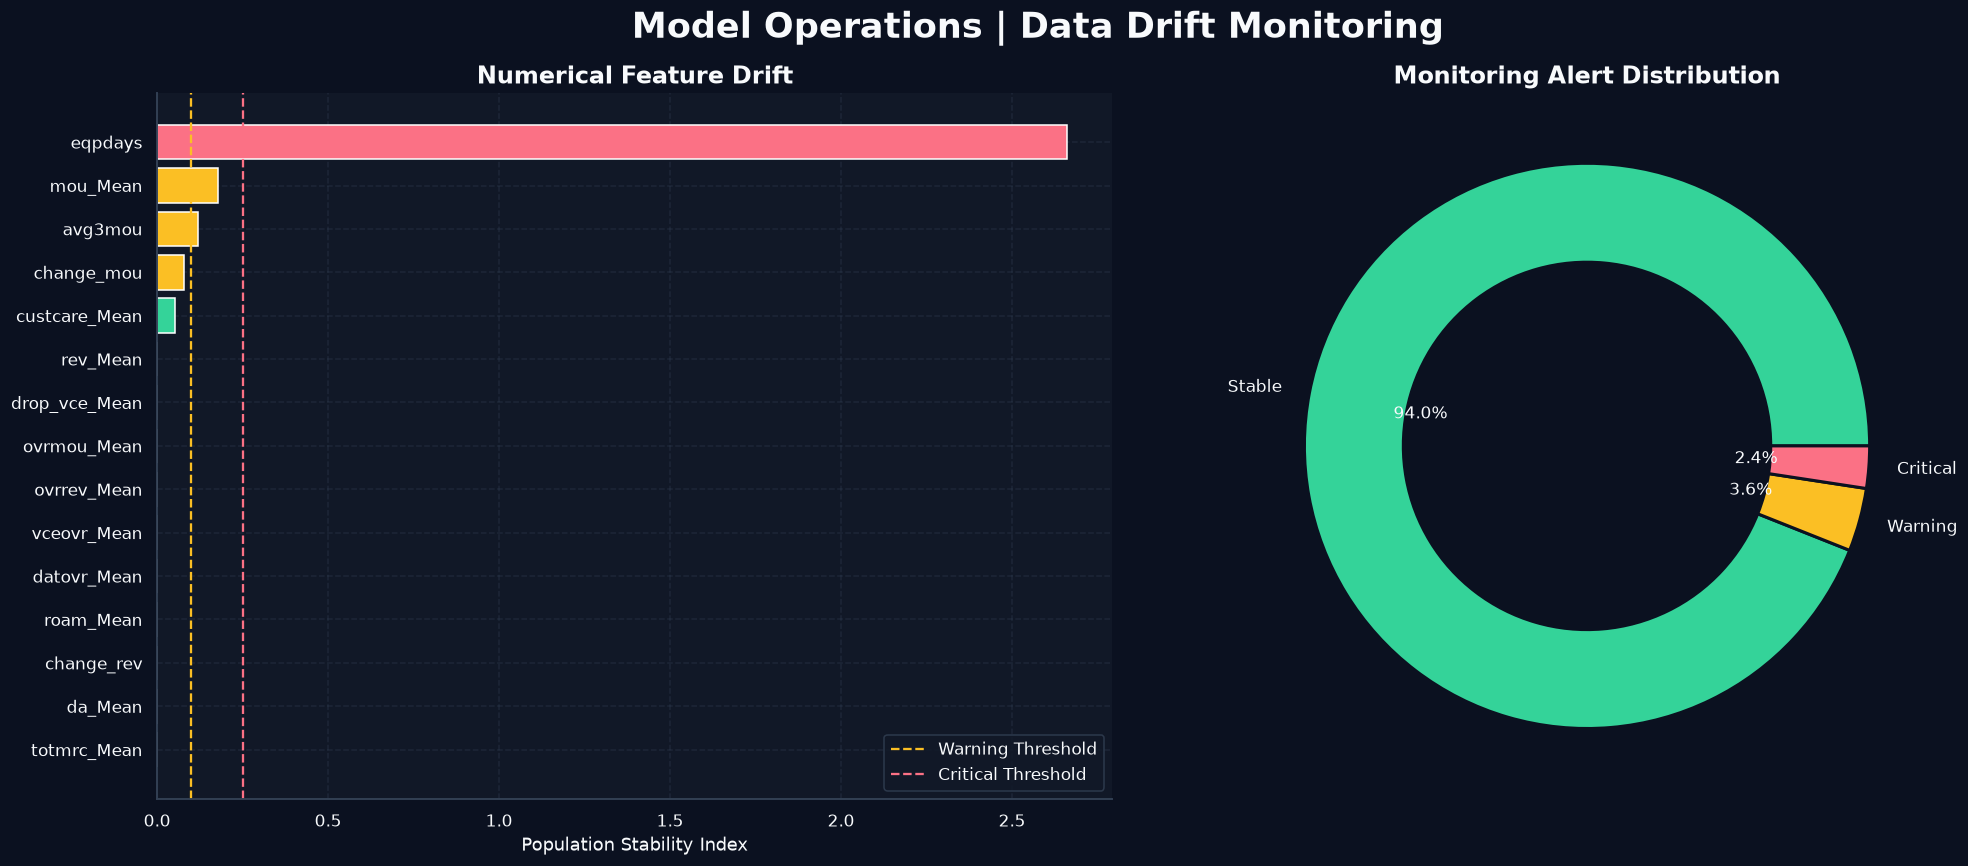

In [216]:
drift_plot = (

    simulated_drift_report

    .dropna(subset=["PSI"])

    .nlargest(15, "PSI")

    .sort_values("PSI")

)


status_colors = {

    "Critical": RED,

    "Warning": GOLD,

    "Stable": GREEN,

    "Not Assessable": "#94A3B8"

}


fig, axes = plt.subplots(

    1, 2,

    figsize=(19, 8)

)


axes[0].barh(

    drift_plot["Feature"],

    drift_plot["PSI"],

    color=[

        status_colors[status]

        for status in drift_plot["Status"]

    ]

)


axes[0].axvline(

    0.10,

    linestyle="--",

    color=GOLD,

    label="Warning Threshold"

)


axes[0].axvline(

    0.25,

    linestyle="--",

    color=RED,

    label="Critical Threshold"

)


axes[0].set_title("Numerical Feature Drift")

axes[0].set_xlabel("Population Stability Index")

axes[0].legend()


drift_status = (

    simulated_drift_report["Status"]

    .value_counts()

)


axes[1].pie(

    drift_status.values,

    labels=drift_status.index,

    colors=[

        status_colors[status]

        for status in drift_status.index

    ],

    autopct="%1.1f%%",

    wedgeprops={

        "width": 0.35,

        "edgecolor": BG_COLOR,

        "linewidth": 2

    },

    textprops={"color": TEXT_COLOR}

)


axes[1].set_title("Monitoring Alert Distribution")


fig.suptitle(

    "Model Operations | Data Drift Monitoring",

    fontsize=23,

    fontweight="bold"

)


finish_plot(

    fig,

    "50_data_drift_monitoring.png"

)

,Metric,Reference,Simulated Production
0,Mean Churn Probability,0.4951,0.6025
1,High Risk Fraction,0.8145,0.9690
2,Probability Standard Deviation,0.1720,0.1397


Prediction PSI: 0.52859


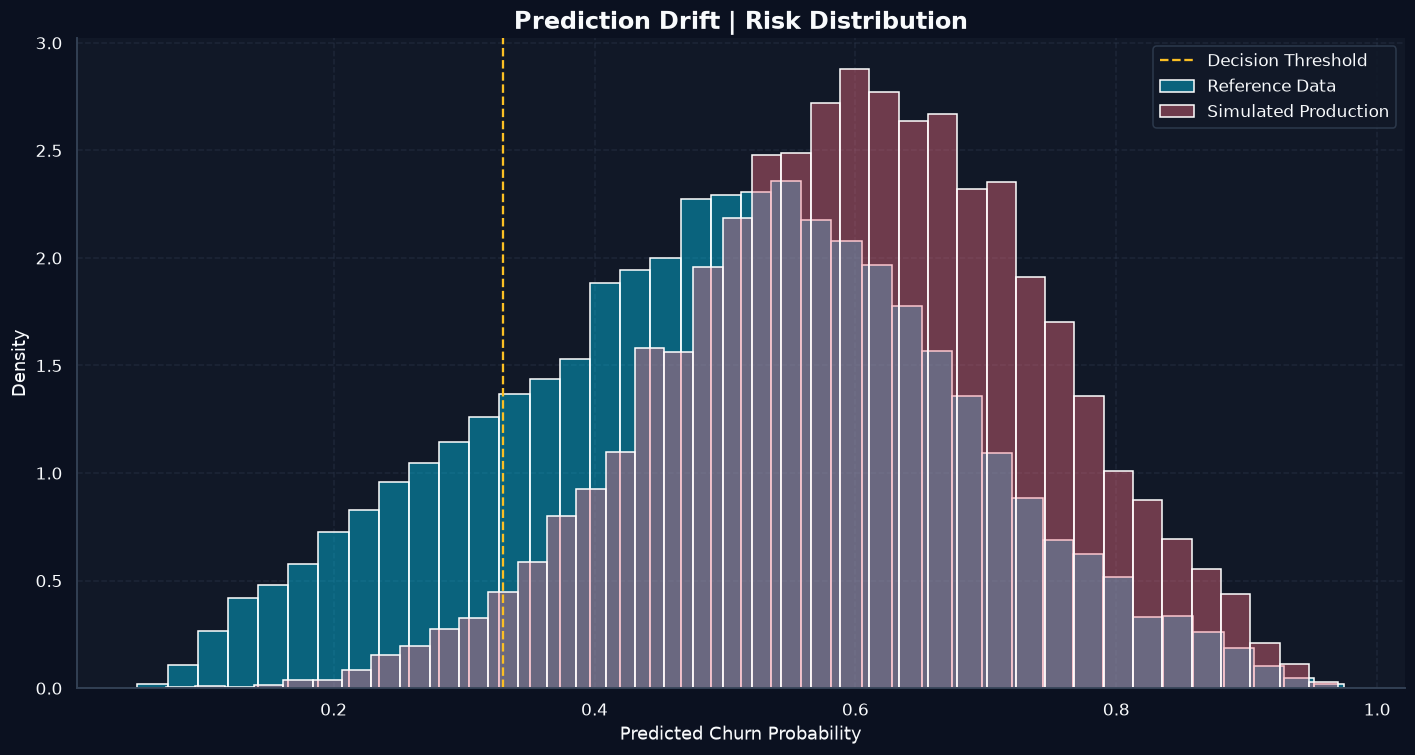

In [217]:
reference_risk = retention_ai.predict_proba(

    production_reference

)


simulated_risk = retention_ai.predict_proba(

    simulated_production

)


prediction_psi = calculate_psi(

    reference_risk,

    simulated_risk

)


prediction_drift_report = pd.DataFrame({

    "Metric": [

        "Mean Churn Probability",

        "High Risk Fraction",

        "Probability Standard Deviation"

    ],

    "Reference": [

        reference_risk.mean(),

        (reference_risk >= FINAL_THRESHOLD).mean(),

        reference_risk.std()

    ],

    "Simulated Production": [

        simulated_risk.mean(),

        (simulated_risk >= FINAL_THRESHOLD).mean(),

        simulated_risk.std()

    ]

})


display(prediction_drift_report.round(5))


print("Prediction PSI:", round(prediction_psi, 5))


fig, ax = plt.subplots(figsize=(13, 7))


sns.histplot(

    reference_risk,

    bins=40,

    stat="density",

    color=CYAN,

    alpha=0.4,

    label="Reference Data",

    ax=ax

)


sns.histplot(

    simulated_risk,

    bins=40,

    stat="density",

    color=RED,

    alpha=0.4,

    label="Simulated Production",

    ax=ax

)


ax.axvline(

    FINAL_THRESHOLD,

    linestyle="--",

    color=GOLD,

    label="Decision Threshold"

)


ax.set_title("Prediction Drift | Risk Distribution")

ax.set_xlabel("Predicted Churn Probability")

ax.legend()


finish_plot(

    fig,

    "51_prediction_drift.png"

)

In [218]:
critical_features = simulated_drift_report.loc[

    simulated_drift_report["Status"] == "Critical",

    "Feature"

].tolist()


warning_features = simulated_drift_report.loc[

    simulated_drift_report["Status"] == "Warning",

    "Feature"

].tolist()


if critical_features or (

    np.isfinite(prediction_psi)

    and prediction_psi >= 0.25

):

    monitoring_status = "CRITICAL"

    recommended_action = (

        "Investigate data quality and distribution shifts. "

        "Evaluate performance with new labels before retraining."

    )


elif warning_features or (

    np.isfinite(prediction_psi)

    and prediction_psi >= 0.10

):

    monitoring_status = "WARNING"

    recommended_action = (

        "Increase monitoring frequency and investigate shifts."

    )


else:

    monitoring_status = "STABLE"

    recommended_action = (

        "Continue routine monitoring."

    )


monitoring_summary = {

    "Monitoring_Type": "Synthetic Drift Simulation",

    "Status": monitoring_status,

    "Critical_Features": critical_features,

    "Warning_Features": warning_features,

    "Prediction_PSI": (

        float(prediction_psi)

        if np.isfinite(prediction_psi)

        else None

    ),

    "Recommended_Action": recommended_action

}


with open(

    MONITORING_DIR / "monitoring_summary.json",

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        monitoring_summary,

        file,

        indent=4

    )


display(Markdown(

    f"### Monitoring Status: {monitoring_status}"

))


print("Critical Features:", critical_features)

print("Warning Features:", warning_features)

print("Recommended Action:", recommended_action)

### Monitoring Status: CRITICAL

Critical Features: ['rev_Mean', 'eqpdays']
Warning Features: ['mou_Mean', 'change_mou', 'avg3mou']
Recommended Action: Investigate data quality and distribution shifts. Evaluate performance with new labels before retraining.


In [219]:
def monitor_model_performance(

    actual_labels,

    predicted_probabilities,

    reference_metrics,

    threshold

):

    current_metrics = evaluate_model(

        actual_labels,

        predicted_probabilities,

        threshold=threshold

    )


    comparison = pd.DataFrame({

        "Reference": reference_metrics,

        "Current": current_metrics

    })


    comparison["Change"] = (

        comparison["Current"]

        -

        comparison["Reference"]

    )


    auc_drop = (

        reference_metrics["ROC_AUC"]

        -

        current_metrics["ROC_AUC"]

    )


    brier_increase = (

        current_metrics["Brier_Score"]

        -

        reference_metrics["Brier_Score"]

    )


    if auc_drop >= 0.03 or brier_increase >= 0.02:

        status = "INVESTIGATE"

    else:

        status = "WITHIN DEFINED TOLERANCE"


    return comparison, status


print(

    "Performance monitoring function is ready "

    "for future labeled customer batches."

)

Performance monitoring function is ready for future labeled customer batches.


**Monitoring interpretation.** A CRITICAL alert in the recorded synthetic scenario demonstrates the monitoring mechanism reacting to deliberately altered inputs. It does not establish real-world drift or justify automatic retraining.

# 25. External Market and Industry Analysis

## Global Telecommunications Market

The telecommunications industry represents a major
component of the global digital economy.

According to the GSMA Mobile Economy 2026 report,
mobile technologies and services contributed approximately
USD 7.6 trillion to the global economy in 2025,
representing 6.4% of global GDP.

The report also identifies AI monetization as a
strategic priority for 45% of operators.

Source: GSMA, The Mobile Economy 2026 [1].

## Changing Customer Usage Patterns

Ericsson reported that mobile network data traffic
increased by 23% between Q2 2025 and Q2 2026.

Furthermore, 5G accounted for approximately 48%
of global mobile data traffic at the end of 2025.

These developments highlight the importance of
monitoring changing customer behavior, service
requirements and technology adoption.

Sources: Ericsson Mobility Report [2, 3].

## Strategic Implications for Company A

The proposed customer retention system addresses
three business opportunities:

1. Early identification of customers with elevated
   churn risk.

2. More efficient allocation of retention resources.

3. Protection of recurring revenue through financially
   prioritized customer interventions.

The international market findings provide strategic
context, but they do not establish Company A's actual
market share, geography, churn rate or financial margins.

**Source verification note.** The market figures above are retained from the original notebook. Verify the exact figures, dates and denominators against the linked primary reports before using them in the submitted presentation. The global indicators are context, not Company A-specific measurements.

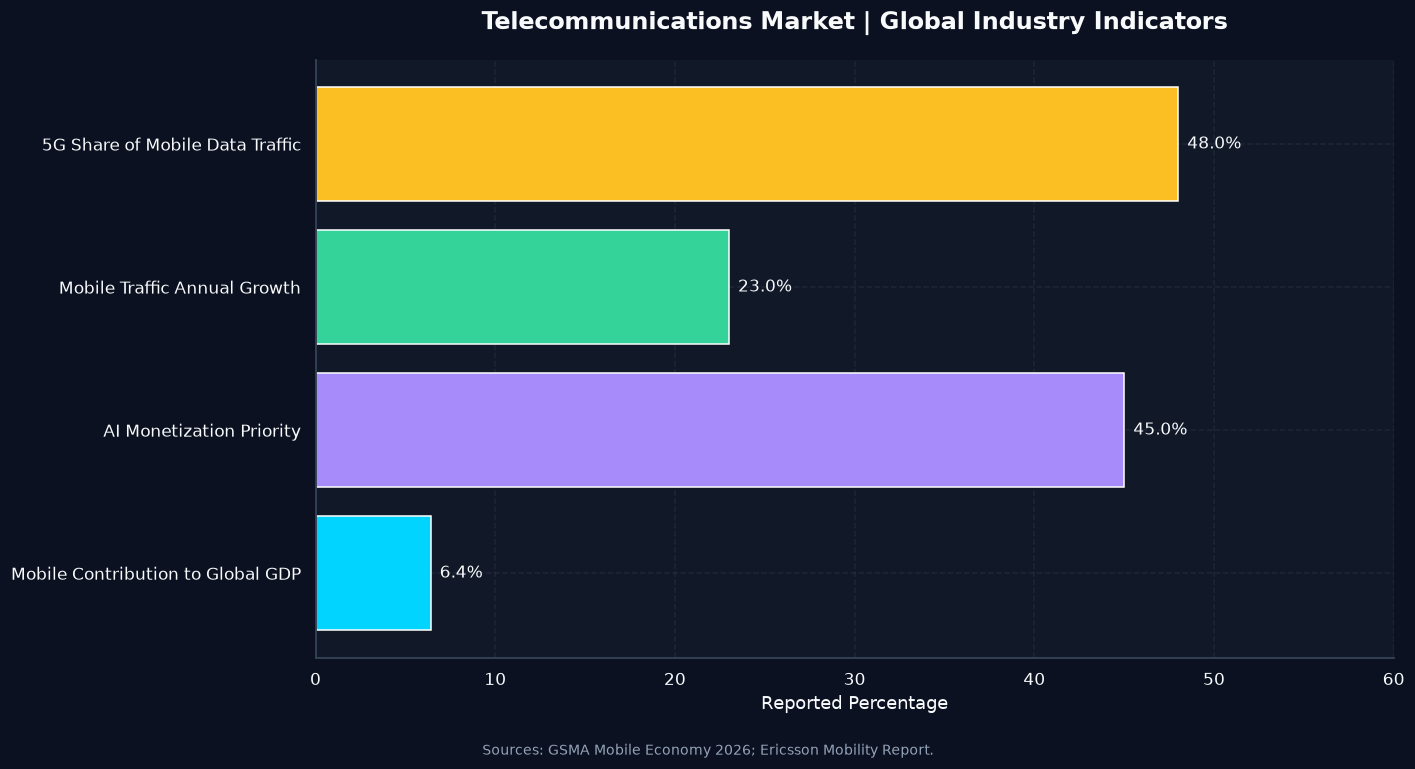

In [220]:
market_indicators = pd.DataFrame({

    "Indicator": [

        "Mobile Contribution to Global GDP",

        "AI Monetization Priority",

        "Mobile Traffic Annual Growth",

        "5G Share of Mobile Data Traffic"

    ],

    "Percentage": [

        6.4,

        45.0,

        23.0,

        48.0

    ]

})


fig, ax = plt.subplots(figsize=(13, 7))


bars = ax.barh(

    market_indicators["Indicator"],

    market_indicators["Percentage"],

    color=[

        CYAN,

        PURPLE,

        GREEN,

        GOLD

    ]

)


ax.bar_label(

    bars,

    fmt="%.1f%%",

    padding=6

)


ax.set_xlim(0, 60)


ax.set_title(

    "Telecommunications Market | Global Industry Indicators",

    pad=20

)


ax.set_xlabel("Reported Percentage")


fig.text(

    0.5,

    0.01,

    "Sources: GSMA Mobile Economy 2026; Ericsson Mobility Report.",

    ha="center",

    color="#94A3B8",

    fontsize=9

)


fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(

    FIGURES_DIR / "52_global_market_indicators.png",

    dpi=300,

    bbox_inches="tight",

    facecolor=BG_COLOR

)

plt.show()

plt.close(fig)

# 26. Proposed Business Implementation

## Phase 1: Data and Infrastructure Validation

- Confirm the operational definitions of customer features.
- Verify the actual production churn prevalence.
- Establish privacy and data governance requirements.
- Validate the availability of customer revenue information.
- Integrate customer information and service records.

## Phase 2: Controlled Pilot Program

- Select eligible customers using the retention system.
- Randomly assign eligible customers to treatment and control groups.
- Test retention offers and proactive service interventions.
- Measure incremental retention and contribution.
- Review customer satisfaction and complaint rates.

## Phase 3: Operational Integration

- Integrate customer risk scores with the CRM platform.
- Generate customer prioritization lists.
- Provide explanations to customer retention teams.
- Maintain human approval for paid interventions.

## Phase 4: Continuous Monitoring

- Monitor missing-value patterns and data drift.
- Monitor prediction distributions.
- Evaluate performance when outcome labels become available.
- Reassess probability calibration.
- Retrain only after evidence-based review.

## Success Metrics

- Incremental reduction in customer churn.
- Retained customer revenue.
- Incremental financial contribution.
- Campaign cost efficiency.
- Customer satisfaction.
- Predictive performance and calibration.

In [221]:
top20_test = evaluate_top_k(

    y_test,

    test_probabilities,

    fraction=0.20

)


executive_summary = {

    "Project": "Telecom Intelligence",

    "Business_Objective": "Revenue-Aware Customer Retention",

    "Total_Customers": len(df),

    "Training_Customers": len(y_train),

    "Validation_Customers": len(y_val),

    "Independent_Test_Customers": len(y_test),

    "Champion_Model": CHAMPION_NAME,

    "Calibration_Method": FINAL_CALIBRATION,

    "Decision_Threshold": float(FINAL_THRESHOLD),

    "Test_ROC_AUC": float(final_test_metrics["ROC_AUC"]),

    "Test_Accuracy": float(final_test_metrics["Accuracy"]),

    "Test_F1": float(final_test_metrics["F1"]),

    "Test_Recall": float(final_test_metrics["Recall"]),

    "Test_Precision": float(final_test_metrics["Precision"]),

    "Test_Brier_Score": float(final_test_metrics["Brier_Score"]),

    "ROC_AUC_CI_Lower": float(

        confidence_report.loc["ROC_AUC", "CI_Lower_95"]

    ),

    "ROC_AUC_CI_Upper": float(

        confidence_report.loc["ROC_AUC", "CI_Upper_95"]

    ),

    "Lift_at_20_Percent": float(top20_test["Lift_at_K"]),

    "Precision_at_20_Percent": float(top20_test["Precision_at_K"]),

    "Campaign_Customers": len(selected_campaign),

    "Expected_Saved_Customers": float(

        base_business_result["Expected_Saved_Customers"]

    ),

    "Expected_Retained_Revenue": float(

        base_business_result["Expected_Retained_Revenue"]

    ),

    "Expected_Net_Contribution": float(

        base_business_result["Net_Contribution"]

    ),

    "Expected_Campaign_ROI": (

        float(base_business_result["ROI_Percentage"])

        if np.isfinite(base_business_result["ROI_Percentage"])

        else None

    ),

    "System_Tests_Passed": test_result.wasSuccessful(),

    "Monitoring_Status": monitoring_status,

    "Financial_Results_Type": "Assumption-based simulation"

}


executive_summary_table = pd.DataFrame(

    executive_summary.items(),

    columns=["Key_Performance_Indicator", "Value"]

)


display(executive_summary_table)


executive_summary_table.to_csv(

    REPORTS_DIR / "executive_summary.csv",

    index=False

)


with open(

    REPORTS_DIR / "executive_summary.json",

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        executive_summary,

        file,

        indent=4,

        allow_nan=False

    )

,Key_Performance_Indicator,Value
0,Project,Telecom Intelligence
1,Business_Objective,Revenue-Aware Customer Retention
2,Total_Customers,100000
3,Training_Customers,70000
4,Validation_Customers,15000
5,Independent_Test_Customers,15000
6,Champion_Model,Tuned XGBoost
7,Calibration_Method,Uncalibrated
8,Decision_Threshold,0.3300
9,Test_ROC_AUC,0.6937


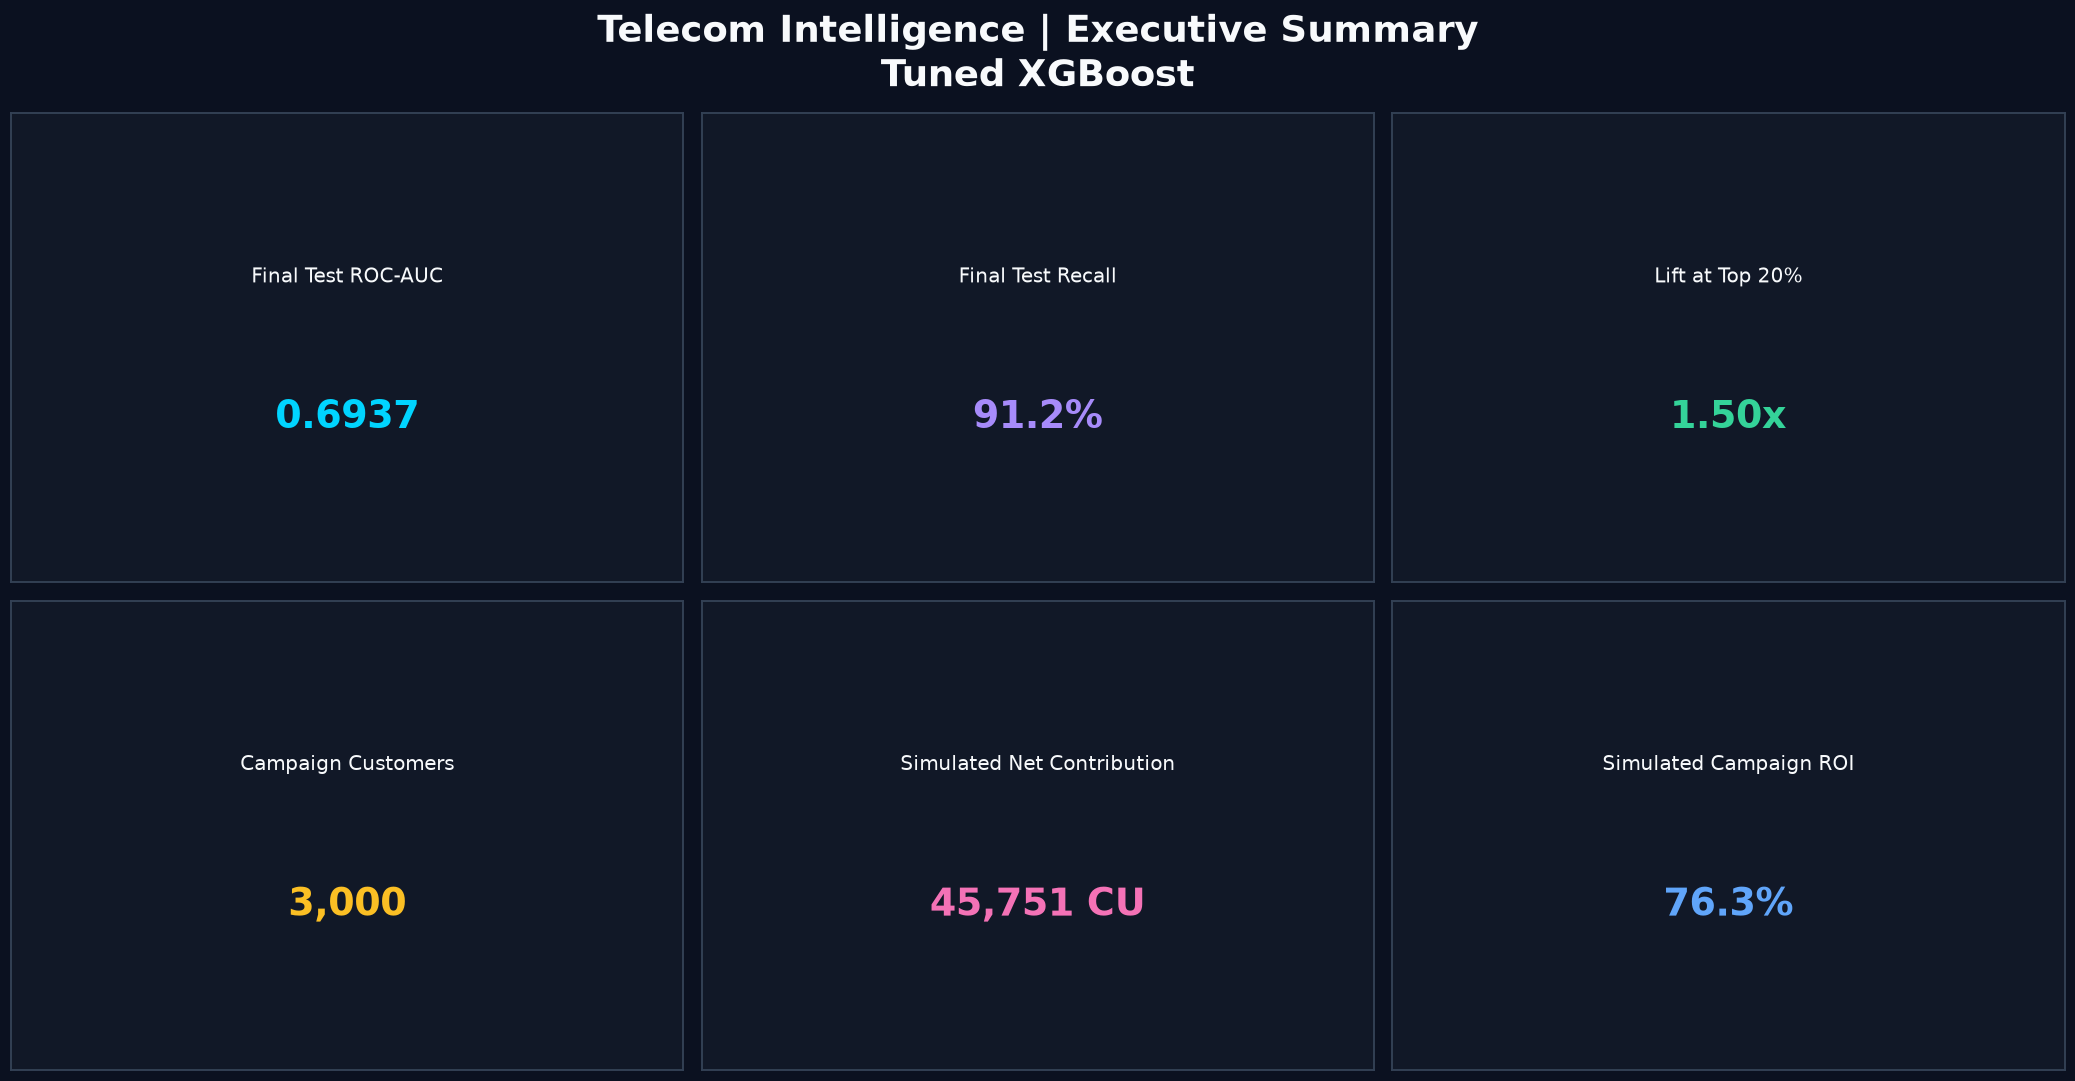

In [222]:
fig, axes = plt.subplots(

    2, 3,

    figsize=(19, 10)

)


executive_cards = [

    (

        "Final Test ROC-AUC",

        f"{final_test_metrics['ROC_AUC']:.4f}",

        CYAN

    ),

    (

        "Final Test Recall",

        f"{final_test_metrics['Recall']:.1%}",

        PURPLE

    ),

    (

        "Lift at Top 20%",

        f"{top20_test['Lift_at_K']:.2f}x",

        GREEN

    ),

    (

        "Campaign Customers",

        f"{len(selected_campaign):,}",

        GOLD

    ),

    (

        "Simulated Net Contribution",

        f"{base_business_result['Net_Contribution']:,.0f} CU",

        PINK

    ),

    (

        "Simulated Campaign ROI",

        (

            f"{base_business_result['ROI_Percentage']:.1f}%"

            if np.isfinite(base_business_result["ROI_Percentage"])

            else "N/A"

        ),

        BLUE

    )

]


for ax, (label, value, color) in zip(

    axes.flat,

    executive_cards

):

    ax.set_facecolor(PANEL_COLOR)

    ax.set_xticks([])

    ax.set_yticks([])


    for spine in ax.spines.values():

        spine.set_visible(True)

        spine.set_color(GRID_COLOR)


    ax.text(

        0.5,

        0.65,

        label,

        ha="center",

        va="center",

        fontsize=13,

        color=TEXT_COLOR,

        transform=ax.transAxes

    )


    ax.text(

        0.5,

        0.35,

        value,

        ha="center",

        va="center",

        fontsize=25,

        fontweight="bold",

        color=color,

        transform=ax.transAxes

    )


fig.suptitle(

    f"Telecom Intelligence | Executive Summary\n{CHAMPION_NAME}",

    fontsize=24,

    fontweight="bold"

)


finish_plot(

    fig,

    "53_executive_summary_dashboard.png"

)

In [223]:
roi_text = (

    f"{base_business_result['ROI_Percentage']:.2f}%"

    if np.isfinite(base_business_result["ROI_Percentage"])

    else "not applicable because no customers were selected"

)


final_conclusion = f"""
# 27. Final Conclusions

## Predictive Performance

The final selected model is **{CHAMPION_NAME}**.

On the independent test dataset of {len(y_test):,}
customers, the model achieved:

- ROC-AUC: {final_test_metrics['ROC_AUC']:.4f}
- Accuracy: {final_test_metrics['Accuracy']:.2%}
- F1-score: {final_test_metrics['F1']:.4f}
- Recall: {final_test_metrics['Recall']:.2%}
- Precision: {final_test_metrics['Precision']:.2%}
- Brier Score: {final_test_metrics['Brier_Score']:.4f}

The bootstrap 95% confidence interval for ROC-AUC is
{confidence_report.loc['ROC_AUC', 'CI_Lower_95']:.4f}
to {confidence_report.loc['ROC_AUC', 'CI_Upper_95']:.4f}.

## Business Targeting Performance

When targeting the top 20% of customers ranked by
predicted churn risk, the system achieves a lift of
{top20_test['Lift_at_K']:.2f} relative to random targeting.

The revenue-aware decision framework selects
{len(selected_campaign):,} customers under the
specified campaign assumptions.

## Financial Impact Simulation

Under the base-case assumptions, the campaign is
estimated to retain revenue of
{base_business_result['Expected_Retained_Revenue']:,.2f}
dataset currency units.

The estimated net contribution is
{base_business_result['Net_Contribution']:,.2f}
currency units, with a simulated campaign ROI of
{roi_text}.

These are scenario-based estimates, not experimentally
verified financial outcomes.

## System Reliability

The project includes a reusable prediction engine,
model persistence, automated system testing, and
simulated data-drift monitoring.

Automated system tests passed:
{test_result.wasSuccessful()}.

## Recommendation

Company A should evaluate the proposed system through
a controlled retention pilot before operational rollout.

The pilot should verify incremental retention effects,
financial contribution, probability calibration and
customer experience.
"""


display(Markdown(final_conclusion))


(REPORTS_DIR / "final_conclusion.md").write_text(

    final_conclusion,

    encoding="utf-8"

)


# 27. Final Conclusions

## Predictive Performance

The final selected model is **Tuned XGBoost**.

On the independent test dataset of 15,000
customers, the model achieved:

- ROC-AUC: 0.6937
- Accuracy: 59.15%
- F1-score: 0.6887
- Recall: 91.18%
- Precision: 55.33%
- Brier Score: 0.2207

The bootstrap 95% confidence interval for ROC-AUC is
0.6851
to 0.7017.

## Business Targeting Performance

When targeting the top 20% of customers ranked by
predicted churn risk, the system achieves a lift of
1.50 relative to random targeting.

The revenue-aware decision framework selects
3,000 customers under the
specified campaign assumptions.

## Financial Impact Simulation

Under the base-case assumptions, the campaign is
estimated to retain revenue of
176,251.56
dataset currency units.

The estimated net contribution is
45,750.93
currency units, with a simulated campaign ROI of
76.25%.

These are scenario-based estimates, not experimentally
verified financial outcomes.

## System Reliability

The project includes a reusable prediction engine,
model persistence, automated system testing, and
simulated data-drift monitoring.

Automated system tests passed:
True.

## Recommendation

Company A should evaluate the proposed system through
a controlled retention pilot before operational rollout.

The pilot should verify incremental retention effects,
financial contribution, probability calibration and
customer experience.


1429

# 28. Limitations and Future Work

## Limitations

1. The dataset represents historical customer snapshots
   and does not provide explicit observation dates.

2. The sample churn prevalence may differ from the actual
   population churn rate of Company A.

3. Random stratified validation does not establish
   temporal or cross-market generalization.

4. Several customer features contain substantial missing
   values or incomplete documentation.

5. Explainability results identify model associations,
   not causal drivers of churn.

6. Retention treatment effectiveness cannot be estimated
   causally from the available dataset.

7. Financial simulations depend on assumed intervention
   costs, retention success rates and contribution margins.

8. Data drift monitoring is demonstrated through
   historical comparisons and synthetic simulations.

9. Excluding sensitive variables does not guarantee
   complete algorithmic fairness.

10. The predictive system remains a proof of concept and
    requires production validation before deployment.

## Future Work

- Collect longitudinal and representative customer data.
- Evaluate the system using temporal validation.
- Conduct controlled retention experiments.
- Develop causal uplift models.
- Estimate customer lifetime value.
- Improve probability calibration using production data.
- Integrate the system with the company CRM.
- Establish comprehensive fairness and privacy reviews.
- Implement automated operational monitoring.

# 29. References

[1] GSMA. (2026). The Mobile Economy 2026.
https://www.gsma.com/solutions-and-impact/connectivity-for-good/mobile-economy/

[2] Ericsson. (2026). Mobile Network Traffic Q2 2026.
https://www.ericsson.com/en/reports-and-papers/mobility-report/dataforecasts/mobile-traffic-update

[3] Ericsson. Mobile Data Traffic Outlook.
https://www.ericsson.com/en/reports-and-papers/mobility-report/dataforecasts/mobile-traffic-forecast

[4] GCI World 2026. Final Assignment — Practical Guide
and Examples.

[5] GCI World 2026. Final Assignment Tutorial.

[6] Company A Dataset Overview and Assignment README.

[7] Scikit-learn Documentation.
https://scikit-learn.org/stable/

[8] LightGBM Documentation.
https://lightgbm.readthedocs.io/

[9] XGBoost Documentation.
https://xgboost.readthedocs.io/

[10] CatBoost Documentation.
https://catboost.ai/docs/

[11] Optuna Documentation.
https://optuna.readthedocs.io/

[12] SHAP Documentation.
https://shap.readthedocs.io/

[13] Generative AI Assistance.
OpenAI ChatGPT — project development, debugging,
methodological discussion and code assistance.

Conversation link: [Insert your actual conversation link]

**Submission note:** replace the conversation-link placeholder with the actual AI-assistance conversation URL and confirm the course's reference-entry requirements. No external sources were added or independently verified during this editorial cleanup.

In [224]:
expected_artifacts = [

    REPORTS_DIR / "data_quality_audit.csv",

    REPORTS_DIR / "initial_model_leaderboard.csv",

    REPORTS_DIR / "cross_validation_leaderboard.csv",

    REPORTS_DIR / "feature_ablation_leaderboard.csv",

    REPORTS_DIR / "optimization_summary.csv",

    REPORTS_DIR / "development_model_leaderboard.csv",

    REPORTS_DIR / "final_independent_test_metrics.csv",

    REPORTS_DIR / "bootstrap_confidence_intervals.csv",

    REPORTS_DIR / "final_system_feature_importance.csv",

    REPORTS_DIR / "business_scenario_analysis.csv",

    REPORTS_DIR / "roi_sensitivity_analysis.csv",

    REPORTS_DIR / "executive_summary.csv",

    REPORTS_DIR / "system_testing_report.json",

    PREDICTIONS_DIR / "customer_intelligence_results.csv",

    PREDICTIONS_DIR / "retention_campaign_candidates.csv",

    MONITORING_DIR / "monitoring_summary.json",

    MODELS_DIR / "telecom_intelligence_v1.pkl",

    MODELS_DIR / "final_decision_policy.json",

    PROJECT_ROOT / "retention_system.py"

]


artifact_report = pd.DataFrame([

    {

        "Artifact": str(path.relative_to(PROJECT_ROOT)),

        "Exists": path.exists(),

        "Size_KB": (

            path.stat().st_size / 1024

            if path.exists()

            else 0

        )

    }

    for path in expected_artifacts

])


display(artifact_report.round(2))


print(

    "Generated Artifacts:",

    artifact_report["Exists"].sum(),

    "/",

    len(artifact_report)

)


artifact_report.to_csv(

    REPORTS_DIR / "project_artifact_manifest.csv",

    index=False

)

,Artifact,Exists,Size_KB
0,outputs\reports\data_quality_audit.csv,True,5.3600
1,outputs\reports\initial_model_leaderboard.csv,True,2.0600
2,outputs\reports\cross_validation_leaderboard.csv,True,1.3900
3,outputs\reports\feature_ablation_leaderboard.csv,True,1.0800
4,outputs\reports\optimization_summary.csv,True,0.2800
5,outputs\reports\development_model_leaderboard.csv,True,2.6200
6,outputs\reports\final_independent_test_metrics...,True,0.3300
7,outputs\reports\bootstrap_confidence_intervals...,True,0.5500
8,outputs\reports\final_system_feature_importanc...,True,4.2600
9,outputs\reports\business_scenario_analysis.csv,True,0.5500


Generated Artifacts: 19 / 19


In [227]:
completion_checks = {

    "Model Development Completed": bool(CHAMPION_NAME),

    "Independent Test Completed": len(test_probabilities) == len(y_test),

    "Final Evaluation Report Saved": (

        REPORTS_DIR / "final_independent_test_metrics.csv"

    ).exists(),

    "Financial Analysis Completed": (

        REPORTS_DIR / "business_scenario_analysis.csv"

    ).exists(),

    "Model Saved": MODEL_PATH.exists(),

    "System Tests Passed": test_result.wasSuccessful(),

    "Fresh Process Test Passed": process.returncode == 0,

    "Monitoring Framework Completed": (

        MONITORING_DIR / "monitoring_summary.json"

    ).exists(),

    "Executive Summary Generated": (

        REPORTS_DIR / "executive_summary.csv"

    ).exists(),

    "All Required Artifacts Generated": bool(

        artifact_report["Exists"].all()

    )

}


completion_report = pd.DataFrame(

    completion_checks.items(),

    columns=["Component", "Completed"]

)


display(completion_report)


if all(completion_checks.values()):

    print("=" * 70)

    print("TELECOM INTELLIGENCE — TECHNICAL PROJECT COMPLETED")

    print("=" * 70)

    print("All technical completion checks passed.")

else:

    print("Review incomplete components before submission.")

,Component,Completed
0,Model Development Completed,True
1,Independent Test Completed,True
2,Final Evaluation Report Saved,True
3,Financial Analysis Completed,True
4,Model Saved,True
5,System Tests Passed,True
6,Fresh Process Test Passed,True
7,Monitoring Framework Completed,True
8,Executive Summary Generated,True
9,All Required Artifacts Generated,True


TELECOM INTELLIGENCE — TECHNICAL PROJECT COMPLETED
All technical completion checks passed.
